## Full breakdown of fish behaviour in real trajectories

#### Data exploration - real fish full trajectories in bout per bout setting

### Setup

One cell. Loads the bouts, derives `r_norm` and the condition label, and defines the
channel specs plus the three plotting helpers. Nothing below this cell touches a model.

In [1]:
from math import ceil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullLocator
from scipy.ndimage import gaussian_filter1d
from scipy import stats as _spearman
from scipy.stats import t as _tdist

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

# --------------------------------------------------------------------------- #
#  Palette / chrome.  Categorical slots 1-3 only (blue, orange, aqua) -- the
#  three that validate on all pairs; aqua is under 3:1 on the light surface, so
#  every condition curve is DIRECT-LABELLED as well as legended.
# --------------------------------------------------------------------------- #
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
# ordinal blue ramp, step 250 upward (lighter steps fall below 2:1 on this surface)
SEQ = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
       "#256abf", "#1c5cab", "#184f95", "#104281"]

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.titlesize": 10, "axes.labelsize": 9, "font.size": 9,
    "legend.frameon": False, "figure.dpi": 110,
})

# --------------------------------------------------------------------------- #
#  Data
# --------------------------------------------------------------------------- #
BOUTS = ROOT / "data" / "bouts_GsizeMotionSingle.csv"
df = pd.read_csv(BOUTS).sort_values(["fish_id", "segment_id", "bout_index"]).reset_index(drop=True)

# r/R against the PHYSICAL dish (segment_bouts.add_dist_to_border): 0 = centre, 1 = wall.
df["r_norm"] = 1.0 - df["dist_to_border_norm"]

# stimulus condition. `moving` is only ever True on a CLsemi block with non-zero
# dot speed, so the three labels partition the bouts exactly.
_stim = df["stimulus"].astype(str).str.startswith("CLsemi")
df["cond"] = np.where(~_stim, "none",
             np.where(df["moving"].astype(bool), "moving", "static"))

# EGOCENTRIC BEARING TO THE DOTS -- in the frame the representation actually uses.
#
# `stim_angle_rad` as shipped by the segmenter is referenced to the BODY AXIS
# (`f_ori_rad`, the tracker's orientation at the onset FRAME). `dtheta` is referenced to
# the CHORD (`theta_i - theta_{i-1}`). Those two frames sit a MEDIAN 40 deg apart -- f_ori
# is measured before the fish turns, the chord after -- so comparing the sign of one
# against the sign of the other mixes frames.
#
# It also cannot be carried into a rollout. A bout-to-bout model propagates the chord
# heading (`heading += dtheta`) and emits nothing that updates a body axis, so at rollout
# there is no f_ori to measure a bearing against.
#
# So every stimulus measure below uses `stim_angle_travel`: the same bearing, referenced
# to the INCOMING chord -- the direction the fish was already travelling when it reached
# this onset. That is the PREVIOUS bout's `heading_rad`; the row's own `heading_rad` is
# the outgoing leg and already contains the turn, so referencing to it would leak the
# answer into the feature.
#
# theta_{t-1} is recovered ROW-LOCALLY, not by shifting: the segmentation guarantees
# dtheta_t = wrap(theta_t - theta_{t-1}) and heading_rad[t] = theta_t, so
# theta_{t-1} = heading_rad[t] - dtheta_t exactly. That is immune to segment boundaries and
# dropped bouts, so no row is lost. This is `fit_MLP_border._travel_ref` -- the same
# reference the closed-loop rollout presents, so the EDA and the models measure one thing.
_wrap_pi = lambda a: (a + np.pi) % (2 * np.pi) - np.pi          # noqa: E731
_theta_prev = _wrap_pi(df["heading_rad"] - np.radians(df["dtheta_deg"]))
df["stim_angle_travel"] = _wrap_pi(
    np.arctan2(df["dot_cy"] - df["y_px"], df["dot_cx"] - df["x_px"]) - _theta_prev)

CONDS = {"none": "no stimulus", "moving": "moving dots", "static": "static dots"}
COND_COLOR = {"none": BLUE, "moving": ORANGE, "static": AQUA}
FISH = sorted(df["fish_id"].unique())

# Stimulus BLOCK identity and the clock inside it (§6).
#
# The protocol is an EXACT frame grid -- 1500-frame (50 s) pause, then 1800-frame
# (60 s) stimulus, x95 -- and all 15 fish were recorded in one session, so the same
# grid applies to every fish. Block onset is therefore arithmetic on `frame_onset`,
# with no per-frame file to load. VERIFIED against the `stimulus` label: the grid and
# the label agree on all 70,590 bouts, zero mismatches.
#
# WHY NOT the obvious "runs of the same stimulus label in the bout table": that puts
# t = 0 at the fish's FIRST BOUT of the block, not at the moment the dots appeared.
# The latency between the two is a median 1.7 s but a mean 5.5 s (max 58.9 s), and it
# differs by condition, so it would smear exactly the early dynamics §6A is about.
CYCLE_FR, PAUSE_FR, FPS = 3300, 1500, 30.0
_pos = df["frame_onset"] % CYCLE_FR
_in_stim = _pos >= PAUSE_FR
df["blk"] = df["frame_onset"] // CYCLE_FR * 2 + _in_stim.astype(int)
df["t_blk"] = np.where(_in_stim, _pos - PAUSE_FR, _pos) / FPS

# --------------------------------------------------------------------------- #
#  Channel specs.  `edges` also fixes the display range: mass outside it is NOT
#  renormalised away (see `density`), it just shows as missing area.
# --------------------------------------------------------------------------- #
VARS = {
    "radial":  dict(col="r_norm",      label="radial position  r/R",
                    edges=np.linspace(0, 1, 61),        log=False, smooth=1.2,
                    ticks=None),
    "angular": dict(col="dtheta_deg",  label=r"reorientation  $\Delta\theta$  (deg)",
                    edges=np.linspace(-180, 180, 91),   log=False, smooth=1.2,
                    ticks=[-180, -90, 0, 90, 180]),
    "dt":      dict(col="dt_s",        label=r"inter-bout interval  $\Delta t$  (s)",
                    edges=np.geomspace(0.2, 30, 61),    log=True,  smooth=1.2,
                    ticks=[0.3, 0.5, 1, 2, 5, 10, 20]),
    "dist":    dict(col="distance_px", label="bout distance  (px)",
                    edges=np.linspace(0, 60, 61),       log=False, smooth=1.2,
                    ticks=None),
}
KEYS = list(VARS)


def centers(spec):
    """Bin centres -- geometric for log-spaced edges so they plot in the middle."""
    e = spec["edges"]
    return np.sqrt(e[:-1] * e[1:]) if spec["log"] else 0.5 * (e[:-1] + e[1:])


def density(x, spec):
    """Smoothed histogram density on the spec's edges.

    Normalised by the number of FINITE values, not by the in-range count, so a fish
    with a fatter out-of-axis tail keeps a visibly smaller area under its curve
    instead of being rescaled to look like the others. For log channels the density
    is per decade (the axis is log), which is the right thing to compare by eye.
    """
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    n = x.size
    if n == 0:
        return np.zeros(len(spec["edges"]) - 1)
    if spec["log"]:
        e = np.log10(spec["edges"])
        h, _ = np.histogram(np.log10(x[x > 0]), bins=e)
    else:
        e = spec["edges"]
        h, _ = np.histogram(x, bins=e)
    d = h / (n * np.diff(e))
    return gaussian_filter1d(d, spec["smooth"], mode="nearest") if spec["smooth"] else d


def _axis(ax, spec):
    """Range + readable ticks. A log axis defaults to 10^0 / 10^1 only, which is
    useless when the whole channel lives between 0.5 s and 3 s -- so dt carries its
    own plain-number ticks."""
    if spec["log"]:
        ax.set_xscale("log")
        ax.xaxis.set_minor_locator(NullLocator())
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    if spec["ticks"]:
        ax.set_xticks(spec["ticks"])
    ax.set_xlim(spec["edges"][0], spec["edges"][-1])


def _bottom_xlabels(axes, label):
    """Put the x label on the lowest VISIBLE axes of each column (the last row can
    be part-empty when the fish count is not a multiple of ncols)."""
    A = np.atleast_2d(axes)
    for j in range(A.shape[1]):
        col = [A[i, j] for i in range(A.shape[0]) if A[i, j].get_visible()]
        if col:
            col[-1].set_xlabel(label)


def _fmt(v, key):
    return f"{v:.2f}" if key in ("radial", "dt") else f"{v:.0f}"


def _tail_note(d, key):
    """Fraction of finite values outside the plotted range -- printed, never hidden."""
    spec = VARS[key]
    x = d[spec["col"]].to_numpy(float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return 0.0
    lo, hi = spec["edges"][0], spec["edges"][-1]
    return float(np.mean((x < lo) | (x > hi)))


def head(d, name):
    """One-line header for a subset: size, fish count, and the off-axis fraction."""
    print(f"{name}: {len(d):,} bouts · {d['fish_id'].nunique()} fish · off-axis "
          + " · ".join(f"{k} {_tail_note(d, k) * 100:.2f}%" for k in KEYS))


# --------------------------------------------------------------------------- #
#  Figure 1 -- ridges.  One row per fish, four channels side by side, SAME row
#  order in every column so a fish can be tracked across channels.
# --------------------------------------------------------------------------- #
def plot_ridges(d, order_by="radial", keys=KEYS, title=None, height=1.9):
    """Ridgeline of every fish, one column per channel.

    `order_by` is a channel key (rows sorted by that channel's per-fish median,
    lowest at the bottom) or None for fish-id order. Row fill darkens with rank in
    that ordering -- a one-hue ordinal ramp, so it encodes the sort and nothing else.
    """
    fish = FISH if order_by is None else list(
        d.groupby("fish_id")[VARS[order_by]["col"]].median().sort_values().index)
    n = len(fish)
    fig, axes = plt.subplots(1, len(keys), figsize=(3.5 * len(keys), 0.36 * n + 1.8),
                             sharey=True)
    axes = np.atleast_1d(axes)
    for ax, key in zip(axes, keys):
        spec, x = VARS[key], centers(VARS[key])
        curves = {f: density(d.loc[d.fish_id == f, spec["col"]], spec) for f in fish}
        dmax = max(c.max() for c in curves.values()) or 1.0
        pooled_med = float(np.nanmedian(d[spec["col"]]))
        ax.axvline(pooled_med, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=1)
        for i, f in enumerate(fish):
            y = i + height * curves[f] / dmax
            col = SEQ[round(i / max(n - 1, 1) * (len(SEQ) - 1))]
            ax.fill_between(x, i, y, color=col, alpha=.85, lw=0, zorder=3 + n - i)
            ax.plot(x, y, color=SURF, lw=.9, zorder=3 + n - i)     # 2px surface gap
            med = float(np.nanmedian(d.loc[d.fish_id == f, spec["col"]]))
            ax.plot([med, med], [i, i + .28], color=INK, lw=1.4, zorder=3 + n - i)
        _axis(ax, spec)
        ax.set_xlabel(spec["label"])
        ax.set_yticks(range(n))
        ax.set_yticklabels([f"fish {f}" for f in fish], fontsize=8)
        ax.tick_params(axis="y", length=0)
        ax.spines["left"].set_visible(False)
        ax.set_ylim(-.4, n - 1 + height * 1.05)
    fig.suptitle(title or "per-fish distributions"
                 + (f"  ·  rows sorted by median {order_by}" if order_by else ""),
                 y=.995, fontsize=11, color=INK)
    fig.text(.5, .955, "each row starts at its own baseline  ·  black tick = that "
             "fish's median  ·  dashed = pooled median",
             ha="center", fontsize=8, color=MUTED)
    fig.tight_layout(rect=(0, 0, 1, .945))
    return fig


# --------------------------------------------------------------------------- #
#  Figure 2 -- spread.  The same information as numbers: median, IQR, 10-90 %.
# --------------------------------------------------------------------------- #
def plot_spread(d, keys=KEYS, title=None):
    """Per-fish median (dot), IQR (thick bar), 10-90 % (thin whisker); fish sorted
    per panel by their own median, so the ordering is itself a readout."""
    fig, axes = plt.subplots(1, len(keys), figsize=(3.3 * len(keys), 0.30 * len(FISH) + 1.6))
    axes = np.atleast_1d(axes)
    for ax, key in zip(axes, keys):
        spec = VARS[key]
        q = (d.groupby("fish_id")[spec["col"]]
               .quantile([.1, .25, .5, .75, .9]).unstack().sort_values(.5))
        y = np.arange(len(q))
        pooled = float(np.nanmedian(d[spec["col"]]))
        ax.axvline(pooled, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=1)
        ax.hlines(y, q[.1], q[.9], color=GRID, lw=2.2, zorder=2)
        ax.hlines(y, q[.25], q[.75], color=SEQ[3], lw=5, zorder=3,
                  capstyle="round")
        ax.plot(q[.5], y, "o", ms=5.5, color=SEQ[6], mec=SURF, mew=1.2, zorder=4)
        for yi, (f, m) in enumerate(q[.5].items()):
            ax.text(1.02, yi, _fmt(m, key), transform=ax.get_yaxis_transform(),
                    va="center", fontsize=7.5, color=INK2)
        if spec["log"]:
            ax.set_xscale("log")
            ax.xaxis.set_minor_locator(NullLocator())
            ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        if spec["ticks"]:
            ax.set_xticks([t for t in spec["ticks"]
                           if q[.1].min() <= t <= q[.9].max()] or spec["ticks"])
        ax.set_yticks(y)
        ax.set_yticklabels([f"fish {f}" for f in q.index], fontsize=8)
        ax.tick_params(axis="y", length=0)
        ax.spines["left"].set_visible(False)
        ax.set_xlabel(spec["label"])
        ax.set_ylim(-.7, len(q) - .3)
        ax.set_title(f"pooled median {_fmt(pooled, key)}", fontsize=9, color=MUTED)
    fig.suptitle(title or "median · IQR · 10–90 %, fish sorted per panel",
                 y=.999, fontsize=11, color=INK)
    fig.tight_layout(w_pad=3.2, rect=(0, 0, 1, .96))
    return fig


# --------------------------------------------------------------------------- #
#  Figure 3 -- per-fish facets for ONE channel, each fish over the pooled shape.
# --------------------------------------------------------------------------- #
def plot_per_fish(d, key, ncols=5, title=None):
    """One panel per fish: that fish's density (blue) over the pooled density
    (grey silhouette). Shared axes, so panel-to-panel differences are real."""
    spec, x = VARS[key], centers(VARS[key])
    pooled = density(d[spec["col"]], spec)
    pooled_med = float(np.nanmedian(d[spec["col"]]))
    curves = {f: density(d.loc[d.fish_id == f, spec["col"]], spec) for f in FISH}
    ymax = max([pooled.max()] + [c.max() for c in curves.values()]) or 1.0
    nrows = ceil(len(FISH) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 1.75 * nrows),
                             sharex=True, sharey=True)
    for ax, f in zip(axes.ravel(), FISH):
        g = d.loc[d.fish_id == f, spec["col"]]
        ax.fill_between(x, pooled, color=GRID, lw=0, zorder=1)
        # both rules stop below the label band, so a median never runs through the text
        ax.axvline(pooled_med, color=MUTED, lw=.9, ls=(0, (4, 3)), ymax=.84, zorder=2)
        ax.plot(x, curves[f], color=BLUE, lw=1.7, zorder=3)
        med = float(np.nanmedian(g))
        ax.axvline(med, color=INK, lw=1.1, ymax=.84, zorder=4)
        ax.text(.03, .98, f"fish {f}", transform=ax.transAxes, va="top",
                fontsize=8.5, color=INK, fontweight="bold")
        ax.text(.97, .98, f"n={len(g)}   med {_fmt(med, key)}", transform=ax.transAxes,
                va="top", ha="right", fontsize=7.5, color=INK2)
        _axis(ax, spec)
        ax.set_ylim(0, ymax * 1.22)                     # headroom for the in-panel labels
    for ax in axes.ravel()[len(FISH):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, spec["label"])
    handles = [Line2D([], [], color=BLUE, lw=1.7, label="this fish"),
               Line2D([], [], color=GRID, lw=6, label="all fish pooled"),
               Line2D([], [], color=INK, lw=1.1, label="fish median"),
               Line2D([], [], color=MUTED, lw=.9, ls=(0, (4, 3)), label="pooled median")]
    fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(.5, -.02),
               fontsize=8, labelcolor=INK2)
    fig.suptitle(title or f"{key} — per fish vs pooled", y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


# --------------------------------------------------------------------------- #
#  Figure 4 -- condition contrast: the three stimulus conditions inside each fish.
# --------------------------------------------------------------------------- #
def plot_conditions(d, key, ncols=5, title=None):
    """One panel per fish, three curves = the three stimulus conditions.

    Categorical colour is legal here (3 series, validated slots 1-3) and every
    condition is also DIRECT-LABELLED in the first panel, which is the relief the
    aqua slot's sub-3:1 contrast requires."""
    spec, x = VARS[key], centers(VARS[key])
    nb = len(x)
    curves = {f: {c: density(d.loc[(d.fish_id == f) & (d["cond"] == c), spec["col"]], spec)
                  for c in CONDS if ((d.fish_id == f) & (d["cond"] == c)).sum() >= 30}
              for f in FISH}
    ymax = max([c.max() for pf in curves.values() for c in pf.values()] or [1.0])
    nrows = ceil(len(FISH) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 1.75 * nrows),
                             sharex=True, sharey=True)
    for j, (ax, f) in enumerate(zip(axes.ravel(), FISH)):
        for ci, (c, lab) in enumerate(CONDS.items()):
            y = curves[f].get(c)
            if y is None:
                continue
            ax.plot(x, y, color=COND_COLOR[c], lw=1.7, zorder=3)
            if j == 0:
                # Direct labels (the relief the aqua slot's sub-3:1 contrast needs).
                # Anchor each one where its own curve stands highest above the other
                # two, searched inside its own third of the axis so three labels can
                # never land on the same point -- which they do at the shared peak.
                lo, hi = round((ci + .1) * nb / 3), round((ci + .9) * nb / 3)
                others = [v for k, v in curves[f].items() if k != c]
                r = y - (np.mean(others, axis=0) if others else 0.0)
                i = lo + int(np.argmax(r[lo:hi]))
                ha = "left" if i < nb / 6 else "right" if i > 5 * nb / 6 else "center"
                ax.annotate(lab, (x[i], y[i]), xytext=(0, 5), textcoords="offset points",
                            ha=ha, fontsize=7.5, color=COND_COLOR[c], zorder=5)
        ax.text(.03, .98, f"fish {f}", transform=ax.transAxes, va="top",
                fontsize=8.5, color=INK, fontweight="bold")
        _axis(ax, spec)
        ax.set_ylim(0, ymax * 1.22)
    for ax in axes.ravel()[len(FISH):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, spec["label"])
    fig.legend(handles=[Line2D([], [], color=COND_COLOR[c], lw=1.7, label=l)
                        for c, l in CONDS.items()],
               loc="lower center", ncol=3, bbox_to_anchor=(.5, -.02),
               fontsize=8, labelcolor=INK2)
    fig.suptitle(title or f"{key} — stimulus condition, within fish",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


# --------------------------------------------------------------------------- #
#  The table view (the relief rule's fallback, and the numbers behind the eye)
# --------------------------------------------------------------------------- #
def summary_table(d, keys=KEYS):
    """Per-fish median and IQR of every channel, plus `z` = how many between-fish
    SDs that fish's median sits from the across-fish mean of medians. |z| > 2 is
    the fish worth looking at in the facet figure."""
    rows = []
    for f in FISH:
        g = d[d.fish_id == f]
        row = {"fish": f, "n_bouts": len(g)}
        for k in keys:
            s = g[VARS[k]["col"]]
            row[f"{k}_med"] = float(np.nanmedian(s))
            row[f"{k}_iqr"] = float(np.nanquantile(s, .75) - np.nanquantile(s, .25))
        rows.append(row)
    t = pd.DataFrame(rows).set_index("fish")
    for k in keys:
        m = t[f"{k}_med"]
        t[f"{k}_z"] = (m - m.mean()) / (m.std(ddof=1) or np.nan)
    return t[["n_bouts"] + [f"{k}_{s}" for k in keys for s in ("med", "iqr", "z")]]


# --------------------------------------------------------------------------- #
#  §6 -- stimulus response.
#
#  TWO QUESTIONS, TWO PLOTS:
#    A. does the fish CLOSE DISTANCE on the dots once a block starts (approach vs
#       time-in-block, averaged over blocks with a CI);
#    B. does it TURN TOWARD them (P(turn toward), one bar per fish per condition).
#
#  FRAME AND SIGN CONVENTION for B, checked against segment_bouts, not assumed.
#  phi is `stim_angle_travel` = wrap(atan2(dot_cy - y, dot_cx - x) - heading_in), the
#  bearing referenced to the INCOMING CHORD; dtheta is wrap(theta_i - theta_{i-1}) with
#  theta = atan2(dy, dx). Both are CCW-positive IN THE SAME CHORD FRAME, so positive =
#  the fish's left for both and sign(dtheta) == sign(phi) is literally "turned toward".
#
#  NOT the shipped `stim_angle_rad`, which is referenced to the body axis f_ori and sits
#  a median 40 deg away -- see the note where stim_angle_travel is built. Everything in
#  this notebook is onset-to-onset so that description and rollout share one frame.
#  (Do NOT cross-reference evaluate.symbols_from_dtheta -- its docstring names
#  dtheta < -10 "Left", the opposite naming. Nothing here uses it.)
#
#  THE REPLICATE IS THE BLOCK, NOT THE BOUT. Both plots average per block first and
#  put the error bar across blocks. Bouts inside one 60 s block share a starting
#  position and a dot trajectory, so treating them as independent would shrink every
#  interval by roughly sqrt(30) and turn noise into a finding.
# --------------------------------------------------------------------------- #
DTHETA0 = 10.0                       # forward/turn threshold, deg
BLOCK_S = 60.0                       # stimulus block length (CLsemi1800 = 1800 fr @ 30 fps)
TBIN_S = 2.0                         # time-in-block bin for the approach curves
TEDGES = np.arange(0, BLOCK_S + TBIN_S, TBIN_S)
# 8, not 5: with the true block origin, a bin late in a quiet fish's block is fed by
# whichever handful of blocks it happened to stay active in, and at 5 those isolated
# points swing over the full y range. 8 still passes every bin of a normally active
# fish (median blocks/bin is 39 moving / 21 static).
MIN_BLOCKS = 8                       # blocks needed in a bin before a point is drawn
MIN_TURNS = 5                        # turn bouts needed before a block scores a P(toward)
STIM_CONDS = ["moving", "static"]    # 'none' has no dots to approach or turn toward


def stim(d, cond=None):
    """Bouts with a dot on screen and a defined bearing; optionally one condition."""
    s = d[(d["cond"] != "none") & np.isfinite(d["stim_angle_travel"])]
    return s if cond is None else s[s["cond"] == cond]


def _turns(g):
    """Turn bouts only. A forward bout has no direction to be 'toward' anything."""
    return g[g["dtheta_deg"].abs() > DTHETA0]


def _toward(g):
    return (np.sign(g["dtheta_deg"]) == np.sign(g["stim_angle_travel"])).to_numpy(float)


def follow_index(g, min_turns=25):
    """P(turn toward the dots) − 0.5 over turn bouts; NaN below `min_turns`.

    The scalar behind §6B's bars, pulled out so §15 can track it over session time.
    """
    t = _turns(g)
    return float(_toward(t).mean() - .5) if len(t) >= min_turns else np.nan


def _mean_ci(v, min_n):
    """Mean and a t-based 95 % CI of a sample of block-level values."""
    v = np.asarray(v, float)
    v = v[np.isfinite(v)]
    if len(v) < min_n:
        return np.nan, np.nan, np.nan, len(v)
    m = v.mean()
    if len(v) == 1:
        return m, np.nan, np.nan, 1
    h = _tdist.ppf(.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return m, m - h, m + h, len(v)


# --------------------------------------------------------------------------- #
#  A -- distance to the dot centroid over the 60 s block
# --------------------------------------------------------------------------- #
def approach_curve(g, edges=TEDGES, min_blocks=MIN_BLOCKS):
    """Mean distance to the dot centroid per time-in-block bin, averaged over blocks.

    Two stages: within each block, the mean `dot_dist_px` of the bouts falling in the
    bin; then the mean of those block means, with a t-based 95 % CI ACROSS BLOCKS.
    Returns (mean, lo, hi, n_blocks) per bin, NaN where fewer than `min_blocks` blocks
    put a bout in that bin (the last bin is thin -- blocks end at ~59.8 s).

    ⚠ `min_blocks` is an ABSOLUTE count, so it means different things at different
    sample sizes and it will punch holes in a curve when the per-bin count sits on the
    threshold. Measured case: fish 9 static has 35 blocks and 18-26 per bin (all 30 bins
    drawn), but after §8's cleaning only 10 blocks and 4-10 per bin -- median exactly 8 --
    so at the default it flickers across the floor and 8 bins vanish. The gaps are the
    threshold, not the fish. Lower it when the surviving sample is small.
    """
    i = np.digitize(g["t_blk"].to_numpy(float), edges) - 1
    ok = (i >= 0) & (i < len(edges) - 1) & np.isfinite(g["dot_dist_px"].to_numpy(float))
    per = (pd.DataFrame({"bin": i[ok], "blk": g["blk"].to_numpy()[ok],
                         "v": g["dot_dist_px"].to_numpy(float)[ok]})
           .groupby(["bin", "blk"], sort=False)["v"].mean())
    m, lo, hi = (np.full(len(edges) - 1, np.nan) for _ in range(3))
    n = np.zeros(len(edges) - 1, int)
    for b, v in per.groupby(level="bin"):
        m[b], lo[b], hi[b], n[b] = _mean_ci(v.to_numpy(), min_blocks)
    return m, lo, hi, n


def _pool(per_fish, n_bins, min_fish=3):
    """Mean over fish of per-fish curves, with the CI taken ACROSS FISH (not blocks --
    for a population statement the fish are the replicates)."""
    P = np.vstack(per_fish)
    out = [_mean_ci(P[:, b], min_fish) for b in range(n_bins)]
    return tuple(np.array([o[k] for o in out]) for k in (0, 1, 2))


def pooled_approach(d, cond, min_blocks=MIN_BLOCKS):
    """All-fish approach curve for one condition: (mean, lo, hi) per time bin."""
    x = .5 * (TEDGES[:-1] + TEDGES[1:])
    return _pool([approach_curve(stim(d[d.fish_id == f], cond), min_blocks=min_blocks)[0]
                  for f in FISH], len(x))


def plot_approach_impact(d_before, d_after,
                         labels=("all blocks", "quiescence-hit blocks removed"),
                         min_blocks=MIN_BLOCKS, min_blocks_after=None, title=None):
    """Before/after on the pooled curves — does dropping those blocks change the answer?

    One panel per condition, so the only thing varying inside a panel is the dataset.
    Dashed is the full data, solid is the cleaned one; both are the all-fish mean with a
    95 % CI across fish, i.e. the "all fish" panel of §6A.
    """
    x = .5 * (TEDGES[:-1] + TEDGES[1:])
    fig, axes = plt.subplots(1, len(STIM_CONDS), figsize=(5.4 * len(STIM_CONDS), 4.0),
                             sharey=True)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, STIM_CONDS):
        for d_, lab, ls, alpha, mb in (
                (d_before, labels[0], (0, (4, 2)), .12, min_blocks),
                (d_after, labels[1], "-", .22, min_blocks_after or min_blocks)):
            m, lo, hi = pooled_approach(d_, c, min_blocks=mb)
            ax.fill_between(x, lo, hi, color=COND_COLOR[c], alpha=alpha, lw=0, zorder=2)
            ax.plot(x, m, color=COND_COLOR[c], lw=2, ls=ls, zorder=3, label=lab)
        ax.set_xlim(0, BLOCK_S)
        ax.set_xticks([0, 15, 30, 45, 60])
        ax.set_xlabel("time since the block started (s)")
        ax.set_title(CONDS[c], fontsize=10, color=INK)
        ax.legend(fontsize=8, labelcolor=INK2, loc="lower right")
    axes[0].set_ylabel("distance to dots (px)")
    fig.suptitle(title or "does removing the quiescence-hit blocks change §6A?  "
                 "(all fish, 95 % CI across fish)", y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


def plot_approach(d, ncols=4, min_blocks=MIN_BLOCKS, title=None):
    """Distance to the dots vs time since the block started, one panel per fish.

    The last panel is all fish together (mean of the 15 per-fish curves, CI across
    fish rather than across blocks -- stated on the panel so the two are not confused).
    """
    x = .5 * (TEDGES[:-1] + TEDGES[1:])
    curves = {(f, c): approach_curve(stim(d[d.fish_id == f], c), min_blocks=min_blocks)
              for f in FISH for c in STIM_CONDS}
    pooled = {c: _pool([curves[(f, c)][0] for f in FISH], len(x)) for c in STIM_CONDS}
    allv = np.concatenate([np.concatenate([curves[k][1], curves[k][2]])
                           for k in curves])
    ylo, yhi = np.nanmin(allv), np.nanmax(allv)
    pad = .05 * (yhi - ylo)
    panels = list(FISH) + ["all"]
    nrows = ceil(len(panels) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.9 * ncols, 2.0 * nrows),
                             sharex=True, sharey=True)
    for j, (ax, f) in enumerate(zip(axes.ravel(), panels)):
        missing = []
        for c in STIM_CONDS:
            if f == "all":
                m, lo, hi = pooled[c]
            else:
                m, lo, hi, _ = curves[(f, c)]
            if np.all(np.isnan(m)):      # say so, rather than leaving a blank panel
                missing.append(CONDS[c])
            ax.fill_between(x, lo, hi, color=COND_COLOR[c], alpha=.20, lw=0, zorder=2)
            ax.plot(x, m, color=COND_COLOR[c], lw=1.8, zorder=3)
            if j == 0:                                    # direct labels, once
                k = np.flatnonzero(np.isfinite(m))[-1]
                ax.annotate(CONDS[c], (x[k], m[k]), xytext=(-3, 4),
                            textcoords="offset points", ha="right", fontsize=7.5,
                            color=COND_COLOR[c], zorder=5)
        lab = "all fish" if f == "all" else f"fish {f}"
        ax.text(.03, .95, lab, transform=ax.transAxes, va="top", fontsize=8.5,
                color=INK, fontweight="bold")
        if missing:
            ax.text(.5, .5, "no " + " or ".join(missing) + " block\nreaches "
                    f"{min_blocks} in any bin", transform=ax.transAxes, ha="center",
                    va="center", fontsize=8, color=MUTED, linespacing=1.4)
        if f == "all":
            ax.text(.03, .82, "CI across fish", transform=ax.transAxes, va="top",
                    fontsize=7, color=MUTED)
        ax.set_xlim(0, BLOCK_S)
        ax.set_xticks([0, 15, 30, 45, 60])
        ax.set_ylim(ylo - pad, yhi + pad)
    for ax in axes.ravel()[len(panels):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, "time since the block started (s)")
    for i in range(np.atleast_2d(axes).shape[0]):
        np.atleast_2d(axes)[i, 0].set_ylabel("distance to dots (px)")
    fig.legend(handles=[Line2D([], [], color=COND_COLOR[c], lw=1.8, label=CONDS[c])
                        for c in STIM_CONDS]
               + [Patch(facecolor=GRID, edgecolor="none", label="95 % CI across blocks")],
               loc="lower center", ncol=3, bbox_to_anchor=(.5, -.02), fontsize=8,
               labelcolor=INK2)
    fig.suptitle(title or "distance to the dot centroid over the 60 s stimulus block",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


# --------------------------------------------------------------------------- #
#  B -- P(turn toward the dots), one bar per fish per condition
# --------------------------------------------------------------------------- #
def toward_by_block(g):
    """P(turn toward the dots) within each block, over that block's turn bouts.
    Blocks with fewer than MIN_TURNS turn bouts are dropped rather than counted at a
    noisy 0 or 1."""
    t = _turns(g)
    if not len(t):
        return np.array([])
    per = (pd.DataFrame({"blk": t["blk"].to_numpy(), "tw": _toward(t)})
           .groupby("blk")["tw"].agg(["mean", "size"]))
    return per.loc[per["size"] >= MIN_TURNS, "mean"].to_numpy()


def toward_stats(d):
    """(mean, lo, hi, n_blocks) of P(turn toward) per fish per condition."""
    return {(f, c): _mean_ci(toward_by_block(stim(d[d.fish_id == f], c)), MIN_BLOCKS)
            for f in FISH for c in STIM_CONDS}


def plot_toward_bars(d, title=None):
    """Grouped bars: P(bout turns toward the dot centroid), moving vs static, per fish.

    Bars are anchored on the 0.5 CHANCE line, not on zero: 0.5 is what a fish that
    ignores the dots scores, so the bar length is the departure from chance -- the
    quantity being compared. The axis still reads as a probability and the baseline is
    drawn solid so it cannot be mistaken for a zero origin.
    """
    st = toward_stats(d)
    x = np.arange(len(FISH))
    w = .38
    fig, ax = plt.subplots(figsize=(12, 4.4))
    ax.axhline(.5, color=INK2, lw=1.3, zorder=4)
    for k, c in enumerate(STIM_CONDS):
        m = np.array([st[(f, c)][0] for f in FISH])
        lo = np.array([st[(f, c)][1] for f in FISH])
        hi = np.array([st[(f, c)][2] for f in FISH])
        xs = x + (k - .5) * w
        ax.bar(xs, m - .5, bottom=.5, width=w - .03, color=COND_COLOR[c],
               label=CONDS[c], zorder=2)
        ax.errorbar(xs, m, yerr=[m - lo, hi - m], fmt="none", ecolor=INK,
                    elinewidth=1, capsize=2.5, zorder=5)
    ax.set_xticks(x)
    ax.set_xticklabels([f"fish {f}" for f in FISH], fontsize=8)
    ax.set_xlim(-.78, len(FISH) - .3)
    ax.set_ylabel("P(bout turns toward the dots)")
    ax.set_yticks([.4, .5, .6, .7, .8])
    # in the left margin: the only strip of the baseline no bar or whisker reaches
    ax.text(-.74, .503, "chance", ha="left", va="bottom", fontsize=7.5, color=INK2)
    ax.legend(fontsize=8, labelcolor=INK2, ncol=2, loc="upper left")
    ax.set_title(title or "P(turn toward the dot centroid)  ·  bars from the 0.5 chance "
                 "line, whiskers = 95 % CI across blocks", fontsize=10, color=INK)
    fig.tight_layout()
    return fig


AHEAD_DEG, BEHIND_DEG = 60.0, 120.0     # |phi| bands: dots ahead of / behind the fish


def forward_bias(g, min_each=5):
    """P(go straight | dots ahead) − P(go straight | dots behind).

    The half of the stimulus response the following index cannot see. That index is
    conditional on turning and reads `sign(dtheta)`, so it necessarily drops forward bouts
    -- at |dtheta| <= 10° the sign is noise, since chord-angle error on a ~13 px leg is
    already several degrees. But the information in those bouts was never in the sign: it
    is in the DECISION not to turn. A fish that keeps going straight while the dots are
    ahead, and turns when they are not, is following.

    Zero means the fish's choice to swim straight is unrelated to where the dots are.
    """
    a = np.degrees(np.abs(g["stim_angle_travel"]))
    fwd = (g["dtheta_deg"].abs() <= DTHETA0).to_numpy(float)
    ahead, behind = (a < AHEAD_DEG).to_numpy(), (a > BEHIND_DEG).to_numpy()
    if ahead.sum() < min_each or behind.sum() < min_each:
        return np.nan
    return float(fwd[ahead].mean() - fwd[behind].mean())


def forward_bias_by_block(g, min_each=5):
    """`forward_bias` within each block -- the block is the replicate, as in §6A/§6B."""
    out = []
    for _, gg in g.groupby("blk"):
        v = forward_bias(gg, min_each)
        if np.isfinite(v):
            out.append(v)
    return np.asarray(out, float)


def plot_forward_bias_bars(d, title=None):
    """Per fish: how much more often the fish swims straight when the dots are ahead.

    Bars start at ZERO here, unlike §6B -- this is already a difference of two
    probabilities, so 0 is the no-response value and bar length is the effect itself.
    """
    st = {(f, c): _mean_ci(forward_bias_by_block(stim(d[d.fish_id == f], c)), MIN_BLOCKS)
          for f in FISH for c in STIM_CONDS}
    x, w = np.arange(len(FISH)), .38
    fig, ax = plt.subplots(figsize=(12, 4.4))
    ax.axhline(0, color=INK2, lw=1.3, zorder=4)
    for k, c in enumerate(STIM_CONDS):
        m = np.array([st[(f, c)][0] for f in FISH])
        lo = np.array([st[(f, c)][1] for f in FISH])
        hi = np.array([st[(f, c)][2] for f in FISH])
        xs = x + (k - .5) * w
        ax.bar(xs, m, width=w - .03, color=COND_COLOR[c], label=CONDS[c], zorder=2)
        ax.errorbar(xs, m, yerr=[m - lo, hi - m], fmt="none", ecolor=INK,
                    elinewidth=1, capsize=2.5, zorder=5)
    ax.set_xticks(x)
    ax.set_xticklabels([f"fish {f}" for f in FISH], fontsize=8)
    ax.set_xlim(-.78, len(FISH) - .3)
    ax.set_ylabel(f"P(straight | dots < {AHEAD_DEG:g}°)  −  P(straight | dots > {BEHIND_DEG:g}°)")
    ax.text(-.74, .01, "no bearing preference", ha="left", va="bottom", fontsize=7.5,
            color=INK2)
    ax.legend(fontsize=8, labelcolor=INK2, ncol=2, loc="upper left")
    ax.set_title(title or "does the fish keep swimming straight when the dots are ahead?"
                 "  ·  whiskers = 95 % CI across blocks", fontsize=10, color=INK)
    fig.tight_layout()
    return fig


def forward_bias_table(d):
    """The numbers behind the bars, plus the paired moving − static contrast."""
    rows = {}
    for f in FISH:
        r = {}
        for c in STIM_CONDS:
            sub = stim(d[d.fish_id == f], c)
            a = np.degrees(np.abs(sub["stim_angle_travel"]))
            fwd = (sub["dtheta_deg"].abs() <= DTHETA0).to_numpy(float)
            r[f"{CONDS[c]} ahead"] = round(float(fwd[(a < AHEAD_DEG).to_numpy()].mean()), 3)
            r[f"{CONDS[c]} behind"] = round(float(fwd[(a > BEHIND_DEG).to_numpy()].mean()), 3)
            r[f"{CONDS[c]} bias"] = round(r[f"{CONDS[c]} ahead"] - r[f"{CONDS[c]} behind"], 3)
        rows[f] = r
    t = pd.DataFrame(rows).T
    t.index.name = "fish"
    t.loc["ALL"] = t.mean().round(3)
    return t


def toward_table(d):
    """The numbers behind the bars: P(turn toward) per fish, and how many blocks."""
    st = toward_stats(d)
    rows = {}
    for f in FISH:
        r = {}
        for c in STIM_CONDS:
            m, lo, hi, n = st[(f, c)]
            r[f"{CONDS[c]}"] = m
            r[f"{CONDS[c]} 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
            r[f"{CONDS[c]} n blocks"] = n
        r["moving − static"] = r[CONDS["moving"]] - r[CONDS["static"]]
        rows[f] = r
    t = pd.DataFrame(rows).T
    t.index.name = "fish"
    for c in t.columns:
        if "CI" not in c and "blocks" not in c:
            t[c] = t[c].astype(float).round(3)
    return t


# --------------------------------------------------------------------------- #
#  §6bis -- why an approach curve stops early: the raw speed trace of one block.
#
#  This is section 5 of notebooks/segment_bouts.ipynb ("speed trace and detected
#  bouts") re-pointed at a chosen block, and it answers the only question that
#  matters when a curve truncates: did the FISH stop, or did the DETECTOR stop?
#  Kept onsets and rejected peaks are drawn separately, so the two cases look
#  completely different -- a flat trace vs a trace full of unkept peaks.
#
#  Detection is re-run exactly as scripts/segment_bouts.py ran it: on the whole
#  continuous segment, so the threshold is mean(v) + k*std(v) over the ENTIRE
#  recording, not over the block. Re-deriving it per block would invent a different
#  threshold and show bouts the shipped CSV does not contain. VERIFIED: this
#  reproduces all 3137 shipped bouts for fish 6, frame for frame.
# --------------------------------------------------------------------------- #
FRAMES_DIR = ROOT / "data" / "data" / "df_transformed"
SPEED_K = 1.0                        # segment_bouts.py --speed-thresh-k default


def as_blk(b):
    """Accept either form of block name and return the internal grid id.

    THE TWO ARE NOT INTERCHANGEABLE and getting it wrong fails silently: the tables
    print a LABEL like ``"stim 9"`` (stimulus block 9 of 95), while the grid id counts
    pause and stimulus blocks together, so ``"stim 9"`` is grid id 19 -- and grid id 9
    is a different block entirely (``"stim 4"``). Every public function here takes
    either, so paste the label straight out of `worst_gaps` / `quiet_gaps` and it is
    right by construction.
    """
    if isinstance(b, str):
        kind, _, num = b.strip().partition(" ")
        kind = kind.lower()
        if kind not in ("stim", "pause") or not num.strip().isdigit():
            raise ValueError(f"block {b!r}: expected 'stim N' / 'pause N', or a grid int")
        return int(num) * 2 + (kind == "stim")
    return int(b)


def block_label(blk):
    """'stim 13' / 'pause 76' -- the user-facing name, and what the tables print."""
    cyc, in_stim = divmod(as_blk(blk), 2)
    return f"{'stim' if in_stim else 'pause'} {cyc}"


def block_frame_range(blk):
    """(first, last+1) frame of a block, inverting the `blk` formula above."""
    cyc, in_stim = divmod(as_blk(blk), 2)
    f0 = cyc * CYCLE_FR + (PAUSE_FR if in_stim else 0)
    return f0, f0 + (CYCLE_FR - PAUSE_FR if in_stim else PAUSE_FR)


def pick_blocks(d, fish_id, cond, n=2, min_bouts=15, last_before=None):
    """Grid block ids for one fish + condition, busiest first.

    ``last_before`` keeps only blocks whose LAST bout falls before that many seconds
    -- the "fish bouted for a while and then went quiet" case, which is what you want
    to watch, because the block still shows the fish swimming before it stops. Leave
    it None to get the blocks with the most bouts. Returns LABELS ('stim 34', ...).
    """
    g = (d[(d["fish_id"] == fish_id) & (d["cond"] == cond)]
         .groupby("blk")["t_blk"].agg(["size", "max"]))
    g = g[g["size"] >= min_bouts]
    if last_before is not None:
        g = g[g["max"] < last_before]
    return [block_label(b) for b in g.sort_values("size", ascending=False).index[:n]]


def pick_pause_blocks(d, fish_id, cond=None, n=3, min_bouts=12, min_pause=10.0,
                      min_after=3):
    """Blocks where the fish bouts, goes quiet for a while, and then STARTS AGAIN.

    The §9 shape: an internal pause longer than `min_pause` with at least `min_after`
    bouts following it inside the same block, so the restart is actually visible.
    Longest pause first. `cond` restricts to 'moving' or 'static'. Returns LABELS.
    """
    sub = d[(d["fish_id"] == fish_id) & (d["cond"] != "none")]
    if cond is not None:
        sub = sub[sub["cond"] == cond]
    out = []
    for b, g in sub.groupby("blk"):
        t = np.sort(g["t_blk"].to_numpy())
        if len(t) < min_bouts:
            continue
        gaps = np.diff(t)
        i = int(np.argmax(gaps))
        if gaps[i] > min_pause and len(t) - (i + 1) >= min_after:
            out.append((float(gaps[i]), b))
    out.sort(reverse=True)
    return [block_label(b) for _, b in out[:n]]


def cond_of(stim_label):
    """moving / static / none from a raw stimulus label.

    `CLsemi1800_g4-0_s3.5-3.5` is moving, `..._s0-0` is static (the `_s{L}-{R}` field is
    the dot speed), anything else is a pause. One definition, used by every §6bis/§7
    figure -- scattered "s3.5 in stim" tests drift apart.
    """
    t = str(stim_label)
    if not t.startswith("CLsemi"):
        return "none"
    return "static" if "_s0-0" in t else "moving"


def _segment_bouts():
    """Import segment_bouts.py -- the module that produced the bouts CSV.

    Prefers the copy sitting beside this notebook, so `Data_Preprocess/` plus `data/` is a
    self-contained unit; falls back to the repo's `scripts/`. The two must stay in sync --
    the returned module's `__file__` says which one a given run actually used.
    """
    import sys
    p = str(next((q for q in (Path.cwd(), ROOT / "Data_Preprocess", ROOT / "scripts")
                  if (q / "segment_bouts.py").exists()), ROOT / "scripts"))
    if p not in sys.path:
        sys.path.insert(0, p)
    import segment_bouts
    return segment_bouts


def _speed(x, y):
    """segment_bouts' instantaneous speed (px/s), lightly smoothed."""
    v = np.concatenate([[0.0], np.hypot(np.diff(x), np.diff(y))]) * FPS
    return pd.Series(v).rolling(3, center=True, min_periods=1).mean().to_numpy()


_SESSION_CACHE = {}


def session_trace(fish_id, k=SPEED_K):
    """Whole-session smoothed speed and detected bouts for one fish.

    The detection that every §6bis/§7/§10 figure sits on, run once over the ENTIRE
    continuous recording -- which is the only correct way to do it, since the threshold
    is mean(v) + k*SD over all 174 minutes (see block_traces). Cached per fish, because
    the per-frame CSV is ~115 MB and the block figures ask for it repeatedly.
    """
    if (fish_id, k) in _SESSION_CACHE:
        return _SESSION_CACHE[(fish_id, k)]
    from scipy.signal import find_peaks
    SB = _segment_bouts()

    prefix = f"f{fish_id}"
    path = next(FRAMES_DIR.glob(f"*_{prefix}_transformed_abs.csv"))
    fr = pd.read_csv(path, usecols=["frame", "stimulus", f"{prefix}_x", f"{prefix}_y"])
    g = fr[fr[f"{prefix}_x"].notna()].reset_index(drop=True)     # the one continuous segment

    x, y = SB.fish_xy_px(g, prefix)                              # smoothed: DETECTION only
    v = _speed(x, y)
    thr = float(np.nanmean(v) + k * np.nanstd(v))
    peaks, _ = find_peaks(v, height=thr, distance=SB.REFRACTORY_FR)
    onsets = np.array([SB._snap_to_trough(v, pk) for pk in peaks], dtype=int)
    keep = np.zeros(len(peaks), bool)
    for j, o in enumerate(onsets):                               # segment_bouts' displacement gate
        a, b = max(o - SB.DISP_WIN_FR, 0), min(o + SB.DISP_WIN_FR, len(x) - 1)
        d_ = np.hypot(x[b] - x[a], y[b] - y[a])
        keep[j] = SB.DISP_MIN_PX <= d_ <= SB.DISP_MAX_PX

    frames = g["frame"].to_numpy()
    out = dict(frames=frames, v=v, thr=thr, stims=g["stimulus"].to_numpy(),
               on_keep=frames[onsets[keep]], on_rej=frames[onsets[~keep]])
    _SESSION_CACHE[(fish_id, k)] = out
    return out


def block_traces(fish_id, blocks, k=SPEED_K, extend_s=0.0):
    """Speed trace + kept onsets + REJECTED peaks for each of `blocks`, one fish.

    Returns {blk: dict(t, v, thr, onsets_s, rejects_s, stim, end_s)} with times in
    seconds from the true block onset. `extend_s` carries the window that many seconds
    PAST the block end -- across the boundary into whatever comes next, which is how you
    see whether a stop outlives the block. `end_s` marks where the block itself ended. A "reject" is a speed peak that cleared the threshold
    but failed segment_bouts' displacement gate -- the thing to look for if you
    suspect the detector rather than the fish.
    """
    S = session_trace(fish_id, k)
    frames, v, thr = S["frames"], S["v"], S["thr"]
    stims, on_keep, on_rej = S["stims"], S["on_keep"], S["on_rej"]
    out = {}
    for b in blocks:
        f0, f1 = block_frame_range(b)
        fe = f1 + extend_s * FPS
        m = (frames >= f0) & (frames < fe)
        cut = lambda fo: (fo[(fo >= f0) & (fo < fe)] - f0) / FPS   # noqa: E731
        st, tt = stims[m], (frames[m] - f0) / FPS
        chg = np.flatnonzero(np.r_[True, st[1:] != st[:-1]]) if len(st) else []
        periods = [(float(tt[a]), float(tt[e - 1]), str(st[a]))
                   for a, e in zip(chg, np.r_[chg[1:], len(st)])]
        out[as_blk(b)] = dict(t=tt, v=v[m], thr=thr,
                              label=block_label(b), end_s=(f1 - f0) / FPS,
                              stim=str(st[0]) if m.any() else "?",
                              periods=periods,
                              onsets_s=cut(on_keep), rejects_s=cut(on_rej))
    return out


def plot_bout_trace(fish_id, blocks, extend_s=0.0, title=None):
    """One row per block: the speed trace, the detection threshold, the kept bout
    onsets, and any peak the displacement gate rejected.

    `extend_s` carries each row past its block end, so a row can span several stimulus
    periods; every period is tinted by what it is (moving / static / pause) and labelled,
    because at that point "which block am I looking at" stops being obvious. This is the
    still-image counterpart of `make_block_video`, and costs seconds rather than minutes.
    """
    tr = block_traces(fish_id, blocks, extend_s=extend_s)
    fig, axes = plt.subplots(len(blocks), 1, figsize=(12, 2.1 * len(blocks)),
                             sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, b in zip(axes, blocks):
        r = tr[as_blk(b)]
        c = COND_COLOR[cond_of(r["stim"])]
        for a, z, lab in r["periods"]:                 # tint + name every period
            k = cond_of(lab)
            ax.axvspan(a, z, color=COND_COLOR[k], alpha=.13, lw=0, zorder=0)
            if z - a > 8:
                ax.text((a + z) / 2, .97, "pause" if k == "none" else k + " dots",
                        transform=ax.get_xaxis_transform(), ha="center", va="top",
                        fontsize=7.5, color=COND_COLOR[k])
        for a, _, _ in r["periods"][1:]:
            ax.axvline(a, color=MUTED, lw=.8, zorder=1)
        ax.plot(r["t"], r["v"], lw=.7, color=INK2, zorder=2)
        ax.axhline(r["thr"], color=MUTED, lw=1, ls=(0, (4, 3)), zorder=3)
        ax.plot(r["onsets_s"], np.full(len(r["onsets_s"]), r["thr"]), "o", ms=4.5,
                color=c, mec=SURF, mew=.8, zorder=5)
        if len(r["rejects_s"]):
            ax.plot(r["rejects_s"], np.full(len(r["rejects_s"]), r["thr"]), "x", ms=6,
                    color="#d03b3b", mew=1.4, zorder=5)
        if len(r["onsets_s"]):                       # mark a SUBSTANTIAL silent tail
            last = float(r["onsets_s"].max())
            if last < r["t"].max() - 8:              # 8 s: below that it is just the block ending
                ax.axvline(last, color=INK, lw=1.1, ls=(0, (3, 2)), zorder=6)
                ax.text(last + 1, .62, "last bout", transform=ax.get_xaxis_transform(),
                        va="center", fontsize=7.5, color=INK, zorder=6)
        kind = cond_of(r["stim"])
        ax.set_title(f"{r['label']} · {r['stim']} ({kind}) · {len(r['onsets_s'])} bouts, "
                     f"{len(r['rejects_s'])} rejected", fontsize=9, color=INK, loc="left")
        ax.set_ylabel("speed (px/s)")
        ax.set_xlim(0, 60)
    axes[-1].set_xlabel("time since the block's stimulus appeared (s)")
    for ax in axes:
        ax.set_xlim(0, max(rr["t"].max() for rr in tr.values()))
    # built by hand: a per-axes legend would omit the reject marker on any block that
    # happens to have none, which is most of them
    # figure-level, not on axes[0]: with the periods labelled along the top of every row
    # an in-axes legend lands on top of them
    fig.legend(handles=[
        Line2D([], [], color=INK2, lw=.7, label="speed"),
        Line2D([], [], color=MUTED, lw=1, ls=(0, (4, 3)), label="detection threshold"),
        Line2D([], [], ls="none", marker="o", ms=4.5, color=MUTED, mec=SURF,
               label="bout onset (kept)"),
        Line2D([], [], ls="none", marker="x", ms=6, color="#d03b3b", mew=1.4,
               label="peak rejected by the displacement gate")],
        loc="lower center", bbox_to_anchor=(.5, -.015), ncol=4, fontsize=8,
        labelcolor=INK2)
    fig.suptitle(title or f"fish {fish_id} — raw speed and detected bouts, per block "
                 f"(threshold = mean + {SPEED_K:g}·SD over the whole recording)",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


def block_activity(d, fish_id, blocks):
    """Mean speed and bout count before vs after the last bout of each block -- the
    numbers behind the trace figure."""
    tr = block_traces(fish_id, blocks)
    rows = {}
    for b in blocks:
        r = tr[as_blk(b)]
        cut = r["onsets_s"].max() if len(r["onsets_s"]) else 0.0
        for lab, m in (("before last bout", r["t"] <= cut), ("after", r["t"] > cut)):
            if m.sum() < 2:
                continue
            rows[(r["label"], lab)] = dict(
                window_s=round(float(r["t"][m].max() - r["t"][m].min()), 1),
                mean_speed=round(float(r["v"][m].mean()), 2),
                max_speed=round(float(r["v"][m].max()), 2),
                frac_over_thr=round(float(np.mean(r["v"][m] > r["thr"])), 4))
    t = pd.DataFrame(rows).T
    t.index.names = ["block", "window"]
    return t


# --------------------------------------------------------------------------- #
#  §7 -- watch it. A 30 fps replay of chosen blocks, to check with your own eyes
#  that a fish that "stops" really is sitting still and is not a tracking failure.
# --------------------------------------------------------------------------- #
ROI_PHYSICAL = (ROOT / "data" / "data" / "Original_data"
                / "ROIdef2025-02-20T12_09_16.csv")
N_STIMULI = 8


def _ensure_ffmpeg():
    """Point matplotlib at an ffmpeg binary and say which one.

    Same fallback ``bout_video._render_env`` applies for its subprocess -- prefer a
    system ffmpeg, otherwise use the one bundled in the ``imageio-ffmpeg`` wheel --
    but set in-process, since we animate here rather than shelling out to
    scripts/visualize.py (that script renders real-vs-synthetic sample CSVs, which is
    not what this is)."""
    import os
    import shutil
    import matplotlib as mpl
    if shutil.which("ffmpeg"):
        return "ffmpeg (system)"
    try:
        import imageio_ffmpeg
        exe = imageio_ffmpeg.get_ffmpeg_exe()
    except Exception:
        exe = None
    if not exe or not os.path.exists(exe):
        raise RuntimeError(
            "No ffmpeg for .mp4 output. Fix (pick one):\n"
            "  * pip install imageio-ffmpeg   (bundles ffmpeg, no admin), or\n"
            "  * install ffmpeg on your PATH, or\n"
            "  * pass out=... with a .gif extension (pillow writer, no ffmpeg).")
    mpl.rcParams["animation.ffmpeg_path"] = exe
    return "imageio-ffmpeg (bundled)"


def make_block_video(fish_id, blocks, out, fps=FPS, trail_s=2.0, dpi=100,
                     ncols=None, extend_s=0.0, start_s=0.0, max_frames=None,
                     verbose=True):
    """Render the per-frame replay of one fish's blocks at real speed.

    Top row: the dish, the active stimulus dots, and the fish as a heading arrow with
    a `trail_s` tail. Bottom row: that block's whole speed trace with a cursor, so the
    picture and the number always agree. Plays every block at once, frame for frame,
    at `fps` -- pass fps=FPS for real time.

    Bout onsets and the speed trace come from `block_traces`, i.e. the same
    verified reproduction of scripts/segment_bouts.py used by §6A′.
    """
    from matplotlib.animation import FuncAnimation
    SB = _segment_bouts()

    which = _ensure_ffmpeg() if str(out).lower().endswith(".mp4") else "pillow"
    tr = block_traces(fish_id, blocks, extend_s=extend_s)

    prefix = f"f{fish_id}"
    cols = (["frame", "stimulus", f"{prefix}_x", f"{prefix}_y", f"{prefix}_ori"]
            + [f"d{k}_{s}" for k in range(N_STIMULI) for s in ("x", "y", "stim")])
    path = next(FRAMES_DIR.glob(f"*_{prefix}_transformed_abs.csv"))
    fr = pd.read_csv(path, usecols=cols)
    dish = SB.load_physical_dish(ROI_PHYSICAL).iloc[fish_id]

    panes = []
    for b in blocks:
        f0, f1 = block_frame_range(b)
        s = fr[(fr["frame"] >= f0 + start_s * FPS)
               & (fr["frame"] < f1 + extend_s * FPS)].reset_index(drop=True)
        act = [k for k in range(N_STIMULI)
               if not s[f"d{k}_stim"].isin(SB.STIM_NONE).all()]
        # PER-FRAME dot state, not a single snapshot: once the window runs past the block
        # end the dots change or switch off, and a fixed scatter would keep showing the
        # old stimulus over the pause.
        DX = s[[f"d{k}_x" for k in act]].to_numpy(float) if act else np.zeros((len(s), 0))
        DY = s[[f"d{k}_y" for k in act]].to_numpy(float) if act else np.zeros((len(s), 0))
        ON = (~s[[f"d{k}_stim" for k in act]].isin(SB.STIM_NONE)).to_numpy() if act             else np.zeros((len(s), 0), bool)
        panes.append(dict(blk=block_label(b), s=s, act=act, tr=tr[as_blk(b)],
                          DX=DX, DY=DY, ON=ON, t0=float(start_s),
                          x=s[f"{prefix}_x"].to_numpy(float),
                          y=s[f"{prefix}_y"].to_numpy(float),
                          o=s[f"{prefix}_ori"].to_numpy(float)))
    n_frames = min(len(p["s"]) for p in panes)
    if max_frames:                       # short preview / smoke test of the whole path
        n_frames = min(n_frames, int(max_frames))
    trail = int(trail_s * fps)

    # ONE set of limits for every pane, so the dishes render at the same scale and the
    # panels are comparable. The dots sit outside the dish wall -- they are projected
    # around the arena -- so the box has to be widened to include them, per pane.
    dx = [dish.cx - dish.radius, dish.cx + dish.radius]
    dy = [dish.cy - dish.radius, dish.cy + dish.radius]
    for p in panes:
        if p["DX"].size:
            dx += [np.nanmin(p["DX"]), np.nanmax(p["DX"])]
            dy += [np.nanmin(p["DY"]), np.nanmax(p["DY"])]
    pad = 14
    xlim = (min(dx) - pad, max(dx) + pad)
    ylim = (min(dy) - pad - .13 * (max(dy) - min(dy)), max(dy) + pad)   # room for the readout

    # Wrap into rows of `ncols` panes; each pane is a (dish, speed) pair of axes, so
    # the figure has 2 matplotlib rows per pane row. Five blocks side by side would be
    # two feet wide.
    ncols = int(ncols or min(len(panes), 3))
    nrp = ceil(len(panes) / ncols)
    fig, axes = plt.subplots(2 * nrp, ncols, figsize=(4.4 * ncols, 5.6 * nrp),
                             gridspec_kw=dict(height_ratios=[3, 1] * nrp), squeeze=False)
    art = []
    for j, p in enumerate(panes):
        r, stim = p["tr"], p["tr"]["stim"]
        kind = cond_of(stim)
        col = COND_COLOR[kind]
        rp, cp = divmod(j, ncols)

        ax = axes[2 * rp, cp]
        ax.add_patch(plt.Circle((dish.cx, dish.cy), dish.radius, fill=False,
                                color=MUTED, lw=1.2))
        dots = ax.scatter([], [], s=48, color=col, alpha=.55, zorder=2)
        tail, = ax.plot([], [], lw=1.2, color=INK2, alpha=.55, zorder=3)
        head = ax.quiver([p["x"][0]], [p["y"][0]], [np.cos(p["o"][0])], [np.sin(p["o"][0])],
                         color=INK, scale=14, width=.012, zorder=4)
        txt = ax.text(.02, .02, "", transform=ax.transAxes, fontsize=9, color=INK)
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.set_title(f"{p['blk']} · {stim} ({kind})\n{len(r['onsets_s'])} bouts",
                     fontsize=10, color=INK)

        ax2 = axes[2 * rp + 1, cp]
        ax2.plot(r["t"], r["v"], lw=.7, color=INK2, zorder=2)
        ax2.axhline(r["thr"], color=MUTED, lw=1, ls=(0, (4, 3)), zorder=3)
        ax2.plot(r["onsets_s"], np.full(len(r["onsets_s"]), r["thr"]), "o", ms=3,
                 color=col, mec=SURF, mew=.6, zorder=4)
        cur = ax2.axvline(0, color="#d03b3b", lw=1.4, zorder=5)
        if extend_s > 0:                       # everything right of this is the NEXT block
            ax2.axvspan(r["end_s"], n_frames / fps, color=GRID, alpha=.45, lw=0, zorder=1)
            ax2.axvline(r["end_s"], color=INK2, lw=1.1, zorder=4)
        ax2.set_xlim(0, max(q["tr"]["t"].max() for q in panes))
        ax2.set_xlabel("time since the stimulus appeared (s)")
        ax2.set_ylabel("speed (px/s)")
        art.append((p, tail, head, txt, cur, dots))

    for j in range(len(panes), nrp * ncols):            # blank the unused slots
        rp, cp = divmod(j, ncols)
        axes[2 * rp, cp].set_visible(False)
        axes[2 * rp + 1, cp].set_visible(False)
    fig.tight_layout()

    def update(t):
        out_ = []
        for p, tail, head, txt, cur, dots in art:
            a = max(0, t - trail)
            tail.set_data(p["x"][a:t + 1], p["y"][a:t + 1])
            head.set_offsets([[p["x"][t], p["y"][t]]])
            head.set_UVC(np.cos(p["o"][t]), np.sin(p["o"][t]))
            on = p["ON"][t] if p["ON"].size else np.zeros(0, bool)
            dots.set_offsets(np.c_[p["DX"][t][on], p["DY"][t][on]]
                             if on.any() else np.empty((0, 2)))
            tt = p["t0"] + t / fps                 # seconds since the block's own onset
            done = int((p["tr"]["onsets_s"] <= tt).sum())
            past = "  · NEXT BLOCK" if tt >= p["tr"]["end_s"] else ""
            txt.set_text(f"t = {tt:5.1f} s     bouts so far {done}"
                         f"/{len(p['tr']['onsets_s'])}{past}")
            cur.set_xdata([tt, tt])
            out_ += [tail, head, txt, cur, dots]
        return out_

    anim = FuncAnimation(fig, update, frames=n_frames, interval=1000 / fps, blit=False)
    out = Path(out)
    if verbose:
        print(f"rendering {n_frames} frames ({n_frames / fps:.0f} s at {fps:g} fps) "
              f"via {which} -> {out}")
    anim.save(str(out), writer=("ffmpeg" if str(out).lower().endswith(".mp4") else "pillow"),
              fps=fps, dpi=dpi)
    plt.close(fig)
    print(f"wrote {out}  ({out.stat().st_size / 1e6:.1f} MB)")
    return out


# --------------------------------------------------------------------------- #
#  §8 -- quiescence audit: every stretch with no bouts, across all fish/blocks.
# --------------------------------------------------------------------------- #
N_CYCLES = 95                                   # pause+stimulus cycles in the session
REC_S = N_CYCLES * CYCLE_FR / FPS               # 10450 s = 174.2 min per fish
QUIET_S = 10.0                                  # a "no-bout stretch" starts here


def quiet_gaps(d, min_s=QUIET_S):
    """One row per stretch longer than `min_s` seconds with no bout.

    `dt_s` is already the interval from a bout to the NEXT one, so a gap is just a bout
    with ``dt_s > min_s`` -- no recomputation, and it cannot disagree with the rest of
    the notebook. Gaps are NOT clipped at block boundaries: a fish that stops 30 s into
    a stimulus block and only resumes two blocks later is ONE gap, reported against the
    block it started in, which is the block whose curve it damages.
    """
    g = d[d["dt_s"] > min_s].copy()
    g["block"] = g["blk"].map(block_label)
    g["start_min"] = g["t_onset_s"] / 60.0
    g["into_block_s"] = g["t_blk"].round(1)
    g["gap_s"] = g["dt_s"].round(1)
    return (g[["fish_id", "block", "cond", "into_block_s", "start_min", "gap_s", "stimulus"]]
            .sort_values(["fish_id", "start_min"]).reset_index(drop=True))


def quiescence_summary(d, min_s=QUIET_S):
    """Per fish, worst first: how much of the 174 min it spent not bouting at all."""
    g = quiet_gaps(d, min_s)
    rows = []
    for f in FISH:
        s = g[g["fish_id"] == f]
        tot = float(s["gap_s"].sum())
        rows.append(dict(
            fish=f, bouts=int((d["fish_id"] == f).sum()), n_gaps=len(s),
            quiet_min=round(tot / 60, 1), pct_of_session=round(tot / REC_S * 100, 1),
            longest_s=round(float(s["gap_s"].max()), 0) if len(s) else 0.0,
            longest_in=s.loc[s["gap_s"].idxmax(), "block"] if len(s) else "-"))
    return (pd.DataFrame(rows).set_index("fish")
            .sort_values("pct_of_session", ascending=False))


def plot_active_share(d, thr=QUIET_S, title=None):
    """One bar per fish: the share of the session NOT inside a no-bout stretch > `thr`.

    Straight from the bout table -- no per-frame files -- so it is the complement of §8's
    `pct_of_session` and cannot disagree with the raster above it. Bars start at zero
    because this is a share of a fixed total, and are sorted so the ranking is the readout.
    """
    s = quiescence_summary(d, thr)
    act = (100 - s["pct_of_session"]).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(9.5, 4.2))
    ax.bar(np.arange(len(act)), act.to_numpy(), width=.72, color=SEQ[3], zorder=3)
    ax.axhline(act.mean(), color=MUTED, lw=1.1, ls=(0, (4, 3)), zorder=4)
    ax.text(len(act) - .45, act.mean() + 2, f"mean {act.mean():.0f} %", ha="right",
            va="bottom", fontsize=8, color=INK2)
    for i, v in enumerate(act):
        ax.text(i, v + 1.5, f"{v:.0f}", ha="center", fontsize=8, color=INK2)
    ax.set_xticks(np.arange(len(act)))
    ax.set_xticklabels([f"f{f}" for f in act.index], fontsize=8)
    ax.set_xlim(-.7, len(act) - .3)
    ax.set_ylim(0, 100)
    ax.set_ylabel("% of the session active")
    ax.grid(axis="y", color=GRID, lw=.8, zorder=1)
    ax.set_axisbelow(True)
    ax.set_title(title or f"share of the {REC_S / 60:.0f} min session spent active "
                 f"(not in a no-bout stretch > {thr:g} s)", fontsize=11, color=INK, loc="left")
    fig.tight_layout()
    return fig


def worst_gaps(d, n=15, min_s=QUIET_S):
    """The longest single stretches in the whole dataset, and exactly where each is."""
    return (quiet_gaps(d, min_s).sort_values("gap_s", ascending=False)
            .head(n).reset_index(drop=True))


def plot_quiescence(d, min_s=QUIET_S, title=None):
    """Timeline of every no-bout stretch: one row per fish, worst fish at the top.

    One bar = one gap, drawn at its real position and width in session time, so "which
    fish" and "when" are the same glance. Single colour on purpose -- there is one
    category here (the fish is not bouting), and hue would imply a distinction.
    """
    g = quiet_gaps(d, min_s)
    summ = quiescence_summary(d, min_s)
    order = list(summ.index)[::-1]        # barh counts upward, so reverse to put worst on top
    fig, ax = plt.subplots(figsize=(13, .42 * len(order) + 2.0))
    for i, f in enumerate(order):
        s = g[g["fish_id"] == f]
        ax.barh(np.full(len(s), i), s["gap_s"] / 60, left=s["start_min"],
                height=.74, color=INK2, lw=0, zorder=3)
        ax.text(1.005, i, f"{summ.loc[f, 'pct_of_session']:.0f} %",
                transform=ax.get_yaxis_transform(), va="center", fontsize=8, color=INK2)
    ax.set_xlim(0, REC_S / 60)
    ax.set_ylim(-.7, len(order) - .3)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([f"fish {f}" for f in order], fontsize=8)
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="x", color=GRID, lw=.8, zorder=1)
    ax.set_axisbelow(True)
    ax.set_xlabel("time through the session (min)")
    sec = ax.secondary_xaxis("top", functions=(lambda m: m * 60 * FPS / CYCLE_FR,
                                               lambda b: b * CYCLE_FR / (60 * FPS)))
    sec.set_xlabel("block number (one pause + one stimulus block each)", fontsize=9)
    ax.set_title(title or f"stretches with no bout for more than {min_s:g} s  ·  "
                 f"one bar = one stretch  ·  % = share of the {REC_S / 60:.0f} min session",
                 fontsize=11, color=INK, loc="left")
    fig.tight_layout()
    return fig


def block_inventory(d):
    """All 190 grid blocks (95 pause + 95 stimulus) with their condition.

    Taken by POOLING over fish, which is valid because the stimulus schedule is one
    programme shared by all 15. That matters: a fish can have zero bouts in a block it
    slept through, so a per-fish groupby would silently drop exactly the blocks this
    audit is about. Checked: all 190 are recovered (95 none / 60 moving / 35 static).
    """
    return d.groupby("blk").agg(stimulus=("stimulus", "first"), cond=("cond", "first"))


def block_cover(d, min_s=QUIET_S):
    """Per (fish, block) the fraction of the block spent inside a no-bout stretch.

    A gap is NOT charged only to the block it starts in -- it is intersected with every
    block it runs through, because a fish that goes quiet in one block and wakes up two
    blocks later has ruined all three. Blocks with no overlap are absent (cover 0).
    """
    inv = block_inventory(d)
    rows = []
    for fid, g in d.groupby("fish_id"):
        q = g[g["dt_s"] > min_s]
        cov = {}
        for f0, dt in zip(q["frame_onset"].to_numpy(float), q["dt_s"].to_numpy(float)):
            f1 = f0 + dt * FPS
            b0 = int(f0 // CYCLE_FR * 2 + (f0 % CYCLE_FR >= PAUSE_FR))
            b1 = int(f1 // CYCLE_FR * 2 + (f1 % CYCLE_FR >= PAUSE_FR))
            for b in range(b0, b1 + 1):
                a, z = block_frame_range(b)
                ov = min(f1, z) - max(f0, a)
                if ov > 0:
                    cov[b] = cov.get(b, 0.0) + ov / (z - a)
        rows += [dict(fish=fid, blk=b, cover=min(c, 1.0)) for b, c in cov.items()]
    out = pd.DataFrame(rows, columns=["fish", "blk", "cover"])
    return out.merge(inv.reset_index(), on="blk", how="left")


def block_loss(d, min_s=QUIET_S, min_cover=0.0):
    """How much of the dataset you throw away by dropping quiescence-hit blocks.

    A block counts as lost when more than `min_cover` of it sits inside a no-bout
    stretch; `min_cover=0` means "any overlap at all", which is the strict reading and
    roughly doubles the loss versus `min_cover=0.5`. Percentages are of that fish's
    blocks of that condition; the last column is the share of its BOUTS that go with
    them, which is the number that matters downstream.
    """
    inv = block_inventory(d)
    tot = inv["cond"].value_counts()
    cv = block_cover(d, min_s)
    lost = cv[cv["cover"] > min_cover]
    bad = set(zip(lost["fish"], lost["blk"]))
    keep = ~pd.Series(list(zip(d["fish_id"], d["blk"])), index=d.index).isin(bad)

    rows = []
    for f in FISH:
        s = lost[lost["fish"] == f]["cond"].value_counts()
        n = int((d["fish_id"] == f).sum())
        r = {c: round(100 * s.get(c, 0) / tot[c], 1) for c in ("none", "moving", "static")}
        r["all blocks"] = round(100 * s.sum() / tot.sum(), 1)
        r["bouts lost"] = round(100 * (1 - keep[d["fish_id"] == f].mean()), 1)
        rows.append(dict(fish=f, **r))
    t = pd.DataFrame(rows).set_index("fish")
    t.loc["ALL"] = t.mean().round(1)
    t.loc["ALL", "bouts lost"] = round(100 * (1 - keep.mean()), 1)
    return t


def drop_quiet_blocks(d, min_s=QUIET_S, min_cover=0.0, verbose=True):
    """`d` with every quiescence-hit (fish, block) removed -- the cleaned dataset."""
    cv = block_cover(d, min_s)
    bad = set(zip(cv.loc[cv["cover"] > min_cover, "fish"],
                  cv.loc[cv["cover"] > min_cover, "blk"]))
    keep = ~pd.Series(list(zip(d["fish_id"], d["blk"])), index=d.index).isin(bad)
    out = d[keep]
    if verbose:
        tot = block_inventory(d)["cond"].value_counts()
        left = (out[out["cond"] != "none"].groupby(["fish_id", "cond"])["blk"].nunique()
                .unstack(fill_value=0).reindex(columns=STIM_CONDS, fill_value=0))
        # a block with no bouts left cannot appear here -- but it also cannot survive:
        # zero bouts in 60 s means some gap spans it, so it is always dropped anyway
        pct = (left / [tot[c] for c in STIM_CONDS] * 100).round(0).astype(int)
        pct.columns = [f"{c} %" for c in STIM_CONDS]
        kept_b, all_b = int(left.to_numpy().sum()), len(FISH) * int(tot[STIM_CONDS].sum())
        print(f"kept {len(out):,} of {len(d):,} bouts ({keep.mean() * 100:.1f} %)  ·  "
              f"{kept_b:,} of {all_b:,} stimulus blocks ({kept_b / all_b * 100:.1f} %)")
        print(f"surviving stimulus blocks per fish "
              f"(of {tot['moving']:.0f} moving / {tot['static']:.0f} static):")
        print(pd.concat([left, pct], axis=1).to_string())
    return out


def tracking_check(fish_ids=None, verbose=True):
    """Are the long gaps real stillness, or lost tracking?

    Reads just the x column of each per-frame CSV and reports untracked (NaN) runs.
    MEASURED when this was written: every fish has exactly ONE NaN run and it sits at
    frame 0, before tracking locks on -- so no mid-session dropout can explain any gap.
    ~4 s per fish; call it with a short list to spot-check.
    """
    rows = []
    for fid in (FISH if fish_ids is None else fish_ids):
        path = next(FRAMES_DIR.glob(f"*_f{fid}_transformed_abs.csv"))
        col = f"f{fid}_x"
        s = pd.read_csv(path, usecols=[col])[col]
        nan = s.isna().to_numpy()
        idx = np.flatnonzero(nan)
        if len(idx) == 0:
            rows.append(dict(fish=fid, nan_frames=0, n_runs=0, longest_s=0.0,
                             longest_at_s=np.nan, all_at_start=True))
            continue
        runs = np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)
        k = int(np.argmax([len(r) for r in runs]))
        rows.append(dict(fish=fid, nan_frames=int(nan.sum()), n_runs=len(runs),
                         longest_s=round(len(runs[k]) / FPS, 1),
                         longest_at_s=round(runs[k][0] / FPS, 1),
                         all_at_start=bool(max(r[-1] for r in runs) < 60 * FPS)))
        if verbose:
            print(f"  fish {fid:2d}: {rows[-1]['nan_frames']:5d} untracked frames in "
                  f"{rows[-1]['n_runs']} run(s), longest {rows[-1]['longest_s']:.1f} s "
                  f"at t={rows[-1]['longest_at_s']:.1f} s")
    return pd.DataFrame(rows).set_index("fish")


# --------------------------------------------------------------------------- #
#  §9 -- the shape of a stop: when in a block, and does it come back?
# --------------------------------------------------------------------------- #
def block_profile(d, thr=QUIET_S):
    """Per (fish, block): when the bouts start and stop inside it, and whether the fish
    paused in the middle and resumed.

    Includes blocks with NO bouts, which never appear in `d` at all — they are exactly
    the blocks the fish slept through, so leaving them out would answer the opposite of
    the question. Column names carry `_s` because plain `first`/`last`/`tail` collide
    with DataFrame methods and fail silently as attribute access.
    """
    inv = block_inventory(d)
    dur = {b: (CYCLE_FR - PAUSE_FR) / FPS if b % 2 else PAUSE_FR / FPS for b in inv.index}
    rows = []
    for f in FISH:
        by = {b: g["t_blk"].to_numpy()
              for b, g in d[d["fish_id"] == f].groupby("blk")}
        for b in inv.index:
            t = np.sort(by.get(b, np.empty(0)))
            D = dur[b]
            gaps = np.diff(t) if len(t) > 1 else np.empty(0)
            rows.append(dict(
                fish=f, blk=b, cond=inv["cond"][b], n=len(t), silent_all=len(t) == 0,
                first_s=t[0] if len(t) else np.nan,
                last_s=t[-1] if len(t) else np.nan,
                tail_s=D - t[-1] if len(t) else D,
                n_internal=int((gaps > thr).sum()),
                max_internal=float(gaps.max()) if len(gaps) else 0.0))
    return pd.DataFrame(rows)


def plot_session(d, fish_id, row_min=15, thr=QUIET_S, k=SPEED_K, title=None):
    """The whole 174-minute session for one fish, wrapped over rows.

    Raw 30 fps speed — no downsampling, it renders in under a second — so a dead period
    is a flat line and an active one is a band of bout peaks, which is the contrast the
    figure exists to show. Two channels layered without fighting each other:

      * background tint = what was on screen (moving dots / static dots / pause). At this
        zoom there are ~8 blocks per row, so the periods are tinted but NOT labelled —
        the legend carries it instead.
      * black bar along the bottom = a stretch of more than `thr` s with no bout, i.e.
        exactly the gaps §8 counts.
    """
    S = session_trace(fish_id, k)
    inv = block_inventory(d)
    t = S["frames"] / FPS
    v = S["v"]
    gaps = d[(d["fish_id"] == fish_id) & (d["dt_s"] > thr)]
    g0 = gaps["t_onset_s"].to_numpy(float)
    g1 = g0 + gaps["dt_s"].to_numpy(float)

    row_s = row_min * 60.0
    nrows = int(np.ceil(t.max() / row_s))
    ymax = float(np.nanpercentile(v, 99.9))
    fig, axes = plt.subplots(nrows, 1, figsize=(13, 1.25 * nrows + 1.2))
    axes = np.atleast_1d(axes)
    for r, ax in enumerate(axes):
        a, z = r * row_s, (r + 1) * row_s
        for b in inv.index:                                   # stimulus background
            f0, f1 = block_frame_range(b)
            s0, s1 = f0 / FPS, f1 / FPS
            if s1 > a and s0 < z:
                ax.axvspan((max(s0, a) - a) / 60, (min(s1, z) - a) / 60,
                           color=COND_COLOR[inv["cond"][b]], alpha=.13, lw=0, zorder=0)
        for s0, s1 in zip(g0, g1):                            # dead-period bar, bottom 6 %
            if s1 > a and s0 < z:
                ax.axvspan((max(s0, a) - a) / 60, (min(s1, z) - a) / 60,
                           ymin=0, ymax=.06, color=INK, lw=0, zorder=4)
        m = (t >= a) & (t < z)
        ax.plot((t[m] - a) / 60, v[m], lw=.3, color=INK2, zorder=3)
        ax.set_xlim(0, row_min)
        ax.set_ylim(-.06 * ymax / .94, ymax)                  # keep the bar clear of the trace
        ax.set_yticks([])
        ax.set_ylabel(f"{a / 60:.0f}–{min(z, t.max()) / 60:.0f}\nmin", fontsize=7.5,
                      color=INK2, rotation=0, ha="right", va="center", labelpad=14)
        ax.tick_params(labelsize=8)
        for sp in ("left", "right", "top"):
            ax.spines[sp].set_visible(False)
    axes[-1].set_xlabel(f"time within the row (min)  ·  each row is {row_min:g} min")
    quiet = float(gaps["dt_s"].sum()) / REC_S * 100
    fig.legend(handles=[Patch(facecolor=COND_COLOR[c], alpha=.4, label=l)
                        for c, l in CONDS.items()]
               + [Patch(facecolor=INK, label=f"no bout for > {thr:g} s"),
                  Line2D([], [], color=INK2, lw=.8, label="speed (px/s)")],
               loc="lower center", ncol=5, bbox_to_anchor=(.5, -.012), fontsize=8,
               labelcolor=INK2)
    fig.suptitle(title or f"fish {fish_id} — the whole session, {row_min:g} min per row  ·  "
                 f"{quiet:.0f} % of it with no bout for over {thr:g} s",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


def stop_summary(d, thr=QUIET_S, verbose=True):
    """Q1 + Q2, per fish and pooled, over STIMULUS blocks.

    `ends early` = the last bout falls more than `thr` before the block ends (the fish
    stopped and never came back inside that block). `mid-block pause` = it went quiet for
    more than `thr` and then started again in the SAME block. Both are percentages of the
    blocks in which the fish bouted at all; `silent all` is counted separately, of all 95.
    """
    P = block_profile(d, thr)
    S = P[P["cond"] != "none"]
    rows = []
    for f in list(FISH) + ["ALL"]:
        s = S if f == "ALL" else S[S["fish"] == f]
        a = s[~s["silent_all"]]
        rows.append(dict(
            fish=f, blocks=len(s),
            silent_all_pct=round(100 * s["silent_all"].mean(), 1),
            ends_early_pct=round(100 * (a["tail_s"] > thr).mean(), 1),
            median_tail_s=round(float(a["tail_s"].median()), 1),
            mid_pause_pct=round(100 * (a["n_internal"] > 0).mean(), 1),
            median_mid_pause_s=round(float(a.loc[a["n_internal"] > 0, "max_internal"]
                                           .median()), 1) if (a["n_internal"] > 0).any()
            else np.nan))
    t = pd.DataFrame(rows).set_index("fish")
    if verbose:
        a = S[~S["silent_all"]]
        print(f"STIMULUS blocks, n={len(S)}  (threshold {thr:g} s)")
        print(f"  silent for the whole block                 {100 * S['silent_all'].mean():5.1f} %")
        print("  of the blocks it did bout in:")
        for k in (5, thr, 20):
            print(f"    last bout more than {k:>2.0f} s before the end  "
                  f"{100 * (a['tail_s'] > k).mean():5.1f} %")
        print(f"    median silent tail                       {a['tail_s'].median():5.1f} s"
              f"   (mean {a['tail_s'].mean():.1f} s)")
        print(f"  STOPPED AND RESTARTED inside the block     "
              f"{100 * (a['n_internal'] > 0).mean():5.1f} %  "
              f"({a.loc[a['n_internal'] > 0, 'n_internal'].mean():.2f} pauses each, longest "
              f"median {a.loc[a['n_internal'] > 0, 'max_internal'].median():.1f} s, "
              f"max {a['max_internal'].max():.1f} s)")
    return t


def restart_table(d, thr=QUIET_S):
    """Q3: latency from a block's onset to the fish's first bout in it, split by whether
    the fish had stopped early in the PREVIOUS block.

    ⚠ The schedule strictly alternates, so 'next block is a stimulus' also means 'it went
    quiet during a pause' and vice versa. The stim/pause rows therefore differ in what
    came before as well as what comes next -- read them as descriptions, not as a clean
    test of which transition wakes a fish.
    """
    P = block_profile(d, thr).sort_values(["fish", "blk"])
    P["next_first_s"] = P.groupby("fish")["first_s"].shift(-1)
    P["next_blk"] = P.groupby("fish")["blk"].shift(-1)
    adj = (P["next_blk"] == P["blk"] + 1) & ~P["silent_all"]
    grp = {"after a block it STOPPED in": adj & (P["tail_s"] > thr),
           "after a normal block": adj & (P["tail_s"] <= thr)}
    rows = {}
    for lab, m in grp.items():
        for nxt, nm in (("any", slice(None)), ("dots appear", P["next_blk"] % 2 == 1),
                        ("dots vanish", P["next_blk"] % 2 == 0)):
            v = P.loc[m if nxt == "any" else (m & nm), "next_first_s"]
            rows[(lab, nxt)] = dict(
                n=len(v), median_s=round(float(v.median()), 2),
                pct_under_2s=round(100 * float(np.mean(v < 2)), 1),
                pct_under_5s=round(100 * float(np.mean(v < 5)), 1),
                pct_no_bout=round(100 * float(v.isna().mean()), 1))
    t = pd.DataFrame(rows).T
    t.index.names = ["previous block", "next block"]
    return t


def plot_restart(d, thr=QUIET_S, title=None):
    """Q3 as a picture: how long after a block starts does the fish first bout?"""
    P = block_profile(d, thr).sort_values(["fish", "blk"])
    P["next_first_s"] = P.groupby("fish")["first_s"].shift(-1)
    P["next_blk"] = P.groupby("fish")["blk"].shift(-1)
    adj = (P["next_blk"] == P["blk"] + 1) & ~P["silent_all"]
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    for lab, m, c in (("after a normal block", adj & (P["tail_s"] <= thr), INK2),
                      ("after a block it stopped in", adj & (P["tail_s"] > thr), "#d03b3b")):
        v = P.loc[m, "next_first_s"].to_numpy(float)
        n_all, v = len(v), np.sort(v[np.isfinite(v)])
        # ECDF over ALL such blocks, so the plateau below 1.0 IS the "never bouted" share
        ax.step(np.r_[0, v], np.r_[0, np.arange(1, len(v) + 1) / n_all] * 100,
                where="post", color=c, lw=2, label=f"{lab}  (n={n_all})")
    ax.axvline(thr, color=MUTED, lw=.9, ls=(0, (4, 3)))
    ax.set_xlim(0, 60)
    ax.set_ylim(0, 100)
    ax.set_xlabel("latency from the block onset to the first bout (s)")
    ax.set_ylabel("% of blocks with a bout by then")
    ax.legend(fontsize=8, labelcolor=INK2, loc="lower right")
    ax.set_title(title or "does a new block restart a fish that had stopped?",
                 fontsize=11, color=INK, loc="left")
    fig.tight_layout()
    return fig


# --------------------------------------------------------------------------- #
#  §11 -- occupancy: where the fish sits when dead vs where it swims when active
# --------------------------------------------------------------------------- #
_XY_CACHE = {}


def fish_xy(fish_id):
    """RAW per-frame position for one fish (tracked frames only) + the frame numbers.

    Raw, not `SB.fish_xy_px`: the Gaussian smoothing there exists to stop integer-pixel
    quantisation spawning fake speed peaks during DETECTION, and has no business moving a
    position that is being histogrammed. float32 keeps all 15 fish cacheable (~56 MB).
    """
    if fish_id in _XY_CACHE:
        return _XY_CACHE[fish_id]
    prefix = f"f{fish_id}"
    path = next(FRAMES_DIR.glob(f"*_{prefix}_transformed_abs.csv"))
    fr = pd.read_csv(path, usecols=["frame", f"{prefix}_x", f"{prefix}_y"]).dropna()
    out = (fr["frame"].to_numpy(np.int32),
           fr[f"{prefix}_x"].to_numpy(np.float32), fr[f"{prefix}_y"].to_numpy(np.float32))
    _XY_CACHE[fish_id] = out
    return out


def physical_dish():
    """Per-fish (cx, cy, radius) of the TRUE 100 mm dish, from the raw ROIdef."""
    return _segment_bouts().load_physical_dish(ROI_PHYSICAL)


def dead_active_masks(d, fish_id, frames, thr=QUIET_S):
    """Split a fish's tracked frames into (dead, active, unclassified).

    DEAD  = inside a stretch of more than `thr` s with no bout -- the same gaps §8 counts
            (`dt_s > thr`), taken strictly BETWEEN the two bouts that bracket them, since
            the endpoints themselves are bouts.
    ACTIVE= every other frame between the fish's first bout and the end of the last bout's
            interval.
    Frames outside that span are neither: the recording starts before the first bout and
    can end after the last, and those are not evidence either way.
    """
    sub = d[d["fish_id"] == fish_id]
    f0 = sub["frame_onset"].to_numpy(float)
    end = f0 + sub["dt_s"].to_numpy(float) * FPS
    dead = np.zeros(len(frames), bool)
    q = sub["dt_s"].to_numpy(float) > thr
    i0 = np.searchsorted(frames, f0[q], "right")
    i1 = np.searchsorted(frames, end[q], "left")
    for a, b in zip(i0, i1):
        dead[a:b] = True
    covered = (frames >= f0.min()) & (frames <= end.max())
    return dead & covered, covered & ~dead, ~covered


DT_EDGES = np.geomspace(0.2, 512, 41)          # 0.2 s .. past the 426 s maximum


def plot_dt_hist(d, edges=None, thr=QUIET_S, subset="all", nbins=40, logy=None,
                 ncols=5, title=None):
    """Inter-bout interval per fish, as RAW COUNTS over the full range.

    `subset` splits the SAME variable at `thr`: 'active' keeps dt <= thr (the bouting
    rhythm), 'dead' keeps dt > thr (the break durations). ⚠ That split is circular by
    construction -- a "dead" stretch IS a dt above the threshold -- so it reassigns no
    bout and tells you nothing the full figure does not already contain. What it buys is
    resolution: each half gets its own bin edges and y scale, so the bouting mode and the
    break-length distribution both become readable instead of one squashing the other.

    §1's `dt` panel is a density on a 0.2-30 s axis: the right picture for the bouting
    mode, the wrong one for the tail. It renormalises, and it stops an order of magnitude
    before the data does (max 426 s), so the long breaks are literally off the page.

    Here both axes are log. Log x because dt spans four decades; **log y because the
    counts do too** -- the mode bin holds several hundred bouts and a tail bin holds one
    to ten, so on a linear count axis the tail is a flat line on the floor, which is
    exactly how it goes unnoticed. Everything right of the shaded edge is a "dead"
    stretch by the §8 definition.
    """
    if edges is None:
        rng = {"all": (DT_EDGES[0], DT_EDGES[-1]), "active": (DT_EDGES[0], thr),
               "dead": (thr, DT_EDGES[-1])}[subset]
        edges = np.geomspace(*rng, nbins + 1)
    keep = {"all": lambda v: v, "active": lambda v: v[v <= thr],
            "dead": lambda v: v[v > thr]}[subset]
    counts = {f: np.histogram(keep(d.loc[d["fish_id"] == f, "dt_s"].dropna().to_numpy()),
                              bins=edges)[0] for f in FISH}
    cmax = max(c.max() for c in counts.values())
    logy = (cmax > 100) if logy is None else logy
    # headroom for the in-panel labels: the mode bin otherwise runs into them
    top = cmax * ((15 if subset == "active" else 6) if logy else 1.35)
    nrows = ceil(len(FISH) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.0 * nrows),
                             sharex=True, sharey=True)
    for ax, f in zip(axes.ravel(), FISH):
        v = d.loc[d["fish_id"] == f, "dt_s"].dropna().to_numpy(float)
        if subset == "all":
            ax.axvspan(thr, edges[-1], color=GRID, alpha=.5, lw=0, zorder=0)
        ax.bar(edges[:-1], counts[f], width=np.diff(edges), align="edge",
               color=SEQ[3] if subset != "dead" else SEQ[6], zorder=3)
        ax.set_xscale("log")
        if logy:
            ax.set_yscale("log")
        ax.xaxis.set_minor_locator(NullLocator())
        ax.xaxis.set_major_formatter(FuncFormatter(lambda t, _: f"{t:g}"))
        ax.set_xticks([t for t in (0.5, 5, 50, 500) if edges[0] <= t <= edges[-1]]
                      or [float(f"{edges[0]:.1g}"), float(f"{edges[-1]:.1g}")])
        ax.set_xlim(edges[0], edges[-1])
        ax.set_ylim(.7 if logy else 0, top)
        n_long = int((v > thr).sum())
        ax.text(.03, .95, f"fish {f}", transform=ax.transAxes, va="top", fontsize=8.5,
                color=INK, fontweight="bold")
        if subset == "active":
            # the in-range max is just the threshold (9.4-10.0 s for every fish), so it
            # says nothing. p95 is where this fish's bouting rhythm actually tails off,
            # and the number that differs between fish is the OVERALL max -- which lives
            # off this axis by construction, so it is labelled as such.
            a = v[v <= thr]
            p95 = float(np.quantile(a, .95))
            ax.axvline(p95, ymax=.72, color=INK, lw=1, ls=(0, (3, 2)), zorder=5)
            # everything goes in the headroom at the top: the bottom of the panel is full
            # of bars, and muted text over a filled bar is unreadable
            note = (f"{counts[f].sum()} bouts · median {np.median(a):.2f} s\n"
                    f"p95 {p95:.1f} s  (dashed)\n"
                    f"longest of all: {v.max():.0f} s")
        else:
            note = (f"{counts[f].sum()} breaks\nmax {v.max():.0f} s" if subset == "dead"
                    else f"{n_long} > {thr:g} s\nmax {v.max():.0f} s")
        ax.text(.97, .95, note, transform=ax.transAxes, va="top", ha="right",
                fontsize=7.5, color=INK2, linespacing=1.35)
    for ax in axes.ravel()[len(FISH):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, "inter-bout interval  Δt  (s)")
    for i in range(np.atleast_2d(axes).shape[0]):
        np.atleast_2d(axes)[i, 0].set_ylabel("bouts (count)")
    head = {"all": f"full range, raw counts  ·  shaded = longer than {thr:g} s",
            "active": f"ACTIVE only (dt <= {thr:g} s) — the bouting rhythm",
            "dead": f"DEAD only (dt > {thr:g} s) — how long the breaks last"}[subset]
    fig.suptitle(title or f"inter-bout interval per fish · {head}",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


PX_PER_MM_PHYS = 3.60      # physical px/mm (raw ROIdef, 100 mm dish) -- not the 3.67 nominal
FISH_MAX_MM_S = 50.0       # a larval zebrafish burst tops out around here

HEAD_HIST = {
    "dist": dict(col="distance_px", label="bout distance  (px)", logx=True,
                 edges=np.geomspace(1, 256, 41), ticks=[1, 5, 25, 125]),
    "angular": dict(col="dtheta_deg", label=r"reorientation  $\Delta\theta$  (deg)",
                    logx=False, edges=np.linspace(-180, 180, 73),
                    ticks=[-180, -90, 0, 90, 180]),
}


def plot_head_hist(d, key, subset="all", thr=QUIET_S, ncols=5, title=None):
    """§12's three-way view for the OTHER two heads: distance and turn.

    ⚠ Unlike §12's `dt` split this one is NOT circular. A bout's distance and dtheta are
    different variables from its dt, so 'dead' genuinely selects a different set of rows --
    the bouts that START a long break -- and the shapes really can differ. Bin edges are
    held FIXED across the three subsets so they can be read side by side.

    ⚠⚠ Read the 'dead' panels knowing what is in those rows: distance and dtheta are
    measured onset-to-onset, so on a row whose dt is 300 s they describe the drift and the
    net reorientation ACROSS the break, not a bout. A fatter tail there is a statement
    about the gap, not about how the fish swims.
    """
    sp = HEAD_HIST[key]
    edges, col = sp["edges"], sp["col"]
    rows = {"all": d, "active": d[d["dt_s"] <= thr], "dead": d[d["dt_s"] > thr]}[subset]
    counts = {f: np.histogram(rows.loc[rows["fish_id"] == f, col].dropna(), bins=edges)[0]
              for f in FISH}
    cmax = max(c.max() for c in counts.values())
    nrows = ceil(len(FISH) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.0 * nrows),
                             sharex=True, sharey=True)
    for ax, f in zip(axes.ravel(), FISH):
        v = rows.loc[rows["fish_id"] == f, col].dropna().to_numpy(float)
        ax.bar(edges[:-1], counts[f], width=np.diff(edges), align="edge",
               color=SEQ[3] if subset != "dead" else SEQ[6], zorder=3)
        if sp["logx"]:
            ax.set_xscale("log")
            ax.xaxis.set_minor_locator(NullLocator())
            ax.xaxis.set_major_formatter(FuncFormatter(lambda t, _: f"{t:g}"))
        ax.set_yscale("log")
        ax.set_xticks(sp["ticks"])
        ax.set_xlim(edges[0], edges[-1])
        ax.set_ylim(.7, cmax * (40 if key == "dist" else 15))
        ax.text(.03, .95, f"fish {f}", transform=ax.transAxes, va="top", fontsize=8.5,
                color=INK, fontweight="bold")
        if len(v):
            stat = (f"median {np.median(np.abs(v)):.0f}°\np95 |Δθ| {np.quantile(np.abs(v), .95):.0f}°"
                    if key == "angular" else
                    f"median {np.median(v):.1f} px\np95 {np.quantile(v, .95):.0f} px\n"
                    f"max {v.max():.0f} px")
            ax.text(.97, .95, f"{len(v)} bouts\n{stat}", transform=ax.transAxes, va="top",
                    ha="right", fontsize=7.5, color=INK2, linespacing=1.35)
        if key == "dist":
            # distance is onset-to-onset and is NOT covered by segment_bouts' displacement
            # gate (that gate looks at a +/-0.5 s window around the onset), so a large value
            # is fine when dt is long and impossible when it is not. Flag by implied speed.
            sub = rows[rows["fish_id"] == f]
            mm_s = sub["distance_px"] / PX_PER_MM_PHYS / sub["dt_s"]
            n_fast = int((mm_s > FISH_MAX_MM_S).sum())
            if n_fast:
                # x in data coords, y in axes fraction -- low enough to clear the stats
                # block at the top and the single-count bars underneath
                ax.plot(sub.loc[mm_s > FISH_MAX_MM_S, "distance_px"],
                        np.full(n_fast, .17), "v", ms=6, color="#d03b3b", zorder=6,
                        transform=ax.get_xaxis_transform(), clip_on=False)
                ax.text(.03, .04, f"{n_fast} over {FISH_MAX_MM_S:g} mm/s",
                        transform=ax.transAxes, va="bottom", ha="left", fontsize=7.5,
                        color="#d03b3b")
    for ax in axes.ravel()[len(FISH):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, sp["label"])
    for i in range(np.atleast_2d(axes).shape[0]):
        np.atleast_2d(axes)[i, 0].set_ylabel("bouts (count)")
    what = {"all": "all bouts", "active": f"ACTIVE only (Δt ≤ {thr:g} s)",
            "dead": f"DEAD only (Δt > {thr:g} s) — measured across the break"}[subset]
    fig.suptitle(title or f"{key} per fish · {what} · raw counts",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


def worst_jumps(n=3, exclude=(), fish_ids=None):
    """The biggest single-frame position jump per fish, worst first.

    The bout-level check in §13 only catches a glitch that happens to land ON an onset --
    2 rows in the whole dataset. This looks at the raw per-frame positions instead, which
    is where the artefact actually lives. The signature is a frame that moves impossibly
    far and comes straight back: `snap_back` is the very next frame's step, so a teleport
    shows a huge `step` and a near-zero `snap_back`, while a real fast swim keeps going.

    Uses RAW positions (`fish_xy`), not the smoothed ones detection runs on -- smoothing
    spreads a one-frame spike over several frames and blunts exactly what we are looking
    for. Returns dicts with the block label and the time inside it, ready for
    `make_block_video`.
    """
    out = []
    for fid in (FISH if fish_ids is None else fish_ids):
        if fid in exclude:
            continue
        fr, x, y = fish_xy(fid)
        step = np.r_[0.0, np.hypot(np.diff(x.astype(float)), np.diff(y.astype(float)))]
        i = int(np.argmax(step))
        f = int(fr[i])
        pos = f % CYCLE_FR
        out.append(dict(fish=fid, frame=f,
                        block=block_label(f // CYCLE_FR * 2 + (pos >= PAUSE_FR)),
                        t_s=round((pos - PAUSE_FR if pos >= PAUSE_FR else pos) / FPS, 1),
                        step_px=round(float(step[i]), 1),
                        mm_s=round(float(step[i]) * FPS / PX_PER_MM_PHYS),
                        snap_back=round(float(step[i + 1]) if i + 1 < len(step) else np.nan, 1),
                        n_over_100mm_s=int((step > 100 * PX_PER_MM_PHYS / FPS).sum())))
    return sorted(out, key=lambda r: -r["step_px"])[:n]


def pick_reversal_block(d, thr_deg=150.0, min_bouts=25, max_gap=10.0, exclude=(),
                        rank="contrast"):
    """An ACTIVE block rich in near-180° turns, for looking at what they are.

    `max_gap` keeps out the quiet blocks -- otherwise the winner is always a block whose
    "turns" are reorientations measured across a pause. `rank='contrast'` prefers the block
    where the reversals sit furthest out relative to that fish's own position in the SAME
    block, which is what makes a wall interpretation visible; `rank='count'` just takes the
    most of them.
    """
    out = []
    for (fid, blk), g in d[d["cond"] != "none"].groupby(["fish_id", "blk"]):
        if fid in exclude or len(g) < min_bouts:
            continue
        t = np.sort(g["t_blk"].to_numpy())
        if len(t) > 1 and np.diff(t).max() >= max_gap:
            continue
        big = g["dtheta_deg"].abs() > thr_deg
        if big.sum() < 4:
            continue
        r = 1 - g["dist_to_border_norm"]
        out.append(dict(fish=fid, block=block_label(blk), n=len(g), n_rev=int(big.sum()),
                        r_rev=round(float(r[big].median()), 2),
                        r_other=round(float(r[~big].median()), 2),
                        contrast=round(float(r[big].median() - r[~big].median()), 3),
                        stim=g["stimulus"].iloc[0]))
    key = "contrast" if rank == "contrast" else "n_rev"
    return sorted(out, key=lambda z: -z[key])


def plot_block_path(d, fish_id, block, thr_deg=150.0, title=None):
    """The swum path of one block with the near-180° turns marked, over the physical wall.

    Grey line = the raw 30 fps trajectory; dots = bout onsets; red = onsets whose |dtheta|
    exceeds `thr_deg`, with the incoming and outgoing travel legs drawn so a reversal reads
    as a hairpin. If those hairpins sit on the wall, that is the answer.
    """
    dish = physical_dish()
    cx, cy, R = (float(dish.loc[fish_id, k]) for k in ("cx", "cy", "radius"))
    f0, f1 = block_frame_range(block)
    fr, X, Y = fish_xy(fish_id)
    m = (fr >= f0) & (fr < f1)
    g = d[(d["fish_id"] == fish_id) & (d["blk"] == as_blk(block))].sort_values("bout_index")
    bx, by = g["x_px"].to_numpy(float), g["y_px"].to_numpy(float)
    big = (g["dtheta_deg"].abs() > thr_deg).to_numpy()

    fig, ax = plt.subplots(figsize=(6.4, 6.4))
    th = np.linspace(0, 2 * np.pi, 200)
    ax.plot(cx + R * np.cos(th), cy + R * np.sin(th), color="#d03b3b", lw=1.3, zorder=2)
    ax.plot(X[m].astype(float), Y[m].astype(float), lw=.7, color=MUTED, alpha=.8, zorder=3)
    ax.plot(bx[~big], by[~big], "o", ms=4, color=SEQ[3], mec=SURF, mew=.6, zorder=4,
            label="bout onset")
    for i in np.flatnonzero(big):          # draw the hairpin: leg in, leg out
        if 0 < i < len(bx) - 1:
            ax.plot([bx[i - 1], bx[i], bx[i + 1]], [by[i - 1], by[i], by[i + 1]],
                    "-", lw=1.6, color="#d03b3b", alpha=.9, zorder=5)
    ax.plot(bx[big], by[big], "o", ms=7, color="#d03b3b", mec=SURF, mew=1, zorder=6,
            label=f"|Δθ| > {thr_deg:g}°")
    pad = .06 * R
    ax.set_xlim(cx - R - pad, cx + R + pad)
    ax.set_ylim(cy - R - pad, cy + R + pad)
    ax.set_aspect("equal")
    ax.axis("off")
    r = 1 - g["dist_to_border_norm"]
    ax.legend(loc="lower right", fontsize=8, labelcolor=INK2)
    ax.set_title(title or (f"fish {fish_id} · {block_label(block)} · {g['stimulus'].iloc[0]}\n"
                           f"{int(big.sum())} of {len(g)} bouts over {thr_deg:g}°  ·  "
                           f"median r/R {r[big].median():.2f} at those vs "
                           f"{r[~big].median():.2f} elsewhere"),
                 fontsize=10, color=INK)
    fig.tight_layout()
    return fig


def reversal_pair_check(d, thr_deg=150.0, max_gap=QUIET_S, verbose=True):
    """Are back-to-back ±180° turns a real out-and-back, or one corrupted leg direction?

    `dtheta_i = theta_i - theta_{i-1}`, so a single wrong leg direction corrupts TWO
    consecutive turns: +180 then -180. Three tests, in order of what they can settle:

      1. RATE -- how much more often do consecutive big turns happen than independence
         predicts. Tells you there is structure, not what kind.
      2. CANCELLATION -- do the pair sum to ~0. Necessary but NOT sufficient: a genuine
         shuttle out and back cancels just as neatly as a bad leg does.
      3. DECISIVE -- the path actually walked between onset i-1 and i+1 (summed per-frame
         steps) against the sum of the two straight legs, plus the worst single-frame step.
         Real travel walks much further than the straight line, over a real duration, with
         every step physical. A one-frame glitch gives path ≈ straight and one impossible
         step -- for scale, the known fish 5 artefact steps 217 px in a frame.

    Reads the per-frame CSVs via `fish_xy` (cached; ~9 s if §11 has not run). Returns the
    per-pair table.
    """
    d = d.sort_values(["fish_id", "bout_index"])
    ad = d["dtheta_deg"].abs()
    ok = (d["dt_s"] <= max_gap) & (d.groupby("fish_id")["dt_s"].shift(1) <= max_gap)
    c = d[ok].copy()
    c["big"] = c["dtheta_deg"].abs() > thr_deg
    nxt = c.groupby("fish_id")["big"].shift(-1).fillna(False)
    p, pair = c["big"].mean(), c["big"] & nxt
    exp = p * p * len(c)
    wrap = lambda a: (a + 180) % 360 - 180                       # noqa: E731
    net = np.abs(wrap(c.loc[pair, "dtheta_deg"]
                      + c.groupby("fish_id")["dtheta_deg"].shift(-1)[pair]))

    rows = []
    for fid, g in d.groupby("fish_id"):
        fr, X, Y = fish_xy(fid)
        idx = {int(f): k for k, f in enumerate(fr)}
        x, y = g["x_px"].to_numpy(float), g["y_px"].to_numpy(float)
        a_, dts = g["dtheta_deg"].abs().to_numpy(), g["dt_s"].to_numpy()
        fo, bi = g["frame_onset"].to_numpy(int), g["bout_index"].to_numpy()
        for i in range(1, len(g) - 2):
            if not (a_[i] > thr_deg and a_[i + 1] > thr_deg):
                continue
            if max(dts[i - 1], dts[i], dts[i + 1]) > max_gap:
                continue
            u, v = idx.get(int(fo[i - 1])), idx.get(int(fo[i + 1]))
            if u is None or v is None or v <= u:
                continue
            px, py = X[u:v + 1].astype(float), Y[u:v + 1].astype(float)
            step = np.hypot(np.diff(px), np.diff(py))
            straight = (np.hypot(x[i] - x[i - 1], y[i] - y[i - 1])
                        + np.hypot(x[i + 1] - x[i], y[i + 1] - y[i]))
            rows.append(dict(fish=fid, bout=int(bi[i]), secs=round((v - u) / FPS, 2),
                             path_px=round(float(step.sum()), 1),
                             straight_px=round(float(straight), 1),
                             ratio=round(float(step.sum() / max(straight, 1e-9)), 2),
                             excursion_px=round(float(np.hypot(px - px[0], py - py[0]).max()), 1),
                             max_step_px=round(float(step.max()), 1),
                             max_step_mm_s=round(float(step.max()) * FPS / PX_PER_MM_PHYS)))
    t = pd.DataFrame(rows)
    if verbose:
        print(f"1. RATE       P(|dtheta| > {thr_deg:g}) = {p:.4f}")
        print(f"              consecutive pairs {int(pair.sum())} observed vs {exp:.0f} "
              f"expected  ->  {pair.sum() / exp:.1f}x chance")
        print(f"2. CANCELS    |sum of the pair| median {net.median():.0f}°, "
              f"{100 * (net < 45).mean():.0f} % under 45°   (necessary, not sufficient)")
        if len(t):
            print(f"3. DECISIVE   over {t['secs'].median():.2f} s the fish walks "
                  f"{t['path_px'].median():.0f} px against {t['straight_px'].median():.0f} px "
                  f"of straight legs  ->  ratio {t['ratio'].median():.2f}")
            print(f"              it gets {t['excursion_px'].median():.0f} px from the start "
                  f"and back; worst single frame {t['max_step_px'].median():.1f} px "
                  f"= {t['max_step_mm_s'].median():.0f} mm/s")
            print(f"              pairs with any frame over 100 mm/s: "
                  f"{int((t['max_step_mm_s'] > 100).sum())} of {len(t)}")
            print(f"\n  VERDICT: {'real out-and-back travel' if t['ratio'].median() > 1.3 else 'LOOKS LIKE A POSITION GLITCH'}"
                  f" -- a one-frame glitch would give ratio ~1 and a step in the hundreds of px")
            print(f"  concentrated in fish {t['fish'].value_counts().index[0]} "
                  f"({int(t['fish'].value_counts().iloc[0])} of {len(t)} pairs)")
    return t


# --------------------------------------------------------------------------- #
#  §15 -- does behaviour drift over the 174 min session?
# --------------------------------------------------------------------------- #
TREND_METRICS = {
    "quiescent %": ("all", lambda x, w: 100 * x.loc[x["dt_s"] > QUIET_S, "dt_s"].sum() / (w * 60)),
    "bouts / min": ("all", lambda x, w: len(x) / w),
    "median Δt (s)": ("active", lambda x, w: x["dt_s"].median()),
    "median dist (px)": ("active", lambda x, w: x["distance_px"].median()),
    "median |Δθ| (°)": ("active", lambda x, w: x["dtheta_deg"].abs().median()),
    "mean r/R": ("active", lambda x, w: (1 - x["dist_to_border_norm"]).mean()),
    "follow index": ("moving", lambda x, w: follow_index(x)),
}


def trend_series(d, bin_min=15.0, kinematics="active"):
    """Each metric as a per-fish time series over session-time bins.

    Returns {metric: DataFrame(bin x fish)}.

    `kinematics` decides which rows the per-bout metrics (dt, distance, |dtheta|, r/R,
    follow index) are computed on:
      'active' -- only rows whose two legs both stay under QUIET_S. `distance` and `dtheta`
                  on a gap-spanning row describe the GAP, so without this a drift in
                  quiescence leaks into every channel as a fake trend.
      'all'    -- let those rows back in.
    Running both and comparing is the test of whether a time course is really a quiescence
    effect wearing another channel's clothes. `quiescent %` and `bouts / min` are defined on
    all rows either way.
    """
    d = d.copy()
    d["dt_prev"] = d.groupby("fish_id")["dt_s"].shift(1)
    d["_tb"] = (d["t_onset_s"] / 60.0 // bin_min).astype(int)
    kin = (d[(d["dt_s"] <= QUIET_S) & (d["dt_prev"] <= QUIET_S)]
           if kinematics == "active" else d)
    src = {"all": d, "active": kin, "moving": stim(kin, "moving")}
    # the session is 174.2 min, so the final bin is PARTIAL -- a rate metric divided by
    # bin_min would dive at the end and read as a trend. Keep only whole bins.
    n_full = int(REC_S / 60 // bin_min)
    out = {}
    for name, (which, fn) in TREND_METRICS.items():
        s = src[which]
        t = pd.DataFrame({
            fid: gg.groupby("_tb").apply(lambda x: fn(x, bin_min), include_groups=False)
            for fid, gg in s.groupby("fish_id")})
        out[name] = t[t.index < n_full]
    return out


def trend_table(d, bin_min=15.0, kinematics="active"):
    """Per-metric: is there a trend, and do the fish agree on its direction?

    The across-fish SIGN TEST is the test that matters. A single fish drifting proves
    nothing -- with 15 fish, a real session effect should push most of them the same way.
    `rho` is each fish's own Spearman of the metric against time, so between-fish level
    differences (individuality) cannot produce it.
    """
    rows = []
    for name, S in trend_series(d, bin_min, kinematics).items():
        rhos = []
        for fid in S.columns:
            s = S[fid].dropna()
            if len(s) > 5:
                rhos.append(_spearman.spearmanr(s.index.to_numpy(), s.to_numpy()).statistic)
        rhos = np.asarray(rhos, float)
        rhos = rhos[np.isfinite(rhos)]
        pos = int((rhos > 0).sum())
        p = _spearman.binomtest(max(pos, len(rhos) - pos), len(rhos), .5).pvalue
        rows.append(dict(metric=name, mean_rho=round(float(rhos.mean()), 3),
                         same_sign=f"{max(pos, len(rhos)-pos)}/{len(rhos)}",
                         first_bin=round(float(S.iloc[0].mean()), 2),
                         last_bin=round(float(S.iloc[-1].mean()), 2),
                         sign_test_p=round(float(p), 4)))
    return pd.DataFrame(rows).set_index("metric")


def settling_table(d, early_min=30.0, bin_min=15.0, kinematics="active"):
    """Early vs the rest of the session, PAIRED within fish (Wilcoxon over the 15).

    A Spearman over the whole session tests for a monotone drift, which is the wrong
    instrument if the change is a settling-in effect confined to the opening. This
    contrasts the first `early_min` against everything after, fish by fish, so the pairing
    again removes individuality.
    """
    S = trend_series(d, bin_min, kinematics)
    k = int(early_min // bin_min)
    rows = []
    for name, T in S.items():
        e, l = T.iloc[:k].mean(axis=0), T.iloc[k:].mean(axis=0)
        diff = (e - l).dropna()
        if len(diff) < 10:
            continue
        rows.append(dict(metric=name, early=round(float(e.mean()), 2),
                         rest=round(float(l.mean()), 2), diff=round(float(diff.mean()), 2),
                         same_sign=f"{int(max((diff > 0).sum(), (diff < 0).sum()))}/{len(diff)}",
                         wilcoxon_p=round(float(_spearman.wilcoxon(diff).pvalue), 4)))
    return pd.DataFrame(rows).set_index("metric")


OVER_TIME_METRICS = {
    "median |Δθ| (°)": lambda g: g["dtheta_deg"].abs().median(),
    "median Δt (s)": lambda g: g["dt_s"].median(),
    "median dist (px)": lambda g: g["distance_px"].median(),
    "mean r/R": lambda g: (1 - g["dist_to_border_norm"]).mean(),
    "follow index": follow_index,
}
# metrics that only exist where there ARE dots: the no-stimulus line is dropped, the
# reference is taken over stimulus bouts only, and 0 (chance) is drawn since it is the
# meaningful baseline rather than the fish's own level
STIM_ONLY_METRICS = {"follow index"}


def plot_metric_over_time(d, metric="median |Δθ| (°)", bin_min=15.0, min_bouts=20,
                          kinematics="active", ncols=5, title=None):
    """ONE metric over session time, one panel per fish, one line per stimulus condition.

    Raw units on a shared axis -- with a panel per fish there is no need to normalise, and
    the level is worth seeing next to the change. The dashed line is that fish's own
    all-condition median, so a line sitting above or below it reads immediately.

    `kinematics='active'` drops rows whose two legs do not both stay under QUIET_S: on a
    gap-spanning row `distance` and `dtheta` describe the GAP, and quiescence falls over the
    session, so leaving them in manufactures a downward trend (see §15's contamination
    table). Bins with fewer than `min_bouts` bouts in a condition are left empty rather than
    drawn from noise -- splitting three ways thins each bin considerably.
    """
    fn = OVER_TIME_METRICS[metric]
    d = d.copy()
    d["dt_prev"] = d.groupby("fish_id")["dt_s"].shift(1)
    if kinematics == "active":
        d = d[(d["dt_s"] <= QUIET_S) & (d["dt_prev"] <= QUIET_S)]
    n_full = int(REC_S / 60 // bin_min)
    d = d[(d["t_onset_s"] / 60.0 // bin_min) < n_full]
    d["_tb"] = (d["t_onset_s"] / 60.0 // bin_min).astype(int)

    nrows = ceil(len(FISH) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, 2.3 * nrows),
                             sharex=True, sharey=True)
    stim_only = metric in STIM_ONLY_METRICS
    conds = {k: v for k, v in CONDS.items() if not (stim_only and k == "none")}
    for ax, f in zip(axes.ravel(), FISH):
        sub = d[d["fish_id"] == f]
        ref = stim(sub) if stim_only else sub
        ax.axhline(fn(ref), color=MUTED, lw=.9, ls=(0, (4, 3)), zorder=1)
        if stim_only:
            ax.axhline(0, color=INK2, lw=1, zorder=2)          # chance
        for c, lab in conds.items():
            g = sub[sub["cond"] == c]
            if not len(g):
                continue
            s_ = g.groupby("_tb").apply(
                lambda x: fn(x) if len(x) >= min_bouts else np.nan, include_groups=False)
            ax.plot(s_.index.to_numpy() * bin_min + bin_min / 2, s_.to_numpy(),
                    lw=1.5, marker="o", ms=3, mec=SURF, mew=.6,
                    color=COND_COLOR[c], zorder=3)
        ax.text(.03, .95, f"fish {f}", transform=ax.transAxes, va="top", fontsize=8.5,
                color=INK, fontweight="bold")
        ax.set_xlim(0, REC_S / 60)
    for ax in axes.ravel()[len(FISH):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, "time through the session (min)")
    for i in range(np.atleast_2d(axes).shape[0]):
        np.atleast_2d(axes)[i, 0].set_ylabel(metric, fontsize=8)
    fig.legend(handles=[Line2D([], [], color=COND_COLOR[c], lw=1.5, marker="o", ms=4,
                               label=l) for c, l in conds.items()]
               + [Line2D([], [], color=MUTED, lw=.9, ls=(0, (4, 3)),
                         label="that fish's overall level")]
               + ([Line2D([], [], color=INK2, lw=1, label="chance")] if stim_only else []),
               loc="lower center", ncol=5, bbox_to_anchor=(.5, -.015), fontsize=8,
               labelcolor=INK2)
    fig.suptitle(title or f"{metric} over the session · {bin_min:g} min bins · "
                 f"{kinematics.upper()} rows · split by stimulus",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


def temporal_structure_table(d, bin_min=5.0, kinematics="active", seed=0):
    """Is the within-fish wobble a slow STATE, or just estimation noise?

    `time_variation_table` shows a fish varies over the session, but not whether that
    variation means anything. Two orthogonal tests, both per fish then averaged:

    * **acf1/2/3** -- autocorrelation of the fish's own binned series at 1, 2, 3 bins.
      Sampling noise is white, so acf ≈ 0; a slow state gives acf1 > 0 decaying with lag,
      and where it reaches 0 is the timescale. This is the per-fish analogue of
      `generative_metrics`' `rate_acf_1min/3min_gap`.
    * **split-half r** -- split each bin's bouts at random into two halves, compute the
      metric on each, correlate across all (fish, bin) cells. Assumption-free: it measures
      how much of a bin's value is reproducible at all. Spearman-Brown then gives the
      reliability of the FULL bin, i.e. the share of the observed variance that is signal.

    A metric can have a large within-fish SD and still be pure noise -- that is exactly
    what happens to `follow index`, whose SD is dominated by the binomial error on a few
    dozen turn bouts. Read this before believing any within/between ratio.
    """
    S = trend_series(d, bin_min, kinematics)
    d = d.copy()
    d["dt_prev"] = d.groupby("fish_id")["dt_s"].shift(1)
    act = (d[(d["dt_s"] <= QUIET_S) & (d["dt_prev"] <= QUIET_S)]
           if kinematics == "active" else d).copy()
    act["_tb"] = (act["t_onset_s"] / 60.0 // bin_min).astype(int)
    act["_h"] = np.random.default_rng(seed).integers(0, 2, len(act))

    half_fn = {"median |Δθ| (°)": lambda x: x["dtheta_deg"].abs().median(),
               "median Δt (s)": lambda x: x["dt_s"].median(),
               "median dist (px)": lambda x: x["distance_px"].median(),
               "mean r/R": lambda x: (1 - x["dist_to_border_norm"]).mean(),
               "follow index": lambda x: follow_index(stim(x), min_turns=25)}
    rows = []
    for name, T in S.items():
        r = np.nan
        if name in half_fn:
            fn, A, B = half_fn[name], [], []
            for _, gg in act.groupby(["fish_id", "_tb"]):
                a, b = fn(gg[gg["_h"] == 0]), fn(gg[gg["_h"] == 1])
                if np.isfinite(a) and np.isfinite(b):
                    A.append(a), B.append(b)
            if len(A) > 30:
                r = float(_spearman.pearsonr(A, B).statistic)
        # say which rows each metric actually used: the `kinematics` flag is PER-METRIC.
        # quiescent % and bouts / min are always computed on ALL rows -- they are the
        # metrics that measure the dead periods, so filtering them out would make the
        # first identically zero and turn the second into a rate with a shrunken numerator
        # over an unchanged denominator.
        which = TREND_METRICS[name][0]
        rows.append(dict(metric=name,
                         rows={"all": "all", "active": kinematics,
                               "moving": f"{kinematics} + moving"}[which],
                         acf1=round(float(np.nanmean([_acf_of(T[f], 1) for f in T.columns])), 3),
                         acf2=round(float(np.nanmean([_acf_of(T[f], 2) for f in T.columns])), 3),
                         acf3=round(float(np.nanmean([_acf_of(T[f], 3) for f in T.columns])), 3),
                         split_half_r=round(r, 3) if np.isfinite(r) else np.nan,
                         signal_share=round(2 * r / (1 + r), 3) if np.isfinite(r) else np.nan))
    return pd.DataFrame(rows).set_index("metric")


def _cond_binned(d, bin_min, min_bouts, seed=0):
    """Active rows, whole bins only, tagged with a time bin and a random half."""
    d = d.copy()
    d["dt_prev"] = d.groupby("fish_id")["dt_s"].shift(1)
    a = d[(d["dt_s"] <= QUIET_S) & (d["dt_prev"] <= QUIET_S)].copy()
    n_full = int(REC_S / 60 // bin_min)
    a = a[(a["t_onset_s"] / 60.0 // bin_min) < n_full]
    a["_tb"] = (a["t_onset_s"] / 60.0 // bin_min).astype(int)
    a["_h"] = np.random.default_rng(seed).integers(0, 2, len(a))
    return a


def _acf_of(s, k=1):
    """Autocorrelation at lag k of a bin-indexed series, pairing by the REAL bin index.

    ⚠ The obvious implementation -- drop the NaNs, then correlate x[:-k] against x[k:] --
    is wrong here. Dropping a bin makes its two neighbours adjacent in the compacted array,
    so a lag-2 pair is counted as lag 1, and the acf is pulled toward the longer-lag (i.e.
    smaller) value. It bites whenever bins are missing, which is exactly what happens when
    the data are split by stimulus condition: `static` keeps only ~18 of 34 bins against
    ~27 for the other two, so the compacted version under-reads static specifically.
    Pairing on the index costs nothing and removes the artefact.
    """
    s = pd.Series(s).dropna()
    if len(s) < k + 5:
        return np.nan
    v = s - s.mean()
    idx = set(s.index)
    pairs = [(v[i], v[i + k]) for i in s.index if (i + k) in idx]
    if len(pairs) < 6:
        return np.nan
    a, b = zip(*pairs)
    return float(np.corrcoef(a, b)[0, 1])


def temporal_structure_by_cond(d, bin_min=5.0, min_bouts=20, min_half=15, seed=0):
    """`temporal_structure_table` split by stimulus condition.

    ⚠ The bin size is FORCED to ~5 min and cannot be raised to buy back sample size: at
    15 min the autocorrelation is gone even pooled (0.11-0.13 against 0.16-0.28 at 5 min),
    because 15 min is already past the correlation time. So splitting three ways drops each
    bin from ~137 active bouts to 31-64, and `split_half_r` is the guard on whether the
    resulting acf means anything -- read it before the acf on every row.

    `quiescent %` and `bouts / min` are absent by design: both are rates over wall-clock
    time, and per-condition exposure varies bin to bin, so a per-condition version would
    measure the schedule as much as the fish.
    """
    a = _cond_binned(d, bin_min, min_bouts, seed)
    rows = []
    for name, fn in OVER_TIME_METRICS.items():
        for c, lab in CONDS.items():
            if name in STIM_ONLY_METRICS and c == "none":
                continue
            s = a[a["cond"] == c]
            T = pd.DataFrame({f: gg.groupby("_tb").apply(
                lambda x: fn(x) if len(x) >= min_bouts else np.nan, include_groups=False)
                for f, gg in s.groupby("fish_id")})
            A, B = [], []
            for _, gg in s.groupby(["fish_id", "_tb"]):
                h0, h1 = gg[gg["_h"] == 0], gg[gg["_h"] == 1]
                if len(h0) >= min_half and len(h1) >= min_half:
                    x, y = fn(h0), fn(h1)
                    if np.isfinite(x) and np.isfinite(y):
                        A.append(x), B.append(y)
            r = float(_spearman.pearsonr(A, B).statistic) if len(A) > 30 else np.nan
            rows.append(dict(metric=name, condition=lab,
                             bouts_per_bin=int(s.groupby(["fish_id", "_tb"]).size().median()),
                             acf1=round(float(np.nanmean([_acf_of(T[f]) for f in T.columns])), 3),
                             acf2=round(float(np.nanmean([_acf_of(T[f], 2) for f in T.columns])), 3),
                             split_half_r=round(r, 3) if np.isfinite(r) else np.nan))
    return pd.DataFrame(rows).set_index(["metric", "condition"])


def acf_condition_contrast(d, bin_min=5.0, a_cond="none", b_cond="moving",
                           min_bouts=20, seed=0):
    """Is the slow state weaker under one stimulus than another? PAIRED within fish.

    Each fish contributes its own acf1 in both conditions, so the contrast is immune to
    between-fish differences in how autocorrelated a fish is. `disatt_*` divides by that
    condition's split-half reliability, because a noisier estimate attenuates the acf
    toward 0 and could fake a difference on its own.

    ⚠ Several metrics are tested here with no multiplicity correction. Treat a p just
    under .05 as suggestive; the honest confirmatory test is a single pre-chosen metric
    (`mean r/R` is the best-measured one).
    """
    a = _cond_binned(d, bin_min, min_bouts, seed)
    rel = temporal_structure_by_cond(d, bin_min, min_bouts, seed=seed)["split_half_r"]
    rows = []
    for name, fn in OVER_TIME_METRICS.items():
        if name in STIM_ONLY_METRICS:
            continue
        per = {}
        for c in (a_cond, b_cond):
            s = a[a["cond"] == c]
            T = pd.DataFrame({f: gg.groupby("_tb").apply(
                lambda x: fn(x) if len(x) >= min_bouts else np.nan, include_groups=False)
                for f, gg in s.groupby("fish_id")})
            per[c] = {f: _acf_of(T[f]) for f in T.columns}
        t = pd.DataFrame(per).dropna()
        if len(t) < 8:
            continue
        diff = t[a_cond] - t[b_cond]
        ra = rel.get((name, CONDS[a_cond]), np.nan)
        rb = rel.get((name, CONDS[b_cond]), np.nan)
        rows.append(dict(
            metric=name, **{CONDS[a_cond]: round(float(t[a_cond].mean()), 3),
                            CONDS[b_cond]: round(float(t[b_cond].mean()), 3)},
            diff=round(float(diff.mean()), 3),
            same_sign=f"{int(max((diff > 0).sum(), (diff < 0).sum()))}/{len(diff)}",
            wilcoxon_p=round(float(_spearman.wilcoxon(diff).pvalue), 4),
            disatt_diff=round(float(t[a_cond].mean() / ra - t[b_cond].mean() / rb), 3)
            if np.isfinite(ra) and np.isfinite(rb) else np.nan))
    return pd.DataFrame(rows).set_index("metric")


# the raw column and aggregator behind each per-condition metric, so the controls below
# can residualise at the BOUT level before aggregating
_METRIC_COL = {"mean r/R": ("r_norm", np.mean),
               "median Δt (s)": ("dt_s", np.median),
               "median |Δθ| (°)": ("_ad", np.median),
               "median dist (px)": ("distance_px", np.median)}


def acf_stimulus_identity_control(d, bin_min=5.0, a_cond="none", b_cond="moving",
                                  min_bouts=20, seed=0):
    """Is the weaker acf under a stimulus real, or just the randomised protocol?

    THE ALTERNATIVE THIS RULES OUT. Stimulus parameters (group size, side, speed) are
    randomised block to block, and a fish's kinematics partly track *which* stimulus is on.
    That injects variation into the stimulus-condition series that is uncorrelated between
    bins, which dilutes the acf without any suppression of the fish's internal state. The
    split-half reliability cannot see this -- it splits bouts WITHIN a bin, so both halves
    carry the same stimulus mix.

    The control: residualise every bout on its own stimulus identity (fish x n_dots x side)
    before binning, which removes all between-bin variation attributable to the protocol.
    If the acf stays low, the suppression is the fish, not the schedule.
    """
    a = _cond_binned(d, bin_min, min_bouts, seed)
    a["_ad"] = a["dtheta_deg"].abs()
    a["_n_dots"] = a[["n_dots_left", "n_dots_right"]].max(axis=1)
    rows = []
    for name, (col, agg) in _METRIC_COL.items():
        per, raw_acf = {}, np.nan
        for cond in (a_cond, b_cond):
            s = a[a["cond"] == cond].copy()
            by = (["fish_id", "_n_dots", "side"] if cond == b_cond else ["fish_id"])
            s["_v"] = s[col] - s.groupby(by)[col].transform("mean")
            T = pd.DataFrame({f: gg.groupby("_tb")["_v"].apply(
                lambda x: agg(x) if len(x) >= min_bouts else np.nan)
                for f, gg in s.groupby("fish_id")})
            per[cond] = {f: _acf_of(T[f]) for f in T.columns}
            if cond == b_cond:
                R = pd.DataFrame({f: gg.groupby("_tb").apply(
                    lambda x: agg(x[col]) if len(x) >= min_bouts else np.nan,
                    include_groups=False) for f, gg in s.groupby("fish_id")})
                raw_acf = float(np.nanmean([_acf_of(R[f]) for f in R.columns]))
        t = pd.DataFrame(per).dropna()
        diff = t[a_cond] - t[b_cond]
        rows.append(dict(metric=name,
                         **{CONDS[a_cond]: round(float(t[a_cond].mean()), 3)},
                         **{f"{CONDS[b_cond]} raw": round(raw_acf, 3),
                            f"{CONDS[b_cond]} residualised": round(float(t[b_cond].mean()), 3)},
                         same_sign=f"{int(max((diff > 0).sum(), (diff < 0).sum()))}/{len(diff)}",
                         wilcoxon_p=round(float(_spearman.wilcoxon(diff).pvalue), 4)))
    return pd.DataFrame(rows).set_index("metric")


def between_fish_sd_by_cond(d, min_bouts=20, seed=0):
    """Does the stimulus compress INDIVIDUALITY, or only the within-fish drift?

    Two different quantities that are easy to conflate. The acf asks whether ONE fish's
    deviation persists over 5 min; this asks how far the fish are FROM EACH OTHER. A
    stimulus could suppress the first without touching the second -- and that is what
    happens here.
    """
    a = _cond_binned(d, 5.0, min_bouts, seed)
    a["_ad"] = a["dtheta_deg"].abs()
    rows = []
    for name, (col, agg) in _METRIC_COL.items():
        r = {CONDS[c]: float(a[a["cond"] == c].groupby("fish_id")[col].apply(agg).std(ddof=1))
             for c in CONDS}
        rows.append(dict(metric=name, **{k: round(v, 3) for k, v in r.items()},
                         ratio_moving_none=round(r[CONDS["moving"]] / r[CONDS["none"]], 2)))
    return pd.DataFrame(rows).set_index("metric")


def temporal_structure_by_fish(d, bin_min=5.0, min_bouts=20, min_half=15,
                               min_bins=6, min_pairs=8, seed=0):
    """`temporal_structure_by_cond`, one row per FISH instead of averaged over them.

    The pooled table cannot separate a condition effect that every fish shows from one
    that three fish carry. This keeps the 15 apart, at the cost of estimating each acf
    from a single fish's bins.

    WARNING -- POWER. Read this before any individual number. Each acf1 comes from that
    fish's ~34 five-minute bins minus the ones that condition did not fill with
    `min_bouts` bouts, so `n_bins` lands around 10-30 and the standard error on one acf1
    is roughly 1/sqrt(n_bins), i.e. 0.2-0.3. A single cell is NOT interpretable on its
    own. What the table is for is the PATTERN down a column -- which is exactly what the
    `same_sign` counts in `acf_condition_contrast` test formally.

    `split_half_r` per fish is noisier still and is a GUARD, not a result: where it is
    low or negative, that fish's acf on that metric is measuring nothing and the acf
    should be ignored rather than read as a small effect.

    NaN in `acf1` means the fish had fewer than `min_bins` usable bins in that condition.
    That is informative in itself -- it is the quiescent fish that run out, and `static`
    that runs out first.
    """
    a = _cond_binned(d, bin_min, min_bouts, seed)
    rows = []
    for name, fn in OVER_TIME_METRICS.items():
        for c, lab in CONDS.items():
            if name in STIM_ONLY_METRICS and c == "none":
                continue
            s = a[a["cond"] == c]
            for f, g in s.groupby("fish_id"):
                T = g.groupby("_tb").apply(
                    lambda x: fn(x) if len(x) >= min_bouts else np.nan, include_groups=False)
                A, B = [], []
                for _, hh in g.groupby("_tb"):
                    h0, h1 = hh[hh["_h"] == 0], hh[hh["_h"] == 1]
                    if len(h0) >= min_half and len(h1) >= min_half:
                        x, y = fn(h0), fn(h1)
                        if np.isfinite(x) and np.isfinite(y):
                            A.append(x), B.append(y)
                r = float(_spearman.pearsonr(A, B).statistic) if len(A) >= min_pairs else np.nan
                nb = int(T.notna().sum())
                rows.append(dict(
                    metric=name, condition=lab, fish_id=f, n_bins=nb,
                    bouts_per_bin=int(g.groupby("_tb").size().median()) if len(g) else 0,
                    acf1=round(_acf_of(T), 3) if nb >= min_bins else np.nan,
                    acf2=round(_acf_of(T, 2), 3) if nb >= min_bins else np.nan,
                    split_half_r=round(r, 3) if np.isfinite(r) else np.nan))
    return pd.DataFrame(rows).set_index(["metric", "condition", "fish_id"])


def plot_acf_by_fish(d, bin_min=5.0, min_bouts=20, seed=0, metrics=None,
                     rel_floor=0.3, title=None):
    """The 15 fish behind each pooled acf1 -- one panel per metric, one row per fish.

    The pooled table gives a mean; this shows whether the fish agree. Read it row-wise:
    if the `no stimulus` marker sits right of `moving dots` in most rows, the suppression
    is general. If it is a handful of fish and the rest scatter around zero, it is not.

    Identity is carried by MARKER as well as colour (o / s / ^), so the figure survives
    greyscale and colour-blind viewing. A HOLLOW marker means that fish's `split_half_r`
    for that metric and condition is below `rel_floor` or undefined -- the bin estimates
    are too noisy for the acf to mean anything, so hollow points should not be read.
    The dashed vertical rule in each condition's colour is the pooled mean from
    `temporal_structure_by_cond`, drawn over the fish it is an average of.
    """
    t = temporal_structure_by_fish(d, bin_min, min_bouts, seed=seed)
    names = list(metrics or OVER_TIME_METRICS)
    order = list(FISH)
    off = {"no stimulus": .26, "moving dots": 0.0, "static dots": -.26}
    mk = {"no stimulus": "o", "moving dots": "s", "static dots": "^"}

    fig, axes = plt.subplots(1, len(names), figsize=(2.75 * len(names), 5.6), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, name in zip(axes, names):
        sub = t.loc[name]
        for c, lab in CONDS.items():
            if lab not in sub.index.get_level_values("condition"):
                continue
            g = sub.loc[lab]
            v = g["acf1"].reindex(order)
            rel = g["split_half_r"].reindex(order)
            good = (rel >= rel_floor).fillna(False).to_numpy()
            y = np.array([len(order) - 1 - i for i in range(len(order))], float) + off[lab]
            m = np.isfinite(v.to_numpy())
            ax.scatter(v.to_numpy()[m & good], y[m & good], s=26, marker=mk[lab],
                       color=COND_COLOR[c], ec=SURF, lw=.6, zorder=4)
            ax.scatter(v.to_numpy()[m & ~good], y[m & ~good], s=26, marker=mk[lab],
                       facecolor="none", ec=COND_COLOR[c], lw=1.0, zorder=3)
            ax.axvline(float(np.nanmean(v.to_numpy())), color=COND_COLOR[c],
                       lw=1.1, ls=(0, (4, 3)), alpha=.85, zorder=2)
        ax.axvline(0, color=INK2, lw=1.0, zorder=1)
        ax.set_title(name)
        ax.set_xlabel("acf1  (lag = 5 min)")
        ax.grid(axis="x", color=GRID, lw=.6, zorder=0)
        ax.set_axisbelow(True)
    axes[0].set_yticks(range(len(order)))
    axes[0].set_yticklabels([f"fish {f}" for f in order][::-1])
    axes[0].set_ylim(-.8, len(order) - .2)
    handles = [Line2D([], [], marker=mk[l], color=COND_COLOR[c], ls="none", ms=6,
                      mec=SURF, mew=.6, label=l) for c, l in CONDS.items()]
    handles.append(Line2D([], [], marker="o", color=MUTED, ls="none", ms=6,
                          mfc="none", label=f"split-half r < {rel_floor:.1f} — do not read"))
    fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(.5, -.035))
    fig.suptitle(title or "per-fish autocorrelation at 5 min, by stimulus condition", y=1.0)
    fig.tight_layout()
    return fig


def time_variation_table(d, bin_min=15.0, kinematics="active"):
    """How much a fish varies ACROSS the session, against how much fish differ FROM EACH OTHER.

    The trend tests ask whether change has a direction. This asks whether there is change
    at all. `within` is the mean over fish of that fish's SD across its own time bins;
    `between` is the SD across fish of their session means. A ratio near 1 says a single
    fish wanders as much over three hours as the fish differ from one another -- which
    makes any individuality estimated from a short window largely temporal noise.
    """
    rows = []
    for name, T in trend_series(d, bin_min, kinematics).items():
        w = float(T.std(axis=0).mean())
        b = float(T.mean(axis=0).std())
        rows.append(dict(metric=name, within_fish_sd=round(w, 3),
                         between_fish_sd=round(b, 3), ratio=round(w / max(b, 1e-9), 2)))
    return pd.DataFrame(rows).set_index("metric").sort_values("ratio", ascending=False)


def plot_time_trends(d, bin_min=15.0, ncols=4, kinematics="active", title=None):
    """Each metric over session time, one panel per metric.

    Every fish is CENTRED ON ITS OWN SESSION MEAN before plotting, so the panels show
    change, not level -- individuality is removed by construction and cannot masquerade as
    a trend. Thin grey = the 15 fish; bold = their mean with a 95 % CI across fish, which
    is the only line worth reading.
    """
    S = trend_series(d, bin_min, kinematics)
    nrows = ceil(len(S) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 2.5 * nrows), sharex=True)
    for ax, (name, T) in zip(axes.ravel(), S.items()):
        C = T.sub(T.mean(axis=0), axis=1)                 # centre each fish on itself
        t = C.index.to_numpy() * bin_min + bin_min / 2
        for fid in C.columns:
            ax.plot(t, C[fid], lw=.7, color=GRID, zorder=2)
        m = C.mean(axis=1).to_numpy()
        n = C.notna().sum(axis=1).to_numpy()
        se = C.std(axis=1, ddof=1).to_numpy() / np.sqrt(np.maximum(n, 1))
        h = _spearman.t.ppf(.975, np.maximum(n - 1, 1)) * se
        ax.fill_between(t, m - h, m + h, color=SEQ[3], alpha=.25, lw=0, zorder=3)
        ax.plot(t, m, color=SEQ[6], lw=2, zorder=4)
        ax.axhline(0, color=MUTED, lw=.9, ls=(0, (4, 3)), zorder=1)
        ax.set_title(name, fontsize=9, color=INK)
        ax.set_xlim(0, REC_S / 60)
    for ax in axes.ravel()[len(S):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, "time through the session (min)")
    for i in range(np.atleast_2d(axes).shape[0]):
        np.atleast_2d(axes)[i, 0].set_ylabel("change from that\nfish's own mean", fontsize=8)
    fig.suptitle(title or f"behaviour over the session · {bin_min:g} min bins · each fish "
                 f"centred on itself · band = 95 % CI across fish", y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


def plot_occupancy(d, which="dead", thr=QUIET_S, bins=80, ncols=5, title=None):
    """Occupancy heat maps, one panel per fish, over the DEAD or the ACTIVE frames.

    ⚠ The two are not the same kind of picture. A dead frame is a stationary fish, so the
    dead map is dwell time at a few resting spots and its `p99/R` says how far out those
    spots are; the active map is where the fish actually swims. Each panel is normalised
    on its own (LogNorm), so compare SHAPE between the two figures, not intensity.

    Reads the 15 per-frame CSVs the first time (~1 min); cached after that.
    """
    dish = physical_dish()
    th = np.linspace(0, 2 * np.pi, 200)
    nrows = ceil(len(FISH) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, 3.0 * nrows))
    fills, shares = [], []
    for ax, fid in zip(axes.ravel(), FISH):
        frames, x, y = fish_xy(fid)
        dead, active, _ = dead_active_masks(d, fid, frames, thr)
        m = dead if which == "dead" else active
        shares.append(m.mean())
        cx, cy, R = (float(dish.loc[fid, k]) for k in ("cx", "cy", "radius"))
        xs, ys = x[m].astype(float), y[m].astype(float)
        r = np.hypot(xs - cx, ys - cy)
        fills.append(np.quantile(r, .99) / R if len(r) else np.nan)
        lim = 1.05 * R
        if len(xs):
            ax.hist2d(xs, ys, bins=bins, cmin=1, norm=LogNorm(),
                      range=[[cx - lim, cx + lim], [cy - lim, cy + lim]],
                      cmap="Blues" if which == "dead" else "Oranges")
        ax.plot(cx + R * np.cos(th), cy + R * np.sin(th), "-", color="#d03b3b", lw=1.2)
        ax.set_xlim(cx - lim, cx + lim)
        ax.set_ylim(cy - lim, cy + lim)
        ax.set_title(f"f{fid}  p99/R={fills[-1]:.2f}  ({100 * shares[-1]:.0f} % of frames)",
                     fontsize=8, color=INK)
        ax.set_aspect("equal")
        ax.axis("off")
    for ax in axes.ravel()[len(FISH):]:
        ax.set_visible(False)
    what = ("DEAD frames — inside a no-bout stretch > %g s" % thr if which == "dead"
            else "ACTIVE frames — everything else between first and last bout")
    fig.suptitle(title or f"occupancy over {what}   (red = the physical 100 mm dish wall)",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    print(f"{which}: {100 * np.mean(shares):.1f} % of tracked frames on average, "
          f"mean p99/R = {np.nanmean(fills):.2f}")
    return fig


def _stats(g):
    """The five numbers worth contrasting across conditions.

    NOT the medians: dt and distance are quantised by the camera (dt = diff of frame
    indices / 30), so their medians sit on the frame lattice and a real condition
    effect shows up as a 0.033 s "difference" -- one frame, i.e. nothing. And the
    median of a signed, near-symmetric dtheta is 0 for every condition by
    construction. Means and the turn fraction do move."""
    a = np.abs(g["dtheta_deg"].to_numpy(float))
    return pd.Series({
        "r/R mean": np.nanmean(g["r_norm"]),
        "|Δθ| mean (deg)": np.nanmean(a),
        "P(|Δθ|>10°)": float(np.mean(a > 10)),
        "Δt mean (s)": np.nanmean(g["dt_s"]),
        "dist mean (px)": np.nanmean(g["distance_px"]),
    })


def condition_table(d):
    """Pooled per-condition summary + the shift against the no-stimulus baseline."""
    t = pd.DataFrame({CONDS[c]: _stats(g) for c, g in d.groupby("cond")})
    t = t[[CONDS[c] for c in CONDS]]
    dl = t.sub(t["no stimulus"], axis=0).drop(columns="no stimulus")
    dl.columns = [f"Δ vs none: {c}" for c in dl.columns]
    return pd.concat([t, dl], axis=1).round(3)


def condition_deltas(d, ref="none"):
    """Per fish, each condition's summary MINUS that same fish's no-stimulus value.

    The paired version of the pooled table: it cancels the (large) between-fish
    differences, so what is left is the stimulus effect within an individual."""
    rows = {}
    for f in FISH:
        g = d[d.fish_id == f]
        base = _stats(g[g["cond"] == ref])
        for c in CONDS:
            if c != ref:
                rows[(f, CONDS[c])] = _stats(g[g["cond"] == c]) - base
    t = pd.DataFrame(rows).T
    t.index.names = ["fish", "vs no stimulus"]
    return t.round(3)


def show(t, keys=KEYS):
    """summary_table, rounded and with the |z| > 2 outliers highlighted."""
    fmt = {c: "{:.3f}" for c in t.columns if c != "n_bouts"}
    sty = (t.style.format(fmt | {"n_bouts": "{:d}"})
            .background_gradient(cmap="Blues", subset=[f"{k}_med" for k in keys], axis=0)
            .map(lambda v: "color:#d03b3b;font-weight:600" if abs(v) > 2 else "",
                 subset=[f"{k}_z" for k in keys]))
    return sty


print(f"{len(df):,} bouts · {len(FISH)} fish · {BOUTS.name}")
print(df["cond"].value_counts().rename(index=CONDS).to_string())
print("\nfraction of bouts outside the plotted range (kept out of the curves, "
      "not renormalised away):")
for k in KEYS:
    print(f"  {k:8s} {_tail_note(df, k) * 100:5.2f} %   "
          f"range {VARS[k]['edges'][0]:g} … {VARS[k]['edges'][-1]:g}")

_nb = stim(df).groupby(["fish_id", "cond"])["blk"].nunique().unstack()
print(f"\n§6: stimulus blocks per fish — "
      + " · ".join(f"{CONDS[c]} {_nb[c].min():.0f}–{_nb[c].max():.0f}" for c in STIM_CONDS)
      + f"; block length {stim(df).groupby(['fish_id', 'blk']).t_blk.max().median():.0f} s median")

71,933 bouts · 15 fish · bouts_GsizeMotionSingle.csv
cond
no stimulus    31060
moving dots    26264
static dots    14609

fraction of bouts outside the plotted range (kept out of the curves, not renormalised away):
  radial    0.00 %   range 0 … 1
  angular   0.00 %   range -180 … 180
  dt        0.61 %   range 0.2 … 30
  dist      0.24 %   range 0 … 60

§6: stimulus blocks per fish — moving dots 52–60 · static dots 26–35; block length 59 s median


### 1 · Per-fish distributions, all bouts

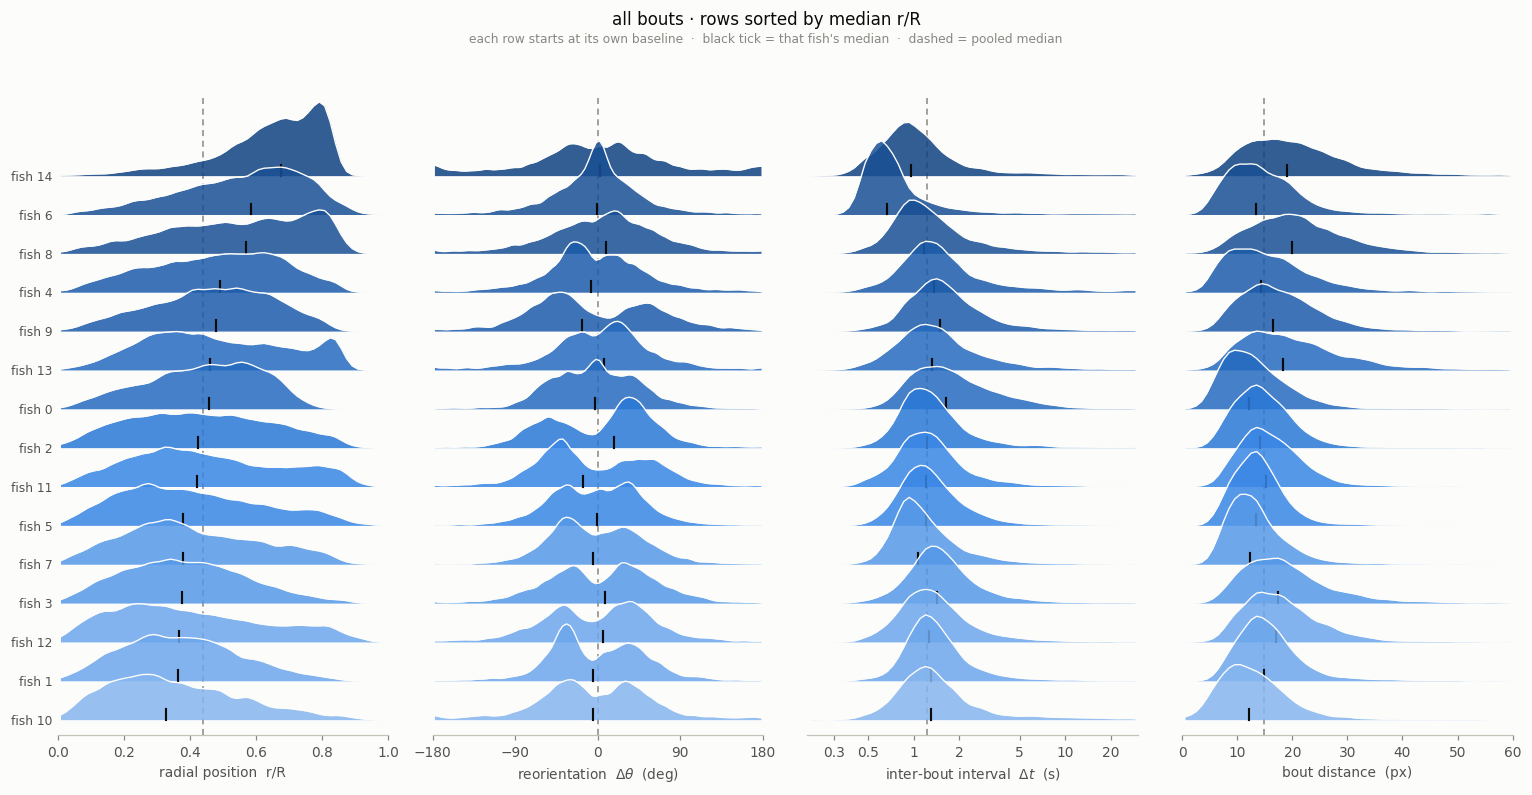

In [2]:
# Per fish distributions general
fig = plot_ridges(df, order_by="radial", title="all bouts · rows sorted by median r/R")
plt.show()

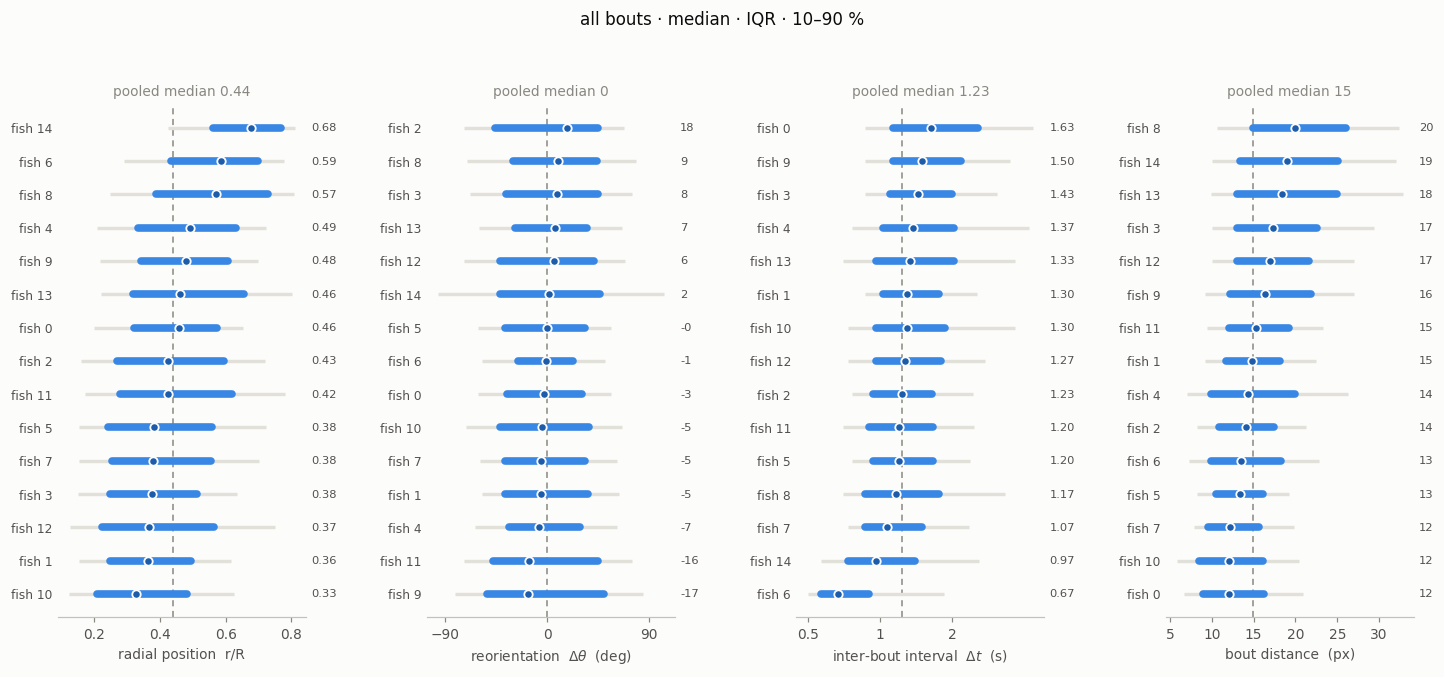

In [3]:
fig = plot_spread(df, title="all bouts · median · IQR · 10–90 %")
plt.show()

In [4]:
show(summary_table(df))

,n_bouts,radial_med,radial_iqr,radial_z,angular_med,angular_iqr,angular_z,dt_med,dt_iqr,dt_z,dist_med,dist_iqr,dist_z
fish,,,,,,,,,,,,,
0,4620,0.457,0.253,0.061,-3.077,66.619,-0.272,1.633,1.433,1.708,12.042,7.335,-1.257
1,5366,0.365,0.249,-0.888,-5.228,74.012,-0.500,1.300,0.725,0.252,14.765,6.449,-0.207
2,5639,0.426,0.325,-0.258,18.034,90.569,1.966,1.233,0.717,-0.039,14.036,6.676,-0.488
3,4850,0.376,0.263,-0.767,8.415,81.283,0.946,1.433,0.900,0.834,17.363,9.589,0.795
4,3292,0.492,0.296,0.424,-7.144,63.345,-0.703,1.367,1.000,0.543,14.318,10.151,-0.379
5,6842,0.381,0.314,-0.721,-0.296,70.225,0.023,1.200,0.733,-0.184,13.342,5.684,-0.756
6,3185,0.586,0.267,1.387,-0.585,48.297,-0.008,0.667,0.333,-2.513,13.454,8.399,-0.713
7,6505,0.380,0.300,-0.731,-5.102,70.559,-0.486,1.067,0.633,-0.767,12.207,6.134,-1.193
8,3265,0.570,0.341,1.221,9.462,74.353,1.057,1.167,0.900,-0.330,20.000,11.134,1.811


Facets for one channel at a time.

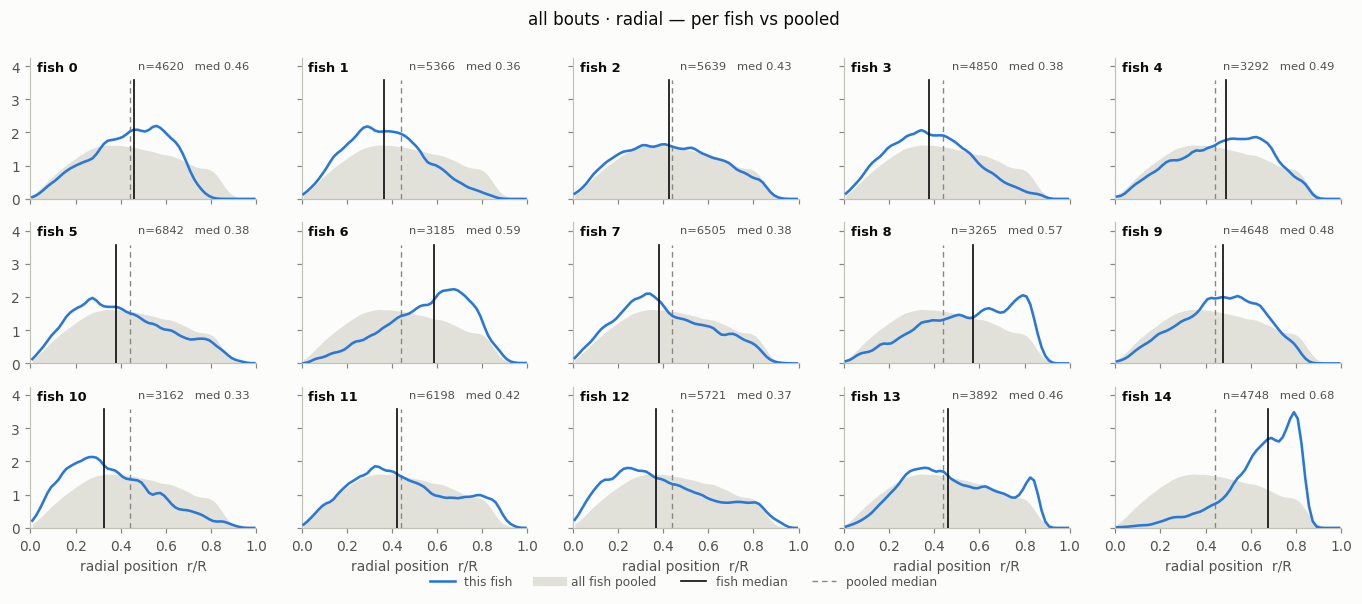

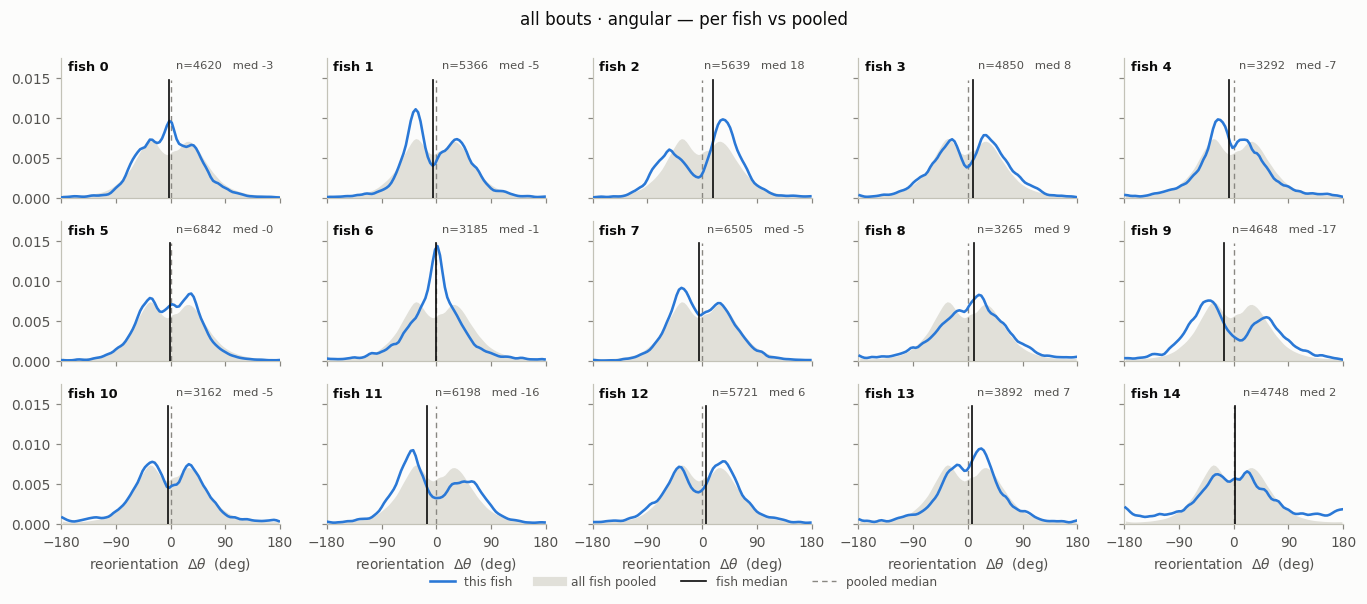

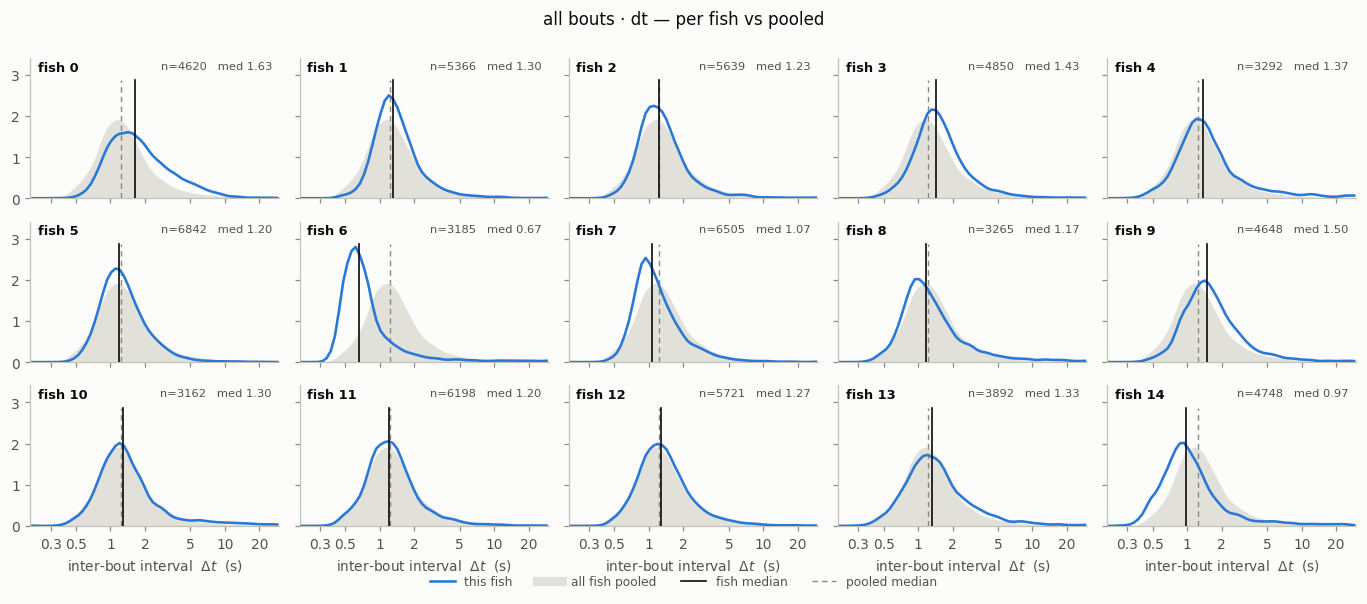

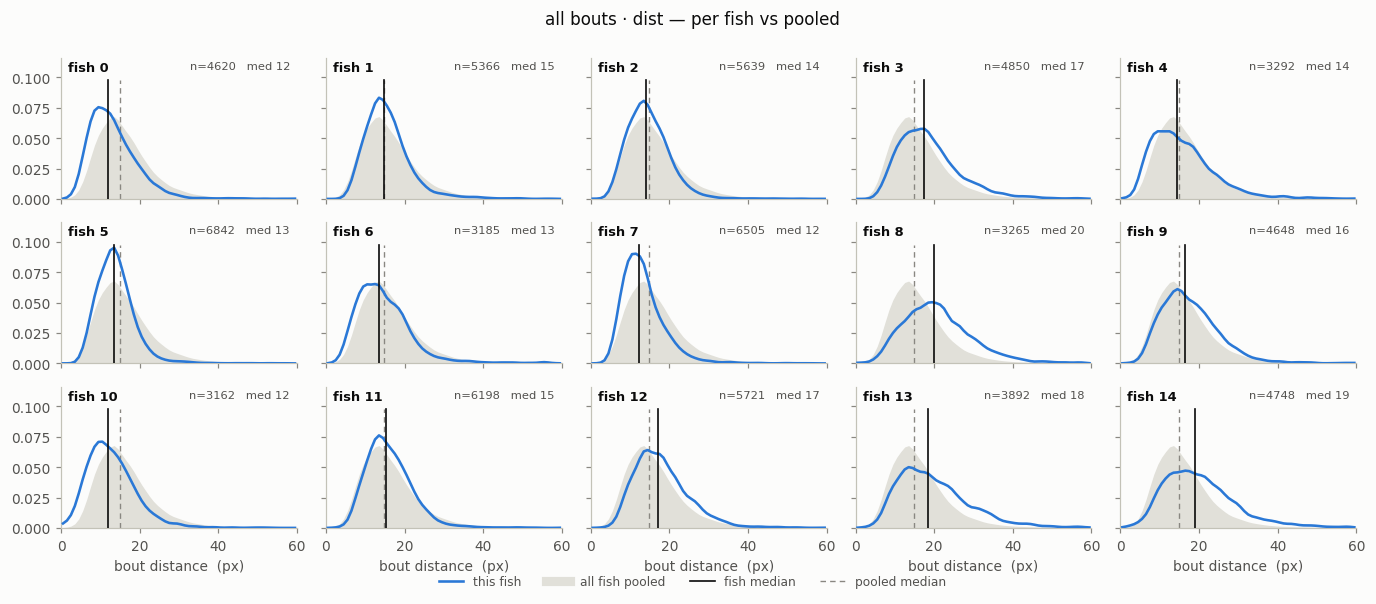

In [5]:
for key in KEYS:
    plot_per_fish(df, key, title=f"all bouts · {key} — per fish vs pooled")
    plt.show()

### 2 · No stimulus

No stimulus period only.

no stimulus: 31,060 bouts · 15 fish · off-axis radial 0.00% · angular 0.00% · dt 0.57% · dist 0.21%


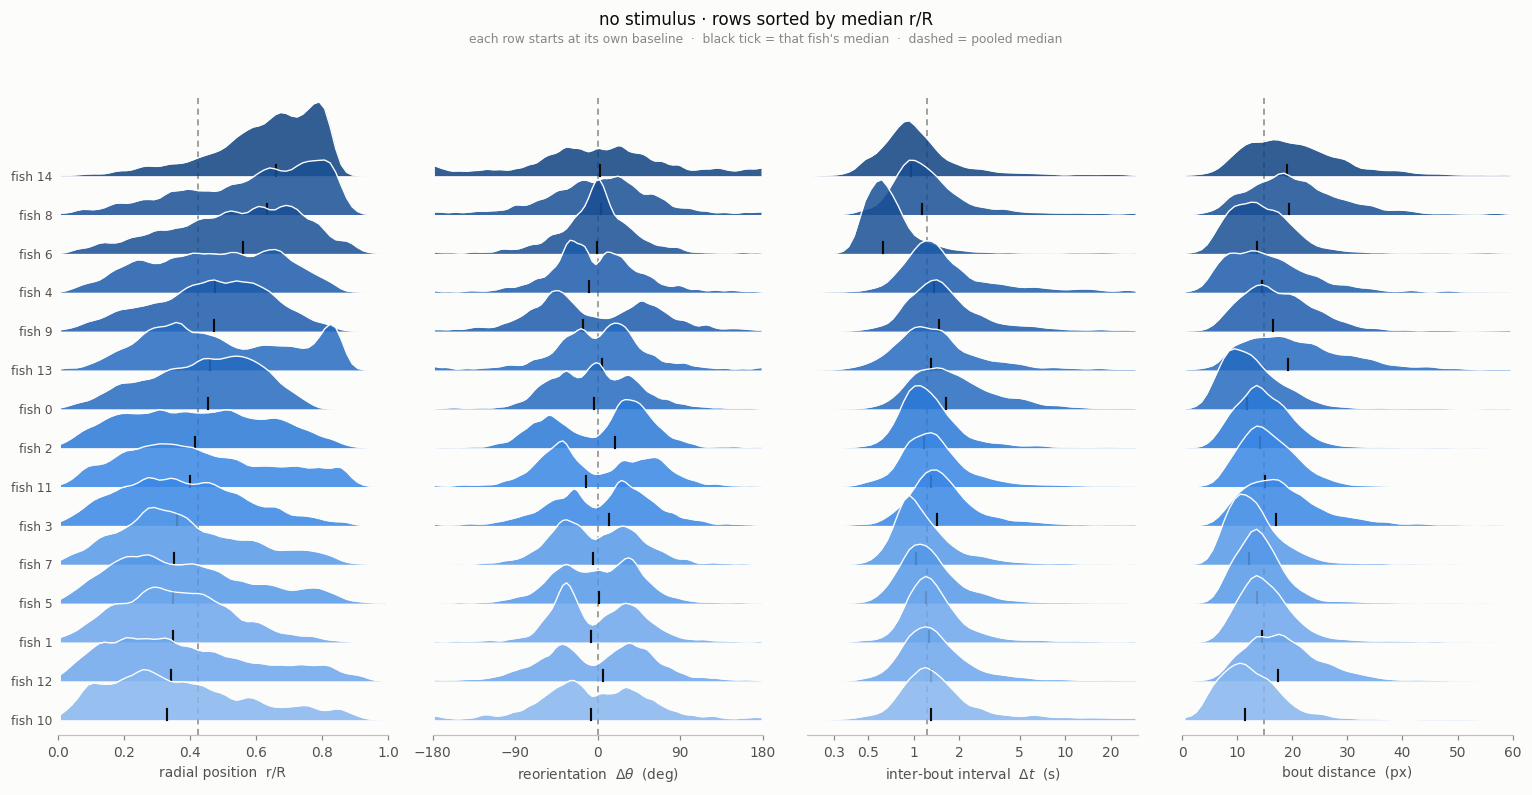

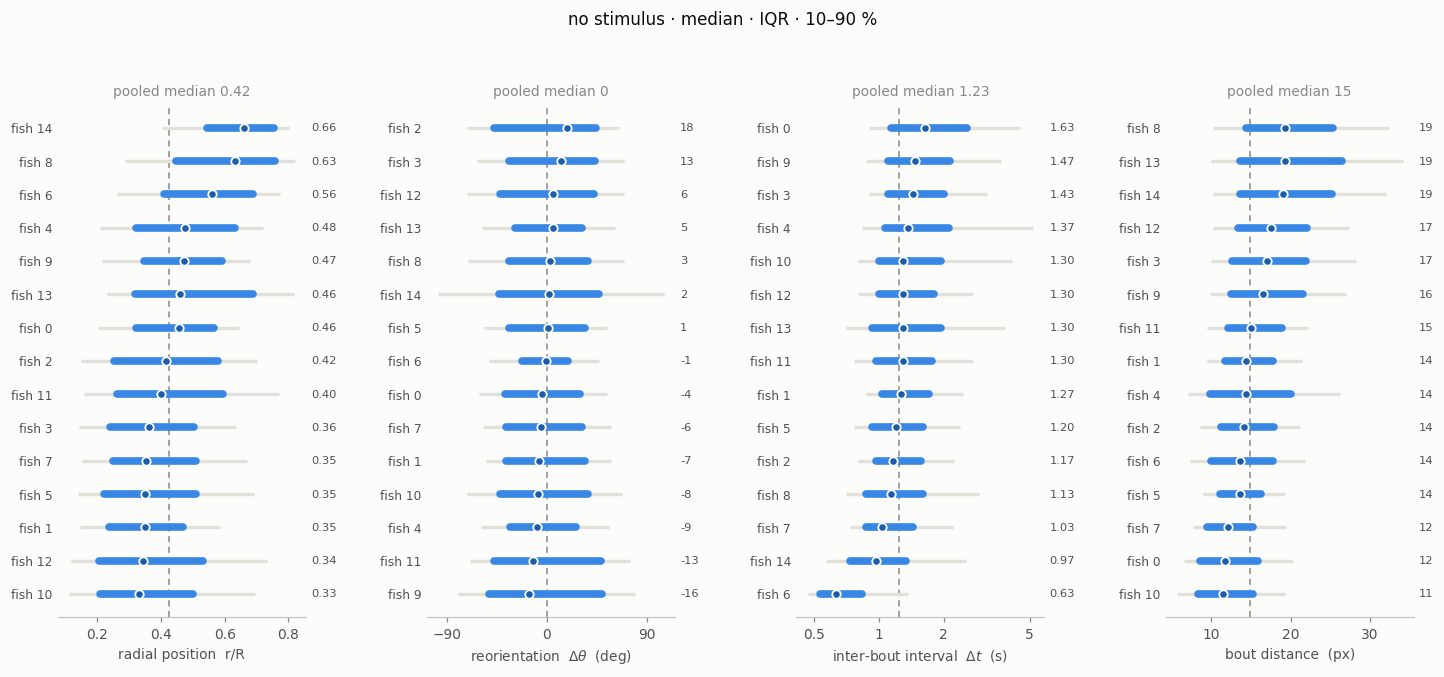

In [6]:
# No stim
d_none = df[df["cond"] == "none"]
head(d_none, "no stimulus")
plot_ridges(d_none, order_by="radial", title="no stimulus · rows sorted by median r/R")
plot_spread(d_none, title="no stimulus · median · IQR · 10–90 %")
plt.show()

### 3 · Moving stimulus

Moving stimulus period only.

moving dots: 26,264 bouts · 15 fish · off-axis radial 0.00% · angular 0.00% · dt 0.59% · dist 0.31%


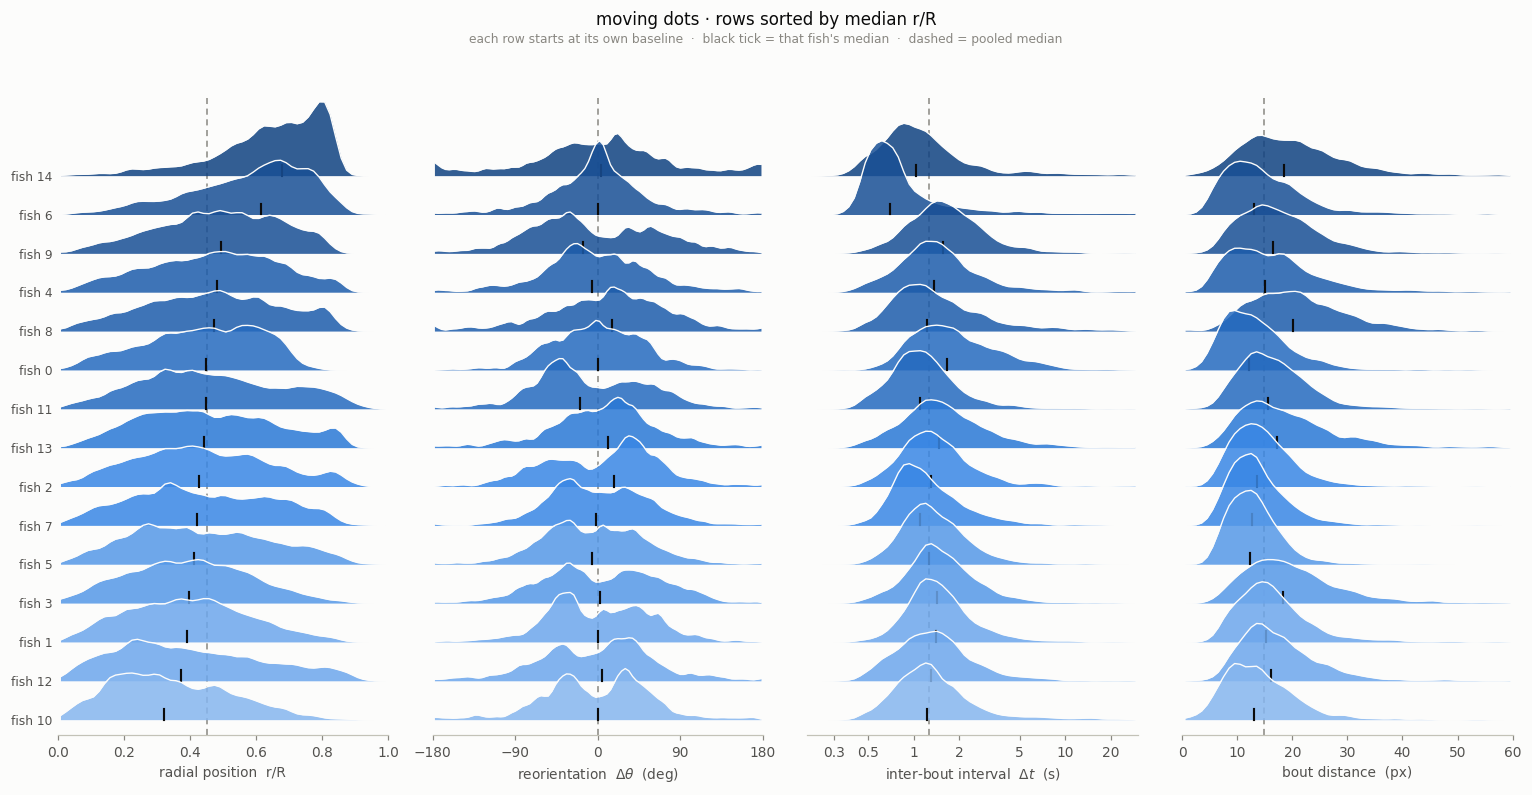

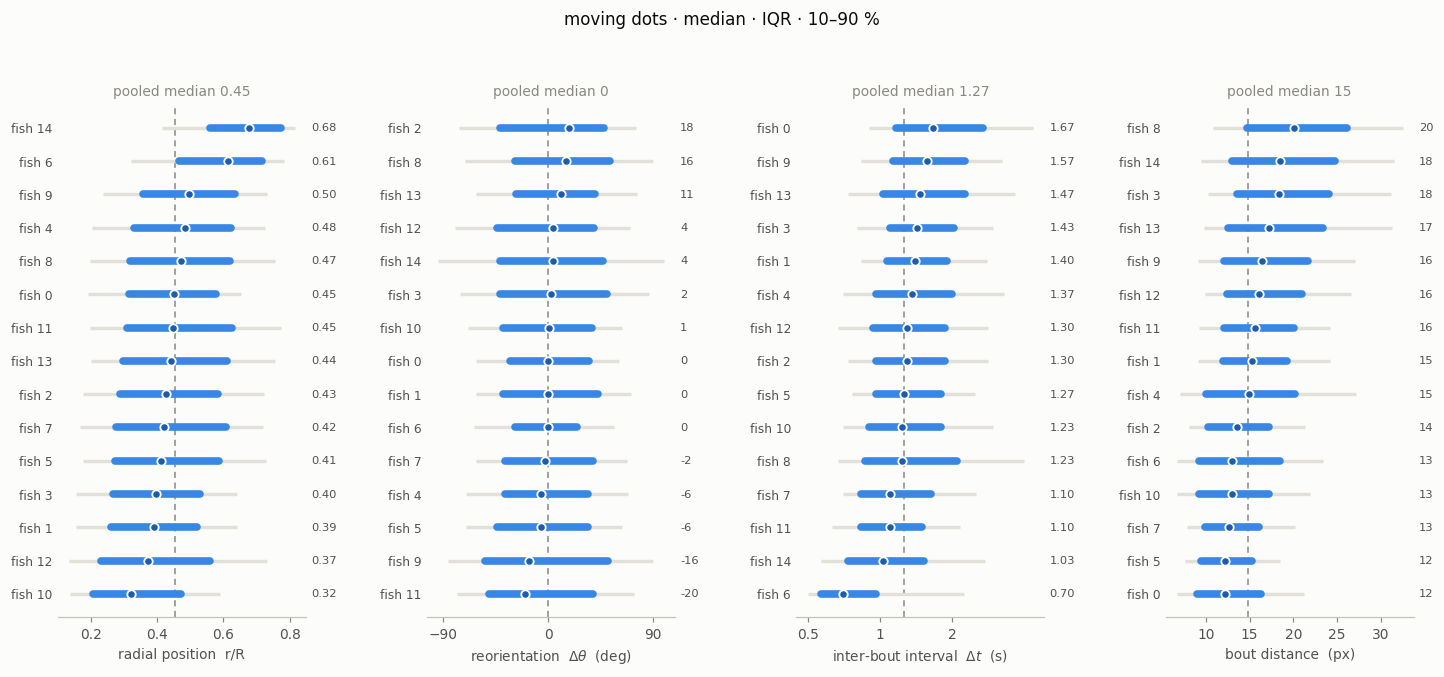

In [7]:
# Moving stim
d_move = df[df["cond"] == "moving"]
head(d_move, "moving dots")
plot_ridges(d_move, order_by="radial", title="moving dots · rows sorted by median r/R")
plot_spread(d_move, title="moving dots · median · IQR · 10–90 %")
plt.show()

### 4 · Static stimulus

Static stimulus period only.

static dots: 14,609 bouts · 15 fish · off-axis radial 0.00% · angular 0.00% · dt 0.73% · dist 0.20%


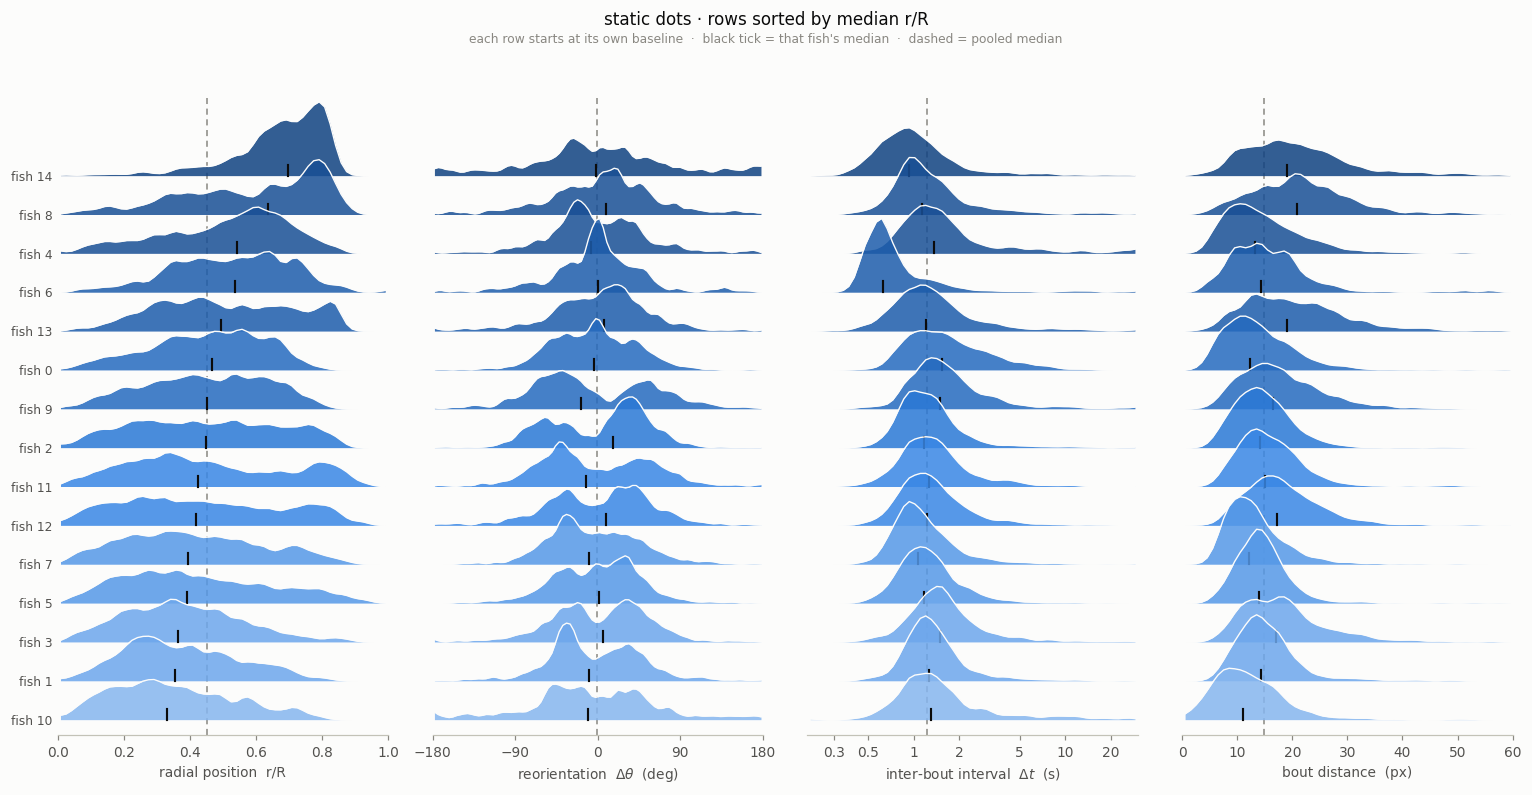

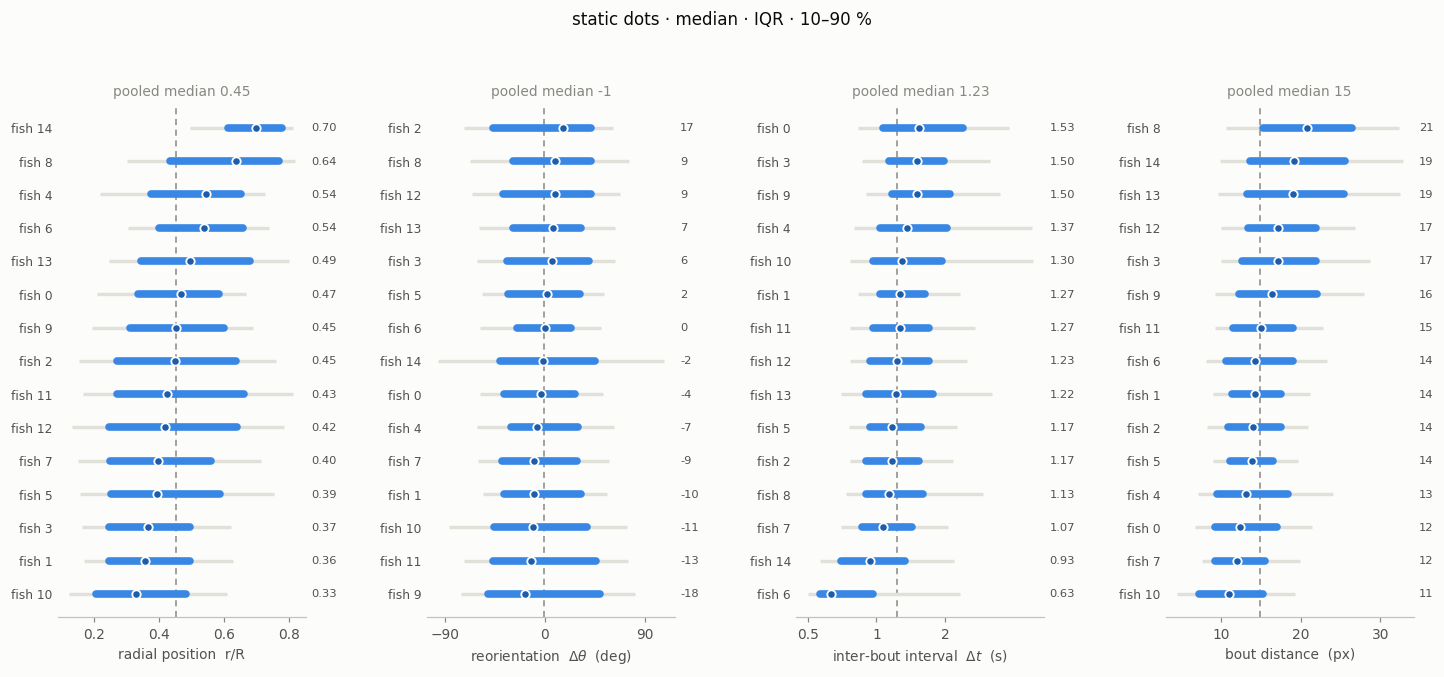

In [8]:
# Static stim
d_stat = df[df["cond"] == "static"]
head(d_stat, "static dots")
plot_ridges(d_stat, order_by="radial", title="static dots · rows sorted by median r/R")
plot_spread(d_stat, title="static dots · median · IQR · 10–90 %")
plt.show()

### 5 · The three conditions, inside each fish

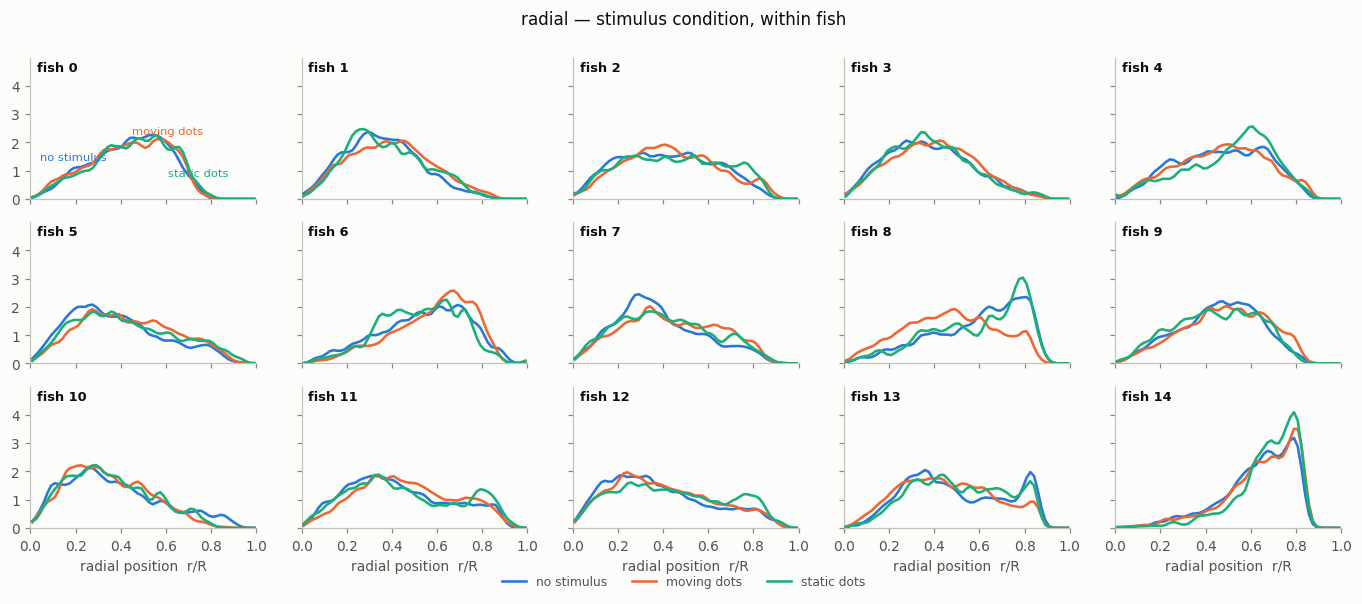

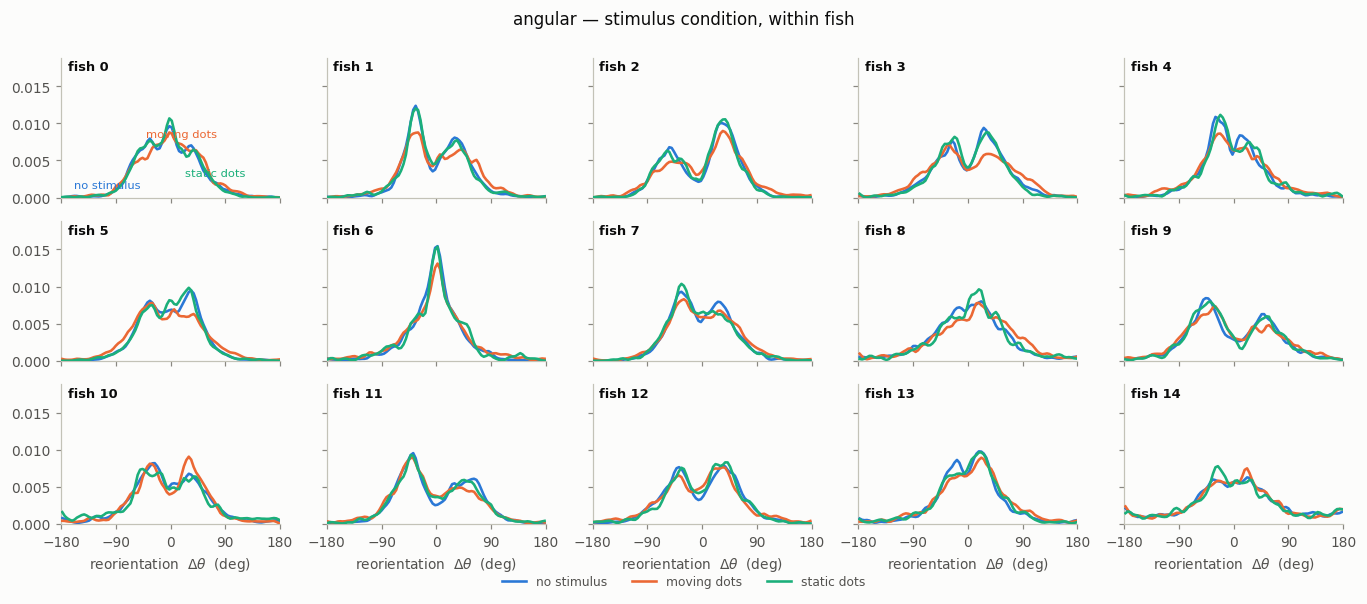

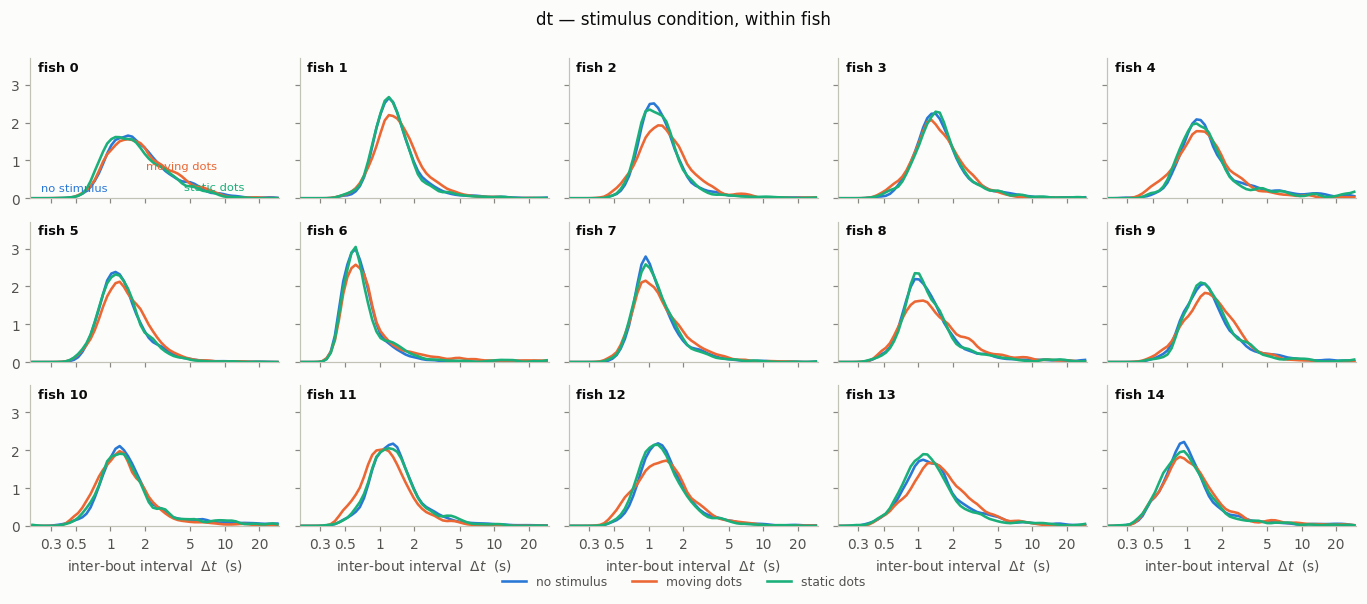

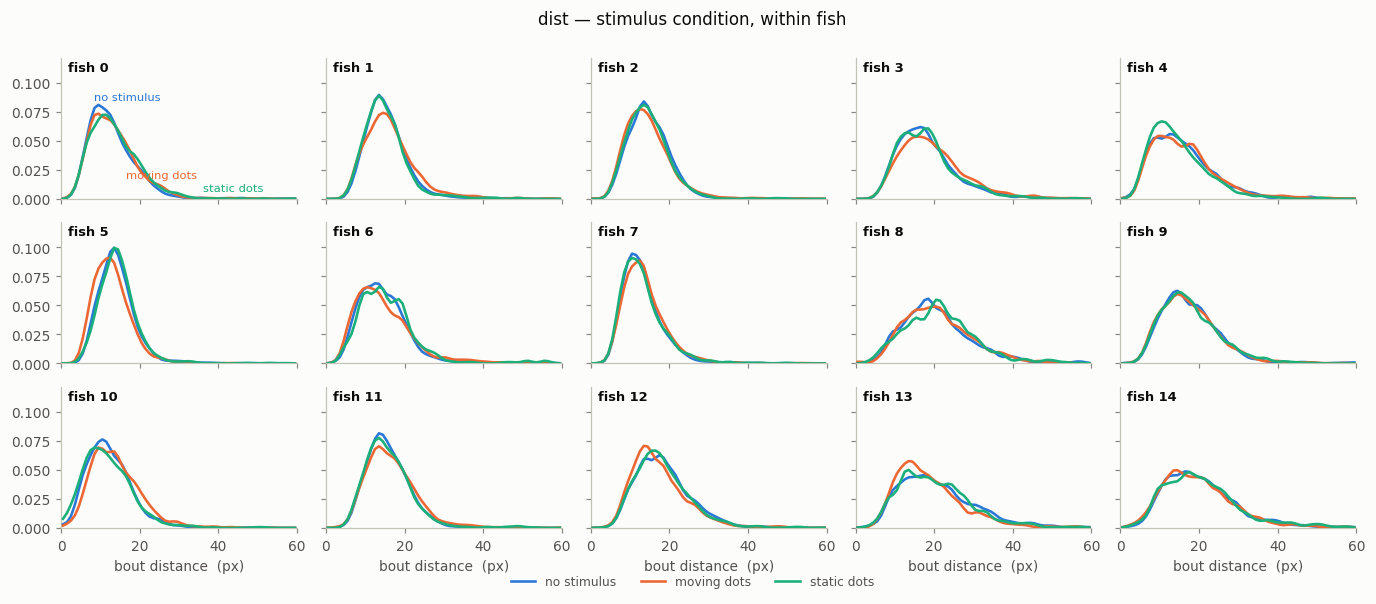

In [9]:
for key in KEYS:
    plot_conditions(df, key, title=f"{key} — stimulus condition, within fish")
    plt.show()

In [10]:
condition_table(df)

,no stimulus,moving dots,static dots,Δ vs none: moving dots,Δ vs none: static dots
r/R mean,0.438,0.456,0.459,0.019,0.022
|Δθ| mean (deg),44.359,48.035,44.275,3.675,-0.084
P(|Δθ|>10°),0.892,0.889,0.883,-0.003,-0.009
Δt mean (s),2.113,2.213,2.193,0.100,0.080
dist mean (px),16.191,16.393,16.304,0.201,0.112


Pooled across fish, the stimulus effect is small — but the fish differ from each other
by much more than the effect, so the pooled number is the wrong estimator. Below is the
paired version: each fish's condition summary **minus its own** no-stimulus value.
`std` across fish is the honest error bar on the row above.

In [11]:
cd = condition_deltas(df)
display(cd.groupby("vs no stimulus").agg(["mean", "std"]).round(3))

# diverging colour, so 0 must sit on the neutral midpoint -- background_gradient
# spans each column's own min..max, which would put the midpoint wherever the data
# happens to straddle. gmap scales every column to a symmetric [-1, 1] instead.
cd.style.format("{:+.3f}").background_gradient(
    cmap="RdBu_r", gmap=cd / cd.abs().max(), vmin=-1, vmax=1, axis=None)

r/R mean        |Δθ| mean (deg)        P(|Δθ|>10°)         \
                   mean    std            mean    std        mean    std   
vs no stimulus                                                             
moving dots       0.009  0.044           3.796  3.025       0.002  0.021   
static dots       0.018  0.023           0.149  2.290      -0.009  0.010   

               Δt mean (s)        dist mean (px)         
                      mean    std           mean    std  
vs no stimulus                                           
moving dots          0.067  0.550          0.166  1.049  
static dots          0.202  0.738          0.036  0.629

### 6 · Response to the stimulus


#### A · Does the fish close distance on the dots?

x : time (60s is a full block)

y : distance to stimulus

Each fish sees ~58 moving and ~33 static blocks and **no two blocks give the same curve**,
so each is one replicate: within a block we take the mean distance per 2 s bin, then
average those block means and band them with a **t-based 95 % CI across blocks**. Bouts
inside one block share a starting position relative to stimuli at block onset.

Two things to read with care:

⚠ **The moving curve is relative geometry.** For static dots the centroid does not move,
so a change in distance is entirely the fish. For moving dots the centroid moves too, so
the fish closing in and the dots sweeping past are not separable in this one number.

⚠ **A bin only sees blocks in which the fish bouted.** Distance is sampled at bouts, so a
fish that goes quiet contributes nothing to the later bins, and the curve is conditioned on
it still being active. A curve that stops early means fewer than 8 blocks still had a bout
that late — most visible for **fish 6**, whose static curve gives out early.

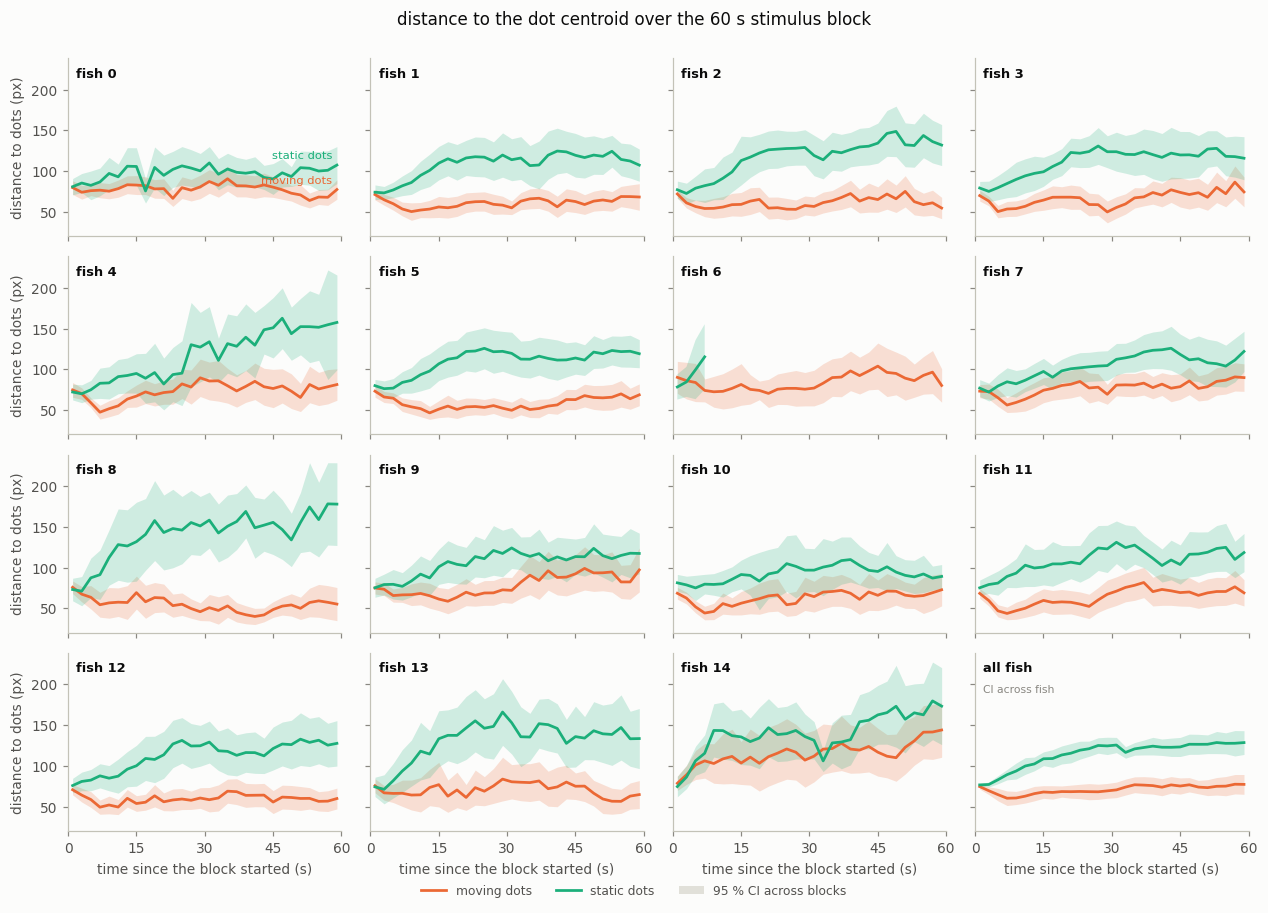

In [12]:
# Distance to the stimulus centroid over the block, per fish, moving vs static
plot_approach(df)
plt.show()

#### Why a curve stops early — the raw speed trace

**Fish 6's static curve gives out early.** 

Fish 6 suffers from long "dead" periods.

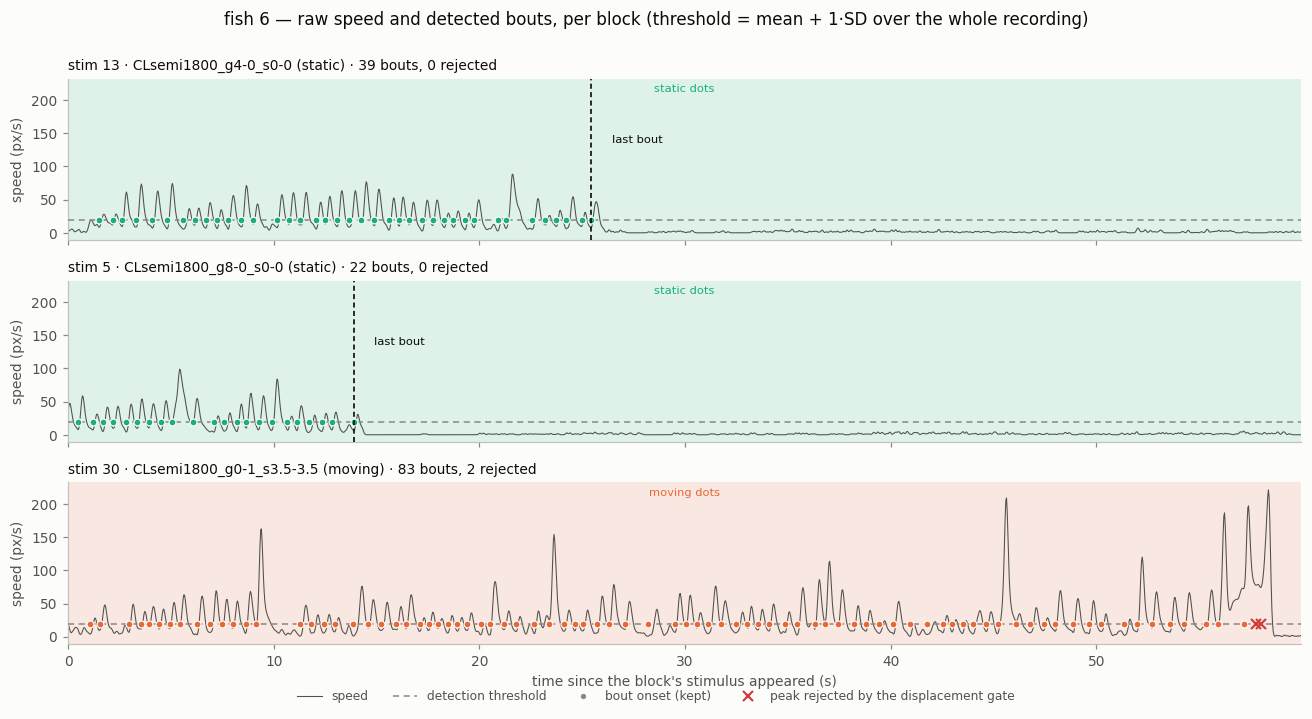

In [13]:
# Two static blocks where fish 6 goes quiet, and its busiest moving block for contrast
quiet = pick_blocks(df, 6, "static", n=2, min_bouts=15, last_before=30)
busy = pick_blocks(df, 6, "moving", n=1, min_bouts=15)
plot_bout_trace(6, quiet + busy)
plt.show()

In [14]:
block_activity(df, 6, quiet + busy)

window_s  mean_speed  max_speed  frac_over_thr
block   window                                                          
stim 13 before last bout      25.4       23.50      88.47         0.4450
        after                 34.5        1.82      46.77         0.0097
stim 5  before last bout      13.9       24.06      98.81         0.4689
        after                 46.0        1.36      30.73         0.0036
stim 30 before last bout      57.2       25.29     209.17         0.4505
        after                  2.8       58.70     221.43         0.5000

#### B · Does the fish turn toward the dots?

One bar per fish per condition:

```
P(turn toward) = P( sign(Δθ) == sign(φ) )      over turn bouts, |Δθ| > 10°
```

where `φ` is `stim_angle_travel`, the egocentric bearing to the dot centroid **measured
from the incoming chord**. **0.5 is chance** — a fish that turns without regard to where
the dots are. Forward bouts are excluded because a forward bout has no direction to be
"toward" anything. Whiskers are the 95 % CI across blocks, the same replicate unit as
panel A.

Bars are anchored on the 0.5 chance line rather than on zero, because 0.5 — not 0 — is
what "no response" scores, so bar length reads as the departure from chance.

**One frame throughout, onset to onset.** `φ` and `Δθ` are both CCW-positive against the
*same* reference — the direction the fish was already travelling when it reached this
onset — so `sign(Δθ) == sign(φ)` is literally "turned toward". This is **not** the shipped
`stim_angle_rad`, which is referenced to the body axis `f_ori_rad` and sits a median 40°
away, because the body axis is read before the fish turns and the chord after. Two reasons
the chord frame is the right one: it is the frame `Δθ` is defined in, and it is the only
one a rollout can reconstruct — a bout-to-bout model propagates `heading += Δθ` and never
emits anything that updates a body axis. It costs no data: `θ_{t−1} = heading_rad − Δθ`
is an exact per-row identity from the segmentation, so every bout keeps its bearing. This
is `fit_MLP_border._travel_ref`, the same reference the closed-loop rollout presents, so
the description and the model measure one thing. Note `evaluate.symbols_from_dtheta` names
`Δθ < −10` "Left" — the opposite naming; nothing here uses it.

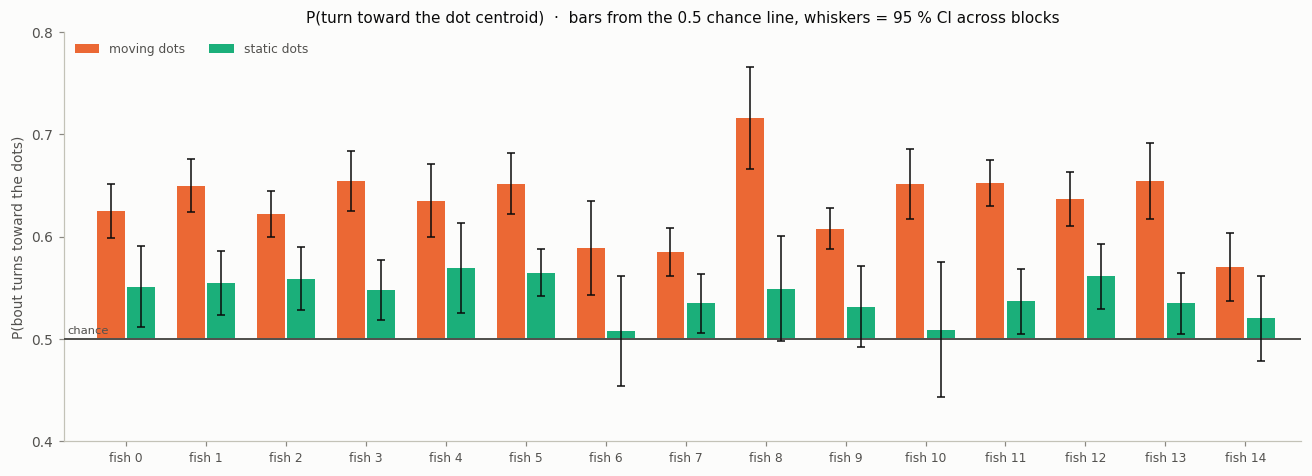

In [15]:
# P(bout turns toward the dot centroid), per fish, moving vs static
plot_toward_bars(df)
plt.show()

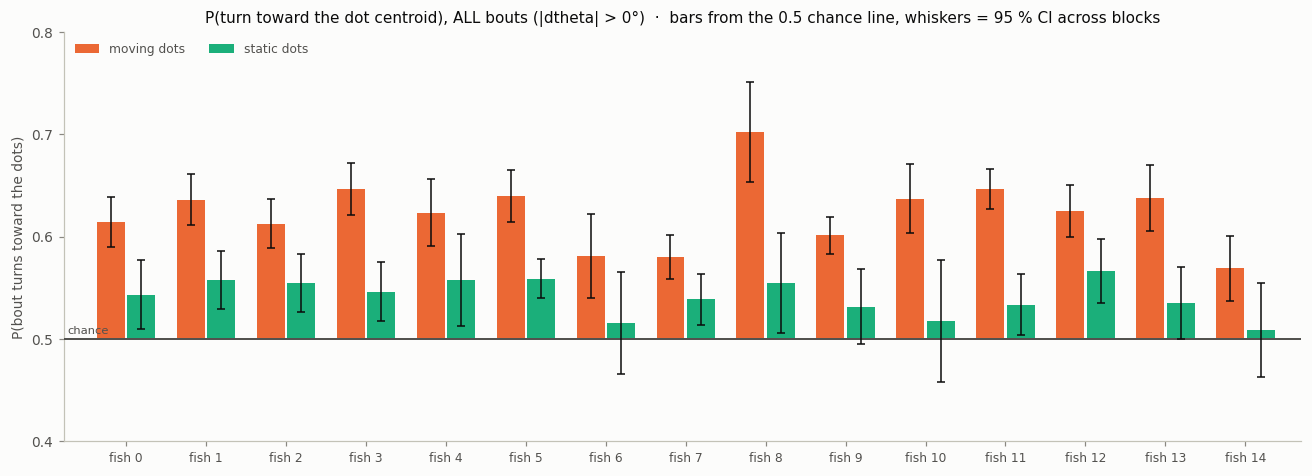

mean over fish of the per-fish P(turn toward); `departure` is the distance from chance
       cond      threshold   mean    lo    hi above_chance  departure
moving dots |dtheta| > 10° 0.6334 0.571 0.716        15/15     0.1334
moving dots  |dtheta| > 0° 0.6235 0.569 0.702        15/15     0.1235
static dots |dtheta| > 10° 0.5421 0.507 0.569        15/15     0.0421
static dots  |dtheta| > 0° 0.5414 0.509 0.566        15/15     0.0414

fraction of the effect that survives dropping the threshold:
cond
moving dots    0.926
static dots    0.983

share of stimulus bouts with |dtheta| <= 10°: 0.114


In [28]:
# The same bars with the forward/turn threshold REMOVED: every stimulus bout counts, split at
# 0 deg instead of +/-10 deg. What changes is the denominator -- the ~11 % of bouts with
# |dtheta| <= 10 deg come back in, and for those the sign of the chord angle is set by a fraction
# of a degree, so they contribute close to coin flips. The measure is therefore DILUTED toward
# 0.5, and the gap between the two panels is the size of that dilution, not a different behaviour.
# (Those same bouts are not lost information: the forward-bias bars below read them properly, via
# the decision NOT to turn rather than via a sign that is noise.)
def _turns_thr(g, thr):
    return g[g["dtheta_deg"].abs() > thr]          # thr = 0 keeps everything but exact zeros


def toward_by_block_thr(g, thr):
    t = _turns_thr(g, thr)
    if not len(t):
        return np.array([])
    per = (pd.DataFrame({"blk": t["blk"].to_numpy(), "tw": _toward(t)})
           .groupby("blk")["tw"].agg(["mean", "size"]))
    return per.loc[per["size"] >= MIN_TURNS, "mean"].to_numpy()


def toward_stats_thr(d, thr):
    return {(f, c): _mean_ci(toward_by_block_thr(stim(d[d.fish_id == f], c), thr), MIN_BLOCKS)
            for f in FISH for c in STIM_CONDS}


def plot_toward_bars_thr(d, thr=0.0, title=None):
    """`plot_toward_bars` with the turn threshold as an argument."""
    st = toward_stats_thr(d, thr)
    x, w = np.arange(len(FISH)), .38
    fig, ax = plt.subplots(figsize=(12, 4.4))
    ax.axhline(.5, color=INK2, lw=1.3, zorder=4)
    for k, c in enumerate(STIM_CONDS):
        m = np.array([st[(f, c)][0] for f in FISH])
        lo = np.array([st[(f, c)][1] for f in FISH])
        hi = np.array([st[(f, c)][2] for f in FISH])
        xs = x + (k - .5) * w
        ax.bar(xs, m - .5, bottom=.5, width=w - .03, color=COND_COLOR[c],
               label=CONDS[c], zorder=2)
        ax.errorbar(xs, m, yerr=[m - lo, hi - m], fmt="none", ecolor=INK,
                    elinewidth=1, capsize=2.5, zorder=5)
    ax.set_xticks(x)
    ax.set_xticklabels([f"fish {f}" for f in FISH], fontsize=8)
    ax.set_xlim(-.78, len(FISH) - .3)
    ax.set_ylabel("P(bout turns toward the dots)")
    ax.set_yticks([.4, .5, .6, .7, .8])
    ax.text(-.74, .503, "chance", ha="left", va="bottom", fontsize=7.5, color=INK2)
    ax.legend(fontsize=8, labelcolor=INK2, ncol=2, loc="upper left")
    ax.set_title(title or f"P(turn toward the dot centroid), ALL bouts (|dtheta| > {thr:g}°)  ·  "
                 "bars from the 0.5 chance line, whiskers = 95 % CI across blocks",
                 fontsize=10, color=INK)
    fig.tight_layout()
    return fig


plot_toward_bars_thr(df, thr=0.0)
plt.show()

# the two side by side, pooled over blocks within a fish
_rows = []
for c in STIM_CONDS:
    for thr in (DTHETA0, 0.0):
        v = np.array([_mean_ci(toward_by_block_thr(stim(df[df.fish_id == f], c), thr),
                               MIN_BLOCKS)[0] for f in FISH])
        _rows.append(dict(cond=CONDS[c], threshold=f"|dtheta| > {thr:g}°",
                          mean=round(float(np.nanmean(v)), 4),
                          lo=round(float(np.nanmin(v)), 3), hi=round(float(np.nanmax(v)), 3),
                          above_chance=f"{int((v > .5).sum())}/{int(np.isfinite(v).sum())}"))
_t = pd.DataFrame(_rows)
_t["departure"] = (_t["mean"] - .5).round(4)
print("mean over fish of the per-fish P(turn toward); `departure` is the distance from chance")
print(_t.to_string(index=False))
_d = _t.groupby("cond").departure.apply(lambda s: s.iloc[1] / s.iloc[0])
print("\nfraction of the effect that survives dropping the threshold:")
print(_d.round(3).to_string())
print(f"\nshare of stimulus bouts with |dtheta| <= {DTHETA0:g}°: "
      f"{(stim(df)['dtheta_deg'].abs() <= DTHETA0).mean():.3f}")

In [16]:
toward_table(df)

,moving dots,moving dots 95% CI,moving dots n blocks,static dots,static dots 95% CI,static dots n blocks,moving − static
fish,,,,,,,
0,0.625,"[0.599, 0.652]",60,0.551,"[0.511, 0.591]",35,0.074
1,0.650,"[0.624, 0.676]",58,0.555,"[0.523, 0.586]",32,0.095
2,0.622,"[0.599, 0.645]",58,0.559,"[0.528, 0.589]",32,0.063
3,0.654,"[0.625, 0.683]",59,0.548,"[0.519, 0.577]",34,0.106
4,0.635,"[0.600, 0.671]",52,0.569,"[0.525, 0.613]",26,0.066
5,0.652,"[0.622, 0.681]",60,0.565,"[0.542, 0.588]",35,0.087
6,0.589,"[0.543, 0.635]",47,0.507,"[0.454, 0.561]",15,0.081
7,0.585,"[0.561, 0.608]",58,0.535,"[0.506, 0.564]",33,0.050
8,0.716,"[0.666, 0.766]",45,0.549,"[0.498, 0.600]",23,0.167


#### B′ · Against a blind fish, and with straight bouts included

**0.5 is not what a blind fish scores.** Fish turn away from the wall, toward the dish centre
(0.60 of stimulus turns), and the dots lie on the centre side of the fish about as often (0.59),
so wall avoidance alone reads as "turning toward the dots". Near the wall the effect is large: a
blind fish scores 0.54 at r/R < 0.5 but 0.77 beyond r/R = 0.85.

The control keeps the fish's real behaviour and replaces the dots with dots it never saw:

- **blind (pause)** — pause bouts, with nothing on screen, scored against the dot centroid of a
  random stimulus block of the same fish and condition, at the same time in block;
- **blind (swap)** — the condition's own bouts, scored against the dots of a *different* block.

Both use the §6B estimator unchanged (per-block P, blocks with ≥ 5 bouts, CI across blocks),
averaged over 10 phantom draws.

**The measure.** Every bout counts, straight ones included: *toward* means the bout leaves the
fish heading within ±90° of the dot centroid, `|wrap(φ − Δθ)| < 90°`, so a straight bout already
aimed at the dots counts. It reads the heading the bout *ends* on, so it includes where the fish
was already pointing — which is exactly why it needs the blind reference. One panel per
condition on the same scale; per fish, the coloured bar is the real fish and the grey bar the
blind fish (pause control), both drawn from 0.5. The table below also gives the §6B turn-sign
measure (|Δθ| > 10°) against the same controls.

**Result.** Moving dots beat the blind fish on both measures: the excess over blind is about
+0.07 for the turn sign and +0.09 for the heading. Static dots do **not** beat it. On the turn
sign they sit at the blind level, slightly below it; on the heading they sit clearly *below*
it in every fish (≈ 0.47 vs 0.52), so fish actively head away from static dots, consistent
with the distance growing over the first 25 s (§6A). The "static slightly above chance" in the
bars above is wall geometry, not a response to the dots.

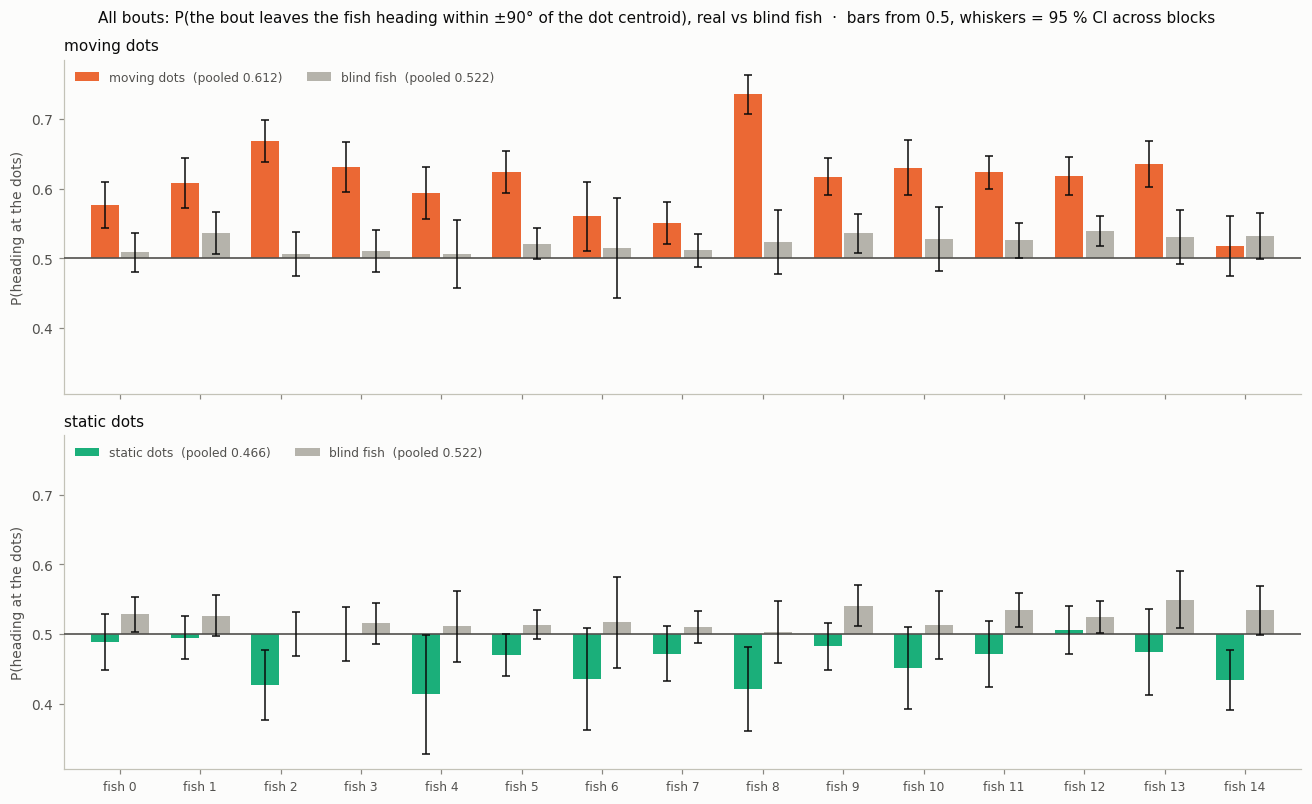

,measure,cond,observed,95% CI,blind (pause),blind (swap),excess over blind,z,fish above blind
0,"turn sign, |Δθ| > 10°",moving dots,0.633,"[0.625, 0.641]",0.561,0.551,0.071,17.6,15/15
1,"turn sign, |Δθ| > 10°",static dots,0.544,"[0.534, 0.553]",0.561,0.560,-0.017,-3.6,1/15
2,"heading at the dots, all bouts",moving dots,0.612,"[0.603, 0.621]",0.522,0.512,0.090,19.5,14/15
3,"heading at the dots, all bouts",static dots,0.466,"[0.454, 0.478]",0.522,0.523,-0.057,-9.3,0/15


In [ ]:
# §6B′ -- the BLIND control for "toward", and an all-bout version of the measure.
#
# A fish that ignores the dots does not score 0.5. It turns away from the wall (toward the dish
# centre), and the dots usually lie on the centre side of it, so wall avoidance alone reads as
# "turning toward the dots". The control keeps the fish's real behaviour and replaces the dots
# with ones it never saw:
#   blind (pause) -- PAUSE bouts (nothing on screen), scored against the dot centroid of a random
#                    stimulus block of the same fish and condition, at the same time-in-block;
#   blind (swap)  -- the condition's own bouts, scored against the dots of a DIFFERENT block.
# Same estimator as §6B in both: per-block P(toward), blocks with >= MIN_TURNS bouts, mean and
# t-CI across blocks.
#
# Two measures:
#   turn sign     -- §6B as is: sign(Δθ) == sign(φ), turn bouts only (|Δθ| > 10°);
#   heading at    -- ALL bouts: the bout leaves the fish heading within ±90° of the dot centroid,
#                    |wrap(φ − Δθ)| < 90°. A straight bout already aimed at the dots counts as
#                    toward, so nothing is split by turn size -- but it scores the heading the bout
#                    ENDS on, which includes where the fish was already pointing.
BLIND_REPS = 10
_rng_blind = np.random.default_rng(0)
df["theta_prev"] = _wrap_pi(df["heading_rad"] - np.radians(df["dtheta_deg"]))

_stim_b = stim(df)
_pause_b = df[df["cond"] == "none"]
# dot-centroid track per (fish, block, condition), sorted by time in block
_dot_tracks = {k: g.sort_values("t_blk")[["t_blk", "dot_cx", "dot_cy"]].dropna().to_numpy()
               for k, g in _stim_b.groupby(["fish_id", "blk", "cond"])}


def _dots_at(track, t):
    """Dot centroid of `track` at the nearest recorded time to each t."""
    i = np.clip(np.searchsorted(track[:, 0], t), 0, len(track) - 1)
    j = np.clip(i - 1, 0, len(track) - 1)
    k = np.where(np.abs(track[j, 0] - t) < np.abs(track[i, 0] - t), j, i)
    return track[k, 1], track[k, 2]


def phantom_bearing(d, cond, rng):
    """Bearing (incoming-chord frame) to dots from another block of the same fish and condition."""
    cx, cy = np.full(len(d), np.nan), np.full(len(d), np.nan)
    for f, gf in d.groupby("fish_id"):
        keys = [k for k in _dot_tracks if k[0] == f and k[2] == cond]
        for b, gb in gf.groupby("blk"):
            others = [k for k in keys if k[1] != b]
            x, y = _dots_at(_dot_tracks[others[rng.integers(len(others))]], gb["t_blk"].to_numpy())
            idx = d.index.get_indexer(gb.index)
            cx[idx], cy[idx] = x, y
    return _wrap_pi(np.arctan2(cy - d["y_px"].to_numpy(), cx - d["x_px"].to_numpy())
                    - d["theta_prev"].to_numpy())


MEASURES = {"sign": "turn sign, |Δθ| > 10°", "head": "heading at the dots, all bouts"}


def toward_blocks(d, phi, measure):
    """Per-(fish, block) P(toward) under `measure`, blocks with >= MIN_TURNS scored bouts."""
    dth = d["dtheta_deg"].to_numpy()
    ok = np.isfinite(phi)
    if measure == "sign":
        ok &= np.abs(dth) > DTHETA0
        tw = np.sign(dth) == np.sign(phi)
    else:
        tw = np.abs(_wrap_pi(phi - np.radians(dth))) < np.pi / 2
    per = (pd.DataFrame({"f": d["fish_id"].to_numpy()[ok], "b": d["blk"].to_numpy()[ok],
                         "tw": tw[ok].astype(float)})
           .groupby(["f", "b"])["tw"].agg(["mean", "size"]))
    return per[per["size"] >= MIN_TURNS]


def _summ(per):
    """(pooled mean, lo, hi) over all blocks, and per-fish (mean, lo, hi)."""
    return (_mean_ci(per["mean"].to_numpy(), MIN_BLOCKS)[:3],
            {f: _mean_ci(per.loc[f, "mean"].to_numpy(), MIN_BLOCKS)[:3] for f in FISH})


blind = {}
for c in STIM_CONDS:
    dc = _stim_b[_stim_b["cond"] == c]
    reps = {"pause": [], "swap": []}
    for _ in range(BLIND_REPS):
        reps["pause"].append((_pause_b, phantom_bearing(_pause_b, c, _rng_blind)))
        reps["swap"].append((dc, phantom_bearing(dc, c, _rng_blind)))
    for m in MEASURES:
        obs = _summ(toward_blocks(dc, dc["stim_angle_travel"].to_numpy(), m))
        ctl = {kind: [_summ(toward_blocks(d, phi, m)) for d, phi in reps[kind]] for kind in reps}
        blind[(m, c)] = dict(
            obs=obs,
            pooled={k: np.mean([r[0][0] for r in v]) for k, v in ctl.items()},
            fish={k: np.array([np.nanmean([r[1][f][0] for r in v]) for f in FISH]) for k, v in ctl.items()},
            # per-fish CI of the blind level: the across-block CI of each draw, averaged over draws
            fish_ci={k: np.array([[np.nanmean([r[1][f][j] for r in v]) for j in (1, 2)] for f in FISH])
                     for k, v in ctl.items()})


BLIND_COLOR = "#b5b3ab"


def plot_toward_blind(res, measure="head"):
    """One panel per condition, same y scale: per fish, the observed P(toward) next to the
    blind fish's P(toward) (pause bouts scored against phantom dots). Both bars start from 0.5,
    as in §6B, so a bar's length is its departure from 0.5 and the two read against each other."""
    fig, axes = plt.subplots(len(STIM_CONDS), 1, figsize=(12, 7.4), sharex=True, sharey=True)
    x, w = np.arange(len(FISH)), .38
    for ax, c in zip(axes, STIM_CONDS):
        r = res[(measure, c)]
        obs = np.array([r["obs"][1][f] for f in FISH])                       # (mean, lo, hi)
        bl = np.column_stack([r["fish"]["pause"], r["fish_ci"]["pause"]])
        for k, (v, color, lab) in enumerate([
                (obs, COND_COLOR[c], f"{CONDS[c]}  (pooled {r['obs'][0][0]:.3f})"),
                (bl, BLIND_COLOR, f"blind fish  (pooled {r['pooled']['pause']:.3f})")]):
            xs = x + (k - .5) * w
            ax.bar(xs, v[:, 0] - .5, bottom=.5, width=w - .03, color=color, label=lab, zorder=2)
            ax.errorbar(xs, v[:, 0], yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="none",
                        ecolor=INK, elinewidth=1, capsize=2.5, zorder=5)
        ax.axhline(.5, color=INK2, lw=1.1, zorder=4)
        ax.set_ylabel("P(heading at the dots)")
        ax.set_title(CONDS[c], fontsize=10, color=INK, loc="left")
        ax.legend(fontsize=8, labelcolor=INK2, loc="upper left", ncol=2)
    axes[-1].set_xticks(x)
    axes[-1].set_xticklabels([f"fish {f}" for f in FISH], fontsize=8)
    axes[-1].set_xlim(-.7, len(FISH) - .3)
    fig.suptitle("All bouts: P(the bout leaves the fish heading within ±90° of the dot centroid), real vs "
                 "blind fish  ·  bars from 0.5, whiskers = 95 % CI across blocks", fontsize=10, color=INK)
    fig.tight_layout()
    return fig


plot_toward_blind(blind)
plt.show()

_rows = []
for m in MEASURES:
    for c in STIM_CONDS:
        r = blind[(m, c)]
        (mu, lo, hi), per_fish = r["obs"]
        top = max(r["pooled"].values())
        fish_top = np.maximum(r["fish"]["pause"], r["fish"]["swap"])
        fm = np.array([per_fish[f][0] for f in FISH])
        _rows.append({"measure": MEASURES[m], "cond": CONDS[c], "observed": round(mu, 3),
                      "95% CI": f"[{lo:.3f}, {hi:.3f}]",
                      "blind (pause)": round(r["pooled"]["pause"], 3),
                      "blind (swap)": round(r["pooled"]["swap"], 3),
                      "excess over blind": round(mu - top, 3),
                      "z": round((mu - top) / ((hi - lo) / 3.92), 1),
                      "fish above blind": f"{int((fm > fish_top).sum())}/{len(FISH)}"})
pd.DataFrame(_rows)


#### C · Does the fish keep going straight when the dots are ahead?

The following index above is conditional on turning and reads `sign(Δθ)`, so it has to drop
forward bouts — at |Δθ| ≤ 10° the sign is noise, since chord-angle error on a ~13 px leg is
already several degrees. But **the information in those bouts was never in the sign**: it is
in the *decision not to turn*. A fish that swims straight while the dots are ahead and turns
when they are not is following, and that is 11.4 % of stimulus bouts the index cannot see.

```
forward bias = P(|Δθ| ≤ 10° | dots within 60°) − P(|Δθ| ≤ 10° | dots beyond 120°)
```

Zero means the choice to swim straight is unrelated to where the dots are. Bars start at
zero here (unlike §6B) because this is already a difference of probabilities, so the bar
length *is* the effect.

**This is the sharpest moving-vs-static dissociation in the notebook.** Pooled, `P(forward)`
falls monotonically with bearing under moving dots — 0.191 at 0–30° down to 0.081 at
150–180° — and the median bearing on a forward bout is **66°** against 96° when turning
(p = 2e-72). Per fish the moving effect is **15/15**, mean bias +0.080.

Under static dots it is much flatter (0.104–0.130) and the bias is under a third the size
(+0.023, 12/15 fish) — but it is **not** null: the bearing on a forward bout is still 101°
against 105° when turning, p = 0.008. So static dots are seen and weakly acted on, they
just do not organise forward swimming the way moving dots do. *(In the body-axis frame
this contrast read as flat and non-significant; measuring `φ` from the chord the fish is
actually travelling along resolves it.)*

It also constrains the model in a way the following index does not: reproducing this
requires the turn head's **concentration** to depend on bearing — p(Δθ | φ) must get peakier
near zero when the dots are ahead — not merely its mean or sign.

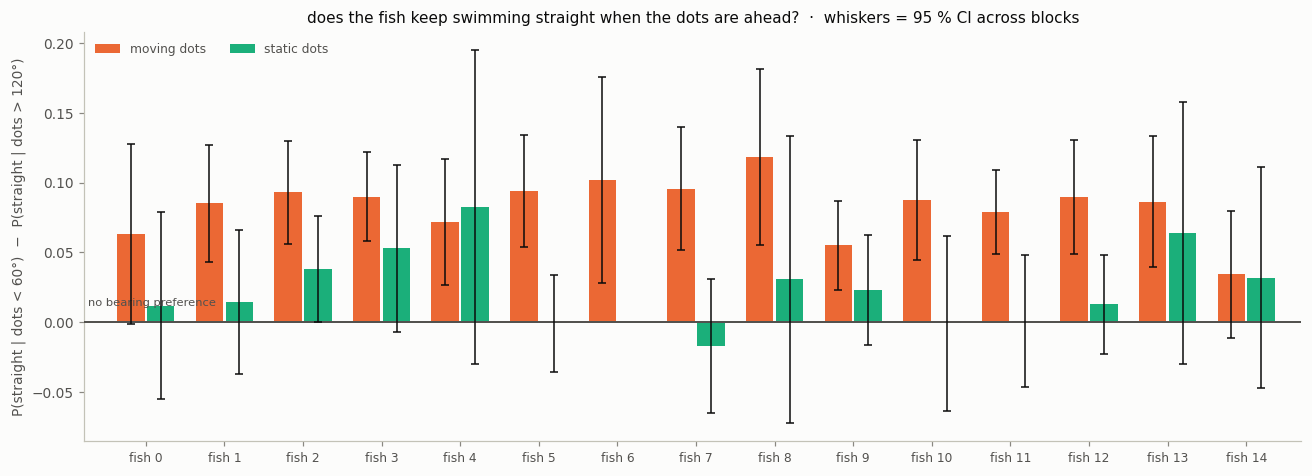

In [17]:
plot_forward_bias_bars(df)
plt.show()

In [18]:
forward_bias_table(df)

,moving dots ahead,moving dots behind,moving dots bias,static dots ahead,static dots behind,static dots bias
fish,,,,,,
0,0.196,0.138,0.058,0.208,0.196,0.012
1,0.162,0.070,0.092,0.111,0.090,0.021
2,0.129,0.037,0.092,0.094,0.055,0.039
3,0.132,0.044,0.088,0.113,0.074,0.039
4,0.186,0.119,0.067,0.165,0.111,0.054
5,0.188,0.102,0.086,0.127,0.138,-0.011
6,0.284,0.200,0.084,0.333,0.250,0.083
7,0.171,0.088,0.083,0.109,0.131,-0.022
8,0.184,0.061,0.123,0.167,0.134,0.033


### 7 · Is fish 6 actually all right?

Watch the two blocks at **real speed, 30 fps**. Top row is the dish with the static
dots and the fish as a heading arrow trailing 2 s of path; bottom row is that block's
speed trace with a cursor, so the picture and the number never drift apart. Bout onsets
and the trace are the same verified reproduction of `scripts/segment_bouts.py` used above.

Writes `mp4_fish_6check.mp4` to the repo root (~60 s of video, a couple of minutes to
render).

**Naming a block.** Every function here takes the same label the tables print —
`"stim 13"`, `"pause 76"` — so you can paste one straight out of `worst_gaps`.

In [19]:
# The two static blocks from §6A' where fish 6 goes quiet.
# Real time: fps=FPS (30). Pass e.g. fps=60 to watch it at 2x, max_frames=... to preview.
# make_block_video(6, ["stim 13", "stim 5"], ROOT / "mp4_fish_6check.mp4")

# To watch it inline instead of in a player:
#   from IPython.display import Video; Video("../mp4_fish_6check.mp4", width=900)

The same for **fish 8** (54 % of its session quiet). These five are picked the way §6A′
picks them — blocks with at least 12 bouts whose last bout falls before 45 s — so each one
shows the fish swimming *and then stopping*, rather than being silent throughout. Its five
single worst gaps (`stim 9`, `40`, `23`, `13`, `43`) are mostly whole-block silence.

As **still traces, not video** — seconds instead of minutes, and it is the speed trace you
actually read the answer off. `extend_s=120` carries each row two minutes past its block,
so a row spans roughly three periods: the block itself, the 50 s pause, and the next
stimulus block. Every period is tinted and named (moving dots / static dots / pause), with
a rule at each boundary, so you can see straight away whether a stop ends when the
stimulus changes. §9 says it usually does not.

`make_block_video(8, fish8, ..., extend_s=120)` renders the same windows as an mp4 if you
want to watch one.

['stim 34', 'stim 60', 'stim 39', 'stim 21', 'stim 53']


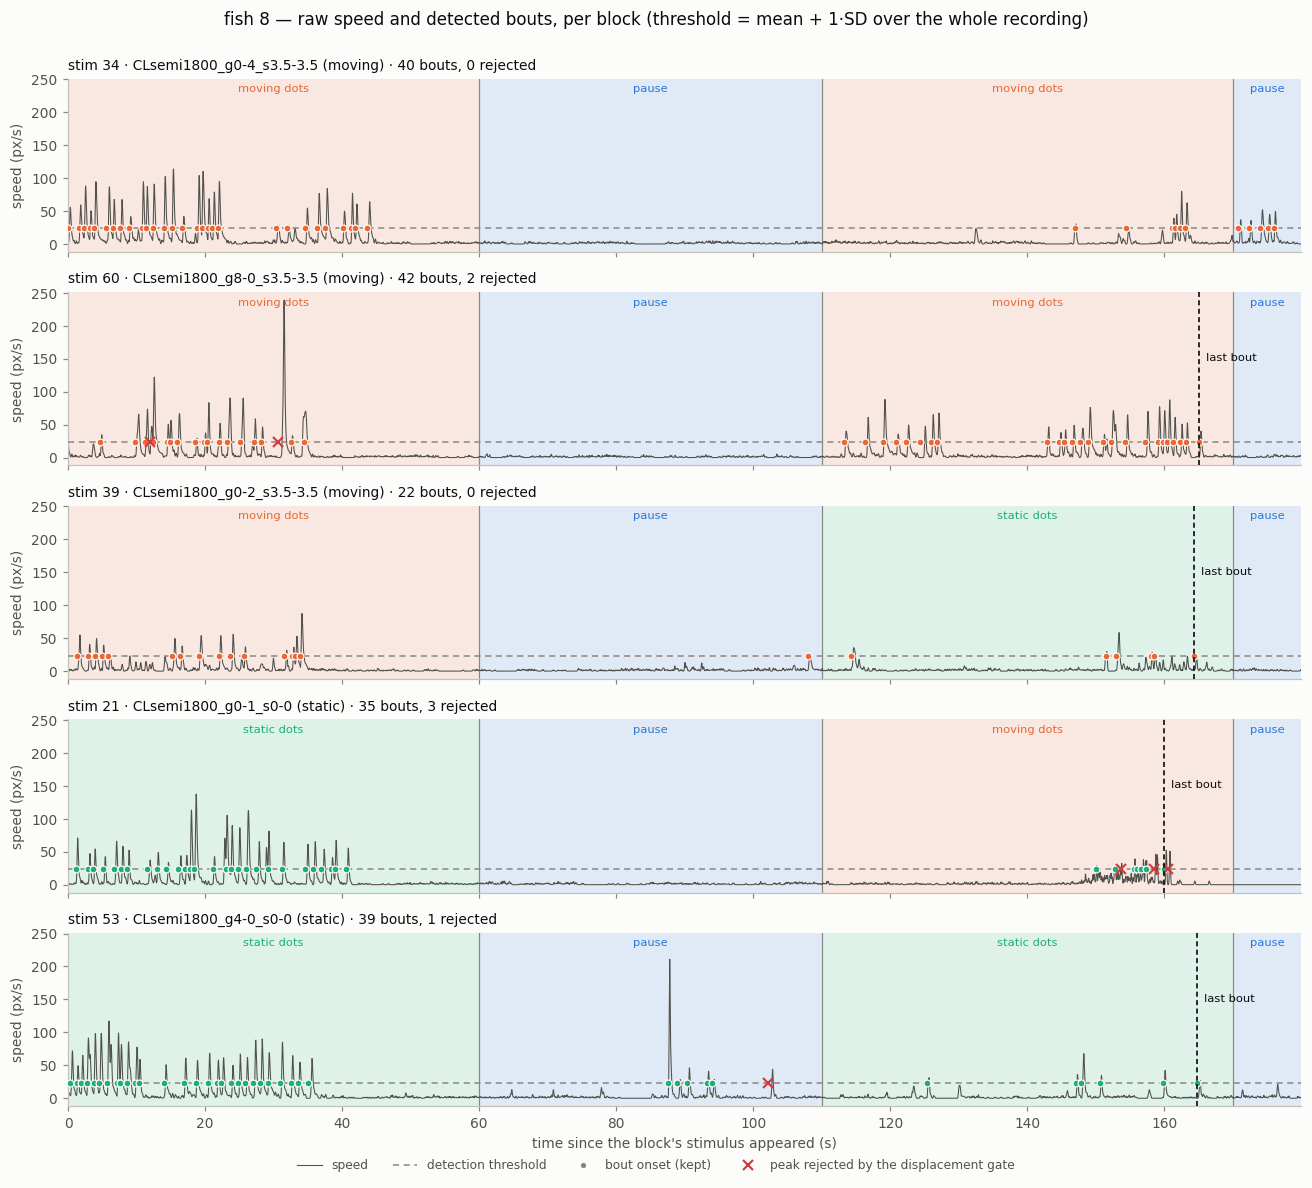

In [20]:
fish8 = pick_blocks(df, 8, "moving", n=3, min_bouts=12, last_before=45) \
      + pick_blocks(df, 8, "static", n=2, min_bouts=12, last_before=45)
print(fish8)
plot_bout_trace(8, fish8, extend_s=120)
plt.show()

And the other §9 shape — blocks where the fish stops **in the middle** and then starts
again. `pick_pause_blocks` takes the blocks with the longest internal pause that still has
at least 3 bouts after it, so the restart is actually on screen. A short extension here,
just enough to show what the fish does once this block ends.

['stim 23', 'stim 50', 'stim 7']


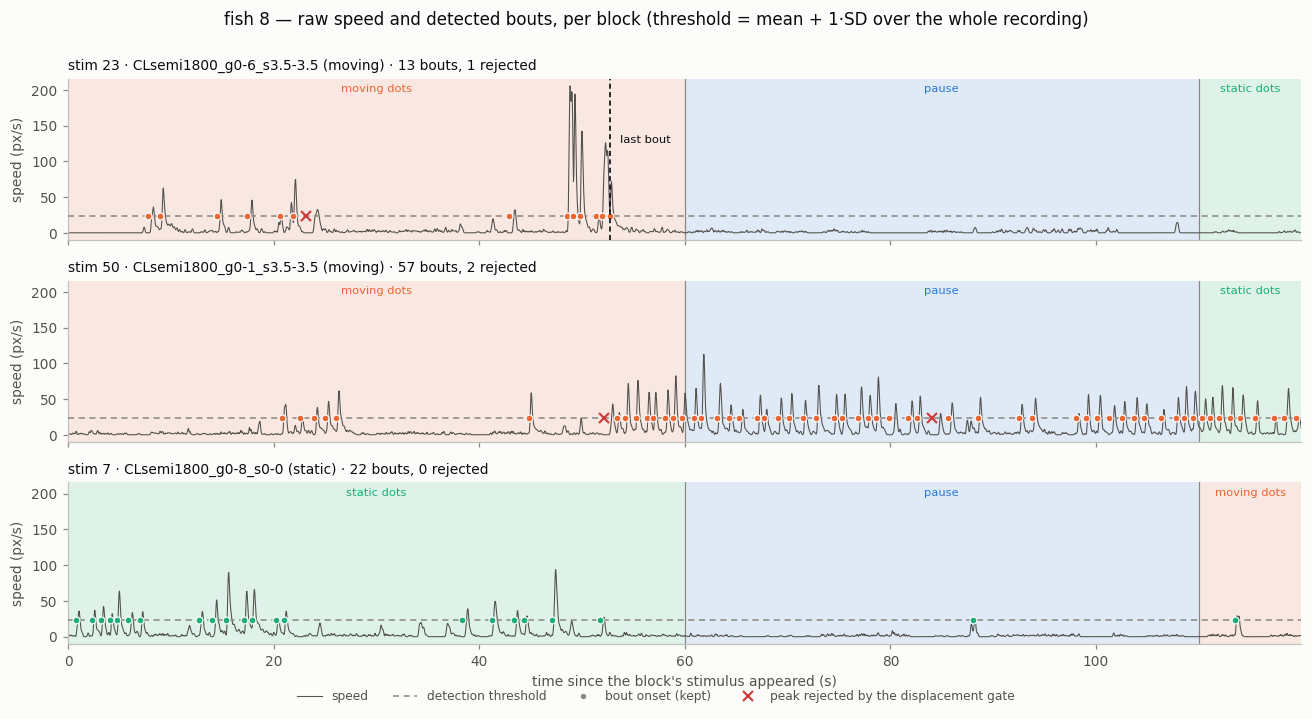

In [21]:
fish8_mid = pick_pause_blocks(df, 8, n=3, min_bouts=12, min_pause=10, min_after=3)
print(fish8_mid)
plot_bout_trace(8, fish8_mid, extend_s=60)
plt.show()

### 8 · Who else stops, and when

Fish 6 is not a special case, so this sweeps **every fish and every block** for stretches
longer than 10 s with no bout. A gap is simply a bout whose `dt_s` exceeds the threshold
— the same column the rest of the notebook uses, so this cannot disagree with it. Gaps are
not cut at block boundaries: a fish that stops mid-block and resumes two blocks later is
one gap, reported against the block it **started** in, since that is the block whose curve
it damages.

The raster is the answer to "which fish, and when": one row per fish, worst at the top,
one bar per stretch drawn at its real place and width in session time.

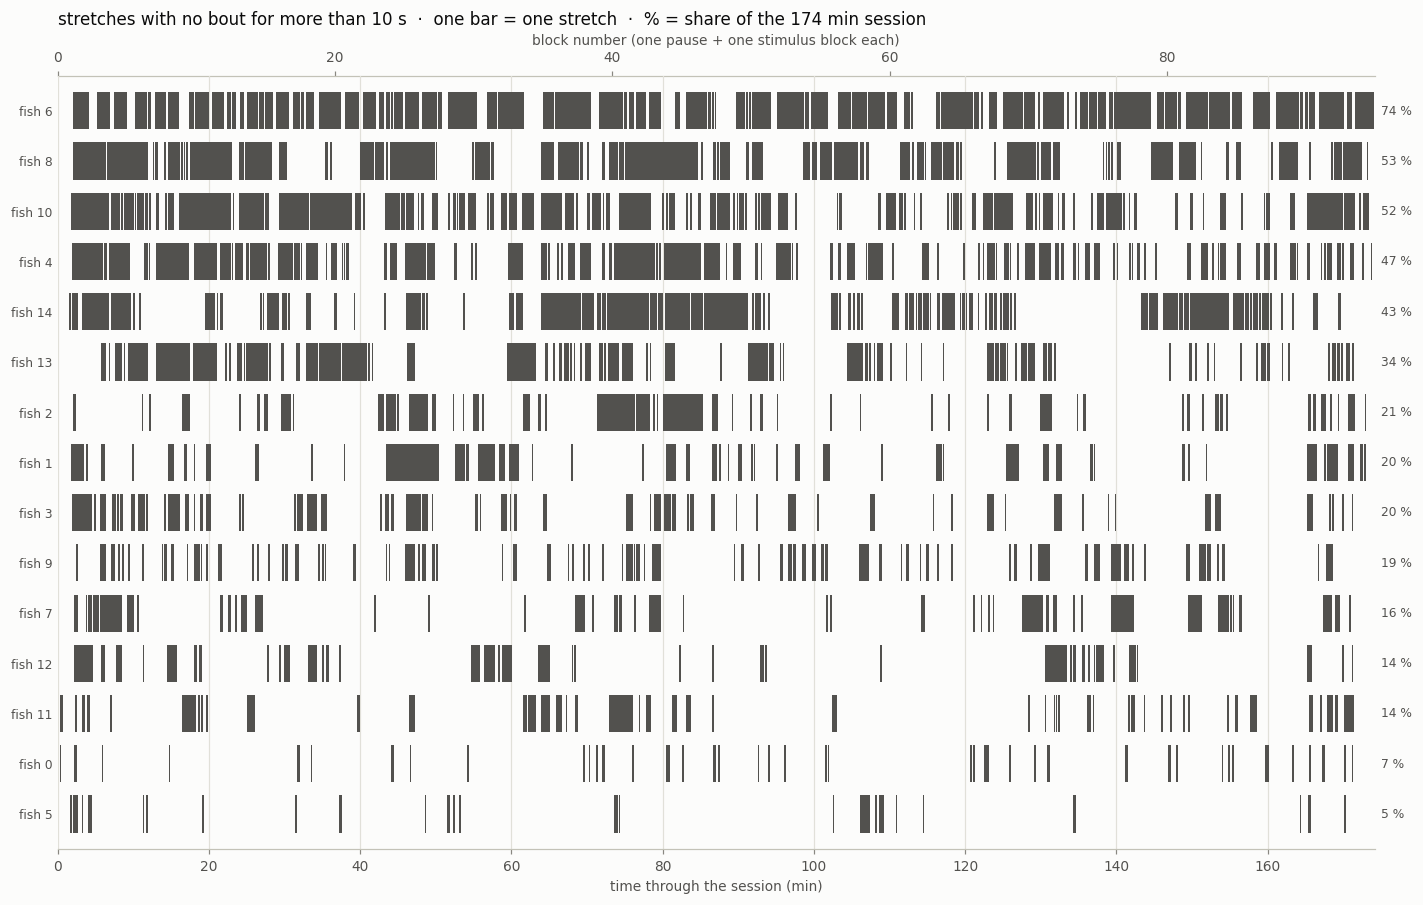

,bouts,n_gaps,quiet_min,pct_of_session,longest_s,longest_in
fish,,,,,,
6,3185,140,128.4,73.7,247.0,pause 36
8,3265,110,92.3,53.0,334.0,stim 9
10,3162,142,91.3,52.4,303.0,stim 0
4,3292,142,81.8,46.9,250.0,pause 7
14,4748,135,74.7,42.9,320.0,stim 34
13,3892,98,59.6,34.2,234.0,pause 32
2,5639,62,36.7,21.1,226.0,stim 43
1,5366,58,35.3,20.2,426.0,stim 23
3,4850,69,34.3,19.7,108.0,stim 1


In [22]:
# Every no-bout stretch > 10 s, all fish, all blocks
plot_quiescence(df, min_s=10)
plt.show()
quiescence_summary(df, min_s=10)

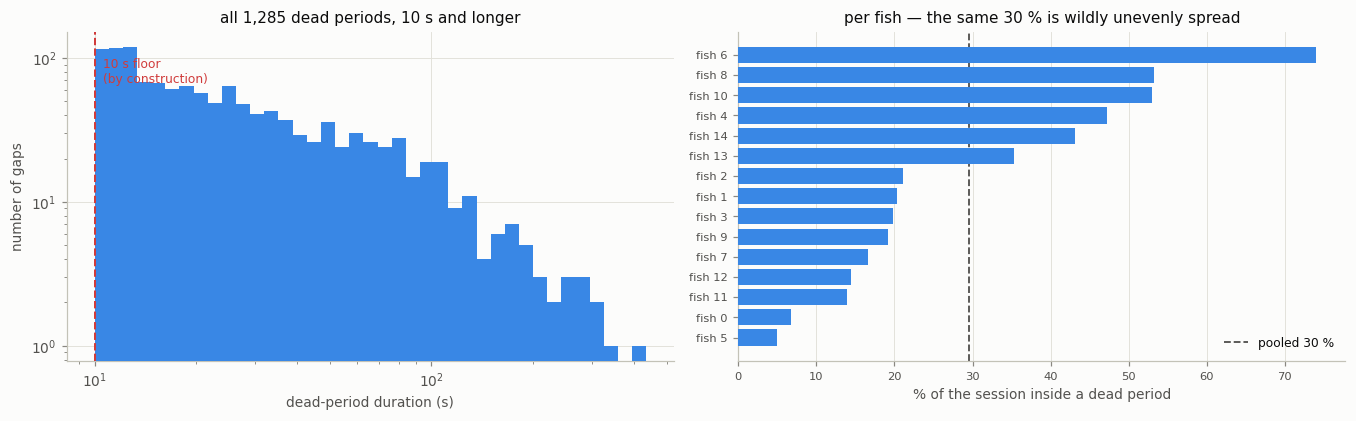

1,285 dead periods over 10 s, carrying 29.5 % of the recorded time
  duration  p25 13.1 s   median 20.7 s   p75 40.5 s   p90 78.8 s   p99 210 s   max 426 s
  over 60 s (a whole stimulus block): 202 (16 %)   over 120 s: 53

  per fish, share of session: 5 % (fish 5) to 74 % (fish 6)
  The median gap is short, but the TIME is carried by the long tail -- which is why
  1.8 % of rows hold 30 % of the clock, and why one log-normal dt head cannot do both.


In [23]:
# Duration of every dead period. The 10 s floor is the DEFINITION, not a finding --
# what the plot is for is the shape above it, which is what a dt head would have to
# reproduce if the gaps were modelled rather than masked.
g = quiet_gaps(df, min_s=QUIET_S)
dur = g["gap_s"].to_numpy(float)

fig, ax = plt.subplots(1, 2, figsize=(12.4, 3.9))

edges = np.logspace(np.log10(QUIET_S), np.log10(dur.max() * 1.02), 40)
ax[0].hist(dur, bins=edges, color=SEQ[3], zorder=3)
ax[0].axvline(QUIET_S, color="#d03b3b", ls="--", lw=1.3, zorder=4)
ax[0].text(QUIET_S * 1.06, ax[0].get_ylim()[1] * .8, "10 s floor\n(by construction)",
           color="#d03b3b", fontsize=8, va="top")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("dead-period duration (s)")
ax[0].set_ylabel("number of gaps")
ax[0].set_title(f"all {len(dur):,} dead periods, {QUIET_S:g} s and longer")

# one bar per fish: the share of that fish's session spent inside a dead period
tot = df.groupby("fish_id")["dt_s"].sum()
qt = g.groupby("fish_id")["gap_s"].sum().reindex(tot.index).fillna(0.0)
share = (100 * qt / tot).sort_values()
ax[1].barh([f"fish {f}" for f in share.index], share.to_numpy(), color=SEQ[3], zorder=3)
ax[1].axvline(float(100 * qt.sum() / tot.sum()), color=INK2, lw=1.2, ls="--",
              label=f"pooled {100*qt.sum()/tot.sum():.0f} %")
ax[1].set_xlabel("% of the session inside a dead period")
ax[1].set_title("per fish — the same 30 % is wildly unevenly spread")
ax[1].legend(fontsize=8, frameon=False)
ax[1].tick_params(labelsize=7.5)
for a_ in ax:
    a_.grid(axis="both" if a_ is ax[0] else "x", color=GRID, lw=.6, zorder=0)
    a_.set_axisbelow(True)
fig.tight_layout(); plt.show()

q = np.percentile(dur, [25, 50, 75, 90, 99])
print(f"{len(dur):,} dead periods over {QUIET_S:g} s, "
      f"carrying {100*dur.sum()/df['dt_s'].sum():.1f} % of the recorded time")
print(f"  duration  p25 {q[0]:.1f} s   median {q[1]:.1f} s   p75 {q[2]:.1f} s   "
      f"p90 {q[3]:.1f} s   p99 {q[4]:.0f} s   max {dur.max():.0f} s")
print(f"  over 60 s (a whole stimulus block): {int((dur > 60).sum()):,} "
      f"({100*(dur > 60).mean():.0f} %)   over 120 s: {int((dur > 120).sum()):,}")
print(f"\n  per fish, share of session: {share.min():.0f} % (fish {share.index[0]}) "
      f"to {share.max():.0f} % (fish {share.index[-1]})")
print("  The median gap is short, but the TIME is carried by the long tail -- which is why")
print("  1.8 % of rows hold 30 % of the clock, and why one log-normal dt head cannot do both.")

The same thing as one number per fish — the share of the session spent **active**, i.e. not
inside a no-bout stretch. It is the complement of the raster's right-hand column.

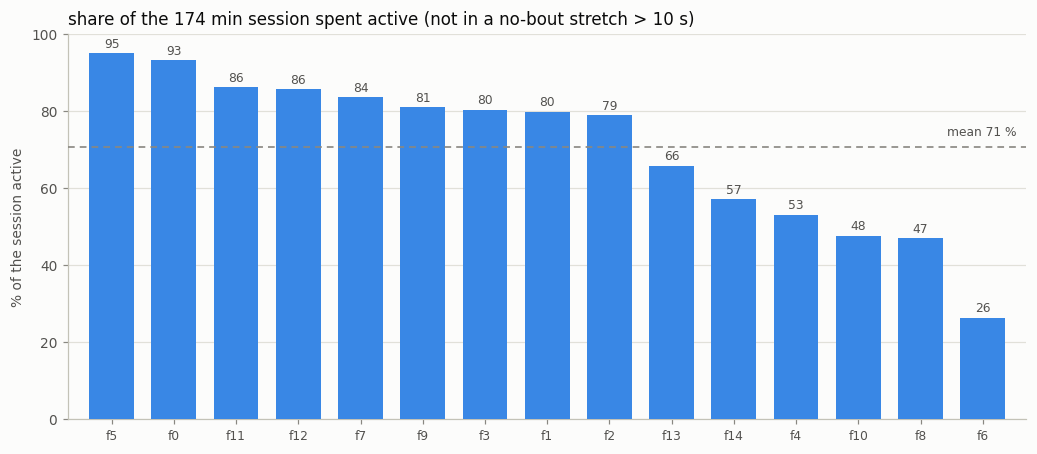

In [24]:
plot_active_share(df, thr=10)
plt.show()

#### What it costs to drop those blocks

Shows % of blocks and % of bouts lost per fish by removing all "dead" periods.

In [25]:
loss = block_loss(df, min_s=10, min_cover=0.0)
print(f"any overlap  : {loss.loc['ALL', 'all blocks']:.1f} % of blocks, "
      f"{loss.loc['ALL', 'bouts lost']:.1f} % of bouts")
print(f"> 50 % of the block: "
      f"{block_loss(df, min_s=10, min_cover=0.5).loc['ALL', 'all blocks']:.1f} % of blocks, "
      f"{block_loss(df, min_s=10, min_cover=0.5).loc['ALL', 'bouts lost']:.1f} % of bouts")
loss

any overlap  : 51.3 % of blocks, 29.3 % of bouts
> 50 % of the block: 27.7 % of blocks, 6.4 % of bouts


,none,moving,static,all blocks,bouts lost
fish,,,,,
0,30.5,26.7,22.9,27.9,23.3
1,43.2,31.7,48.6,40.5,23.9
2,41.1,40.0,45.7,41.6,24.1
3,44.2,38.3,48.6,43.2,28.5
4,82.1,75.0,82.9,80.0,60.8
5,16.8,20.0,14.3,17.4,10.9
6,92.6,93.3,100.0,94.2,81.4
7,30.5,33.3,42.9,33.7,19.4
8,71.6,80.0,71.4,74.2,40.5


#### §6A again, with those blocks removed

kept 50,891 of 71,933 bouts (70.7 %)  ·  692 of 1,425 stimulus blocks (48.6 %)
surviving stimulus blocks per fish (of 60 moving / 35 static):
         moving  static  moving %  static %
fish_id                                    
0            44      27        73        77
1            41      18        68        51
2            36      19        60        54
3            37      18        62        51
4            15       6        25        17
5            48      30        80        86
6             4       0         7         0
7            40      20        67        57
8            12      10        20        29
9            37      10        62        29
10           12       3        20         9
11           42      21        70        60
12           40      29        67        83
13           25      13        42        37
14           20      15        33        43


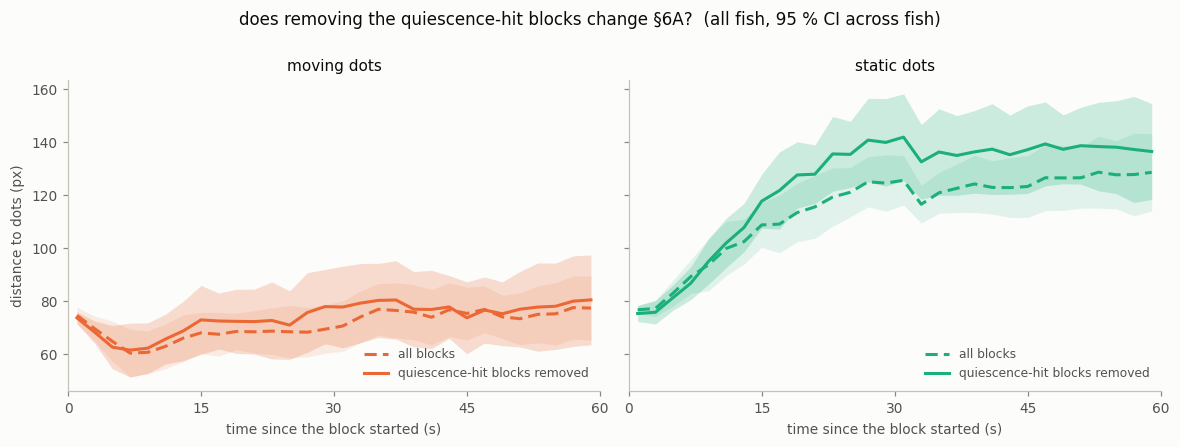

In [26]:
df_clean = drop_quiet_blocks(df, min_s=10, min_cover=0.0)
plot_approach_impact(df, df_clean, min_blocks_after=4)
plt.show()

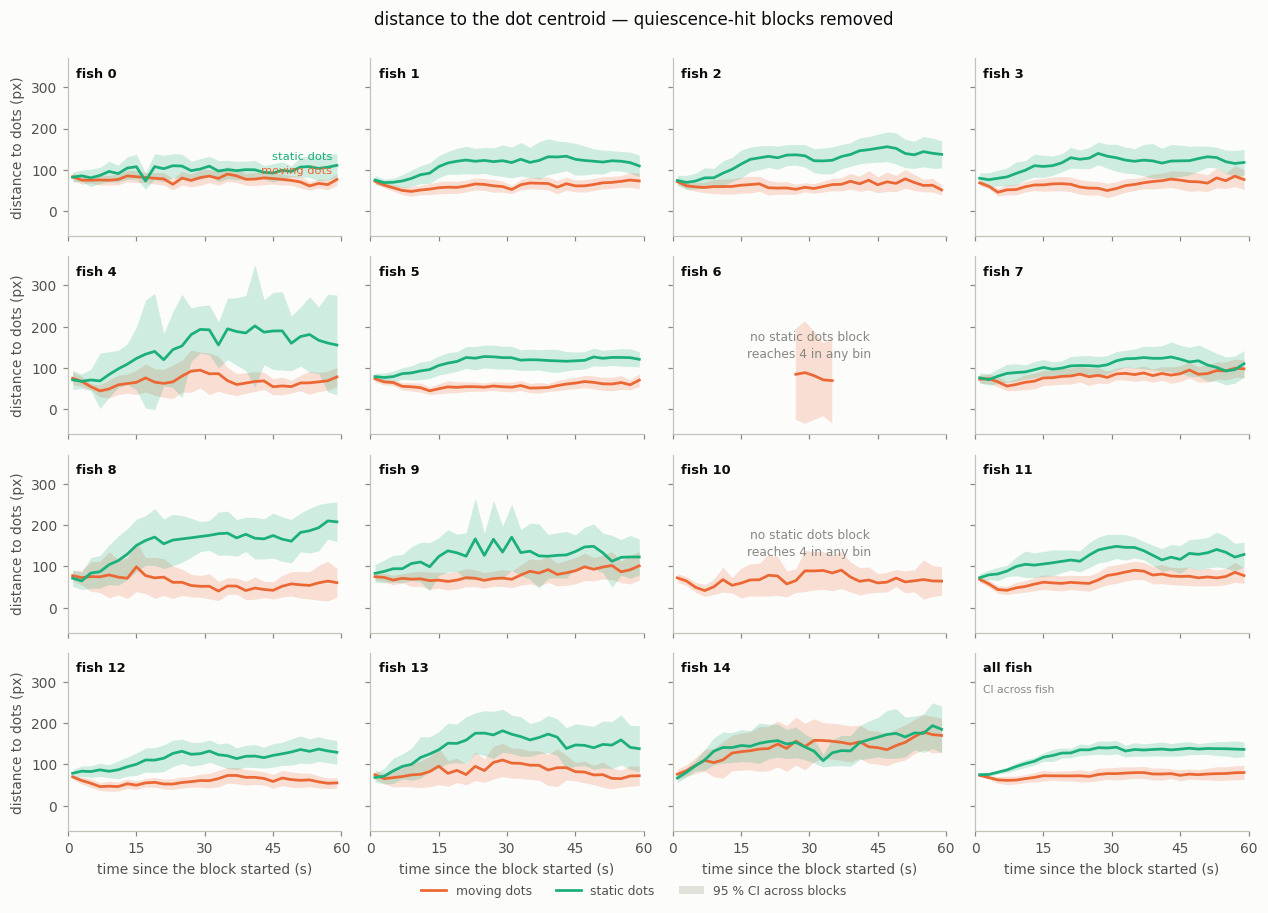

In [27]:
plot_approach(df_clean, min_blocks=4,
              title="distance to the dot centroid — quiescence-hit blocks removed")
plt.show()

And the individual worst stretches, with the block each one starts in and how far into
that block the fish went quiet.

In [28]:
worst_gaps(df, n=15, min_s=10)

,fish_id,block,cond,into_block_s,start_min,gap_s,stimulus
0,1,stim 23,moving,20.9,43.347778,426.5,CLsemi1800_g0-6_s3.5-3.5
1,8,stim 9,moving,10.6,17.510000,334.5,CLsemi1800_g0-1_s3.5-3.5
2,14,stim 34,moving,44.1,63.901667,319.5,CLsemi1800_g0-4_s3.5-3.5
3,10,stim 0,moving,53.3,1.722222,303.2,CLsemi1800_g4-0_s3.5-3.5
4,8,stim 40,static,54.3,75.071111,279.0,CLsemi1800_g0-4_s0-0
5,14,stim 46,moving,21.2,85.520000,277.7,CLsemi1800_g6-0_s3.5-3.5
6,10,pause 90,none,15.9,165.265556,269.7,inter_stim_pause
7,8,stim 23,moving,52.7,43.878333,256.6,CLsemi1800_g0-6_s3.5-3.5
8,4,pause 7,none,21.6,13.192778,249.7,inter_stim_pause
9,6,pause 36,none,26.4,66.439444,247.3,inter_stim_pause


### 8bis · Is `QUIET_S = 10` the right cut?

Cell above calls the 10 s floor "the DEFINITION, not a finding", which is exactly right —
and it is also the reason this subsection exists. Everything above looks at the gaps
*given* the floor; nothing so far asks whether the floor belongs where it is.

The threshold does more work than it looks like it does: it defines `active`, and
through `gap_before` it defines the **runs**, which are the sequence unit every
autoregressive model in this project is trained on. It deserves a justification
rather than a default.

Two separate questions, and they have different answers:

* **(A) Is there a trough?** If the interbout interval is bimodal — ordinary bouts in
  one mode, quiescence in another — then a cut placed in the dip is principled, and
  the dip tells you where to put it. If instead it is a single smooth heavy tail,
  then *no* cut is principled and the honest thing is to call 10 s a convention.
* **(B) Does anything move?** Independent of (A): if the quantities that matter are
  flat across a wide band of thresholds, the choice is harmless either way. This is
  the question an examiner will actually ask, and it is the one worth answering in
  the write-up.

`plot_dt_spectrum` answers (A), `threshold_sweep` answers (B).

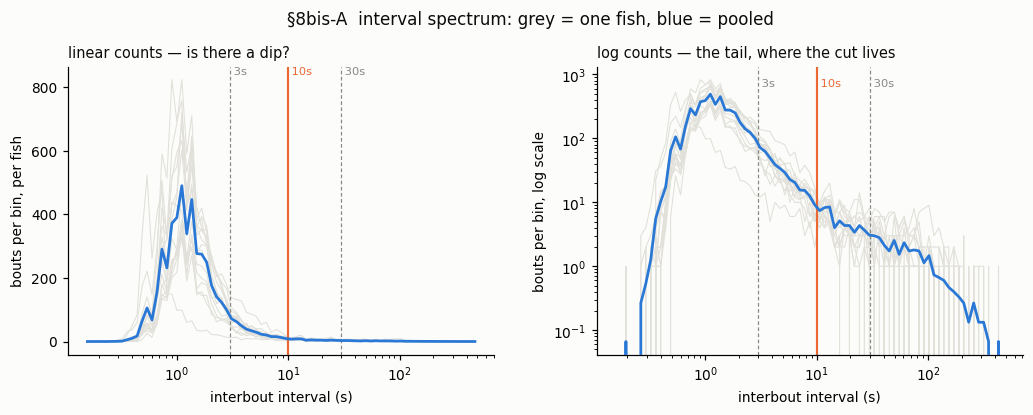

local minima in the smoothed log-interval density above 1 s:
  none — the tail is monotone, so no threshold is picked out by the data


In [52]:
# --------------------------------------------------------------------------- #
#  §8bis-A -- the interval spectrum. Counts in log-spaced bins, so what you see
#  on a log axis is the density in log-interval space (the scale a threshold
#  like this is actually chosen on). Raw counts, not `density=True`: with
#  unequal bin widths the normalised version rescales the tail and hides the
#  thing we are looking for.
# --------------------------------------------------------------------------- #
CANDIDATES = [2, 3, 5, 7.5, 10, 15, 20, 30, 60]


def plot_dt_spectrum(d, thr=QUIET_S, cands=(3, 10, 30), title=None):
    """Interbout interval on a log axis. Is there a dip to put a threshold in?"""
    dt = d["dt_s"].to_numpy(float)
    dt = dt[np.isfinite(dt) & (dt > 0)]
    edges = np.logspace(np.log10(0.15), np.log10(max(dt.max(), 500)), 80)
    ctr = np.sqrt(edges[1:] * edges[:-1])

    fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.4), gridspec_kw={"wspace": .24})
    for ax, logy in zip(axes, (False, True)):
        for _, g in d.groupby("fish_id"):
            v = g["dt_s"].to_numpy(float)
            v = v[np.isfinite(v) & (v > 0)]
            h, _ = np.histogram(v, bins=edges)
            ax.plot(ctr, h, color=GRID, lw=.7, zorder=1)
        h, _ = np.histogram(dt, bins=edges)
        ax.plot(ctr, h / d["fish_id"].nunique(), color=BLUE, lw=1.8, zorder=3)
        for c in cands:
            ax.axvline(c, color=ORANGE if c == thr else MUTED,
                       lw=1.4 if c == thr else .8,
                       ls="-" if c == thr else (0, (3, 2)), zorder=2)
            ax.text(c, ax.get_ylim()[1], f" {c:g}s", fontsize=7.5, va="top",
                    color=ORANGE if c == thr else MUTED)
        ax.set_xscale("log")
        if logy:
            ax.set_yscale("log")
        ax.set_xlabel("interbout interval (s)")
        ax.set_ylabel("bouts per bin" + (", log scale" if logy else ", per fish"))
    axes[0].set_title("linear counts — is there a dip?", fontsize=9.5,
                      color=INK, loc="left")
    axes[1].set_title("log counts — the tail, where the cut lives", fontsize=9.5,
                      color=INK, loc="left")
    fig.suptitle(title or "§8bis-A  interval spectrum: grey = one fish, blue = pooled",
                 y=1.03, fontsize=11, color=INK)
    plt.show()

    # the numeric version of "is there a trough": smoothed log-space counts
    lo = np.log10(dt)
    h, e = np.histogram(lo, bins=60)
    k = np.r_[1, 2, 3, 2, 1] / 9.0
    s = np.convolve(h, k, mode="same")
    c = .5 * (e[1:] + e[:-1])
    interior = slice(2, len(s) - 2)
    dips = [(10 ** c[i], s[i]) for i in range(*interior.indices(len(s)))
            if s[i] < s[i - 1] and s[i] < s[i + 1] and 10 ** c[i] > 1.0]
    print("local minima in the smoothed log-interval density above 1 s:")
    print("  none — the tail is monotone, so no threshold is picked out by the data"
          if not dips else
          "\n".join(f"  {x:7.2f} s   (count {y:.0f})" for x, y in dips))


plot_dt_spectrum(df)

,gaps,pct_session,active,pct_kept,runs_all,runs_act,med_run,dt_med,dt_p99,transient_s
thr_s,,,,,,,,,,
2.0,14096,57.5,48378,67.25,14107,6873,3,1.100,1.97,0.300
3.0,6687,46.0,60149,83.62,6699,4173,6,1.167,2.87,0.300
5.0,3058,37.2,66412,92.32,3072,2137,11,1.200,4.30,0.300
7.5,1787,32.3,68679,95.48,1801,1317,16,1.200,5.70,0.300
10.0,1285,29.5,69567,96.71,1299,979,20,1.233,6.67,0.300
15.0,853,26.2,70353,97.80,867,669,29,1.233,8.07,0.267
20.0,657,24.0,70716,98.31,671,529,36,1.233,9.07,0.267
30.0,441,20.6,71100,98.84,455,380,41,1.233,10.77,0.200
60.0,204,14.2,71535,99.45,218,201,79,1.233,13.23,0.200


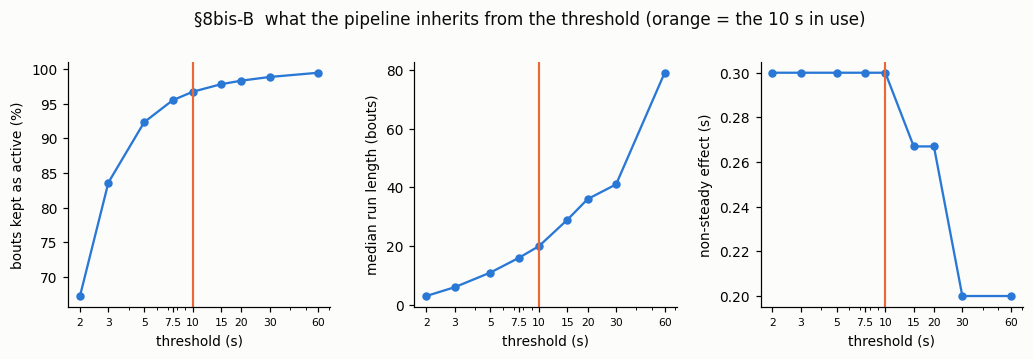

In [53]:
# --------------------------------------------------------------------------- #
#  §8bis-B -- sensitivity. Rebuild active / gap_before / run_id at each candidate
#  threshold, exactly as Data_cleanup_final does, and report what the modelling
#  pipeline would inherit. `transient_s` is the non-steady effect the run clock
#  exists to carry: median interval over the first 5 bouts of a run minus the
#  steady value, so it must stay clearly positive for the run clock to mean
#  anything.
# --------------------------------------------------------------------------- #
def threshold_sweep(d, cands=CANDIDATES, steady_pos=60):
    out = []
    for thr in cands:
        t = d.copy()
        t["gap_after"] = t.dt_s > thr
        t["gap_before"] = t.groupby("fish_id").gap_after.shift(1).fillna(False)
        t["active"] = ~(t.gap_after | t.gap_before)
        t["run_id"] = (t.gap_before | (t.fish_id != t.fish_id.shift())).cumsum()
        a = t[t.active].copy()
        a["pos"] = a.groupby("run_id").cumcount()
        early, late = a[a.pos < 5], a[a.pos >= steady_pos]
        out.append(dict(
            thr_s=thr,
            gaps=int(t.gap_after.sum()),
            pct_session=round(100 * t.loc[t.gap_after, "dt_s"].sum() / t.dt_s.sum(), 1),
            active=int(len(a)),
            pct_kept=round(100 * len(a) / len(t), 2),
            runs_all=int(t.run_id.nunique()),
            runs_act=int(a.run_id.nunique()),      # runs holding >=1 active bout
            med_run=int(a.groupby("run_id").size().median()),
            dt_med=round(float(a.dt_s.median()), 3),
            dt_p99=round(float(a.dt_s.quantile(.99)), 2),
            transient_s=(round(float(early.dt_s.median() - late.dt_s.median()), 3)
                         if len(late) > 20 else np.nan),
        ))
    return pd.DataFrame(out).set_index("thr_s")


sweep = threshold_sweep(df)
display(sweep)

fig, axes = plt.subplots(1, 3, figsize=(11.2, 2.9), gridspec_kw={"wspace": .32})
for ax, col, lab in ((axes[0], "pct_kept", "bouts kept as active (%)"),
                     (axes[1], "med_run", "median run length (bouts)"),
                     (axes[2], "transient_s", "non-steady effect (s)")):
    ax.plot(sweep.index, sweep[col], "o-", color=BLUE, lw=1.5, ms=4.5)
    ax.axvline(QUIET_S, color=ORANGE, lw=1.4)
    ax.set_xscale("log"); ax.set_xlabel("threshold (s)"); ax.set_ylabel(lab)
    ax.set_xticks(CANDIDATES); ax.set_xticklabels([f"{c:g}" for c in CANDIDATES],
                                                  fontsize=7)
fig.suptitle("§8bis-B  what the pipeline inherits from the threshold "
             "(orange = the 10 s in use)", y=1.04, fontsize=11, color=INK)
plt.show()

**How to read this.**

*(A)* If the printed list of local minima is empty, the interval distribution has no
dip above 1 s: it is one heavy tail, no threshold is picked out by the data, and the
write-up should say that 10 s is a convention chosen to sit well clear of ordinary
intervals (≈8× the 1.23 s median, above the 99th percentile of 6.7 s) rather than
claiming it was derived.

*(B)* The three curves are the argument that matters. If `pct_kept`, `med_run` and
`transient_s` all vary smoothly and none of them does anything special near 10 s,
then the choice is *harmless* — and that is a stronger and more honest statement
than pretending it was optimal. What would be a problem: `transient_s` collapsing
toward zero at 10 s (the run clock would be carrying nothing), or `med_run` moving
sharply (the sequence length every model sees would be an artefact of the cut).

Whichever way it comes out, one sentence and one number from this section belongs in
§3.2.3 of the report.

### 9 · The whole session - with "dead" periods highlighted

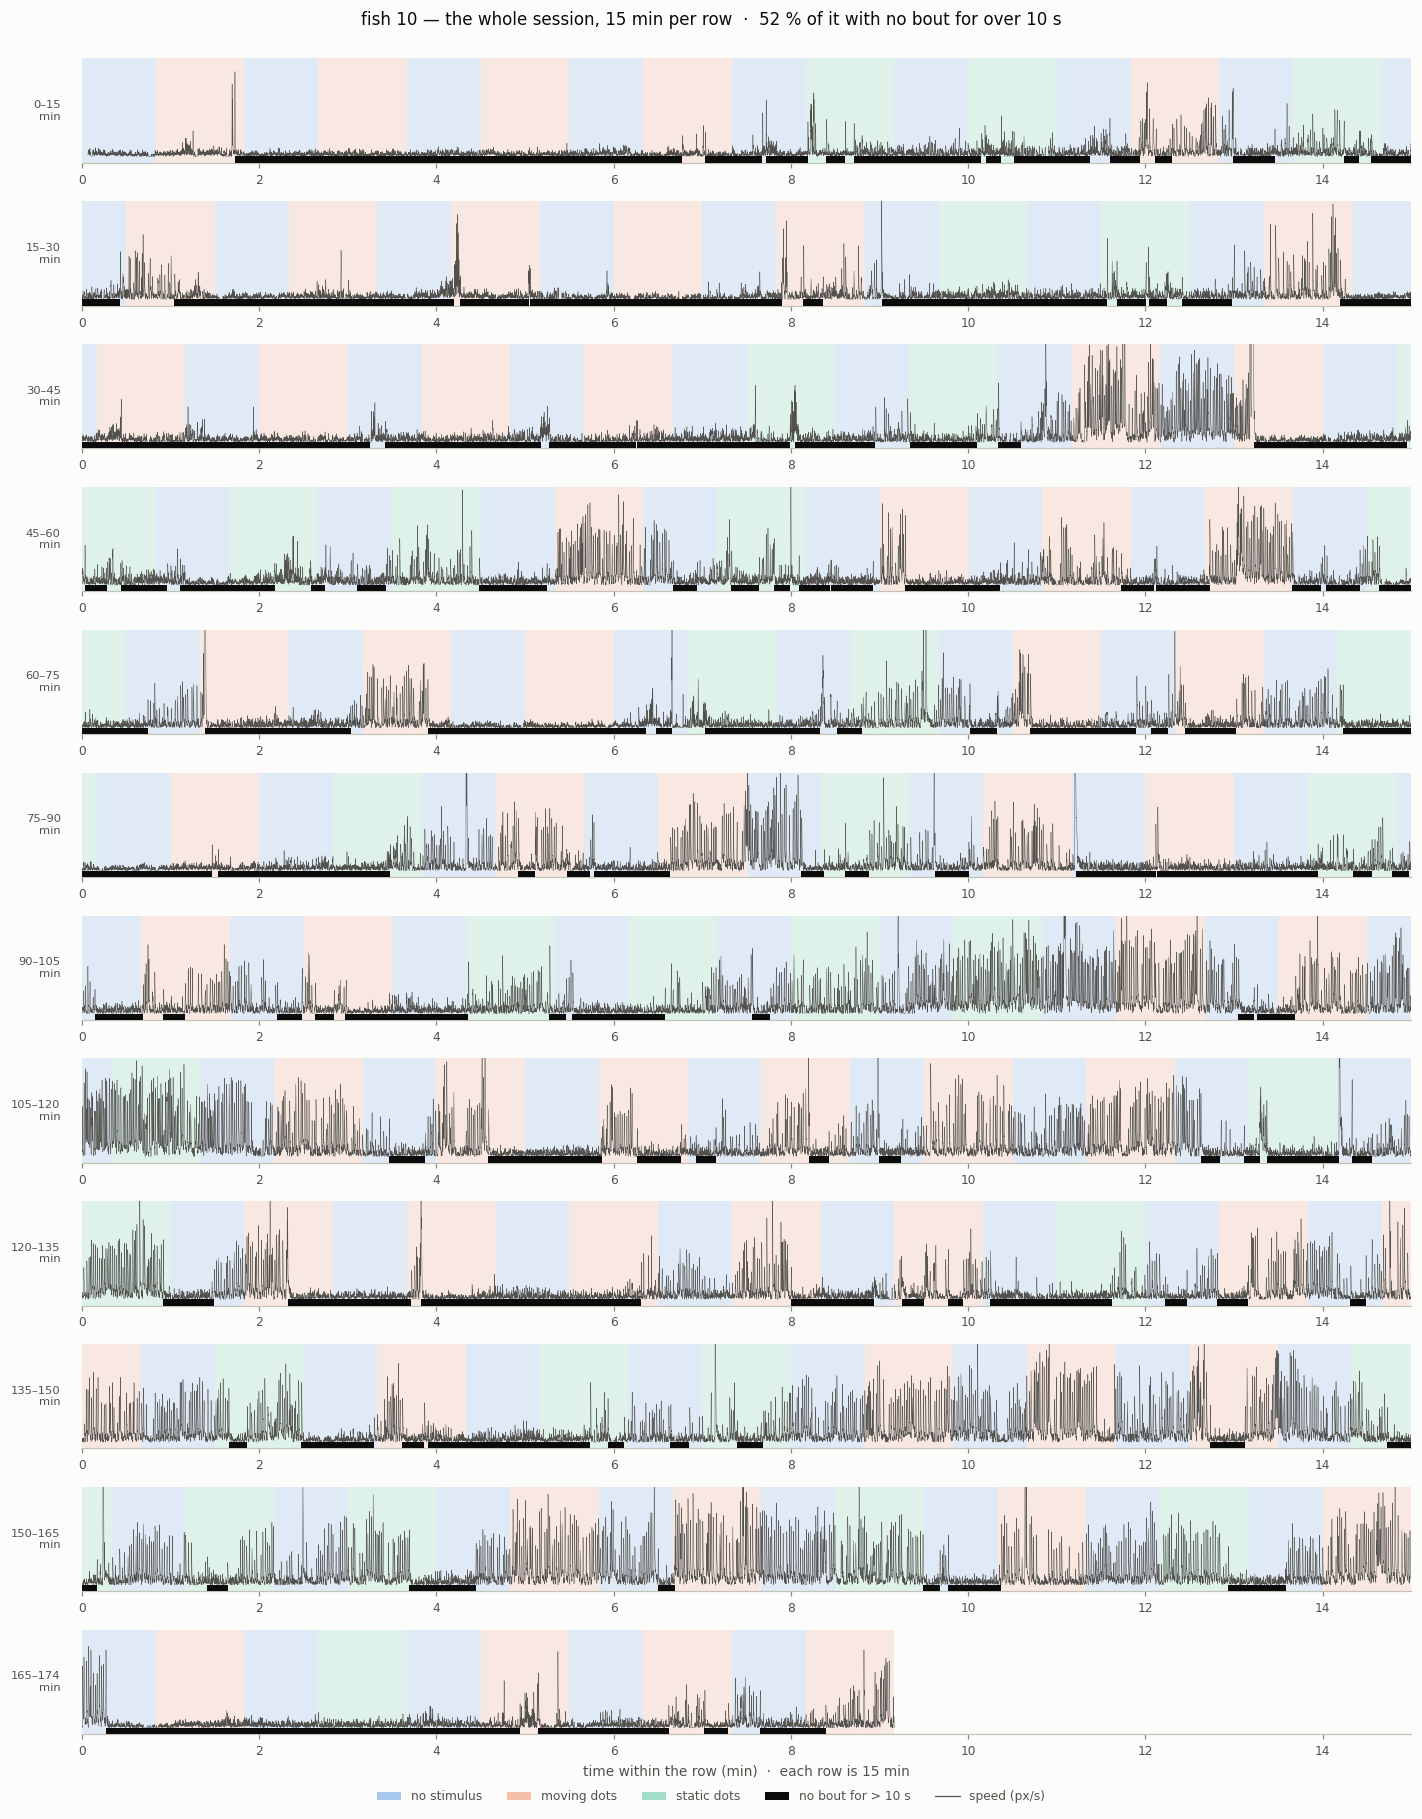

In [33]:
FISH_ID = 10            # 5 is the most active fish, 6 the least
plot_session(df, FISH_ID, row_min=15, thr=10)
plt.show()

### 10 · Where is the fish when it is dead, and where when it is active?

Heatmaps for both fish behaviours : active vs dead.

dead: 29.3 % of tracked frames on average, mean p99/R = 0.76


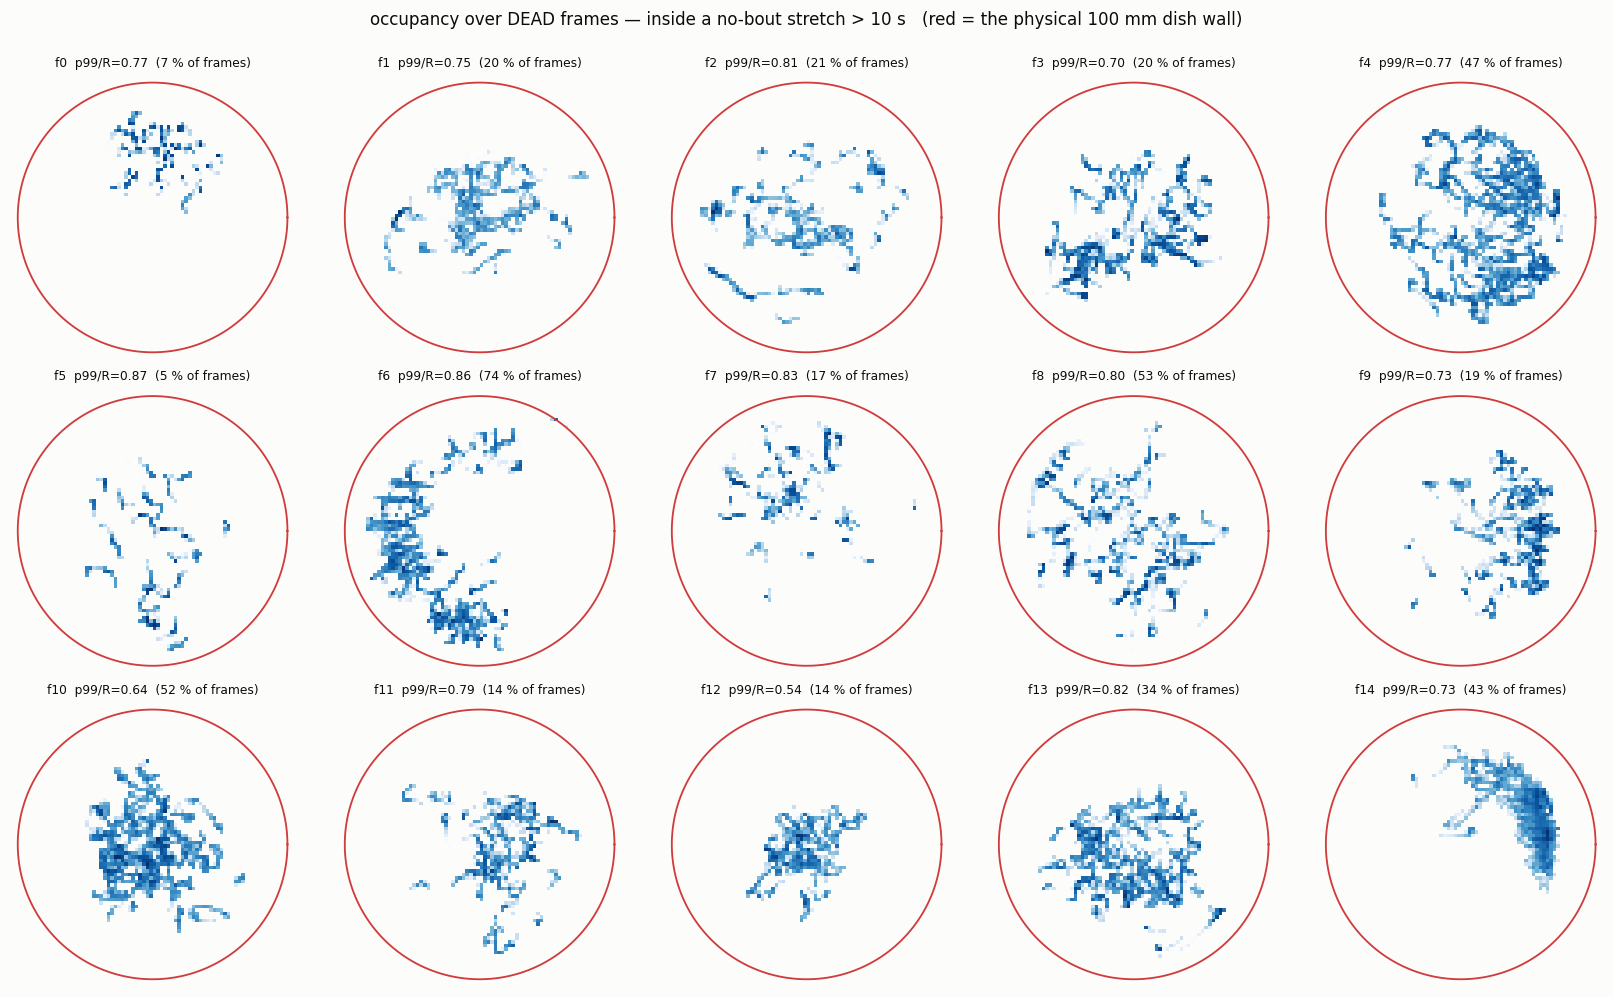

In [30]:
# Occupancy during DEAD periods — where a fish sits once it has stopped
plot_occupancy(df, which="dead", thr=10)
plt.show()

active: 70.1 % of tracked frames on average, mean p99/R = 0.83


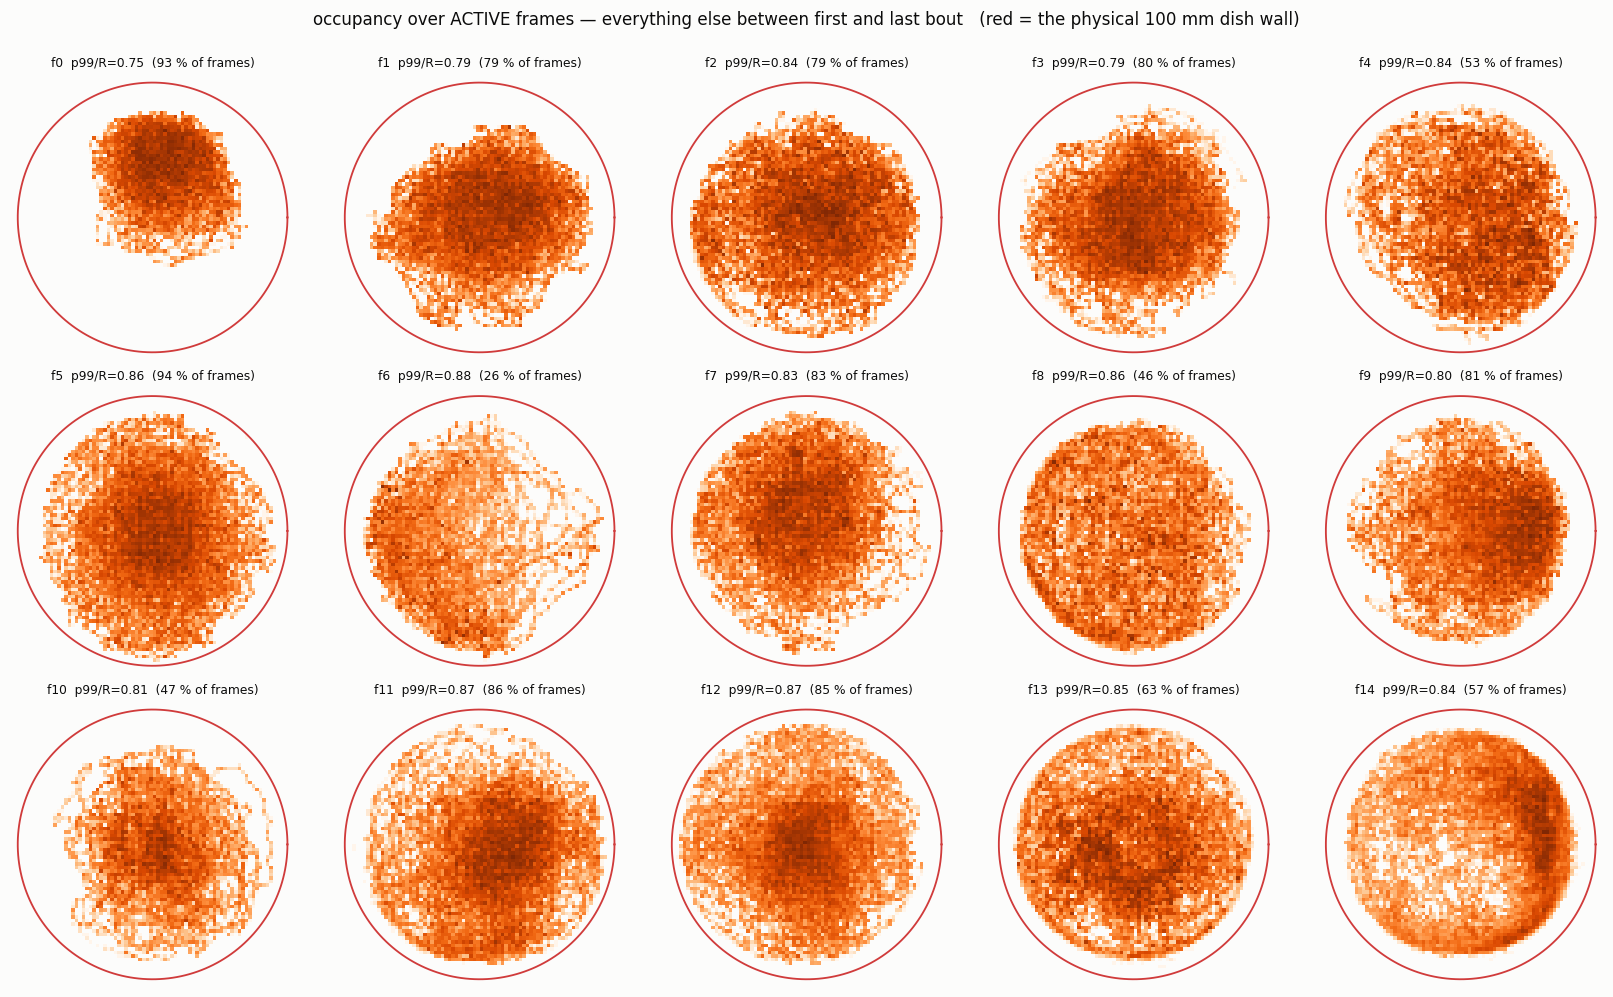

In [31]:
# Occupancy during ACTIVE periods — where it goes while it is swimming
plot_occupancy(df, which="active", thr=10)
plt.show()

### 11 · The `Δt` tail, per fish

KeyboardInterrupt: 

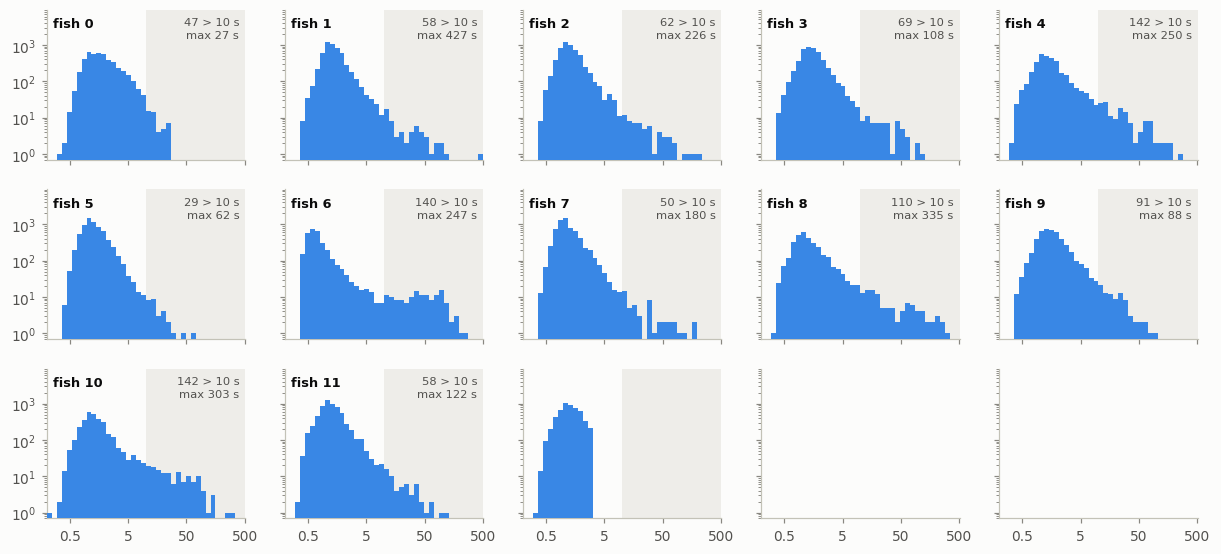

In [32]:
plot_dt_hist(df, thr=10)
plt.show()

Tails cut on active subset only - by construction max of 10s.

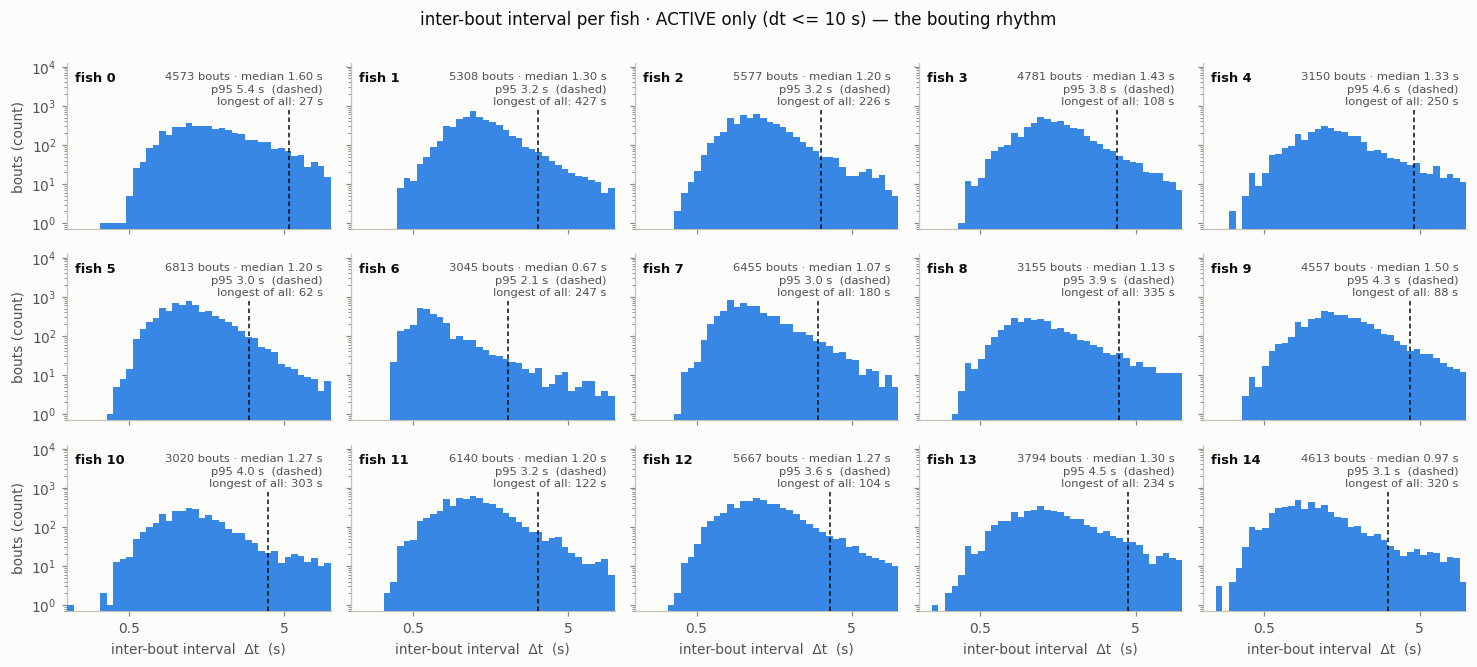

In [ ]:
plot_dt_hist(df, thr=10, subset="active")
plt.show()

Dead period only.

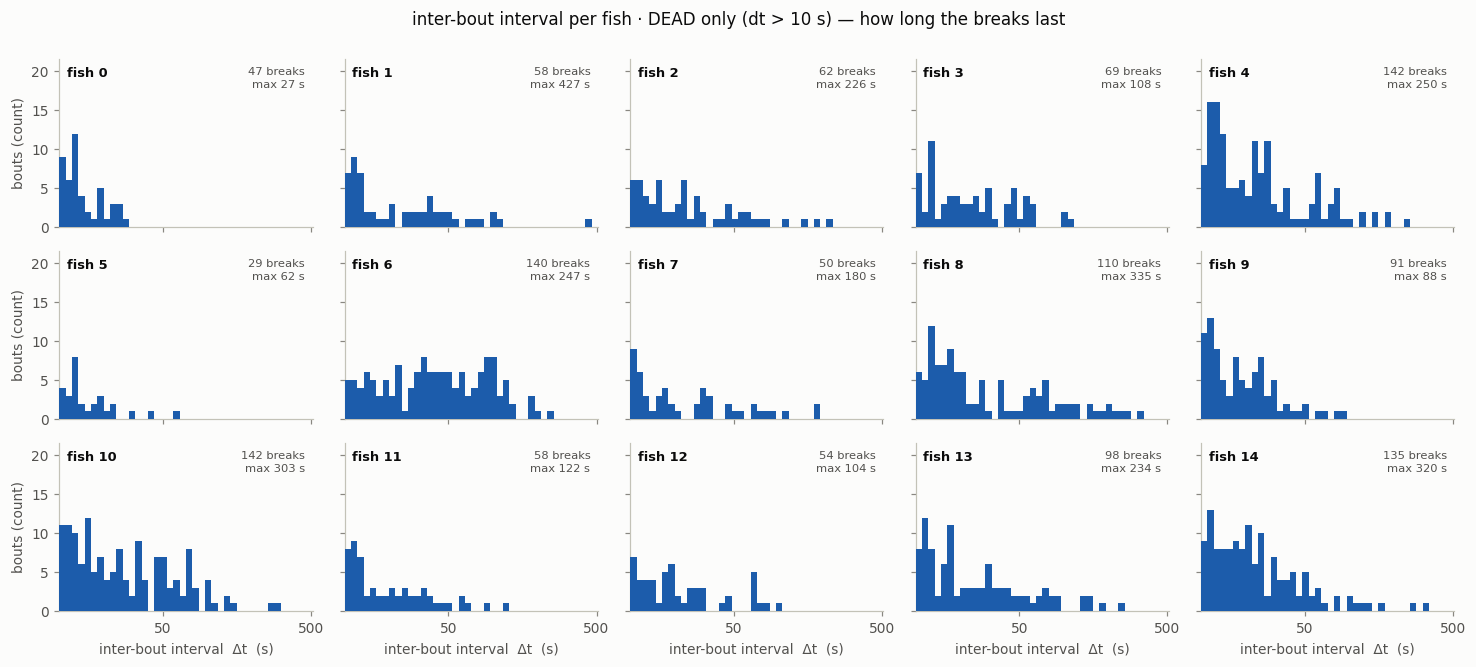

In [ ]:
plot_dt_hist(df, thr=10, subset="dead")
plt.show()

### 12 · The distance head, per fish

Each panel gives that fish's **max**. What decides is the implied speed, and any bout over **50 mm/s** (about the ceiling for a larval
zebrafish burst) is marked with a red ▾ and counted. There are exactly **two in the whole
dataset**, both fish 5.

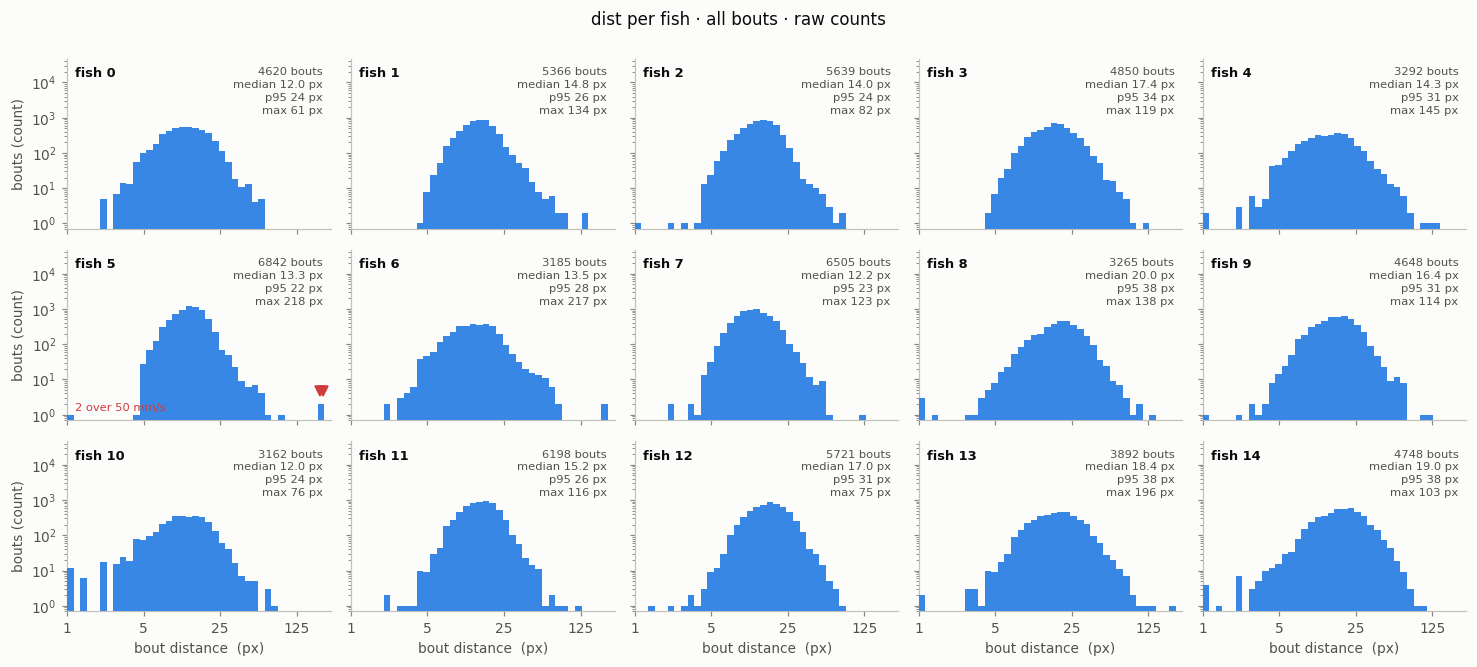

In [ ]:
plot_head_hist(df, "dist", subset="all", thr=10)
plt.show()

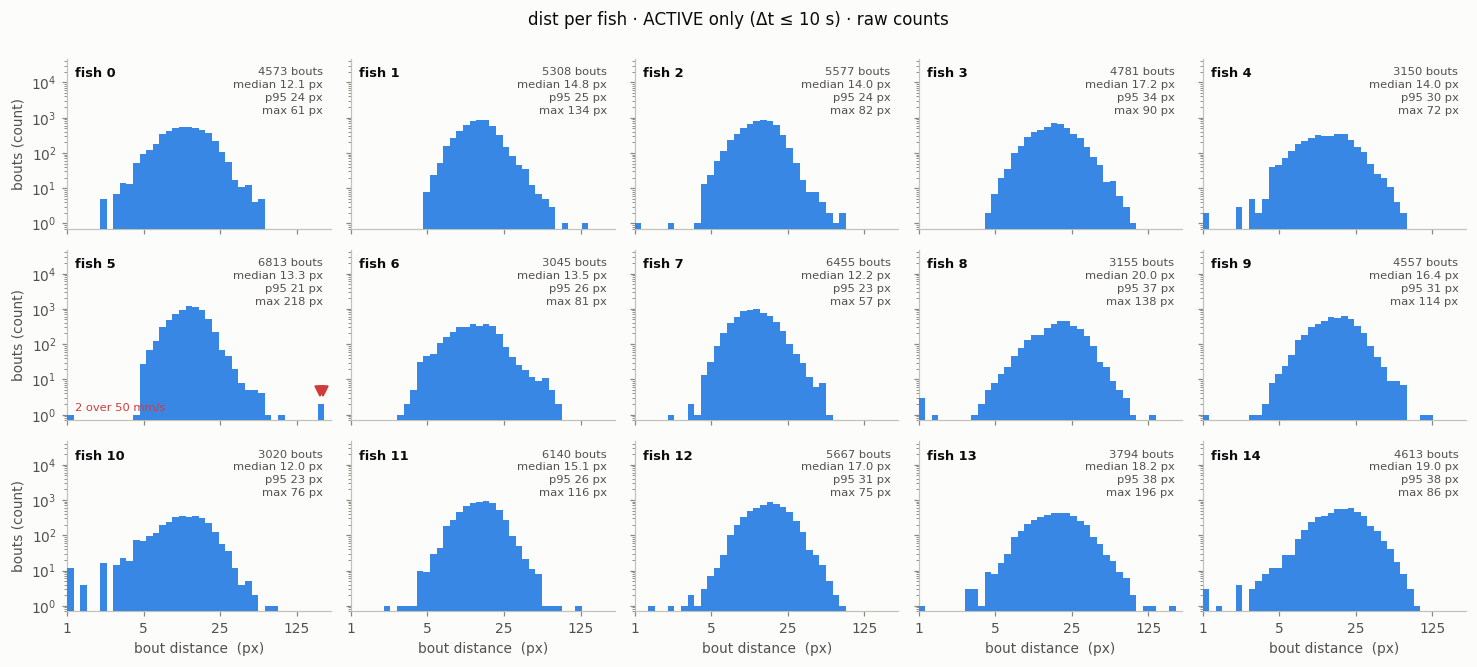

In [ ]:
plot_head_hist(df, "dist", subset="active", thr=10)
plt.show()

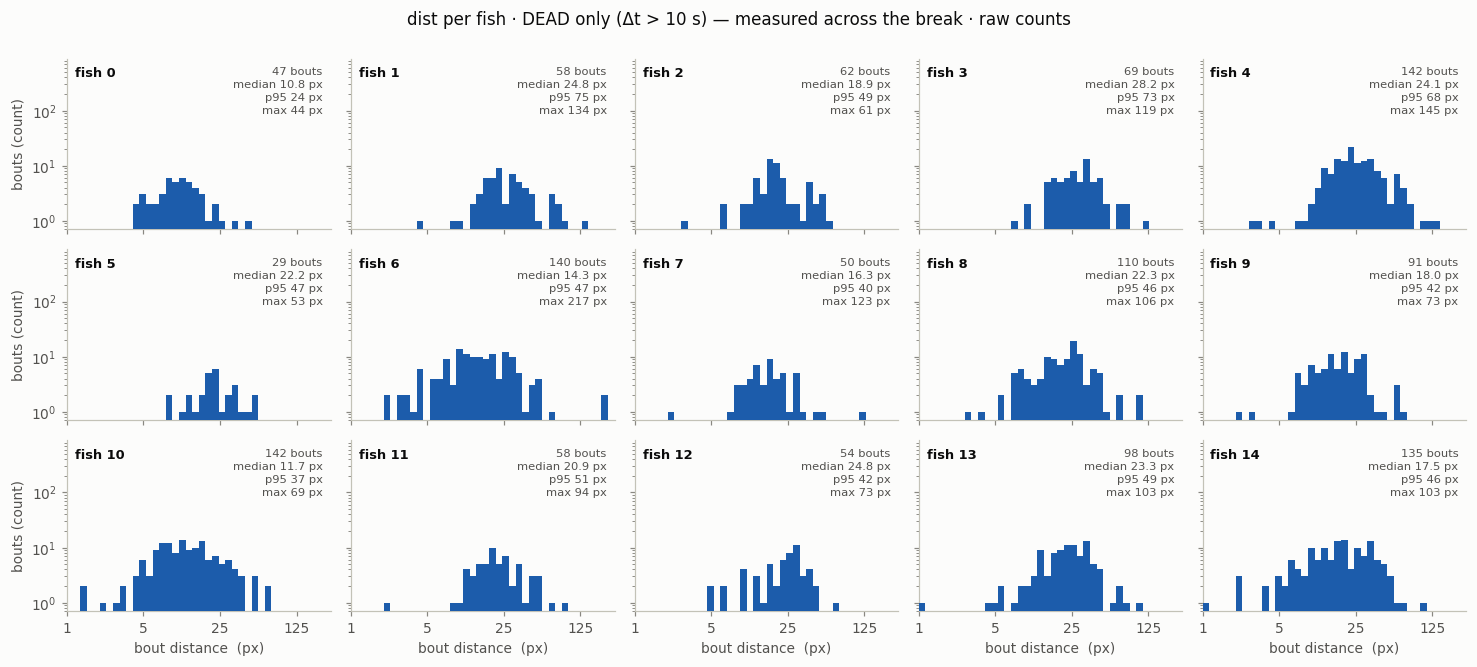

In [ ]:
plot_head_hist(df, "dist", subset="dead", thr=10)
plt.show()

#### Look at the two impossible ones

Both are fish 5, both in **`pause 32`**, back to back at t = 1.3 s and 2.1 s. Checking the
raw frames settles what they are — **a single bad frame**:

```
frame 105639   x=174  y=139     <- onset of the first bout
frame 105663   x=300  y=299     <- onset of the second; 217 px in ONE frame = 1814 mm/s
frame 105664   x=164  y=129     <- straight back, 218 px
```

The tracker loses the fish for exactly one frame, reports a position at the dish edge, and
recovers immediately. That one frame poisons **two** bout rows: the earlier bout's
`distance` because its next onset happens to land on the glitch, and the glitch frame's own
bout. The ~180° `Δθ` is the out-and-back.

**Why this one slipped past the displacement gate.** Most teleports are in fact caught, and
by the *lower* gate rather than the upper one: the fish returns to where it was, so net
displacement over the ±0.5 s window is ≈ 0 and the candidate is rejected as sub-threshold.
This pair got through because the glitch frame *became an onset itself*, so the distance is
measured onset-to-onset from a spurious position to a real one — a channel neither gate
inspects. Catching that needs a per-frame speed limit.

In [ ]:
# # The 8 s around the two physically impossible bouts (fish 5, pause 32, t = 1.3 and 2.1 s)
# make_block_video(5, ["pause 32"], ROOT / "mp4_fish_5_impossible.mp4",
#                  start_s=0, max_frames=8 * 30)

#### The same thing in other fish

Fish 5 is not special. The §13 check only catches a glitch that happens to land **on** a
bout onset — 2 rows in 70,590. Looking at the raw per-frame positions instead, where the
artefact actually lives, **every fish has them**: the largest single-frame step per fish
runs from 23 px (fish 7, 190 mm/s) to 226 px (fish 6, **1883 mm/s**), and each fish has
20–63 frames over 100 mm/s across the session.


In [ ]:
# jumps = worst_jumps(n=3, exclude=(5,))
# print(pd.DataFrame(jumps).to_string(index=False))

# for j in jumps:      # 8 s centred on each jump
#     make_block_video(j["fish"], [j["block"]], ROOT / f"mp4_jump_f{j['fish']}.mp4",
#                      start_s=max(0, j["t_s"] - 4), max_frames=8 * 30)

### 13 · The turn head, same three ways

Same three views for `Δθ`. Linear x — unlike `Δt` and distance this variable is bounded at
±180°, so there is no tail to go looking for; y is still log because the counts span
decades. The same caveat applies with more force: `dtheta` is the change in travel
direction between consecutive onsets, so on a dead row it is the net reorientation over
minutes and should look near-uniform.

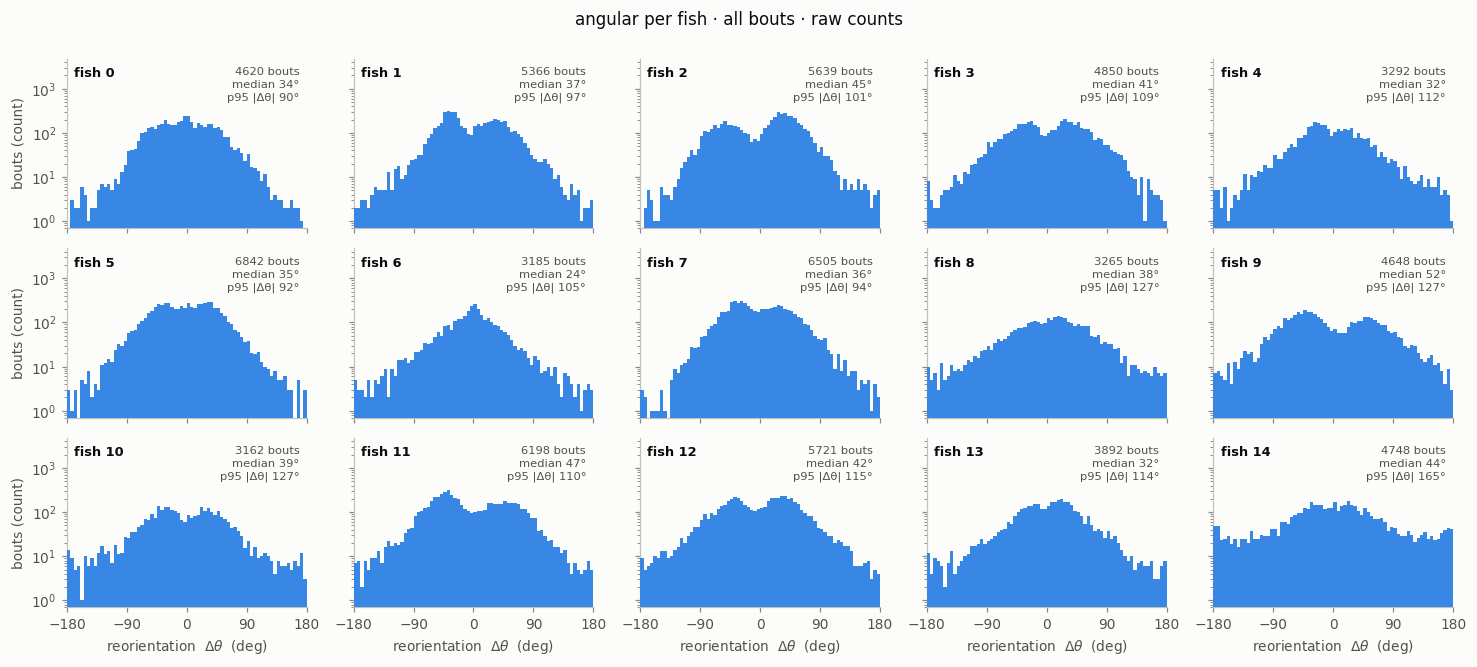

In [ ]:
plot_head_hist(df, "angular", subset="all", thr=10)
plt.show()

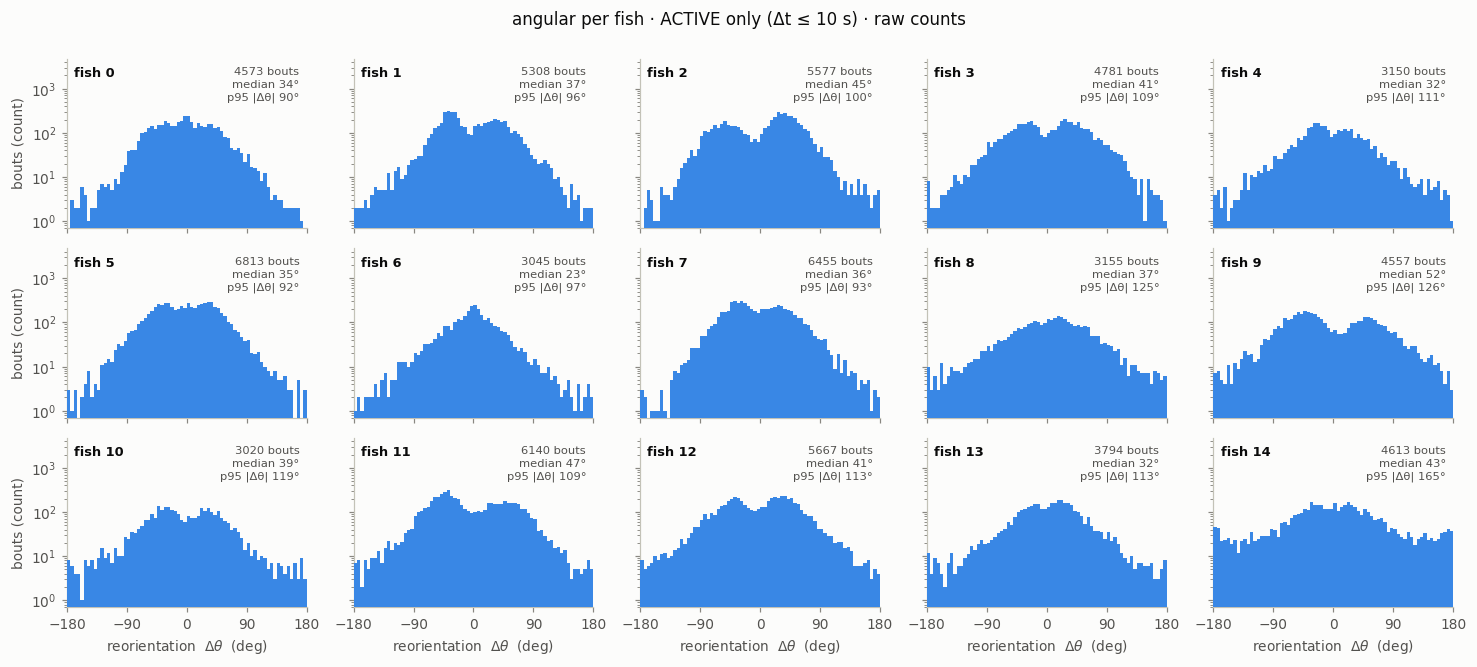

In [ ]:
plot_head_hist(df, "angular", subset="active", thr=10)
plt.show()

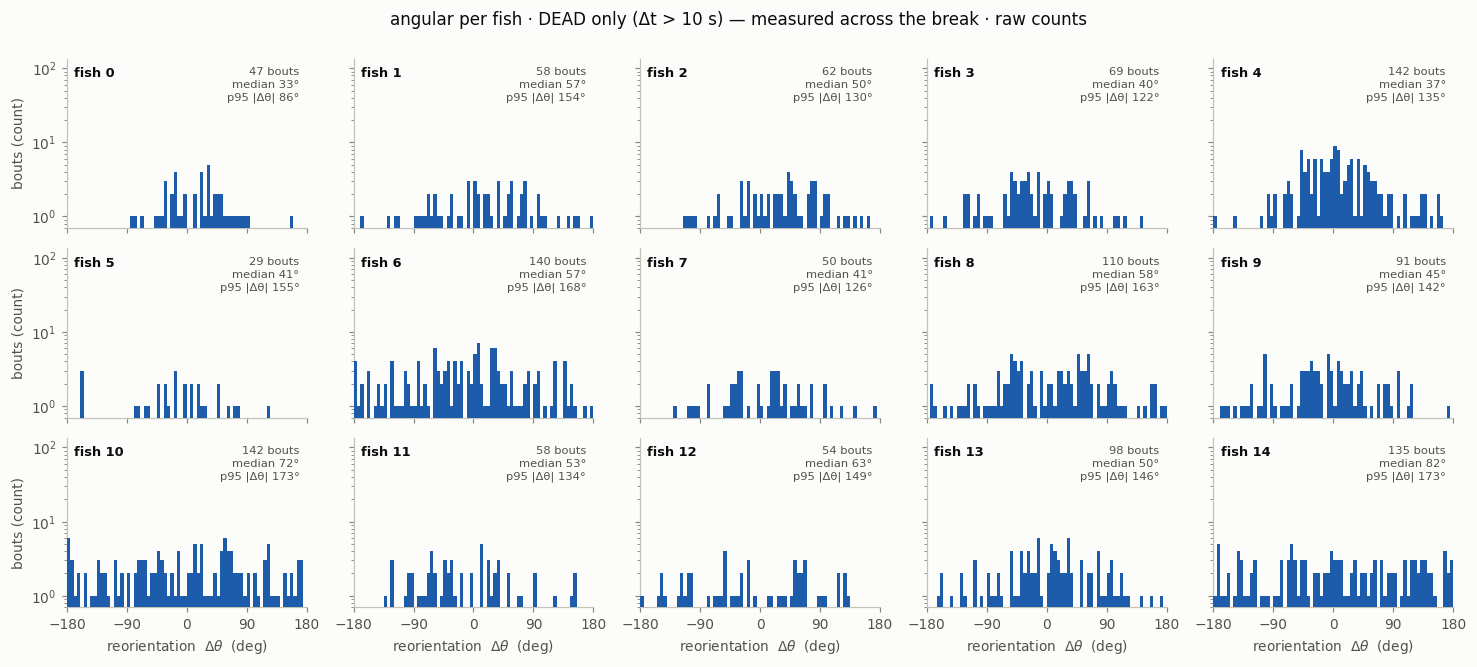

In [ ]:
plot_head_hist(df, "angular", subset="dead", thr=10)
plt.show()

#### Where do the ±180° turns happen?

In the outer dish. Using only bouts whose two legs
both stay under 10 s (so nothing is measured across a dead period):

| | \|Δθ\| > 150° | rest |
|---|---|---|
| median r/R | **0.764** | 0.435 |
| at r/R > 0.85 | **8.6 %** | 1.2 % |

So the effect is a strong, graded radial one — reversals concentrate in the outer half —
rather than contact with the boundary: only about a third are in the wall shell and under
a tenth are within 15 % of the radius of it. 

 fish   block  n  n_rev  r_rev  r_other  contrast                     stim
   12 stim 78 52      5   0.81     0.64     0.167 CLsemi1800_g6-0_s3.5-3.5
    7 stim 72 45      4   0.80     0.66     0.141 CLsemi1800_g0-4_s3.5-3.5
   13 stim 26 58      4   0.81     0.68     0.135     CLsemi1800_g4-0_s0-0
    2 stim 78 58      6   0.83     0.71     0.127 CLsemi1800_g6-0_s3.5-3.5
   13 stim 31 58      4   0.86     0.76     0.099 CLsemi1800_g1-0_s3.5-3.5


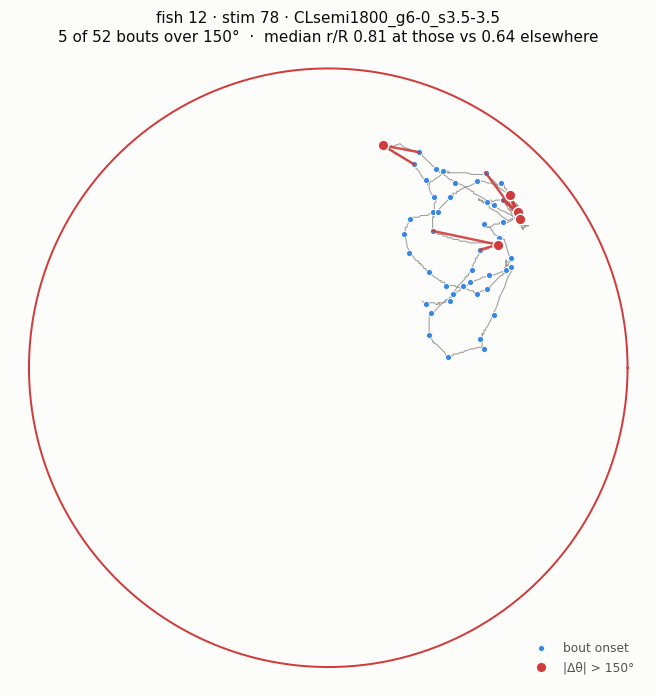

In [ ]:
cands = pick_reversal_block(df, thr_deg=150, min_bouts=25, max_gap=10, exclude=(14,))
print(pd.DataFrame(cands[:5]).to_string(index=False))

best = cands[0]
plot_block_path(df, best["fish"], best["block"], thr_deg=150)
plt.show()

# and the same block as video, if you would rather watch it
# make_block_video(best["fish"], [best["block"]], ROOT / "mp4_reversals.mp4")

#### Are there really that many sharp turns?

Yes, and they are not evenly spread. Over the gap-free rows:

| threshold | share of bouts | median shorter leg | body axis agrees |
|---|---|---|---|
| \|Δθ\| ≤ 90° | 90.8 % | 12.6 px | **92 %** |
| > 90° | 9.2 % | 11.4 px | 59 % |
| > 120° | 3.6 % | 12.0 px | 52 % |
| > 150° | 1.4 % | 13.0 px | 51 % |
| > 170° | 0.5 % | 13.4 px | 51 % |

Two things to take from it. The **displacement never shrinks** — a 170° turn moves the fish
as far as a straight one — so none of this is a stationary-fish artefact. But the body-axis
cross-check **collapses from 92 % to ~51 %** as soon as the turn passes 90°, and stays there.

Real footage suggests that what happens is that the real 30 fps fish make these sharp turns less "abruptly" but since the bouts happen with a frequency of approx 1.2s per bout, they appear more abrupt in this setting. 

 fish   block  n  n_rev  r_rev  r_other  contrast                     stim
   14 stim 76 64     16   0.78     0.78     0.002     CLsemi1800_g0-8_s0-0
   14 stim 13 70     15   0.81     0.80     0.013     CLsemi1800_g4-0_s0-0
   14 stim 59 66     15   0.82     0.79     0.028 CLsemi1800_g0-6_s3.5-3.5
   14 stim 70 62     13   0.80     0.77     0.036 CLsemi1800_g8-0_s3.5-3.5
   14  stim 9 73     10   0.80     0.76     0.037 CLsemi1800_g0-1_s3.5-3.5
   14 stim 75 61     10   0.67     0.60     0.075 CLsemi1800_g1-0_s3.5-3.5


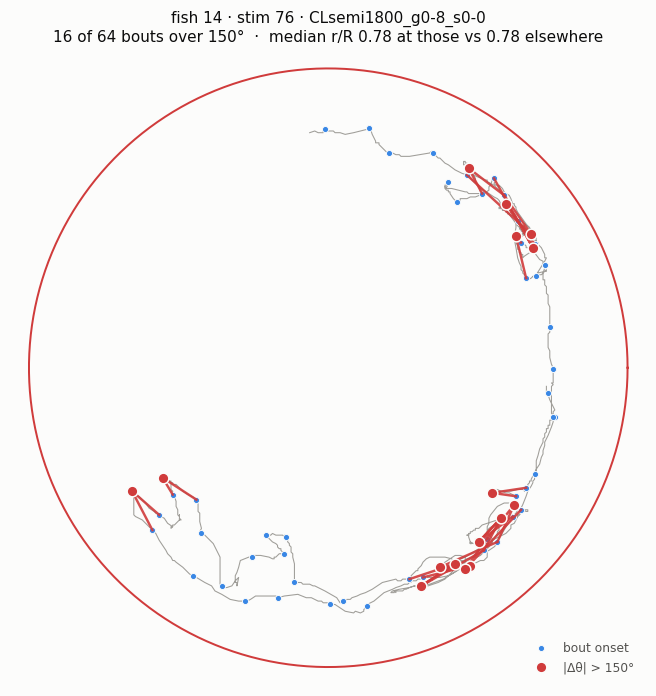

In [ ]:
sharp = pick_reversal_block(df, thr_deg=150, min_bouts=25, max_gap=10, rank="count")
print(pd.DataFrame(sharp[:6]).to_string(index=False))

s0 = sharp[0]
plot_block_path(df, s0["fish"], s0["block"], thr_deg=150)
plt.show()

# the same block at real speed — the shuttling reads much more clearly in motion
# make_block_video(s0["fish"], [s0["block"]], ROOT / f"mp4_sharp_f{s0['fish']}.mp4")

#### Do the ±180° turns come in cancelling *pairs*, and does that mean they are fake?

Watching the block, the sharp turns look like they arrive back to back — a reversal, then
straight back again. They do, and that is worth taking seriously, because
`dtheta_i = theta_i − theta_{i−1}` means **one** wrong leg direction corrupts **two**
consecutive turns as +180 then −180. A cancelling pair is exactly what a measurement error
would look like.

`reversal_pair_check` runs the three tests in order of what each can actually settle:

1. **Rate** — consecutive big turns happen **6.3× more often than independence predicts**
   (88 against 14). Structure exists; this says nothing about its cause.
2. **Cancellation** — 99 % of the pairs sum to under 45°, median 14°. Suggestive, but
   **necessary, not sufficient**: a genuine out-and-back cancels just as neatly.
3. **Decisive** — the path actually walked between onset *i−1* and *i+1* versus the two
   straight legs, plus the worst single frame in the window.

The third one answers it. Over 2.4 s the fish walks **80 px against 39 px** of straight
legs — **ratio 1.86** — reaching 24 px from where it started before returning, and the worst
single frame is **6.3 px (53 mm/s)**. A one-frame position glitch would give ratio ≈ 1 with
a step in the hundreds of px; the known fish 5 artefact steps **217 px** in one frame.

So the pairs are real curved out-and-back excursions, not a frame-assignment flicker — and
59 of the 86 are fish 14, the wall-shuttler again. Re-run this whenever the segmentation
parameters change.

In [ ]:
pairs = reversal_pair_check(df, thr_deg=150)
pairs.head(10)

1. RATE       P(|dtheta| > 150) = 0.0143
              consecutive pairs 90 observed vs 14 expected  ->  6.3x chance
2. CANCELS    |sum of the pair| median 14°, 98 % under 45°   (necessary, not sufficient)
3. DECISIVE   over 2.43 s the fish walks 78 px against 37 px of straight legs  ->  ratio 1.96
              it gets 22 px from the start and back; worst single frame 6.1 px = 51 mm/s
              pairs with any frame over 100 mm/s: 8 of 89

  VERDICT: real out-and-back travel -- a one-frame glitch would give ratio ~1 and a step in the hundreds of px
  concentrated in fish 14 (54 of 89 pairs)


,fish,bout,secs,path_px,straight_px,ratio,excursion_px,max_step_px,max_step_mm_s
0,0,2891,7.67,100.7,46.1,2.18,17.0,6.4,53
1,1,645,2.93,31.6,19.4,1.63,12.2,2.2,19
2,2,1593,3.90,66.5,13.2,5.05,10.4,3.0,25
3,2,4662,2.53,50.2,33.4,1.50,18.9,3.2,26
4,2,4666,1.83,49.5,31.2,1.59,23.0,6.3,53
5,2,5404,2.90,47.2,35.0,1.35,26.0,4.1,34
6,3,523,3.20,94.2,54.6,1.73,27.7,11.3,94
7,4,37,2.77,64.7,16.4,3.94,7.2,7.2,60
8,5,763,2.60,65.4,32.7,2.00,13.2,12.5,104
9,6,2378,4.30,52.3,15.9,3.29,10.4,3.2,26


### 14 · Does behaviour change over the session?

Everything so far pools the whole 174 minutes. This asks whether the fish are doing
something different at the end than at the start — **per fish**, so a session effect cannot
be confused with individuality.

**Two different questions, kept apart.** A *trend* is monotone change (habituation,
fatigue); a *slow fluctuation* is behaviour correlated on a minutes timescale with no
direction. §8–§10 already showed the second exists — quiescence comes in episodes lasting
minutes. This section is about the first.

**How individuality is excluded.** Every fish is centred on its **own** session mean before
plotting, so the panels show change rather than level, and each fish's Spearman `rho` is
computed against its own series. The test that decides anything is then the **sign test
across fish**: one fish drifting proves nothing, but if a session effect is real most of
the 15 should move the same way.

**Two confounds handled.** The stimulus schedule is time-randomised — ρ(cycle, group size)
= 0.001, ρ(cycle, moving) = −0.021, and the two halves match — so a trend cannot be the
protocol's ordering. And the kinematic metrics use **active rows only**, because `distance`
and `Δθ` on a gap-spanning row describe the gap; without that, a drift in quiescence would
leak into every channel as a fake trend.

Start with **`median |Δθ|`**. One panel per fish, one line per stimulus condition, raw units
on a shared axis — with a panel per fish there is no need to normalise, and the level is
worth seeing next to the change. The dashed line is that fish's own all-condition median.

**Active rows only.** On a gap-spanning row `Δθ` describes the gap, and quiescence falls over
the session, so leaving those rows in manufactures a downward trend — see the contamination
table further down. Bins holding fewer than 20 bouts of a condition are left empty rather
than drawn from noise; splitting three ways thins each bin considerably.

Swap `metric=` for `"median Δt (s)"`, `"median dist (px)"` or `"mean r/R"`.

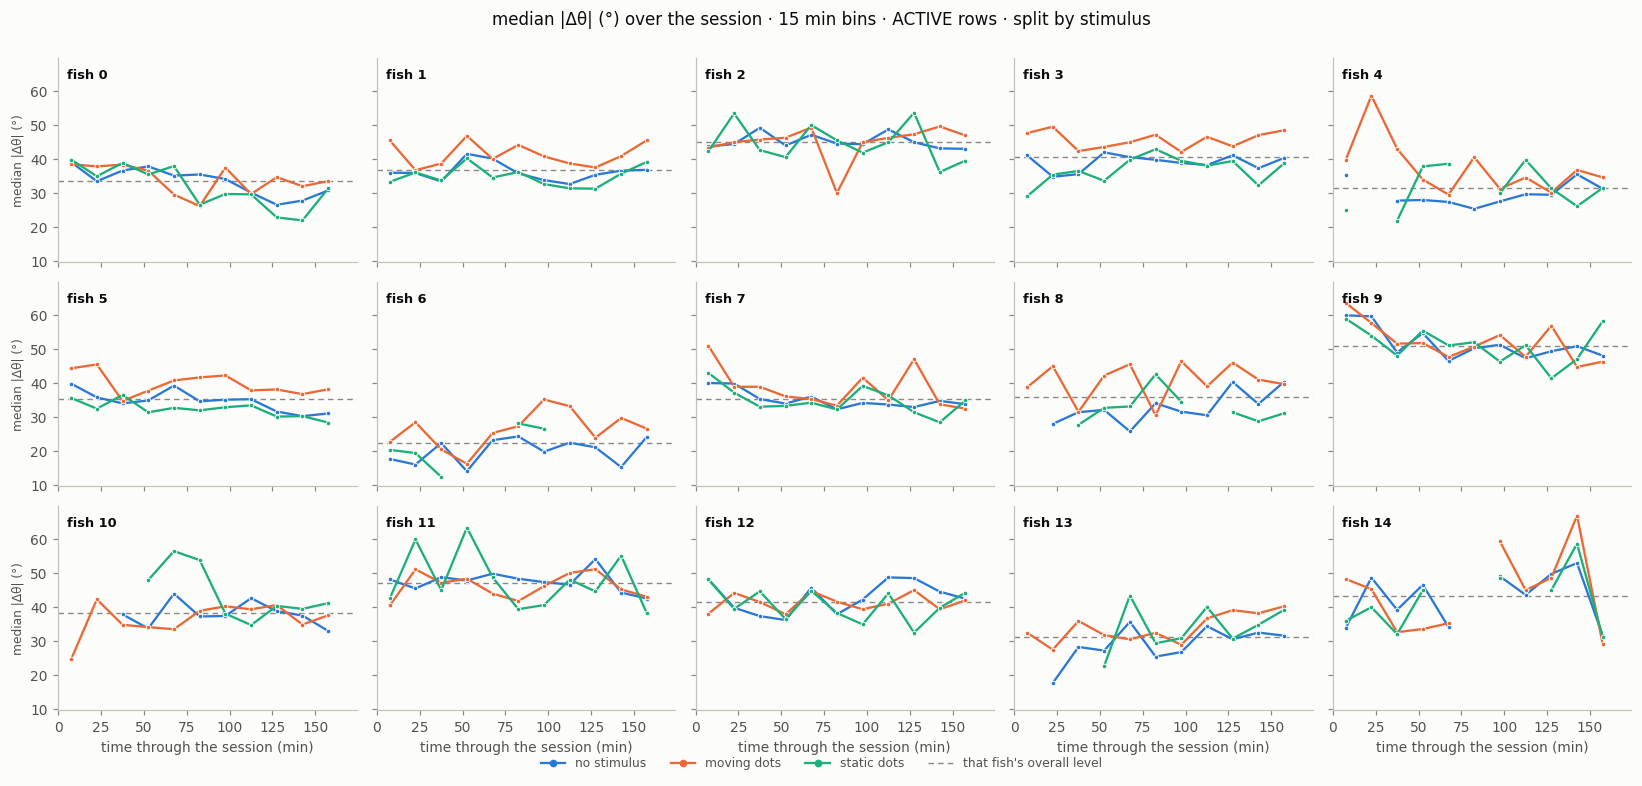

In [ ]:
plot_metric_over_time(df, metric="median |Δθ| (°)", bin_min=15, kinematics="active")
plt.show()

And the **follow index**, the one metric here that actually references the dots. No
`no stimulus` line — there is nothing to turn toward — so the reference is that fish's
overall stimulus-bout level, and the solid line is **chance (0)**, which is the baseline
that matters. This is where the stimulus effect lives: moving above static in essentially
every fish, in most bins, all session long.

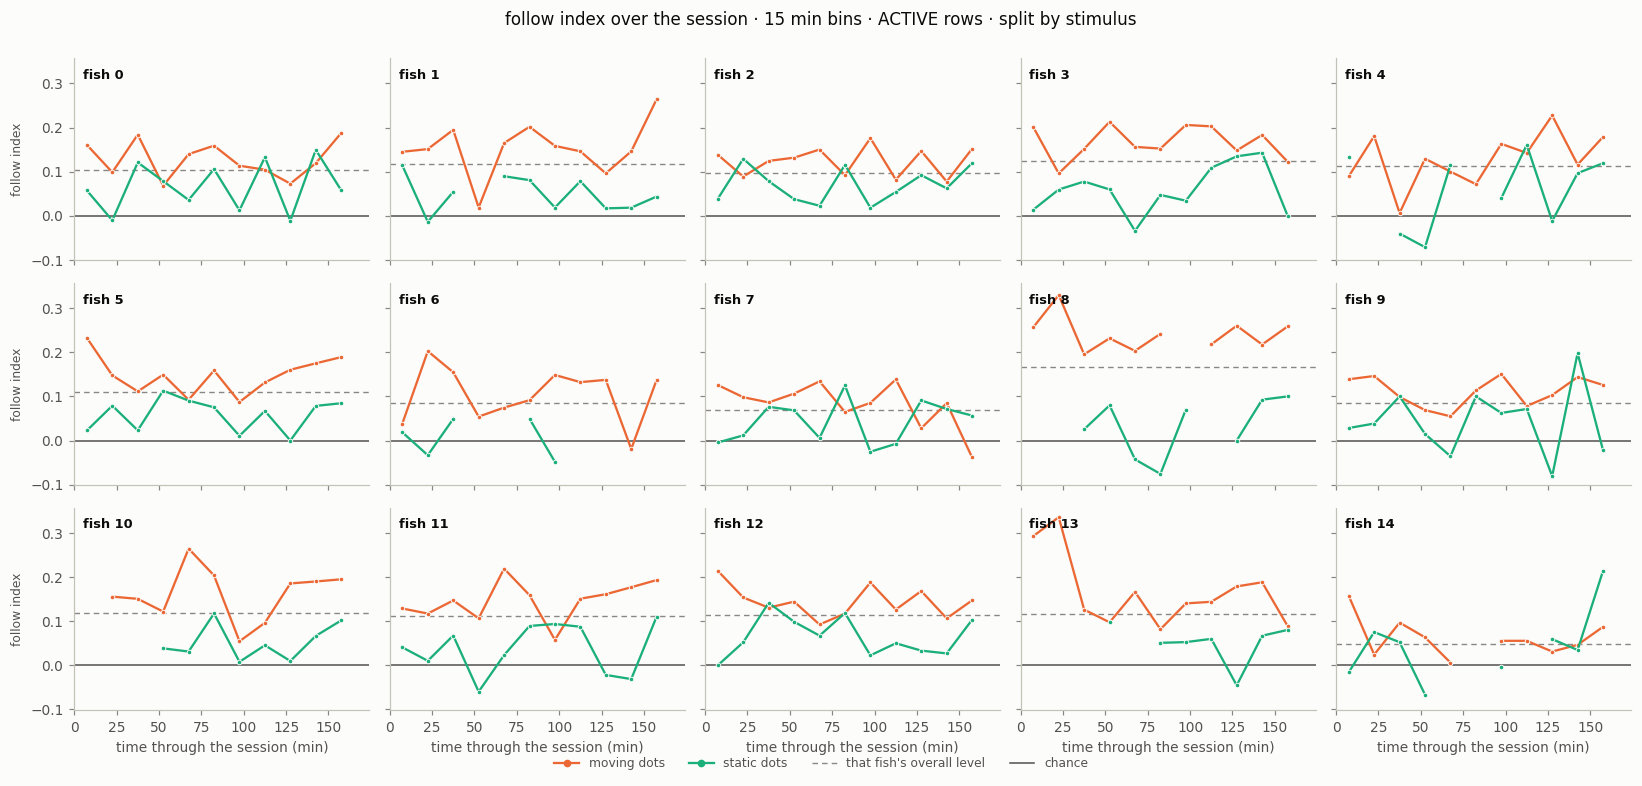

In [ ]:
plot_metric_over_time(df, metric="follow index", bin_min=15, kinematics="active")
plt.show()

And the population view of the same thing — every fish centred on its own mean, with the
across-fish mean and its 95 % CI. Run it both ways to see whether a mean trend survives
restricting to active rows.

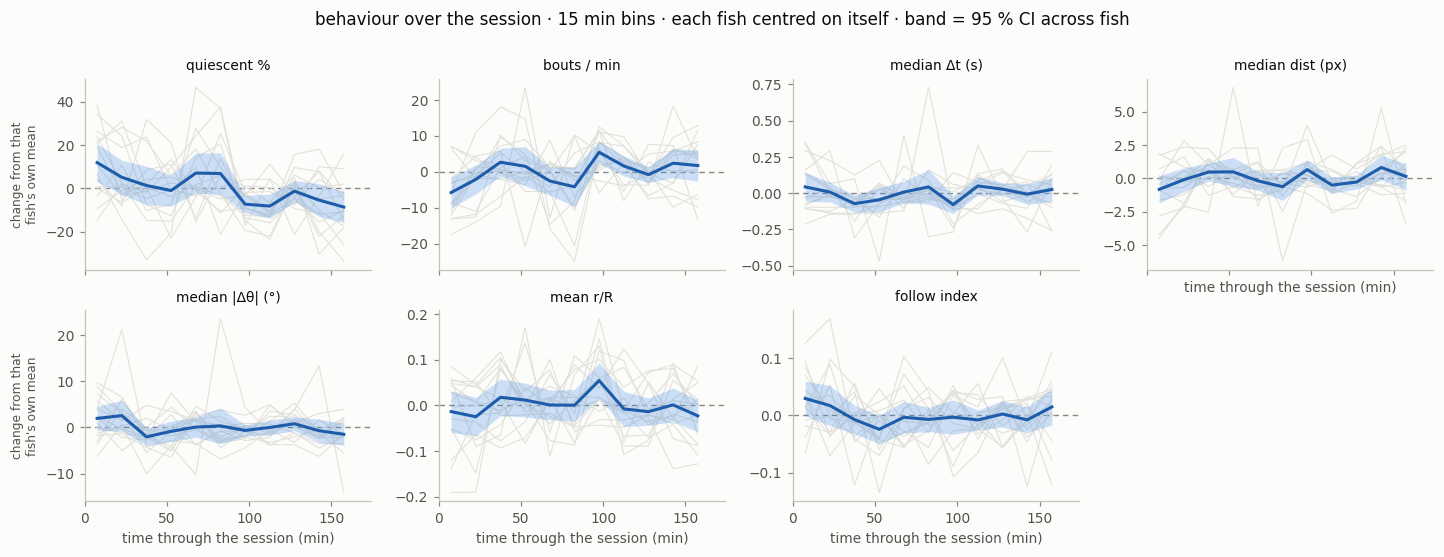

In [ ]:
plot_time_trends(df, bin_min=15, kinematics="active")
plt.show()

In [ ]:
trend_table(df, bin_min=15)

,mean_rho,same_sign,first_bin,last_bin,sign_test_p
metric,,,,,
quiescent %,-0.289,11/15,41.09,20.59,0.1185
bouts / min,0.204,10/15,21.95,29.45,0.3018
median Δt (s),0.229,11/15,1.29,1.28,0.1185
median dist (px),0.037,8/15,14.25,15.21,1.0000
median |Δθ| (°),-0.135,11/15,40.28,36.84,0.1185
mean r/R,-0.082,8/15,0.43,0.43,1.0000
follow index,0.014,9/15,0.17,0.15,0.6072


The Spearman above tests for a **monotone drift**, which is the wrong instrument if the
change is confined to the opening — and the figure suggests exactly that: quiescence
elevated and bout rate depressed for roughly the first half hour, flat afterwards. So
contrast the first 30 min against the rest, paired within each fish.

In [ ]:
settling_table(df, early_min=30, bin_min=15)

,early,rest,diff,same_sign,wilcoxon_p
metric,,,,,
quiescent %,37.70,27.36,10.34,10/15,0.0554
bouts / min,23.78,28.59,-4.81,10/15,0.0637
median Δt (s),1.28,1.24,0.03,8/15,0.6378
median dist (px),14.61,15.18,-0.57,9/15,0.2524
median |Δθ| (°),40.59,37.82,2.77,9/15,0.1205
mean r/R,0.43,0.45,-0.02,8/15,0.5245
follow index,0.16,0.13,0.03,10/15,0.0479


#### "No trend" is not "no change"

Both tests above ask whether change has a **direction**. Neither asks whether there is
change at all — and there is a great deal of it. Comparing how much one fish wanders across
its own 15 min bins against how much the fish differ from each other:

A ratio near 1 means a single fish varies over three hours **as much as the fish differ from
one another**. For bout rate and the follow index that is what happens. Two consequences
worth carrying forward:

* individuality estimated from a short window is largely temporal noise, so a per-fish
  parameter fitted on one stretch will not transfer to another;
* the thing to model is **slow non-directional fluctuation** — which is what the
  across-window autocorrelation metric was pointing at all along — not a session trend.

The settling effect is likewise not uniform: fish 4, 8, 10 and 13 drop 28–36 points of
quiescence between the first half hour and the rest, while fish 2, 6, 14, 0 and 1 move the
other way. Mean +10.3, **median only +4.5** — the aggregate is carried by a minority.

In [ ]:
time_variation_table(df, bin_min=15)

,within_fish_sd,between_fish_sd,ratio
metric,,,
follow index,0.049,0.042,1.17
bouts / min,7.564,7.251,1.04
mean r/R,0.069,0.078,0.87
quiescent %,14.112,20.274,0.70
median dist (px),1.427,2.424,0.59
median Δt (s),0.131,0.226,0.58
median |Δθ| (°),4.034,7.160,0.56


#### Is that wobble a slow state, or estimation noise?

The table above says a fish varies over the session; it does not say the variation *means*
anything. Two orthogonal tests settle it, at 5 min bins:

* **acf1/2/3** — autocorrelation of each fish's own series. Sampling noise is white, so
  acf ≈ 0; a slow state gives acf1 > 0 decaying with lag, and where it hits 0 is the
  timescale. Per-fish analogue of `generative_metrics`' `rate_acf_1min/3min_gap`.
* **split-half r** — split each bin's bouts at random in two, compute the metric on each,
  correlate over all (fish, bin) cells. Assumption-free. Spearman-Brown converts it to the
  reliability of the full bin: the share of observed variance that is signal.

**The kinematic channels have a real slow state.** acf1 ≈ 0.18–0.27, falling to ~0 by lag 3
— a timescale of roughly **5–10 minutes** — and split-half reliability of **0.88–0.98**, so
their bin-to-bin wobble is almost entirely signal. That is the structure the drift AR(1) is
meant to capture, and it is measurable here directly rather than through a model gap.

⚠ **`follow index` is the exception and it inverts the earlier conclusion.** acf1 = −0.025
and split-half r = +0.024 — no reproducible within-bin signal at all. Its large within-fish
SD is the binomial error on a few dozen turn bouts, not behaviour. So the stimulus response
is *stable* within a fish across the session; only the kinematics drift.

In [ ]:
temporal_structure_table(df, bin_min=5)

,rows,acf1,acf2,acf3,split_half_r,signal_share
metric,,,,,,
quiescent %,all,0.080,0.081,0.041,NaN,NaN
bouts / min,all,0.253,-0.007,-0.017,NaN,NaN
median Δt (s),active,0.185,0.016,-0.039,0.698,0.822
median dist (px),active,0.182,0.158,0.019,0.858,0.924
median |Δθ| (°),active,0.259,0.127,0.084,0.656,0.792
mean r/R,active,0.266,0.066,0.052,0.956,0.978
follow index,active + moving,-0.049,-0.120,-0.004,0.127,0.225


#### Does the slow state depend on what is on screen?

Splitting the same analysis by stimulus condition. Two constraints to be aware of before
reading it:

* **The bin size cannot be raised to buy back sample size.** At 15 min the autocorrelation
  is gone even pooled (0.11–0.13 against 0.16–0.28 at 5 min) — 15 min is already past the
  correlation time. So the split has to happen at 5 min, and each bin drops from ~137
  active bouts to **31–64**. `split_half_r` is the guard: read it before the acf on every
  row.
* **`quiescent %` and `bouts / min` are absent by design** — both are rates over wall-clock
  time and per-condition exposure varies bin to bin, so a per-condition version would
  measure the schedule as much as the fish.

In [ ]:
temporal_structure_by_cond(df, bin_min=5)

bouts_per_bin   acf1   acf2  split_half_r
metric           condition                                             
median |Δθ| (°)  no stimulus             64  0.144  0.059         0.644
                 moving dots             51  0.070 -0.011         0.489
                 static dots             31  0.118 -0.006         0.570
median Δt (s)    no stimulus             64  0.275  0.072         0.822
                 moving dots             51  0.048  0.071         0.711
                 static dots             31  0.132 -0.013         0.736
median dist (px) no stimulus             64  0.200 -0.006         0.863
                 moving dots             51  0.129  0.050         0.794
                 static dots             31  0.149 -0.095         0.832
mean r/R         no stimulus             64  0.318 -0.002         0.936
                 moving dots             51  0.114  0.038         0.940
                 static dots             31  0.251  0.049         0.937
follow index     moving dots             51 -0.049 -0.120         0.147
                 static dots             31  0.019 -0.188        -0.201

And the contrast that matters, **paired within fish** so between-fish differences in how
autocorrelated a fish is cannot produce it. `disatt_diff` divides each condition's acf by
its own split-half reliability first, because a noisier estimate is attenuated toward 0 and
could manufacture a difference by itself.

**The slow state is markedly weaker under a moving stimulus** for interval and radial
position — both ~12/15 fish, and for `mean r/R` the reliabilities are nearly identical
across conditions (0.94 vs 0.95) so attenuation cannot explain it. The natural reading is
that with dots moving those channels are externally driven: the stimulus overrides the
fish's own drift, while during pauses it free-runs and the internal state shows.

⚠ **Several metrics, no multiplicity correction.** Bonferroni over three would put both
survivors at p ≈ 0.05–0.07, so this is suggestive and mechanistically coherent rather than
established. The confirmatory version is a single pre-chosen metric — `mean r/R`, the
best-measured one.

If it holds it matters for the drift work: the slow state is not a constant-strength
intrinsic process but one that is **suppressed while the stimulus drives**, so a drift term
with fixed τ and amplitude would be wrong in exactly the blocks the model is scored on.

In [ ]:
acf_condition_contrast(df, bin_min=5, a_cond="none", b_cond="moving")

,no stimulus,moving dots,diff,same_sign,wilcoxon_p,disatt_diff
metric,,,,,,
median |Δθ| (°),0.144,0.070,0.074,8/15,0.3894,0.080
median Δt (s),0.275,0.048,0.228,13/15,0.0034,0.268
median dist (px),0.200,0.129,0.070,10/15,0.3591,0.068
mean r/R,0.318,0.114,0.204,12/15,0.0302,0.218


#### The control that makes the above believable

There is an alternative that neither the pairing nor the reliability column can rule out.
Stimulus parameters are **randomised block to block** — group size, side, speed — and a
fish's kinematics partly track *which* stimulus is on. That injects variation into the
moving-condition series that is uncorrelated between bins, diluting the acf with no
suppression of anything. Split-half cannot detect it: it splits bouts *within* a bin, so
both halves carry the same stimulus mix.

The control residualises every bout on its own stimulus identity (fish × group size × side)
before binning, removing all between-bin variation attributable to the protocol. **The acf
stays low** — 0.114 → 0.133 for `r/R`, 0.048 → 0.063 for `Δt`, both still far under the
no-stimulus 0.318 and 0.275, and both still significant. So the suppression is the fish,
not the schedule.

In [ ]:
acf_stimulus_identity_control(df, bin_min=5, a_cond="none", b_cond="moving")

,no stimulus,moving dots raw,moving dots residualised,same_sign,wilcoxon_p
metric,,,,,
mean r/R,0.318,0.114,0.133,12/15,0.0302
median Δt (s),0.275,0.048,0.063,11/15,0.0103
median |Δθ| (°),0.144,0.070,0.057,8/15,0.4212
median dist (px),0.200,0.129,0.108,11/15,0.3591


#### ⚠ Suppressing the drift is not the same as suppressing individuality

Easy to conflate, and they behave differently. The acf asks whether **one fish's** deviation
persists over 5 min; this asks how far the fish are **from each other**. The stimulus cuts
the first by ~60 % and the second by 0–18 %, with no significance test at n = 15 — so the
compression may be nothing at all.

The useful version of the claim: **a moving stimulus suppresses each fish's own slow drift
while leaving the fish about as different from one another as they were.** For the modelling
that separates two mechanisms cleanly — a per-fish random effect stays valid under stimulus
and needs no stimulus term, whereas the drift/slow-state term is the one that needs
modulating, since a fixed τ and amplitude would be wrong in exactly the blocks the model is
scored on.

In [ ]:
between_fish_sd_by_cond(df)

,no stimulus,moving dots,static dots,ratio_moving_none
metric,,,,
mean r/R,0.084,0.074,0.085,0.87
median Δt (s),0.229,0.236,0.223,1.03
median |Δθ| (°),7.945,6.500,7.226,0.82
median dist (px),2.745,2.535,2.868,0.92


#### The 15 fish behind those averages

Every `acf1` above is a mean over 15 fish, which cannot tell an effect **every** fish shows
from one that **three** fish carry. Same computation, one row per fish.

⚠ **One cell here is one fish's ~34 five-minute bins**, minus the bins that condition did
not fill — so `n_bins` runs 10–30 and the standard error on a single `acf1` is roughly
**±0.2–0.3**. Do not read an individual number. Read the *column*: how many of the 15 land
on the same side. A **hollow marker** means that fish's `split_half_r` is under 0.3 there —
its bin estimates are too noisy for the acf to mean anything, so it is drawn but should not
be counted.

| metric | fish with `none` > `moving` | of the reliable ones |
|---|---|---|
| mean r/R | 12/15 | **12/15** |
| median Δt (s) | 13/15 | **10/12** |
| median dist (px) | 10/15 | 10/12 |
| median \|Δθ\| (°) | 8/15 | 1/1 |

So the suppression is **general for `r/R` and `Δt`** — not an average carried by a
minority — and it is **not established for `|Δθ|`**, where the fish split 8/7 and only one
animal passes the reliability guard in both conditions at all. `median dist` sits between
the two.

The `follow index` panel is the control: scattered either side of zero and mostly hollow. A
fish's stimulus response does not drift over the session — it is a **stable trait**, which
is why it belongs in a per-fish random effect rather than in a drift term.

⚠ `static dots` is the thinnest column throughout — it gets the least wall-clock time per
bin and loses the most bins to the 20-bout floor, so several fish have no static estimate at
all. Read it last.

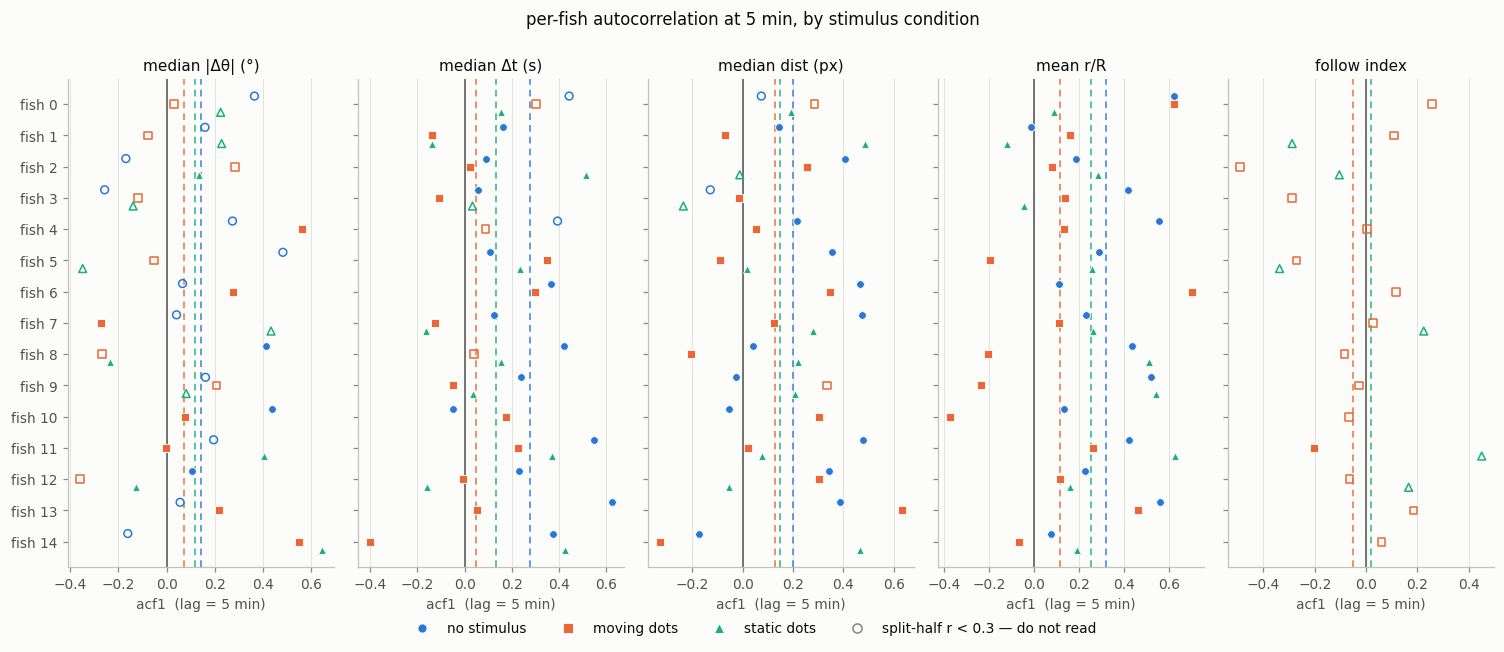

In [ ]:
plot_acf_by_fish(df)
plt.show()

In [ ]:
# the numbers behind the figure; `acf_f` also carries n_bins, acf2 and split_half_r
acf_f = temporal_structure_by_fish(df)
acf_f["acf1"].unstack("condition").round(3)

condition              moving dots  no stimulus  static dots
metric        fish_id                                       
follow index  0              0.256          NaN          NaN
              1              0.110          NaN       -0.288
              2             -0.491          NaN       -0.104
              3             -0.289          NaN          NaN
              4              0.003          NaN          NaN
...                            ...          ...          ...
median Δt (s) 10             0.176       -0.048          NaN
              11             0.224        0.548        0.370
              12            -0.009        0.230       -0.161
              13             0.053        0.623          NaN
              14            -0.400        0.373        0.426

[75 rows x 3 columns]

### 15 · Is the "non-steady state" real?

The claim: bouts shortly after a quiescent gap differ from bouts deep inside a run —
the fish restarts slowly and settles. The per-fish curves that motivated it are noisy
enough that the aggregate trend could be an artefact, so this section asks whether the
effect survives a design built to remove the two things that could manufacture it.

**Confound 1 — run selection.** Comparing "first bouts of any run" against "position ≥ 60"
compares *different runs*: only long runs reach position 60, and a long run is by
definition a stretch of sustained activity, i.e. short intervals. That alone produces a
positive difference even if position within a run does nothing.
→ *Fix:* keep only runs with at least `MIN_RUN` active bouts and take **both** windows
from the **same** run, so every comparison is within one run.

**Confound 2 — the fish.** Pooling bouts across animals lets a few busy fish dominate.
→ *Fix:* summarise run-level differences per fish, and treat the **fish** as the
replicate unit (n = 15, sign test) rather than the bout.

**Confound 3 — what is on screen.** Runs start out of quiescence, which is not uniformly
distributed over the block programme, so the early window carries a different mix of
stimulus conditions than the late one.
→ *Checked* by repeating the whole test inside each condition.

Two controls decide whether the machinery itself is biased: a **permutation null** that
shuffles bout order within each run (any effect surviving that is structural, not
behavioural), and the same test on **all three channels**, since an effect on one channel
only is a different claim from an effect on the animal's whole state.

In [111]:
# --------------------------------------------------------------------------- #
#  §15-A -- the paired within-run test.
#
#  For each run of at least MIN_RUN active bouts: median of the channel over the
#  EARLY window minus the median over the LATE window, both inside that one run.
#  Per fish, the statistic is the median over that fish's runs; across fish it is
#  a sign test on the 15 per-fish values. Bootstrap CIs resample RUNS within a
#  fish, which is the level the runs are exchangeable at.
# --------------------------------------------------------------------------- #
from scipy.stats import binomtest

EARLY, LATE, MIN_RUN = (0, 5), (15, 31), 30      # [lo, hi) in bout positions
PX_PER_MM_PHYS = 3.60
CH = [("dt_s", "interbout interval (s)"), ("dist_mm", "displacement (mm)"),
      ("adth", "|dtheta| (deg)")]


def prep_runs(d, thr=QUIET_S, min_run=MIN_RUN):
    """Active bouts, position in run, condition -- restricted to long-enough runs."""
    t = d.copy()
    t["gap_after"] = t.dt_s > thr
    t["gap_before"] = t.groupby("fish_id").gap_after.shift(1).fillna(False)
    t["active"] = ~(t.gap_after | t.gap_before)
    t["run_id"] = (t.gap_before | (t.fish_id != t.fish_id.shift())).cumsum()
    a = t[t.active].copy()
    a["pos"] = a.groupby("run_id").cumcount()
    a["cond"] = np.where(a.side.eq("none"), "none",
                         np.where(a.moving.astype(bool), "moving", "static"))
    a["adth"] = a.dtheta_deg.abs()
    a["dist_mm"] = a.distance_px / PX_PER_MM_PHYS
    n = a.groupby("run_id").size()
    return a[a.run_id.isin(n[n >= min_run].index)].copy()


def run_diffs(a, col, early=EARLY, late=LATE):
    """One row per run: early-window median minus late-window median, same run."""
    e = (a[a.pos.between(early[0], early[1] - 1)]
         .groupby(["fish_id", "run_id"])[col].median().rename("early"))
    l = (a[a.pos.between(late[0], late[1] - 1)]
         .groupby(["fish_id", "run_id"])[col].median().rename("late"))
    j = pd.concat([e, l], axis=1).dropna().reset_index()
    j["diff"] = j["early"] - j["late"]
    return j


def per_fish(j, n_boot=2000, seed=0):
    """Per-fish median difference with a bootstrap CI over that fish's runs."""
    rng = np.random.default_rng(seed)
    out = []
    for f, g in j.groupby("fish_id"):
        v = g["diff"].to_numpy(float)
        bs = np.array([np.median(rng.choice(v, v.size, replace=True))
                       for _ in range(n_boot)])
        out.append(dict(fish_id=f, n_runs=len(v), est=float(np.median(v)),
                        lo=float(np.percentile(bs, 2.5)),
                        hi=float(np.percentile(bs, 97.5))))
    return pd.DataFrame(out)


def adjudicate(a, label="", n_boot=2000, verbose=True):
    """The whole test, all three channels. Returns {col: per-fish table}."""
    res, rows = {}, []
    for col, nice in CH:
        j = run_diffs(a, col)
        pf = per_fish(j, n_boot=n_boot)
        res[col] = pf
        pos = int((pf.est > 0).sum())
        p = binomtest(pos, len(pf), .5).pvalue
        rows.append(dict(channel=nice, runs=len(j), fish=len(pf),
                         pooled=round(float(j["diff"].median()), 3),
                         per_fish_med=round(float(pf.est.median()), 3),
                         pos=f"{pos}/{len(pf)}", sign_p=f"{p:.2g}",
                         ci_excl_0=int(((pf.lo > 0) | (pf.hi < 0)).sum())))
    tab = pd.DataFrame(rows)
    if verbose:
        print(f"PAIRED WITHIN-RUN TEST{'  ' + label if label else ''}"
              f"   early=pos{EARLY[0]}-{EARLY[1]-1}, late=pos{LATE[0]}-{LATE[1]-1}, "
              f"runs >= {MIN_RUN} bouts")
        print(tab.to_string(index=False))
        print("  pos = fish whose effect is positive; ci_excl_0 = fish whose own "
              "95% CI excludes zero")
    return res, tab


A = prep_runs(df)
print(f"{A.run_id.nunique()} runs, {len(A):,} active bouts, "
      f"{A.fish_id.nunique()} fish, "
      f"{A.groupby('fish_id').run_id.nunique().min()}-"
      f"{A.groupby('fish_id').run_id.nunique().max()} runs per fish\n")
RES, TAB = adjudicate(A)

409 runs, 64,010 active bouts, 15 fish, 16-36 runs per fish

PAIRED WITHIN-RUN TEST   early=pos0-4, late=pos15-30, runs >= 30 bouts
               channel  runs  fish  pooled  per_fish_med   pos  sign_p  ci_excl_0
interbout interval (s)   409    15   0.150         0.183 14/15 0.00098          3
     displacement (mm)   409    15  -0.362        -0.457  1/15 0.00098          5
        |dtheta| (deg)   409    15   4.444         3.196 10/15     0.3          5
  pos = fish whose effect is positive; ci_excl_0 = fish whose own 95% CI excludes zero


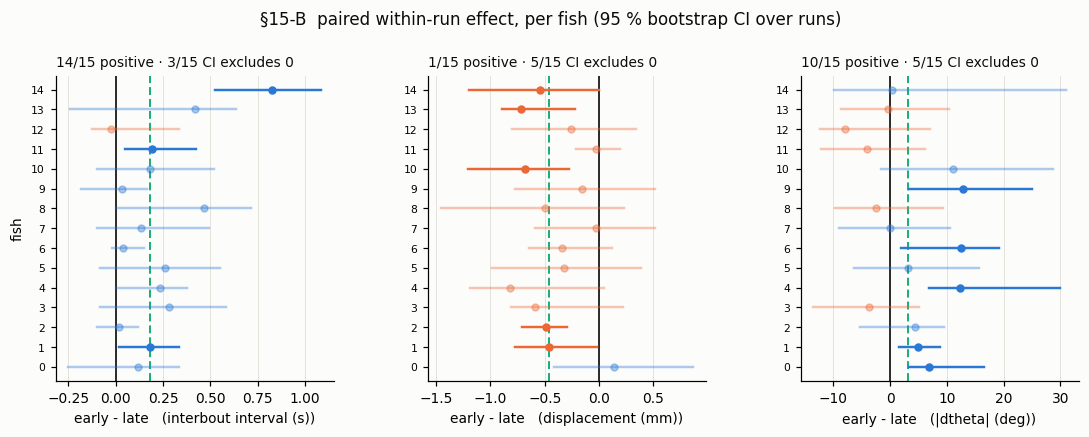

PERMUTATION NULL (200 shuffles of bout order within each run)
  interbout interval (s)     observed  +0.183   null -0.001 +/- 0.020   |null| >= |obs| in 0.0% of shuffles
  displacement (mm)          observed  -0.457   null +0.002 +/- 0.062   |null| >= |obs| in 0.0% of shuffles
  |dtheta| (deg)             observed  +3.196   null +0.074 +/- 1.255   |null| >= |obs| in 1.0% of shuffles

SAME TEST INSIDE EACH STIMULUS CONDITION
cond                channel  runs  fish  pooled  per_fish_med   pos sign_p  ci_excl_0
none interbout interval (s)    78    14  -0.033         0.017  7/14      1          3
none      displacement (mm)    78    14  -0.209        -0.024  7/14      1          2
none         |dtheta| (deg)    78    14   8.137         6.472 11/14  0.057          3
  cond                channel  runs  fish  pooled  per_fish_med   pos sign_p  ci_excl_0
moving interbout interval (s)   169    15   0.117         0.117 11/15   0.12          2
moving      displacement (mm)   169    15  -0.382   

In [112]:
# --------------------------------------------------------------------------- #
#  §15-B -- per-fish forest plot, the permutation null, and the condition control.
#
#  Forest plot: one row per fish, its own bootstrap CI. A real effect shows as
#  most fish on the same side of zero -- NOT as every CI excluding zero, which is
#  a much stronger and unnecessary bar.
#  Permutation null: shuffle bout order within each run and rerun. The whole
#  design is position-based, so a shuffled run has no position structure left;
#  anything that survives is machinery, not behaviour.
# --------------------------------------------------------------------------- #
fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.6), gridspec_kw={"wspace": .34})
for ax, (col, nice) in zip(axes, CH):
    pf = RES[col].sort_values("fish_id")
    y = np.arange(len(pf))
    ok = (pf.lo > 0) | (pf.hi < 0)
    for yi, (_, r) in zip(y, pf.iterrows()):
        col_ = BLUE if r.est > 0 else ORANGE
        ax.plot([r.lo, r.hi], [yi, yi], color=col_, lw=1.6,
                alpha=1.0 if (r.lo > 0 or r.hi < 0) else .38, zorder=2)
        ax.plot([r.est], [yi], "o", color=col_, ms=4.5,
                alpha=1.0 if (r.lo > 0 or r.hi < 0) else .38, zorder=3)
    ax.axvline(0, color=INK, lw=1.1, zorder=1)
    pooled = float(pf.est.median())
    ax.axvline(pooled, color=AQUA, lw=1.3, ls=(0, (4, 2)), zorder=1)
    ax.set_yticks(y); ax.set_yticklabels([f"{int(f)}" for f in pf.fish_id], fontsize=7)
    ax.set_ylabel("fish" if col == CH[0][0] else "")
    ax.set_xlabel(f"early - late   ({nice})")
    ax.set_title(f"{int((pf.est > 0).sum())}/{len(pf)} positive · "
                 f"{int(ok.sum())}/{len(pf)} CI excludes 0",
                 fontsize=9, color=INK, loc="left")
    ax.grid(axis="x", color=GRID, lw=.6, zorder=0); ax.set_axisbelow(True)
fig.suptitle("§15-B  paired within-run effect, per fish (95 % bootstrap CI over runs)",
             y=1.045, fontsize=11, color=INK)
plt.show()

# ---- permutation null: destroy position structure inside each run ------------
rng = np.random.default_rng(7)
null = {col: [] for col, _ in CH}
for _ in range(200):
    P = A.copy()
    P["pos"] = (P.groupby("run_id")["pos"]
                .transform(lambda s: rng.permutation(s.to_numpy())))
    for col, _ in CH:
        j = run_diffs(P, col)
        null[col].append(float(j.groupby("fish_id")["diff"].median().median()))

print("PERMUTATION NULL (200 shuffles of bout order within each run)")
for col, nice in CH:
    obs = float(RES[col].est.median())
    nl = np.array(null[col])
    p = (np.abs(nl) >= abs(obs)).mean()
    print(f"  {nice:26s} observed {obs:+7.3f}   null {nl.mean():+.3f} "
          f"+/- {nl.std():.3f}   |null| >= |obs| in {p*100:.1f}% of shuffles")

# ---- condition control ------------------------------------------------------
print("\nSAME TEST INSIDE EACH STIMULUS CONDITION")
for cnd in ("none", "moving", "static"):
    sub = A[A.cond.eq(cnd)].copy()
    _, t = adjudicate(sub, label=f"[{cnd}]", n_boot=400, verbose=False)
    t.insert(0, "cond", cnd)
    print(t.to_string(index=False))

**Verdict — how to read the three outputs.**

1. **The table (§15-A).** `pos` is the number of fish whose effect points the same way.
   With 15 fish, 13/15 or better is `p < 0.01` on a sign test, and that is the number to
   quote — not the pooled value, which no single animal is guaranteed to show.
   `ci_excl_0` is deliberately a stricter bar: a real population effect does *not*
   require every individual's CI to clear zero.
2. **The forest plot (§15-B).** What matters is whether the points cluster on one side of
   zero, not whether the intervals are tight. Faded rows are fish whose own CI includes
   zero; they still count toward the sign test.
3. **The permutation null.** If the observed effect sits inside the shuffled distribution,
   the whole thing is an artefact of the windowing and the section should be dropped from
   the report. If the shuffled effects centre on zero with a spread far smaller than the
   observed value, the design is clean and the effect is real.
4. **The condition control.** If the effect only appears in one condition, it is a
   stimulus effect wearing a run-position costume, and should be described that way.

Whatever this returns decides how §3.2.3 of the report is written — including the
possibility that the non-steady state is dropped and the run clock loses its
justification.

### 16 · The dot profile — bootstrap over fish vs SEM

`scripts/model_figures._draw`, which produces the approach profile in the model notebook,
shades **± 1 SEM** across fish: it averages within each fish over that fish's blocks, then
takes `mean ± SD/√15` across the fifteen. Two things about that are worth checking before
the same band goes into the report.

* **It is a ~68 % interval**, not 95 %. Read next to any 95 % band elsewhere in the thesis
  it will look far tighter than it is.
* **It assumes symmetry.** With n = 15 and a couple of markedly quiescent animals, the
  per-fish means are not symmetric about their mean, so a ± k·SE band misstates the
  interval on the long side.

The cells below rebuild the real-fish profile exactly as `model_figures.real_dot_profile`
does — active bouts only, the centroid-outside-dish rule, `PX_TO_MM = 3.67`, 2 s bins, and
the same PuBu/OrRd colour scheme — and then band it three ways so the difference is
visible rather than argued about.

In [115]:
# --------------------------------------------------------------------------- #
#  §16-A -- rebuild the real dot profile, matching model_figures.real_dot_profile
#  (active bouts, centroid-outside-dish rule, PX_TO_MM = 3.67, 2 s bins).
# --------------------------------------------------------------------------- #
PX_TO_MM, BIN_S = 3.67, 2.0
STIMULI_ORDER = ["d1s3.5", "d2s3.5", "d4s3.5", "d6s3.5", "d8s3.5",
                 "d1s0", "d4s0", "d8s0"]
MOTION = [s for s in STIMULI_ORDER if not s.endswith("s0")]
STATIC = [s for s in STIMULI_ORDER if s.endswith("s0")]


def _stim_label(s):
    n = int(s.split("s")[0][1:])
    return f"{n} dot{'s' if n != 1 else ''} - {'static' if s.endswith('s0') else 'motion'}"


def _color_map():
    """PuBu motion, OrRd static, darker = more dots -- model_figures._color_map."""
    pal = lambda name, n: [plt.get_cmap(name)(x) for x in np.linspace(0.35, 0.95, n)]
    key = lambda s: int(s.split("s")[0][1:])
    return {**dict(zip(sorted(MOTION, key=key), pal("PuBu", len(MOTION)))),
            **dict(zip(sorted(STATIC, key=key), pal("OrRd", len(STATIC))))}


def real_dot_profile(d=None, quiet_s=QUIET_S):
    """Stimulus bouts with cond_label, dist_mm and the 2 s bin. `active` is rebuilt
    here because this notebook reads the raw bout table, not bouts_clean."""
    d = df if d is None else d
    t = d.copy()
    t["gap_after"] = t.dt_s > quiet_s
    t["gap_before"] = t.groupby("fish_id").gap_after.shift(1).fillna(False)
    a = t[~(t.gap_after | t.gap_before)].copy()

    a["n_dots"] = (a.n_dots_left.fillna(0) + a.n_dots_right.fillna(0)).astype(int)
    st = a[(a.stimulus != "inter_stim_pause") & a.dot_dist_px.notna()].copy()
    st["cond_label"] = [f"d{n}s{'3.5' if m else '0'}"
                        for n, m in zip(st.n_dots, st.moving)]

    # centroid-outside-dish rule, against the PHYSICAL dish geometry
    roi = pd.read_csv(ROOT / "data/data/Original_data/ROIdef2025-02-20T12_09_16.csv",
                      header=None,
                      names=["xoff", "yoff", "diameter", "x", "y", "radius"])
    roi["cx"] = roi["x"] - roi["xoff"]
    roi["cy"] = roi["diameter"] - (roi["y"] - roi["yoff"])
    g = st.join(roi[["cx", "cy", "radius"]], on="fish_id")
    st = st[~(np.hypot(g.dot_cx - g.cx, g.dot_cy - g.cy) > g.radius).to_numpy()]

    st["dist_mm"] = st.dot_dist_px / PX_TO_MM
    st["tbin"] = (np.floor(st.t_blk / BIN_S) + 0.5) * BIN_S
    return st


def per_fish_matrix(st, stim):
    """(fish x tbin) matrix of per-fish mean distance -- the fish is the replicate."""
    s = st[st.cond_label == stim]
    return (s.groupby(["fish_id", "tbin"]).dist_mm.mean()
             .unstack("tbin").sort_index(axis=1))


def bands(M, n_boot=4000, seed=0):
    """mean, (sem_lo, sem_hi), (ci95_lo, ci95_hi), (boot_lo, boot_hi) per tbin."""
    rng = np.random.default_rng(seed)
    A = M.to_numpy(float)
    mu = np.nanmean(A, axis=0)
    n = np.sum(np.isfinite(A), axis=0)
    sd = np.nanstd(A, axis=0, ddof=1)
    se = sd / np.sqrt(np.maximum(n, 1))
    idx = rng.integers(0, A.shape[0], size=(n_boot, A.shape[0]))
    bs = np.array([np.nanmean(A[i], axis=0) for i in idx])
    lo, hi = np.nanpercentile(bs, [2.5, 97.5], axis=0)
    return mu, (mu - se, mu + se), (mu - 1.96 * se, mu + 1.96 * se), (lo, hi)


ST = real_dot_profile()
print(f"{len(ST):,} stimulus bouts, {ST.fish_id.nunique()} fish, "
      f"{ST.cond_label.nunique()} conditions")
print(ST.groupby("cond_label").size().reindex(STIMULI_ORDER).to_string())

35,050 stimulus bouts, 15 fish, 8 conditions
cond_label
d1s3.5    4505
d2s3.5    4347
d4s3.5    4838
d6s3.5    4951
d8s3.5    4071
d1s0      4019
d4s0      4086
d8s0      4233


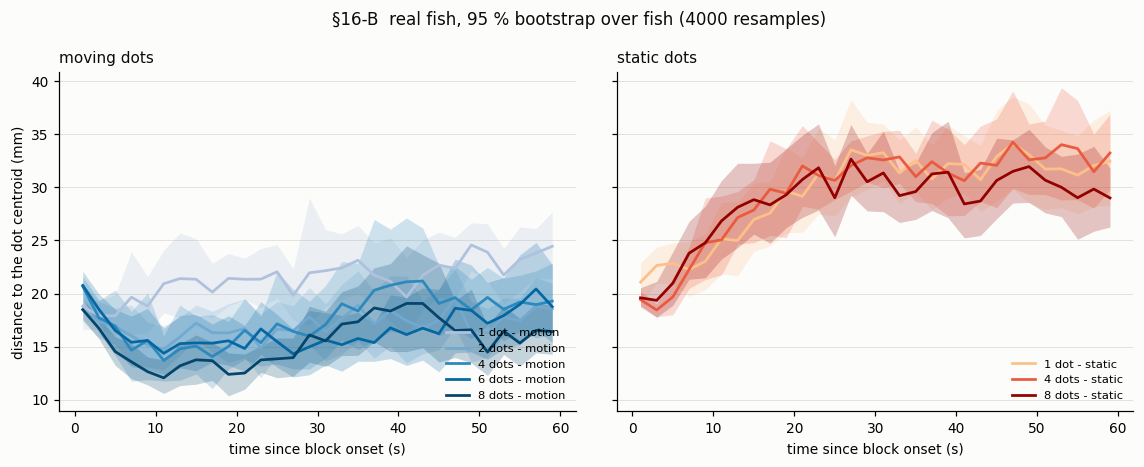

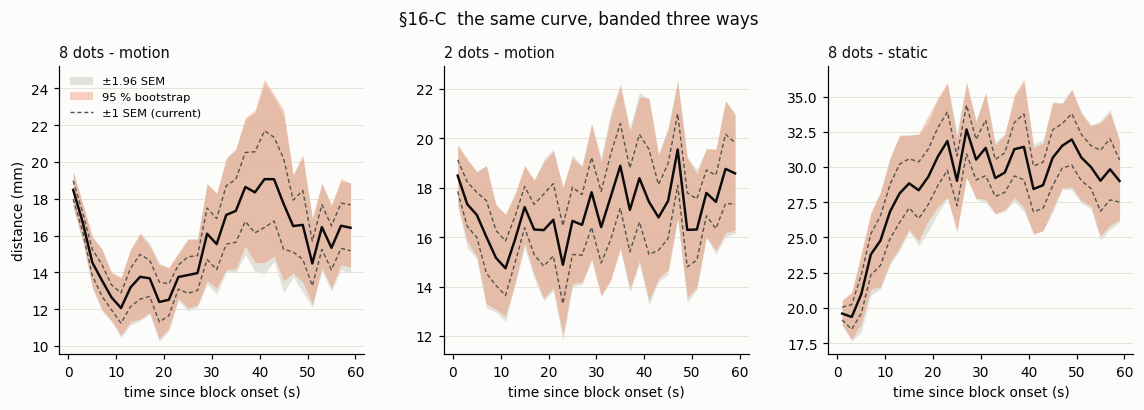

mean band WIDTH over the block (mm); asymmetry = upper arm minus lower arm
                 ±1 SEM width  ±1.96 SEM width  95% boot width  boot / 1.96SEM  boot asymmetry (mm)
condition                                                                                          
8 dots - motion         2.587            5.071           4.888           0.964                0.270
2 dots - motion         2.641            5.176           4.989           0.964                0.084
8 dots - static         3.420            6.703           6.483           0.967                0.196


In [116]:
# --------------------------------------------------------------------------- #
#  §16-B -- the profile with 95 % bootstrap-over-fish bands, and the three band
#  definitions overlaid on one condition so the difference is visible.
# --------------------------------------------------------------------------- #
CM = _color_map()

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.0), sharey=True,
                         gridspec_kw={"wspace": .08})
for ax, group, name in ((axes[0], MOTION, "moving"), (axes[1], STATIC, "static")):
    for stim in group:
        M = per_fish_matrix(ST, stim)
        mu, _, _, (lo, hi) = bands(M)
        x = M.columns.to_numpy(float)
        ax.plot(x, mu, color=CM[stim], lw=1.8, label=_stim_label(stim))
        ax.fill_between(x, lo, hi, color=CM[stim], alpha=.22, lw=0)
    ax.set_xlabel("time since block onset (s)")
    ax.set_title(f"{name} dots", fontsize=10, color=INK, loc="left")
    ax.grid(axis="y", color=GRID, lw=.6); ax.set_axisbelow(True)
    ax.legend(fontsize=7.5, frameon=False, loc="lower right")
axes[0].set_ylabel("distance to the dot centroid (mm)")
fig.suptitle("§16-B  real fish, 95 % bootstrap over fish (4000 resamples)",
             y=1.02, fontsize=11, color=INK)
plt.show()

# ---- the three bands on top of each other ----------------------------------
rows = []
fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.4), gridspec_kw={"wspace": .26})
for ax, stim in zip(axes, ["d8s3.5", "d2s3.5", "d8s0"]):
    M = per_fish_matrix(ST, stim)
    mu, (s_lo, s_hi), (c_lo, c_hi), (b_lo, b_hi) = bands(M)
    x = M.columns.to_numpy(float)
    ax.fill_between(x, c_lo, c_hi, color=GRID, alpha=.95, lw=0, label="±1.96 SEM")
    ax.fill_between(x, b_lo, b_hi, color=ORANGE, alpha=.30, lw=0,
                    label="95 % bootstrap")
    ax.plot(x, s_lo, color=INK2, lw=.9, ls=(0, (3, 2)))
    ax.plot(x, s_hi, color=INK2, lw=.9, ls=(0, (3, 2)), label="±1 SEM (current)")
    ax.plot(x, mu, color=INK, lw=1.6)
    ax.set_title(_stim_label(stim), fontsize=9.5, color=INK, loc="left")
    ax.set_xlabel("time since block onset (s)")
    ax.grid(axis="y", color=GRID, lw=.6); ax.set_axisbelow(True)
    rows.append(dict(
        condition=_stim_label(stim),
        sem1=np.nanmean(s_hi - s_lo), sem196=np.nanmean(c_hi - c_lo),
        boot95=np.nanmean(b_hi - b_lo),
        boot_vs_196=np.nanmean(b_hi - b_lo) / np.nanmean(c_hi - c_lo),
        asym=np.nanmean((b_hi - mu) - (mu - b_lo))))
axes[0].set_ylabel("distance (mm)")
axes[0].legend(fontsize=7.5, frameon=False, loc="upper left")
fig.suptitle("§16-C  the same curve, banded three ways", y=1.03, fontsize=11, color=INK)
plt.show()

t = pd.DataFrame(rows).set_index("condition").round(3)
t.columns = ["±1 SEM width", "±1.96 SEM width", "95% boot width",
             "boot / 1.96SEM", "boot asymmetry (mm)"]
print("mean band WIDTH over the block (mm); asymmetry = upper arm minus lower arm")
print(t.to_string())

**Reading it.** `boot / 1.96SEM` near 1.0 means the normal approximation is fine and the
only real change is the *stated* coverage — the current figure's ±1 SEM is simply a 68 %
band being read as though it were a confidence interval. A ratio well away from 1, or a
non-trivial `boot asymmetry`, means the normal band is actively misleading and the
bootstrap should be adopted for the report.

Either way the caption has to name the interval, and Chapter 5 must band the real and the
generated side the same way — a 68 % band on one and a 95 % band on the other would make
the overlap meaningless.

### 17 · How far back does a bout remember? Lags 1, 2 and 3

Report figure 3.7 shows the lag-1 correlation of each channel within a run: displacement,
interval and $|\Delta\theta|$ are positive in 15/15 fish, while the **signed** turn is not
consistent in sign at all. That establishes one-bout memory but says nothing about its
extent, and the two possibilities matter for modelling:

* **A short kick.** If the correlation collapses between lag 1 and lag 2, what the fish
  carries is essentially the previous bout, and a lag-1 input is the whole story.
* **A slow decay.** If lags 2 and 3 stay clearly positive, there is a slower process
  underneath — the fish passing through phases of larger or faster bouts — and a handful of
  lags is a crude stand-in for a state variable. That is the case the AR(1) drift in the
  model ladder exists to handle, and this is the cheapest place to see whether it is real.

Pairs are formed **within a run only** (`run_id[t] == run_id[t+k]`), so no correlation ever
reaches across a quiescent gap. The fish, not the bout, is the replicate for the sign
counts.

In [120]:
# --------------------------------------------------------------------------- #
#  §17-A -- lag-k correlation within runs, per fish, for k = 1..5, WITH intervals.
#
#  Two different uncertainties, and they answer different questions:
#
#  * WITHIN a fish -- is that fish's correlation distinguishable from zero? The
#    pairs are NOT independent (consecutive pairs overlap, and bouts inside a run
#    are serially dependent), so a textbook Fisher interval would be far too
#    narrow. The honest unit is the RUN: resample a fish's runs with replacement
#    and recompute. Done here with per-run sufficient statistics (n, sums, sums of
#    squares and cross-products), so a resample is a sum over runs rather than a
#    correlation over thousands of pairs -- the whole grid costs about a second.
#
#  * ACROSS fish -- is the population median positive? There the FISH is the
#    replicate, so the band on the median line is a bootstrap over the 15 fish.
#
#  The second is the one that licenses the "15/15" statements.
# --------------------------------------------------------------------------- #
LAGS = (1, 2, 3, 4, 5)
CHANS = [("distance_px", "displacement"), ("dt_s", "interval"),
         ("abs_dtheta", r"$|\Delta\theta|$"), ("dtheta_deg", r"signed $\Delta\theta$")]
N_BOOT = 2000


def _active_runs(d=None, quiet_s=QUIET_S):
    """Active bouts with a run id -- the raw table has neither."""
    t = (df if d is None else d).copy()
    t["gap_after"] = t.dt_s > quiet_s
    t["gap_before"] = t.groupby("fish_id").gap_after.shift(1).fillna(False)
    t["run_id"] = (t.gap_before | (t.fish_id != t.fish_id.shift())).cumsum()
    a = t[~(t.gap_after | t.gap_before)].copy()
    a["abs_dtheta"] = a.dtheta_deg.abs()
    return a


def _run_stats(g, col, k):
    """Per-run sufficient statistics of the (x_t, x_{t+k}) pairs inside that run."""
    v = g[col].to_numpy(float)
    r = g.run_id.to_numpy()
    if len(v) <= k:
        return np.empty((0, 6))
    ok = (r[k:] == r[:-k])
    x, y, rid = v[:-k][ok], v[k:][ok], r[:-k][ok]
    m = np.isfinite(x) & np.isfinite(y)
    x, y, rid = x[m], y[m], rid[m]
    if not len(x):
        return np.empty((0, 6))
    out = []
    for _, idx in pd.Series(np.arange(len(rid))).groupby(rid):
        i = idx.to_numpy()
        xa, ya = x[i], y[i]
        out.append((len(xa), xa.sum(), ya.sum(), (xa * xa).sum(),
                    (ya * ya).sum(), (xa * ya).sum()))
    return np.array(out, float)


def _corr_from(S):
    """Pearson r from summed sufficient statistics."""
    n, sx, sy, sxx, syy, sxy = S
    if n < 5:
        return np.nan
    cov = sxy - sx * sy / n
    vx, vy = sxx - sx * sx / n, syy - sy * sy / n
    return float(cov / np.sqrt(vx * vy)) if vx > 0 and vy > 0 else np.nan


def lag_corr_ci(g, col, k, n_boot=N_BOOT, seed=0):
    """(r, lo, hi) -- point estimate and a 95 % run-bootstrap interval."""
    S = _run_stats(g, col, k)
    if len(S) < 3:
        return np.nan, np.nan, np.nan
    r = _corr_from(S.sum(axis=0))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(S), size=(n_boot, len(S)))
    bs = np.array([_corr_from(S[i].sum(axis=0)) for i in idx])
    lo, hi = np.nanpercentile(bs, [2.5, 97.5])
    return r, float(lo), float(hi)


A17 = _active_runs()
ACF, ACF_LO, ACF_HI = {}, {}, {}
for col, _ in CHANS:
    for k in LAGS:
        trip = [lag_corr_ci(A17[A17.fish_id == f], col, k) for f in FISH]
        ACF[(col, k)] = np.array([t[0] for t in trip])
        ACF_LO[(col, k)] = np.array([t[1] for t in trip])
        ACF_HI[(col, k)] = np.array([t[2] for t in trip])
print(f"{len(FISH)} fish x {len(CHANS)} channels x {len(LAGS)} lags, "
      f"{A17.run_id.nunique()} runs, {N_BOOT} run-resamples each")


def _median_ci(v, n_boot=N_BOOT, seed=1):
    """Bootstrap interval of the median ACROSS fish."""
    rng = np.random.default_rng(seed)
    v = np.asarray(v, float)
    v = v[np.isfinite(v)]
    bs = np.median(v[rng.integers(0, len(v), size=(n_boot, len(v)))], axis=1)
    return float(np.median(v)), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))


rows = []
for col, nice in CHANS:
    for k in LAGS:
        v = ACF[(col, k)]
        med, mlo, mhi = _median_ci(v)
        same = max(int((v > 0).sum()), int((v < 0).sum()))
        excl = int(((ACF_LO[(col, k)] > 0) | (ACF_HI[(col, k)] < 0)).sum())
        rows.append(dict(channel=nice.replace("$", "").replace("\\", ""), lag=k,
                         median=round(med, 3), med_lo=round(mlo, 3), med_hi=round(mhi, 3),
                         same_sign=f"{same}/{len(FISH)}",
                         fish_CI_excl_0=f"{excl}/{len(FISH)}"))
T17 = pd.DataFrame(rows)
print("\nmedian over fish with a 95 % bootstrap ACROSS fish; the last column counts")
print("fish whose OWN run-bootstrap interval excludes zero")
print(T17.to_string(index=False))

15 fish x 4 channels x 5 lags, 979 runs, 2000 run-resamples each

median over fish with a 95 % bootstrap ACROSS fish; the last column counts
fish whose OWN run-bootstrap interval excludes zero
          channel  lag  median  med_lo  med_hi same_sign fish_CI_excl_0
     displacement    1   0.289   0.243   0.297     15/15          15/15
     displacement    2   0.187   0.158   0.222     15/15          15/15
     displacement    3   0.143   0.106   0.170     14/15          14/15
     displacement    4   0.112   0.060   0.145     15/15          13/15
     displacement    5   0.099   0.057   0.136     14/15          12/15
         interval    1   0.148   0.134   0.187     15/15          15/15
         interval    2   0.109   0.095   0.169     15/15          15/15
         interval    3   0.106   0.062   0.148     15/15          15/15
         interval    4   0.082   0.066   0.172     15/15          15/15
         interval    5   0.072   0.057   0.142     15/15          12/15
     |Deltathet

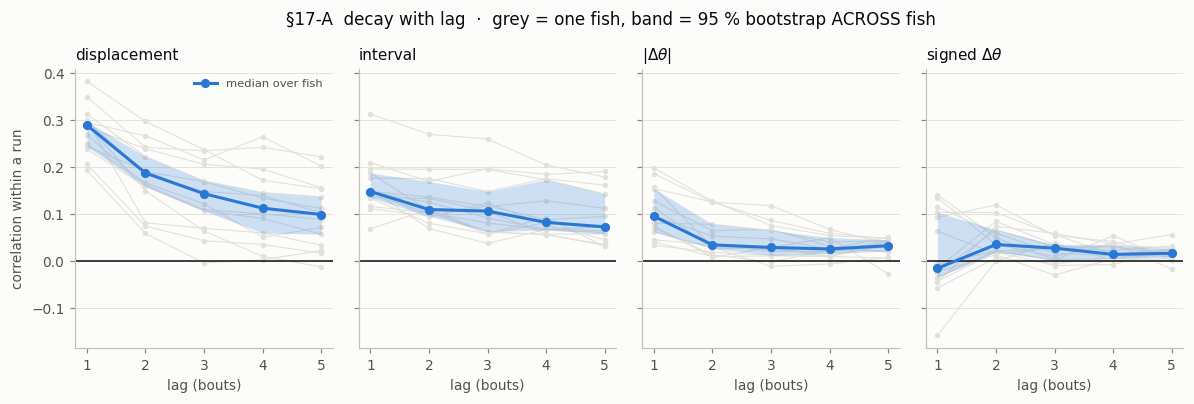

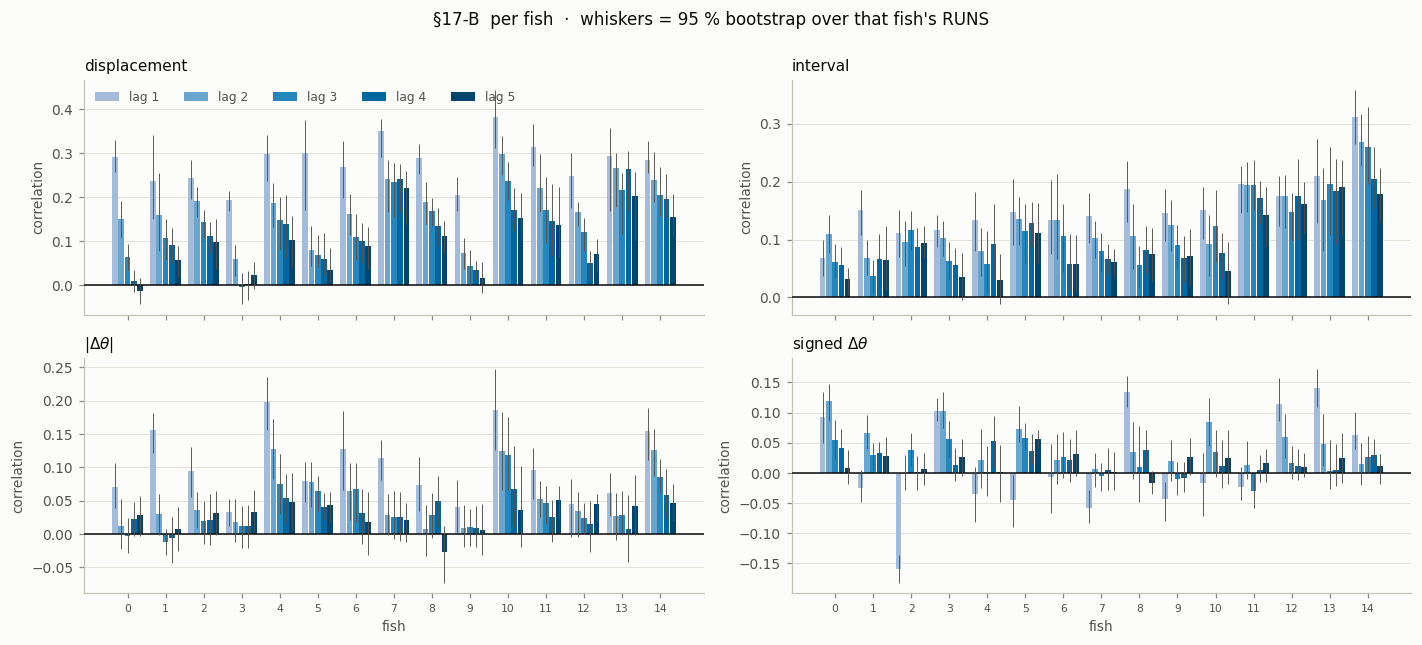

In [121]:
# --------------------------------------------------------------------------- #
#  §17-B -- the decay with lag (band = across fish), and the per-fish numbers
#  (whiskers = that fish's own run bootstrap).
# --------------------------------------------------------------------------- #
RAMP = [plt.get_cmap("PuBu")(x) for x in np.linspace(0.38, 0.95, len(LAGS))]

fig, axes = plt.subplots(1, 4, figsize=(13.0, 3.3), sharey=True,
                         gridspec_kw={"wspace": .10})
for ax, (col, nice) in zip(axes, CHANS):
    M = np.vstack([ACF[(col, k)] for k in LAGS])
    for j in range(M.shape[1]):
        ax.plot(LAGS, M[:, j], lw=.7, color=GRID, marker="o", ms=2.5, zorder=1)
    med = np.array([_median_ci(ACF[(col, k)]) for k in LAGS])
    ax.fill_between(LAGS, med[:, 1], med[:, 2], color=BLUE, alpha=.22, lw=0, zorder=2)
    ax.plot(LAGS, med[:, 0], lw=2.0, color=BLUE, marker="o", ms=5, zorder=3,
            label="median over fish")
    ax.axhline(0, color=INK, lw=1.0, zorder=2)
    ax.set_xticks(LAGS); ax.set_xlabel("lag (bouts)")
    ax.set_title(nice, fontsize=10, color=INK, loc="left")
    ax.grid(axis="y", color=GRID, lw=.6); ax.set_axisbelow(True)
axes[0].set_ylabel("correlation within a run")
axes[0].legend(fontsize=7.5, frameon=False, labelcolor=INK2, loc="upper right")
fig.suptitle("§17-A  decay with lag  ·  grey = one fish, band = 95 % bootstrap ACROSS fish",
             y=1.04, fontsize=11, color=INK)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13.0, 5.8), sharex=True)
x, w = np.arange(len(FISH)), .165
for ax, (col, nice) in zip(axes.ravel(), CHANS):
    for i, k in enumerate(LAGS):
        xs = x + (i - (len(LAGS) - 1) / 2) * w
        m, lo, hi = ACF[(col, k)], ACF_LO[(col, k)], ACF_HI[(col, k)]
        ax.bar(xs, m, w - .015, color=RAMP[i], label=f"lag {k}", zorder=2)
        ax.errorbar(xs, m, yerr=[m - lo, hi - m], fmt="none", ecolor=INK2,
                    elinewidth=.6, capsize=0, zorder=4)
    ax.axhline(0, color=INK, lw=1.0, zorder=3)
    ax.set_xticks(x); ax.set_xticklabels([f"{f}" for f in FISH], fontsize=7)
    ax.set_ylabel("correlation")
    ax.set_title(nice, fontsize=10, color=INK, loc="left")
    ax.grid(axis="y", color=GRID, lw=.6); ax.set_axisbelow(True)
axes[0, 0].legend(fontsize=8, frameon=False, labelcolor=INK2, ncol=5, loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("fish")
fig.suptitle("§17-B  per fish  ·  whiskers = 95 % bootstrap over that fish's RUNS",
             y=1.0, fontsize=11, color=INK)
fig.tight_layout()
plt.show()

**What to look for.** If the median line in §17-A drops to near zero by lag 2, the memory is
one bout deep and the report's lag-1 inputs are sufficient on their own. If it decays
gradually and lags 2 and 3 remain positive in most fish, then the lags are sampling a
slower process rather than a one-step dependence — and a model given only lag-1 inputs will
reproduce the lag-1 number while still missing the structure that produces it. That is
exactly the gap the drift state in the model ladder is meant to fill, so a slow decay here
is evidence *for* that mechanism drawn from the real data alone, before any model is fitted.

The signed turn is the control in both panels: it has no consistent lag-1 sign, so it should
have none at lags 2 and 3 either. If it suddenly acquires one, something is wrong with the
pairing rather than interesting about the fish.

**Reading it.** The full shuffle is the floor and should sit at zero everywhere; if it does
not, the estimator is biased and nothing else on the panel can be trusted. The block shuffle
is the interesting comparison: it keeps all dependence shorter than ten bouts, so it is what
a model with ten lags could at best reproduce. Where the observed curve rises above it — and
especially where the gap **grows** with $W$ rather than shrinking — the structure is on a
timescale that bout-level history cannot represent.

If instead the observed and block-shuffled curves converge as $W$ grows, then everything in
the data is short-range after all, and §3.3.3 should claim lags and stop there.

Note the coverage column: large $W$ uses only the long runs, which are continuously active
stretches and therefore a selected subset of the session. That is a real caveat, not a
formality — it biases toward the fish's more active periods, and any sentence written from
the $W = 80$ point has to carry it.

### 18 · The long timescale — and whether it is the fish or the schedule

§17 established short-range memory: consecutive bouts resemble each other, decaying more
slowly than a one-step dependence allows. That is reachable with lag inputs, so on its own
it motivates lags and nothing more.

This section asks the separate question the report needs: **is there structure on a
timescale no practical lag stack reaches, and is it a property of the animal rather than of
the stimulus programme?** Three measurements, in order:

**A. The statistic Chapter 5 uses.** `generative_metrics.win_acf1` is imported rather than
reimplemented, so the number quoted in the report is literally the quantity the model is
later scored on: log interval (or log displacement, or radius), non-overlapping windows of
60 bouts lying inside one run, window means, demeaned within the fish, lag-1 correlation
between windows adjacent in the same run. Demeaning within the fish is the important part —
it removes any *static* per-fish difference, so the statistic responds only to drift
*within* a trajectory.

**B. Is it reachable with lags?** Sweep the window size and compare against two re-orderings
of the same data. A **block shuffle** with $B = 10$ preserves every dependence at lags below
ten and destroys everything longer, so it is what a ten-lag model could at best produce. A
**full shuffle** destroys all order and must land on zero; if it does not, the estimator is
biased and nothing else is readable.

**C. Is it the fish or the programme?** The stimulus schedule is identical and synchronous
across all fifteen animals, so anything it drives is *common to all of them*. Binning the
session by the 110 s stimulus cycle and comparing each fish's fluctuation against the mean
of the other fourteen separates the two: a shared component is the schedule, an unshared one
is the animal.

⚠ Windows must fit inside a run, so large $W$ uses only long runs — continuously active
stretches, a selected subset. Coverage is reported with every number.

In [125]:
# --------------------------------------------------------------------------- #
#  §18-A -- the harness statistic itself, on the real fish.
# --------------------------------------------------------------------------- #
import sys
sys.path.insert(0, str(ROOT / "scripts"))
from generative_metrics import win_acf1                      # the exact Chapter-5 statistic

WCH = [("dt_s", "interval", True), ("distance_px", "displacement", True),
       ("r_norm", "radial position", False)]                 # (column, label, take log)


def _prep18(d=None, quiet_s=QUIET_S):
    t = (df if d is None else d).copy()
    t["gap_after"] = t.dt_s > quiet_s
    t["gap_before"] = t.groupby("fish_id").gap_after.shift(1).fillna(False)
    t["run_id"] = (t.gap_before | (t.fish_id != t.fish_id.shift())).cumsum()
    a = t[~(t.gap_after | t.gap_before)].copy()
    a["abs_dtheta"] = a.dtheta_deg.abs()
    a["r_norm"] = 1.0 - a["dist_to_border_norm"]
    return a


def _chan(g, col, take_log):
    v = g[col].to_numpy(float)
    return np.log(np.clip(v, 1e-6, None)) if take_log else v


A18 = _prep18()
rows = []
for f in FISH:
    g = A18[A18.fish_id == f]
    r = {"fish": f, "active_bouts": len(g)}
    for col, lab, lg in WCH:
        r[lab] = win_acf1(_chan(g, col, lg), W=60, runs=g.run_id.to_numpy())
    rows.append(r)
W60 = pd.DataFrame(rows).set_index("fish")
print("win_acf1 (W = 60 bouts, inside runs, demeaned within fish) -- REAL fish")
print(W60.round(3).to_string())
print("\nmedian over fish:")
print(W60[[l for _, l, _ in WCH]].median().round(3).to_string())
print("\npositive in:", {l: f"{int((W60[l] > 0).sum())}/{int(W60[l].notna().sum())}"
                         for _, l, _ in WCH})
print(f"\nmedian interval {A18.dt_s.median():.2f} s, so a 60-bout window is "
      f"about {60 * A18.dt_s.median():.0f} s of swimming")

win_acf1 (W = 60 bouts, inside runs, demeaned within fish) -- REAL fish
      active_bouts  interval  displacement  radial position
fish                                                       
0             4530     0.241        -0.110            0.510
1             5257     0.484         0.189            0.176
2             5522     0.320         0.336            0.118
3             4714     0.060         0.005            0.547
4             3034       NaN           NaN              NaN
5             6787     0.627         0.207            0.575
6             2934       NaN           NaN              NaN
7             6409     0.276         0.675            0.596
8             3069     0.398        -0.223           -0.033
9             4471     0.787         0.397            0.388
10            2905       NaN           NaN              NaN
11            6090     0.496         0.407            0.445
12            5622     0.564         0.341            0.594
13            3711     0.232

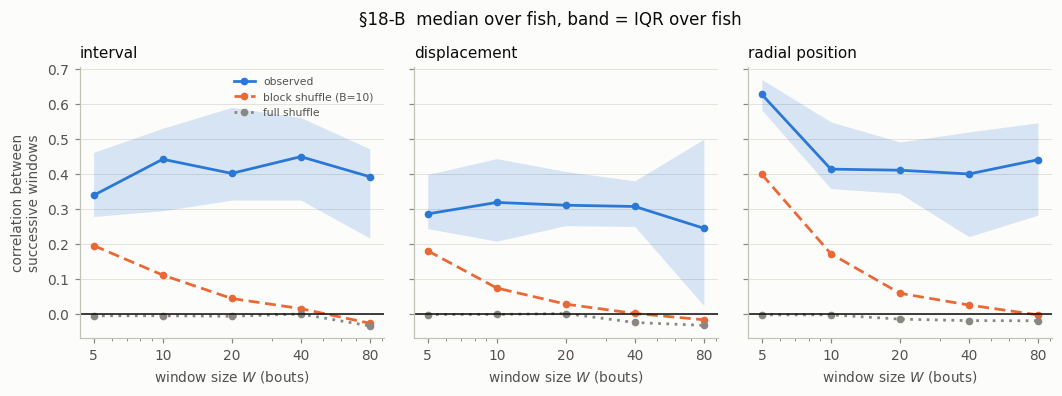

observed minus block-shuffled (median over fish) -- what ten lags cannot reach:
      interval  displacement  radial position
W=5      0.153         0.106            0.214
W=10     0.332         0.234            0.236
W=20     0.374         0.288            0.358
W=40     0.465         0.313            0.385
W=80     0.413         0.272            0.413

bouts contributing (of 69567 active):
      interval  displacement  radial position
W=5      68280         68280            68280
W=10     66315         66315            66315
W=20     61969         61969            61969
W=40     54532         54532            54532
W=80     43396         43396            43396


In [126]:
# --------------------------------------------------------------------------- #
#  §18-B -- REPORT FIGURE. Window correlation against window size, against the
#  two nulls. Both nulls pool a fish's runs, permute, and re-split into runs of
#  the SAME lengths: shuffling inside a run would leave every window pair sharing
#  that run's mean, and runs really do differ, so such a "null" inherits the very
#  structure it is meant to remove.
# --------------------------------------------------------------------------- #
WINS, BLOCK_B, N_SHUF = (5, 10, 20, 40, 80), 10, 20


def _win_pairs(runs, W):
    xs, ys = [], []
    for v in runs:
        n = len(v) // W
        if n < 2:
            continue
        m = np.array([v[i * W:(i + 1) * W].mean() for i in range(n)])
        xs.append(m[:-1]); ys.append(m[1:])
    if not xs:
        return np.array([]), np.array([])
    return np.concatenate(xs), np.concatenate(ys)


def _corr(x, y, min_n=20):
    if len(x) < min_n:
        return np.nan
    m = np.isfinite(x) & np.isfinite(y)
    return float(np.corrcoef(x[m], y[m])[0, 1]) if m.sum() >= min_n else np.nan


def _shuffle_runs(runs, rng, B=None):
    lengths = [len(v) for v in runs]
    if B is None:
        pool = rng.permutation(np.concatenate(runs))
    else:
        blocks = [v[i:i + B] for v in runs for i in range(0, len(v), B)]
        rng.shuffle(blocks)
        pool = np.concatenate(blocks)
    out, i = [], 0
    for L in lengths:
        out.append(pool[i:i + L]); i += L
    return out


RUNS18 = {(f, lab): [_chan(g, col, lg) for _, g in
                     A18[A18.fish_id == f].groupby("run_id")]
          for f in FISH for col, lab, lg in WCH}

OBS, BLK, FULL, COV = {}, {}, {}, {}
rng = np.random.default_rng(0)
for _, lab, _ in WCH:
    for W in WINS:
        o, b, u, cov = [], [], [], 0
        for f in FISH:
            runs = [v for v in RUNS18[(f, lab)] if len(v) >= 2 * W]
            cov += sum(len(v) for v in runs)
            o.append(_corr(*_win_pairs(runs, W)))
            b.append(np.nanmean([_corr(*_win_pairs(_shuffle_runs(runs, rng, BLOCK_B), W))
                                 for _ in range(N_SHUF)]))
            u.append(np.nanmean([_corr(*_win_pairs(_shuffle_runs(runs, rng, None), W))
                                 for _ in range(N_SHUF)]))
        OBS[(lab, W)], BLK[(lab, W)], FULL[(lab, W)] = map(np.array, (o, b, u))
        COV[(lab, W)] = cov

fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.2), sharey=True,
                         gridspec_kw={"wspace": .10})
for ax, (_, lab, _) in zip(axes, WCH):
    for key, colr, name, ls in ((OBS, BLUE, "observed", "-"),
                                (BLK, ORANGE, f"block shuffle (B={BLOCK_B})", (0, (4, 2))),
                                (FULL, MUTED, "full shuffle", (0, (1, 2)))):
        M = np.vstack([key[(lab, W)] for W in WINS])
        med = np.nanmedian(M, axis=1)
        ax.plot(WINS, med, lw=1.8, color=colr, ls=ls, marker="o", ms=4, label=name)
        if key is OBS:
            ax.fill_between(WINS, np.nanpercentile(M, 25, axis=1),
                            np.nanpercentile(M, 75, axis=1), color=colr, alpha=.18, lw=0)
    ax.axhline(0, color=INK, lw=1.0)
    ax.set_xscale("log"); ax.set_xticks(WINS)
    ax.set_xticklabels([str(w) for w in WINS])
    ax.set_xlabel("window size $W$ (bouts)")
    ax.set_title(lab, fontsize=10, color=INK, loc="left")
    ax.grid(axis="y", color=GRID, lw=.6); ax.set_axisbelow(True)
axes[0].set_ylabel("correlation between\nsuccessive windows")
axes[0].legend(fontsize=7, frameon=False, labelcolor=INK2, loc="upper right")
fig.suptitle("§18-B  median over fish, band = IQR over fish", y=1.04,
             fontsize=11, color=INK)
plt.show()

print("observed minus block-shuffled (median over fish) -- what ten lags cannot reach:")
print(pd.DataFrame({lab: [float(np.nanmedian(OBS[(lab, W)] - BLK[(lab, W)])) for W in WINS]
                    for _, lab, _ in WCH}, index=[f"W={w}" for w in WINS]).round(3).to_string())
print("\nbouts contributing (of %d active):" % len(A18))
print(pd.DataFrame({lab: [COV[(lab, W)] for W in WINS]
                    for _, lab, _ in WCH}, index=[f"W={w}" for w in WINS]).to_string())

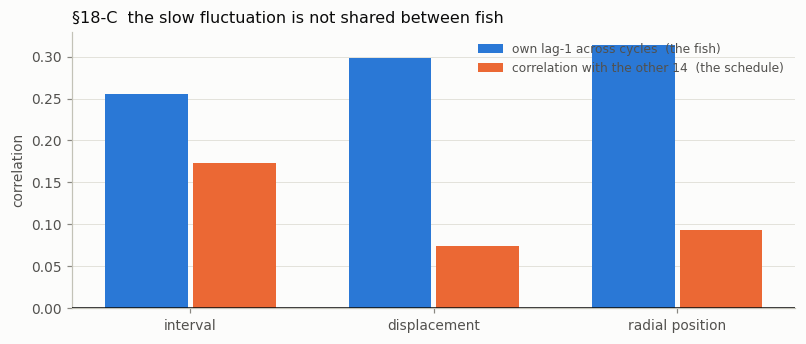

bins = one 110 s stimulus cycle, >= 10 active bouts
        channel  own_lag1  cross_fish own_pos cross_pos  n_cycles
       interval     0.256       0.174   14/15     15/15        90
   displacement     0.299       0.075   15/15     10/15        90
radial position     0.314       0.094   15/15     12/15        90


In [127]:
# --------------------------------------------------------------------------- #
#  §18-C -- REPORT FIGURE. Is the slow structure the fish, or the programme?
#
#  The schedule is identical and synchronous for all fifteen fish, so anything it
#  drives is COMMON to them. Binning by the 110 s stimulus cycle (one pause + one
#  stimulus block) puts a whole cycle in every bin, so the periodic part of the
#  programme is constant across bins and only the randomised block identity and
#  the fish's own state can vary. For each fish: its own lag-1 correlation across
#  cycles, against its correlation with the mean of the OTHER fourteen at the same
#  cycle. Shared = schedule. Unshared = animal.
# --------------------------------------------------------------------------- #
CYCLE_S = CYCLE_FR / FPS                      # 110 s: one pause + one stimulus block
MIN_BOUTS_BIN = 10

A18 = A18.assign(_cyc=(A18.t_onset_s // CYCLE_S).astype(int))
rows = []
for col, lab, lg in WCH:
    M = {}
    for f in FISH:
        g = A18[A18.fish_id == f]
        s = (g.assign(_v=_chan(g, col, lg)).groupby("_cyc")
             .agg(v=("_v", "mean"), n=("_v", "size")))
        s = s[s.n >= MIN_BOUTS_BIN]["v"]
        M[f] = s
    T = pd.DataFrame(M).sort_index()          # cycles x fish
    T = T - T.mean()                          # demean within fish, as win_acf1 does
    own, shared = [], []
    for f in FISH:
        x = T[f]
        others = T.drop(columns=[f]).mean(axis=1)
        j = pd.concat([x.rename("x"), others.rename("o")], axis=1).dropna()
        if len(j) < 20:
            own.append(np.nan); shared.append(np.nan); continue
        xv = j.x.to_numpy()
        own.append(float(np.corrcoef(xv[:-1], xv[1:])[0, 1]))
        shared.append(float(np.corrcoef(j.x, j.o)[0, 1]))
    rows.append(dict(channel=lab,
                     own_lag1=float(np.nanmedian(own)),
                     cross_fish=float(np.nanmedian(shared)),
                     own_pos=f"{int(np.nansum(np.array(own) > 0))}/{len(FISH)}",
                     cross_pos=f"{int(np.nansum(np.array(shared) > 0))}/{len(FISH)}",
                     n_cycles=int(T.notna().sum().median())))
    globals()[f"_own_{lab[:4]}"] = own
    globals()[f"_shr_{lab[:4]}"] = shared
T18C = pd.DataFrame(rows)
print(f"bins = one {CYCLE_S:.0f} s stimulus cycle, >= {MIN_BOUTS_BIN} active bouts")
print(T18C.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.4, 3.2))
x, w = np.arange(len(WCH)), .36
for i, (key, colr, lab2) in enumerate(
        ((("own_lag1"), BLUE, "own lag-1 across cycles  (the fish)"),
         (("cross_fish"), ORANGE, "correlation with the other 14  (the schedule)"))):
    ax.bar(x + (i - .5) * w, T18C[key], w - .02, color=colr, label=lab2, zorder=2)
ax.axhline(0, color=INK, lw=1.0, zorder=3)
ax.set_xticks(x); ax.set_xticklabels([r["channel"] for _, r in T18C.iterrows()])
ax.set_ylabel("correlation")
ax.grid(axis="y", color=GRID, lw=.6); ax.set_axisbelow(True)
ax.legend(fontsize=8, frameon=False, labelcolor=INK2, loc="upper right")
ax.set_title("§18-C  the slow fluctuation is not shared between fish",
             fontsize=10.5, color=INK, loc="left")
fig.tight_layout(); plt.show()

**What decides it.** In §18-C, a large `own_lag1` with a `cross_fish` near zero means each
fish drifts on its own schedule — the structure is internal, and a latent state is the right
representation. If instead `cross_fish` were comparable to `own_lag1`, the fifteen animals
would be fluctuating together, which only the stimulus programme can cause, and the fix
would be better stimulus features rather than a state variable.

Note the asymmetry in what a null result means here: `cross_fish` near zero does not prove
there is *no* schedule-driven component, only that it is small next to the individual one at
this timescale. That is enough for the report's claim, which is about what a model must
carry, not about partitioning variance exactly.

## Report Figure 3.6 · distance to the dots, with and without the outside-dish rule

The report's distance-across-the-block figure (Chapter 3, `scripts/make_report_figures.py::fig_dot_profile`),
drawn twice with the report's own code, styling and data (`clean_data/bouts_clean.csv`, active bouts):

1. **as in the report** — bouts whose dot centroid lies outside the dish are left out, since the fish
   cannot reach those dots (11.4 % of stimulus bouts; 16.4 % at one moving dot, 6.3 % at two);
2. **with those bouts kept**.

Per-fish mean over that fish's blocks first, then the mean across fish; band = 95 % percentile
bootstrap over fish; physical scale 3.60 px/mm.

**Reading it.** Keeping the outside-dish bouts lifts every curve by roughly 2–4 mm, most for one moving
dot (where most bouts are dropped) and least for two or more moving dots. The early dip and the
time of closest approach do not move. The picture is the same either way: static dots drift away,
two or more moving dots close in and hold, one moving dot lies in between. The numbers quoted in the
report (dip, plateau, grading, attraction) are measured **with** the rule.

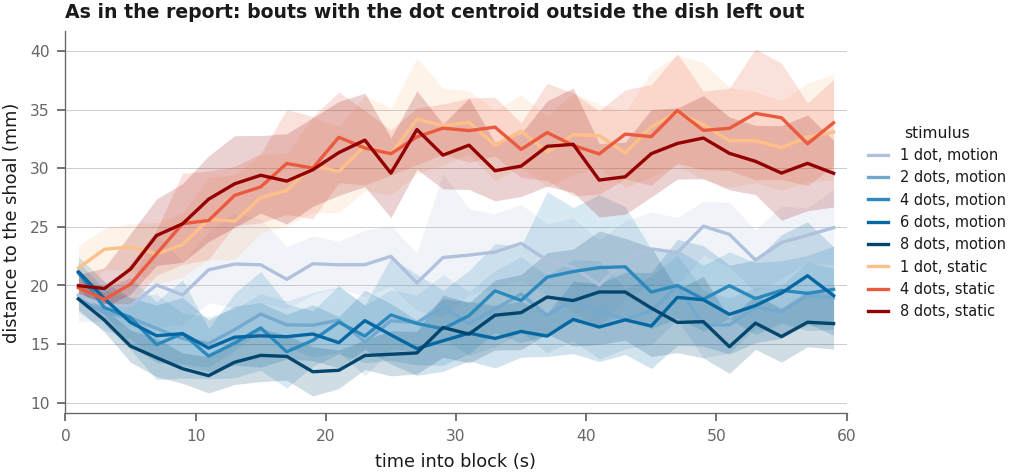

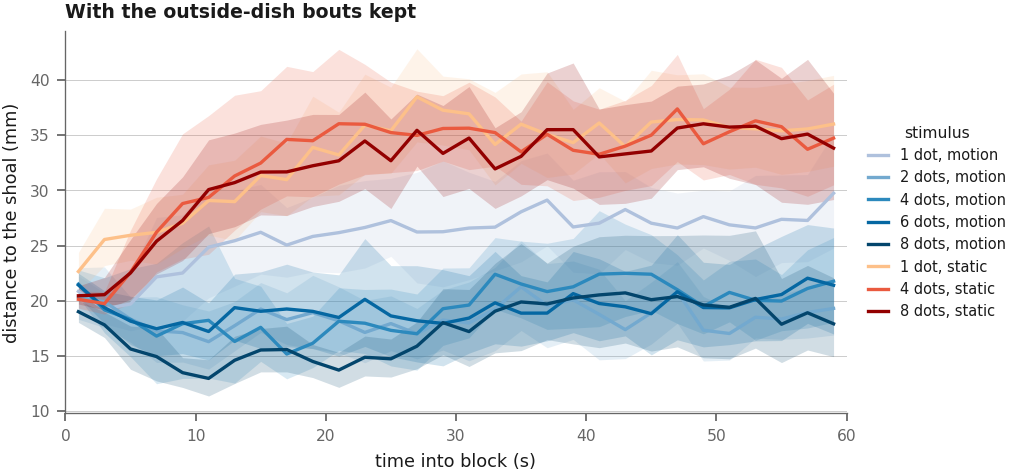

In [ ]:
# Report Figure 3.6, drawn by the report's own function -- with and without the outside-dish rule.
import sys
import matplotlib as mpl
from io import BytesIO
from IPython.display import Image, display

_root = str(ROOT) if "ROOT" in globals() else ".."
for _p in (_root, _root + "/scripts"):
    if _p not in sys.path:
        sys.path.insert(0, _p)

with mpl.rc_context():                 # the report module sets its own rcParams on import; keep them local
    import make_report_figures as _rep
    _bouts_rep = _rep.load()
    for _keep, _title in [(False, "As in the report: bouts with the dot centroid outside the dish left out"),
                          (True, "With the outside-dish bouts kept")]:
        _fig = _rep.fig_dot_profile(_bouts_rep, keep_outside=_keep, save=False)
        _fig.axes[0].set_title(_title, loc="left", pad=6)
        _buf = BytesIO()       # the report module selects the Agg backend: render to PNG explicitly
        _fig.savefig(_buf, format="png", dpi=160)
        display(Image(data=_buf.getvalue()))
        plt.close(_fig)